# SoporTIC — Asistente de mesa de ayuda con Transformers

**Universidad de Cundinamarca – Extensión Facatativá**
Ingeniería de Sistemas · Electiva Profesional II (Fundamentos de Deep Learning) · Curso 902
Docente: Jorge Eduardo Mican

**Autores:** Jean Paul Miranda Díaz · Lina Tatiana Maldonado

---

### Descripción
SoporTIC es un asistente de mesa de ayuda (contexto 3 del taller: **soporte técnico**) para estudiantes de la UdeC Facatativá. Reconoce en lenguaje natural la intención del mensaje entre 17 intenciones (Moodle, correo institucional, contraseñas, Wi-Fi de la sede, Teams, Office 365, Python, Google Colab, plataforma institucional, salas de cómputo, contacto con soporte y cinco intenciones de conversación) y guía al usuario con pasos tomados de una base de conocimiento con referencias oficiales. El proyecto compara, sobre los mismos datos, modelos de complejidad creciente:

| Nivel | Modelo | Concepto de la asignatura |
|---|---|---|
| 0. Clásico | TF-IDF + regresión logística | Línea base sin aprendizaje profundo |
| 1. Red desde cero | Embedding + BiLSTM + capa densa (PyTorch) | Neuronas, capas, retropropagación, redes recurrentes |
| 2. Embeddings de frase | MiniLM multilingüe + vecino más cercano | Representaciones aprendidas, similitud semántica |
| 3. Transfer learning | BETO (BERT en español) con *fine-tuning* | Transformers, autoatención, preentrenamiento |
| 4. Híbrido | BETO + respaldo semántico MiniLM | Combinación de modelos con umbrales elegidos en validación |

**Versiones en este notebook.** v1 (secciones 1–9): línea base de una intención, congelada en `soportic/v1_congelada/`. v2 (secciones 10–14): multiintención con BETO multietiqueta y *temperature scaling*, conservada en `soportic/fase3_concatenadas/`. v2b (secciones 15–19): mejora de la multiintención, diseñada después de ver la prueba de la v2, con método final elegido por validación cruzada y prueba externa evaluada una vez. v3 (secciones 20–23): memoria del caso, modo IA con verificador e interfaz Gradio. Fase 5 (secciones 24–26): batería de 254 casos, latencia, VRAM y evaluación humana. Las decisiones tomadas sin los autores están en `DECISIONES.md`.

### Contenido
1. Instalación e importación de librerías
2. Datos: dataset propio, conjunto de generalización, prueba externa, base de conocimiento y MASSIVE
3. Análisis exploratorio (EDA)
4. Preprocesamiento, división estratificada 70/15/15, BETO de referencia y aumento de datos
5. Modelos: TF-IDF, BiLSTM desde cero y BETO (búsqueda en validación + *early stopping*)
6. Evaluación: prueba, generalización, prueba externa, fuera de dominio, calibración, atención, t-SNE, validación cruzada y umbrales
9. Guardado del modelo y resultados (`resultados_soporte_v1.json`)
10–14. Multiintención (v2): datos multietiqueta, segmentación, BETO multietiqueta, evaluación y *temperature scaling*
15–19. Mejora de la multiintención (v2b): frases de Qwen, negativos, piso de umbral, método combinado y ensamble, validación cruzada, prueba y prueba externa
20–23. Memoria del caso, modo IA con verificador, evaluación de la memoria e interfaz Gradio (v3)
24–26. Batería del sistema completo, latencia y VRAM, evaluación humana

> **Antes de ejecutar en Colab:** `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4` y luego `Ejecutar todas`. También corre en local (Jupyter/VS Code) con GPU NVIDIA.

## 1. Instalación e importación de librerías

Colab ya trae `torch`, `pandas`, `numpy`, `matplotlib` y `scikit-learn`; se instalan las librerías de Hugging Face, `sentence-transformers`, `gradio` y `nltk`. No se fijan versiones para no romper el PyTorch/CUDA del entorno. En un equipo local la celda no instala nada (las dependencias se instalan una vez en el entorno virtual).

In [1]:
import sys, subprocess
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers==4.57.6", "tokenizers==0.22.2", "huggingface_hub==0.36.2",
                    "accelerate==1.15.0", "datasets==5.0.1", "sentence-transformers==5.7.0",
                    "gradio==6.17.3", "nltk==3.10.4"], check=True)
print("Entorno:", "Google Colab" if EN_COLAB else "local")

Entorno: local


**Datos del proyecto en Google Colab.** El notebook lee de disco el dataset (`dataset_soporte.csv`), el conjunto de generalización (`frases_generalizacion.csv`), la prueba externa (`frases_prueba_externa.txt`), la base de conocimiento (`base_conocimiento.json`), las respuestas fijas (`respuestas_fijas.json`) y, si existe, la caché del aumento de datos. En Colab, la celda siguiente toma `soportic_datos.zip` de `MyDrive/SoporTIC/` (si existe) o pide subirlo, y lo descomprime. Si falta un archivo, avisa qué se regenera y qué no.

In [2]:
import os, shutil, zipfile
ARCHIVOS_FUENTE = ["dataset_soporte.csv", "frases_generalizacion.csv", "frases_prueba_externa.txt",
                   "base_conocimiento.json", "base_conocimiento_v3.json", "respuestas_fijas.json", "dataset_soporte_multietiqueta.csv",
                   "frases_generalizacion_multietiqueta.csv", "conversaciones_memoria.json", "bateria_soporte.json",
                   "conversaciones_memoria_v4.json", "bateria_soporte_v4.json",
                   "tareas_evaluacion.csv"]
ARCHIVOS_CACHE = ["soportic/datos/aumento_candidatos.csv", "soportic/datos/aumento_train.csv",
                  "soportic/datos/aumento_reporte.csv"]
if EN_COLAB:
    ZIP_DATOS, ZIP_DRIVE = "soportic_datos.zip", "/content/drive/MyDrive/SoporTIC/soportic_datos.zip"
    if not os.path.exists(ZIP_DATOS):
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            if os.path.exists(ZIP_DRIVE):
                shutil.copy(ZIP_DRIVE, ZIP_DATOS)
                print("soportic_datos.zip copiado desde Google Drive.")
        except Exception as error:
            print(f"No se pudo usar Google Drive ({type(error).__name__}).")
    if not os.path.exists(ZIP_DATOS):
        from google.colab import files
        print("Sube soportic_datos.zip (entregado con el notebook):")
        files.upload()
    if os.path.exists(ZIP_DATOS):
        zipfile.ZipFile(ZIP_DATOS).extractall(".")
        print("Datos descomprimidos.")
faltan_fuente = [a for a in ARCHIVOS_FUENTE if not os.path.exists(a)]
if faltan_fuente:
    raise FileNotFoundError(f"Faltan datos fuente de los autores (no se pueden regenerar): {faltan_fuente}. "
                            "Sube soportic_datos.zip y vuelve a ejecutar.")
faltan_cache = [a for a in ARCHIVOS_CACHE if not os.path.exists(a)]
if faltan_cache:
    print("AVISO: falta la caché del aumento de datos; se regenera con MarianMT (tarda varios minutos y puede variar).")
else:
    print("Archivos de datos completos.")
if not os.path.exists("soportic/datos/qwen_generaciones_cache.csv"):
    print("AVISO: falta la caché de Qwen (Fase 3b); se genera con Qwen2.5-3B (tarda y puede variar).")
if not os.path.exists("ui/fuentes/fuentes.css"):
    print("AVISO: faltan las fuentes locales de la interfaz (ui/fuentes/); se usarán las del sistema.")

Archivos de datos completos.


In [3]:
# ===================== Importaciones =====================
import os, re, json, copy, time, random, shutil, unicodedata, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")      # la interfaz funciona sin internet
import transformers, datasets, sentence_transformers, gradio as gr
from datasets import Dataset, DatasetDict
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM,
                          get_linear_schedule_with_warmup, set_seed)
from sentence_transformers import SentenceTransformer, util

warnings.filterwarnings("ignore")

# ===================== Reproducibilidad =====================
SEED = 42

def fijar_semillas(seed: int = SEED) -> None:
    """Fija todas las semillas para que los resultados sean reproducibles."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    set_seed(seed)                                  # semilla interna de transformers
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semillas(SEED)
T_INICIO_NOTEBOOK = time.time()

# ===================== Dispositivo =====================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"                     # precisión mixta (fp16) solo en GPU
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "sin GPU (funciona, pero más lento)")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}")
print(f"sentence-transformers {sentence_transformers.__version__} | gradio {gr.__version__} | nltk {nltk.__version__}")

# ===================== Recursos de NLTK =====================
for recurso in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(recurso, quiet=True)

# ===================== Carpetas del proyecto =====================
BASE_DIR   = "soportic"
DATA_DIR   = os.path.join(BASE_DIR, "datos")
FIG_DIR    = os.path.join(BASE_DIR, "figuras")
MODEL_DIR  = os.path.join(BASE_DIR, "modelo_bert_intenciones")
for d in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

# Estilo general de las gráficas
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLOR_1, COLOR_2 = "#2563eb", "#ea580c"

Dispositivo: cuda | NVIDIA GeForce RTX 5050 Laptop GPU
torch 2.11.0+cu128 | transformers 4.57.6 | datasets 5.0.1
sentence-transformers 5.7.0 | gradio 6.17.3 | nltk 3.10.4


## 2. Datos: dataset propio de intenciones de soporte en español

### ¿Por qué un dataset propio y no Cornell, Customer Support on Twitter o DailyDialog?
| Dataset sugerido | Idioma | Dominio | Etiquetas de intención | Problema para SoporTIC |
|---|---|---|---|---|
| Cornell Movie-Dialogs Corpus | Inglés | Guiones de películas | No | Diálogo de ficción, sin relación con la mesa de ayuda |
| Customer Support on Twitter | Inglés | Soporte de marcas (aerolíneas, telefonía) | No | Es soporte, pero comercial y en inglés; no contiene Moodle, correo institucional, plataforma académica ni salas |
| DailyDialog | Inglés | Conversación cotidiana | Etiquetas de acto de habla y emoción, no de intención de dominio | Charla general, sin problemas técnicos universitarios |
| **Amazon MASSIVE (es-ES), usado** | Español | Asistente de voz (alarmas, música, clima, cocina, transporte…) | Sí (60 intenciones en 18 escenarios) | No cubre el soporte universitario; **se usa solo como ejemplos de `fuera_de_dominio`** (ver abajo) |

1. **Idioma:** los usuarios son estudiantes colombianos que escriben en español informal, sin tildes, con abreviaturas («q», «porfa», «cel») y coloquialismos («parce», «quiubo»). Traducir corpus en inglés introduce ruido y pierde esos rasgos.
2. **Dominio:** los problemas con Moodle, el correo institucional, la plataforma Academusoft, el Wi-Fi de la sede o las salas de cómputo son propios de la UdeC; ningún corpus público los contiene.
3. **Tipo de tarea:** el bot se plantea como **clasificación de intenciones**, que necesita ejemplos etiquetados por intención. Los tres corpus sugeridos son diálogos abiertos pensados para modelos generativos.
4. **Control de calidad:** las instrucciones de soporte deben ser exactas y verificables; un modelo entrenado con diálogos abiertos podría inventar pasos, URL o contactos.

**Cómo podrían complementarlo:** (a) filtrar Customer Support on Twitter para obtener ejemplos de frustración y de petición de atención humana (`hablar_con_soporte`); (b) usar Cornell o DailyDialog como **ejemplos negativos** para `fuera_de_dominio`; (c) usarlos para ajustar un modelo **generativo** en una versión futura.

### Archivos de datos (fuente de verdad, leídos desde disco)
| Archivo | Contenido | Uso |
|---|---|---|
| `dataset_soporte.csv` | 442 frases (26 por intención), columnas `texto, intencion, origen` (`origen = asistente_ia`) | Entrenamiento, validación y prueba (70/15/15) |
| `frases_generalizacion.csv` | 68 frases (4 por intención), con otras palabras y otra estructura | Solo evaluación |
| `frases_prueba_externa.txt` | Frases redactadas por otro asistente de IA a partir de problemas frecuentes de mesas de ayuda universitarias; formato `frase;intencion` o `frase;intencion1\|intencion2` | Solo evaluación: en esta fase, las líneas de una intención; las de varias, en la Fase 3 |
| `base_conocimiento.json` | Una guía por intención técnica (pasos numerados, referencias oficiales) y los canales de soporte | Respuestas y recuperación (RAG) |
| `respuestas_fijas.json` | Respuestas de saludo, despedida, agradecimiento, `sobre_bot` y `fuera_de_dominio` (con variante para trámites) | Respuestas de las intenciones de conversación |

Las 17 intenciones son: `saludo`, `despedida`, `agradecimiento`, `sobre_bot`, `fuera_de_dominio`, `moodle_acceso`, `moodle_entregas`, `correo_institucional`, `restablecer_contrasena`, `wifi_sede`, `teams`, `office365`, `instalar_python`, `colab_gpu`, `plataforma_academica`, `salas_computo` y `hablar_con_soporte`. Cada caso tiene una sola intención correcta; los trámites de reglamento (homologaciones, revisión de notas, supletorios, becas, cancelación de matrícula) son `fuera_de_dominio`. Las frases de las intenciones técnicas mencionan el dispositivo (celular, portátil, PC de la sala) y el error («me sale error», «no carga», «dice contraseña incorrecta»), que la memoria de estado de la Fase 4 usará como *slots*.

El dataset y el conjunto de generalización no tienen duplicados exactos ni normalizados, ni pares con similitud MiniLM ≥ 0,90 entre sí (verificación en `herramientas/verificar_datos.py`).

In [4]:
# =====================================================================
# Dataset propio, respuestas fijas y base de conocimiento (leídos desde archivo)
# =====================================================================
df = pd.read_csv("dataset_soporte.csv")
assert list(df.columns) == ["texto", "intencion", "origen"], df.columns
INTENCIONES = {k: g["texto"].tolist() for k, g in df.groupby("intencion", sort=False)}

with open("respuestas_fijas.json", encoding="utf-8") as f:
    RESPUESTAS_FIJAS = json.load(f)
with open("base_conocimiento.json", encoding="utf-8") as f:
    BASE_CONOCIMIENTO = json.load(f)
GUIAS = BASE_CONOCIMIENTO["guias"]
# Base anterior (pasos en una lista plana): la usan las secciones v1 y v2 (fragmentos RAG y respuestas de la v2), para que
# sus resultados sigan siendo reproducibles. El bot (v4) usa la estructura nueva: diagnóstico → ramas → soluciones.
with open("base_conocimiento_v3.json", encoding="utf-8") as f:
    GUIAS_V3 = json.load(f)["guias"]
INTENCIONES_SOCIALES = {"saludo", "despedida", "agradecimiento", "sobre_bot", "fuera_de_dominio"}
assert set(INTENCIONES) == INTENCIONES_SOCIALES | set(GUIAS), "Cada intención técnica debe tener su guía"
assert INTENCIONES_SOCIALES <= set(RESPUESTAS_FIJAS["respuestas"]), "Faltan respuestas fijas"

# Control de duplicados exactos (sin distinguir mayúsculas/espacios)
clave = df["texto"].str.lower().str.strip()
assert not clave.duplicated().any(), "El dataset tiene duplicados exactos"
conteo = df["intencion"].value_counts()
print(f"Ejemplos: {len(df)} | Intenciones: {df['intencion'].nunique()} | por intención: mín {conteo.min()}, máx {conteo.max()} | "
      f"origen: {df['origen'].value_counts().to_dict()}")
print(f"Guías técnicas: {len(GUIAS)} | soluciones por guía (todas las ramas): "
      f"{[sum(len(r['soluciones']) for r in g['ramas'].values()) for g in GUIAS.values()]}")

# Copia en formato tipo 'intents.json' dentro de la carpeta de resultados
df.to_csv(os.path.join(DATA_DIR, "dataset_intenciones.csv"), index=False, encoding="utf-8")
intents_json = {"intents": [{"tag": k, "patterns": INTENCIONES[k]} for k in INTENCIONES]}
with open(os.path.join(DATA_DIR, "intenciones.json"), "w", encoding="utf-8") as f:
    json.dump(intents_json, f, ensure_ascii=False, indent=2)
df.sample(10, random_state=SEED)

Ejemplos: 442 | Intenciones: 17 | por intención: mín 26, máx 26 | origen: {'asistente_ia': 442}
Guías técnicas: 12 | soluciones por guía (todas las ramas): [7, 6, 7, 3, 8, 7, 7, 5, 6, 8, 6, 5]


,texto,intencion,origen
287,word me dice producto sin licencia,office365,asistente_ia
211,me dice que la contraseña expiro y no me deja ...,restablecer_contrasena,asistente_ia
72,"uy que bien, gracias de una",agradecimiento,asistente_ia
321,tengo dos versiones de python instaladas y se ...,instalar_python,asistente_ia
73,muy util la info,agradecimiento,asistente_ia
418,como abro un ticket de soporte,hablar_con_soporte,asistente_ia
367,la plataforma academica no carga cuando voy a ...,plataforma_academica,asistente_ia
354,colab me pide verificar que no soy un robot ca...,colab_gpu,asistente_ia
281,teams pide una cuenta personal y yo tengo la i...,teams,asistente_ia
148,"con que usuario entro a moodle, con el correo ...",moodle_acceso,asistente_ia


In [5]:
# =====================================================================
# Conjunto de generalización (leído desde archivo): solo evaluación
# =====================================================================
gen_df = pd.read_csv("frases_generalizacion.csv")
assert set(gen_df["intencion"]) == set(INTENCIONES)
solapadas = set(gen_df["texto"].str.lower()) & set(df["texto"].str.lower())
print(f"Conjunto de generalización: {len(gen_df)} frases | coincidencias exactas con el dataset: {len(solapadas)}")

Conjunto de generalización: 68 frases | coincidencias exactas con el dataset: 0


### Fuera de dominio externo: Amazon MASSIVE (español)
La clase `fuera_de_dominio` tiene 26 frases escritas para el proyecto. Para que el clasificador vea más variedad de temas ajenos al soporte se toman frases reales en español del corpus **Amazon MASSIVE** (FitzGerald et al., 2022; licencia CC BY 4.0; versión en parquet `mteb/amazon_massive_intent`, configuración `es`), con la misma configuración del proyecto anterior: solo escenarios sin relación con la mesa de ayuda (alarmas, audio, cocina, domótica, listas, música, noticias, reproducción, recomendaciones, domicilios, transporte y clima). Se excluyen `calendar`, `datetime`, `email`, `general`, `qa` y `social` porque se parecen a mensajes de soporte (correos, «cuándo es…», «qué es…»).

- **100 frases** se agregan al entrenamiento como `fuera_de_dominio` (unas 5 veces el tamaño de una clase en train, para no desbalancear).
- **30 frases distintas** se agregan a la validación, para que la validación pueda medir su aporte.
- **50 frases distintas** (del split de prueba de MASSIVE) forman una **prueba aparte de fuera de dominio** que no se usa para elegir nada.

Las tres muestras están estratificadas por escenario y no se solapan. Si la descarga falla, el notebook sigue sin MASSIVE.

> Referencia: J. FitzGerald et al., «MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages», *ACL 2023* (arXiv:2204.08582).

### Fuentes de la base de conocimiento
`base_conocimiento.json` contiene una guía por intención técnica (título, resumen, pasos numerados, qué hacer si no funciona y referencias), redactada con base en documentación oficial pública (soporte de Microsoft, docs.python.org, documentación de Colab y Moodle, ayuda de Android y Apple) y en documentos y páginas oficiales de la Universidad de Cundinamarca (plataforma institucional Academusoft y SIS, aulas virtuales, correo institucional, licenciamiento Office 365 A3, mesa de ayuda «TICS a un CLIC»). Las referencias de 2022 o antes llevan la nota «verificar vigencia». Los datos de la UdeC que aún no se conocen están marcados como `[COMPLETAR: …]`: el bot nunca los muestra; omite ese paso y remite a la mesa de ayuda.

In [6]:
# ---------- Fuera de dominio externo: Amazon MASSIVE (es) ----------
ESCENARIOS_MASSIVE = ["alarm", "audio", "cooking", "iot", "lists", "music", "news", "play",
                      "recommendation", "takeaway", "transport", "weather"]
N_MASSIVE_TRAIN, N_MASSIVE_VAL, N_MASSIVE_PRUEBA = 100, 30, 50
COLUMNAS_MASSIVE = ["texto", "intencion", "escenario"]
massive_train_df = massive_val_df = massive_prueba_df = pd.DataFrame(columns=COLUMNAS_MASSIVE)
MASSIVE_OK = False
try:
    from datasets import load_dataset
    massive = load_dataset("mteb/amazon_massive_intent", "es")
    propias = set(pd.concat([df["texto"], gen_df["texto"]]).str.lower().str.strip())

    def _massive_df(split):
        d = massive[split].to_pandas().rename(columns={"text": "texto"})
        d["escenario"] = d["label"].str.split("_").str[0]
        d = d[d["escenario"].isin(ESCENARIOS_MASSIVE) & ~d["texto"].str.lower().str.strip().isin(propias)]
        return d.drop_duplicates("texto").assign(intencion="fuera_de_dominio")[COLUMNAS_MASSIVE]

    m_train, m_test = _massive_df("train"), _massive_df("test")
    m_train = m_train[~m_train["texto"].str.lower().isin(set(m_test["texto"].str.lower()))]
    m_sel, _ = train_test_split(m_train, train_size=N_MASSIVE_TRAIN + N_MASSIVE_VAL,
                                stratify=m_train["escenario"], random_state=SEED)
    massive_train_df, massive_val_df = train_test_split(m_sel, train_size=N_MASSIVE_TRAIN,
                                                        stratify=m_sel["escenario"], random_state=SEED)
    massive_prueba_df, _ = train_test_split(m_test, train_size=N_MASSIVE_PRUEBA,
                                            stratify=m_test["escenario"], random_state=SEED)
    massive_train_df, massive_val_df, massive_prueba_df = [d.reset_index(drop=True)
                                                           for d in (massive_train_df, massive_val_df, massive_prueba_df)]
    pd.concat([massive_train_df.assign(uso="train"), massive_val_df.assign(uso="validación"),
               massive_prueba_df.assign(uso="prueba aparte")]).to_csv(os.path.join(DATA_DIR, "massive_fuera_de_dominio.csv"), index=False)
    MASSIVE_OK = True
    print(f"MASSIVE: train {len(massive_train_df)} | validación {len(massive_val_df)} | prueba aparte {len(massive_prueba_df)}")
    print(pd.DataFrame({"train": massive_train_df["escenario"].value_counts(),
                        "validación": massive_val_df["escenario"].value_counts(),
                        "prueba aparte": massive_prueba_df["escenario"].value_counts()}).fillna(0).astype(int).T.to_string())
except Exception as e:
    print(f"MASSIVE no disponible ({type(e).__name__}: {e}); se continúa sin datos externos.")

Using the latest cached version of the dataset since mteb/amazon_massive_intent couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'es' at C:\Users\miran\.cache\huggingface\datasets\mteb___amazon_massive_intent\es\0.0.0\940fd47a81eaa7f2cc7b129674d945d618ac38c2 (last modified on Mon Nov  9 13:32:44 2026).


MASSIVE: train 100 | validación 30 | prueba aparte 50
escenario      alarm  audio  cooking  iot  lists  music  news  play  recommendation  takeaway  transport  weather
train              6      5        4   11      9      5     9    22               7         5          9        8
validación         2      1        1    3      3      2     2     7               2         1          3        3
prueba aparte      3      2        2    6      4      3     4    12               3         2          4        5


### Prueba externa y frases reservadas
La **prueba externa** (`frases_prueba_externa.txt`) la redactó otro asistente de IA, distinto del que generó el dataset, a partir de problemas frecuentes documentados por mesas de ayuda universitarias; los autores la entregaron y no se usa para ajustar nada. Tiene líneas de una intención (`frase;intencion`) y de varias (`frase;intencion1|intencion2`); las líneas que empiezan con `#` son comentarios. En esta fase (modelo de una intención) se evalúan solo las líneas de una intención; las de varias intenciones se evalúan en la Fase 3 (multietiqueta).

Todas sus frases, de una o de varias intenciones, se definen aquí, antes del entrenamiento, para que el aumento de datos de la sección 4.1 las excluya (filtro anti-fuga). La batería de pruebas del chatbot de soporte se define en una fase posterior.

In [7]:
# ---------- Prueba externa (una y varias intenciones) y frases reservadas ----------
import unicodedata as _ud
def _sin_diacriticos(t):
    return "".join(c for c in _ud.normalize("NFD", t) if _ud.category(c) != "Mn")

RUTA_EXTERNA = "frases_prueba_externa.txt"
FRASES_EXTERNAS_TODAS = []          # (frase, [intenciones])
with open(RUTA_EXTERNA, encoding="utf-8") as f:
    for linea in f:
        linea = linea.strip()
        if not linea or linea.startswith("#") or ";" not in linea:
            continue
        frase, etiquetas = linea.rsplit(";", 1)
        FRASES_EXTERNAS_TODAS.append((frase.strip(), [e.strip() for e in etiquetas.split("|")]))
desconocidas = {e for _, es in FRASES_EXTERNAS_TODAS for e in es} - set(INTENCIONES)
assert not desconocidas, f"Intenciones desconocidas en la prueba externa: {desconocidas}"
FRASES_EXTERNAS = [(f, es[0]) for f, es in FRASES_EXTERNAS_TODAS if len(es) == 1]       # Fase 2: una intención
FRASES_EXTERNAS_MULTI = [(f, es) for f, es in FRASES_EXTERNAS_TODAS if len(es) > 1]     # Fase 3: varias intenciones
print(f"Prueba externa ({RUTA_EXTERNA}): {len(FRASES_EXTERNAS_TODAS)} frases | una intención: {len(FRASES_EXTERNAS)} "
      f"| varias intenciones: {len(FRASES_EXTERNAS_MULTI)} (se evalúan en la Fase 3)")

FRASES_BATERIA = []                 # la batería del chatbot de soporte se define en una fase posterior
FRASES_RESERVADAS = FRASES_BATERIA + [f for f, _ in FRASES_EXTERNAS_TODAS]

# La prueba externa no debe repetir frases del dataset ni de la generalización (coincidencias exactas y normalizadas);
# la similitud MiniLM ≥ 0,90 se revisa en la sección 6, antes de reportar la cifra de la prueba externa.
_norm = lambda t: " ".join(re.sub(r"[^\w\s]", " ", _sin_diacriticos(str(t).lower())).split())
externas = [f for f, _ in FRASES_EXTERNAS_TODAS]
for nombre, otras in [("dataset", df["texto"].tolist()), ("generalización", gen_df["texto"].tolist())]:
    exactas = set(t.strip().lower() for t in externas) & set(t.strip().lower() for t in otras)
    normalizadas = set(map(_norm, externas)) & set(map(_norm, otras))
    print(f"Prueba externa vs {nombre}: coincidencias exactas {len(exactas)} | normalizadas {len(normalizadas)}"
          + (f" {sorted(normalizadas)}" if normalizadas else ""))
print(f"Frases reservadas para pruebas: {len(FRASES_RESERVADAS)}")

Prueba externa (frases_prueba_externa.txt): 120 frases | una intención: 90 | varias intenciones: 30 (se evalúan en la Fase 3)
Prueba externa vs dataset: coincidencias exactas 0 | normalizadas 0
Prueba externa vs generalización: coincidencias exactas 0 | normalizadas 0
Frases reservadas para pruebas: 120


## 3. Análisis exploratorio de datos (EDA)

Se revisan tres aspectos: (a) el **balance de clases**, porque un desbalance fuerte sesga el clasificador; (b) la **longitud** de las preguntas, que orienta la longitud máxima de secuencia de BERT; y (c) las **palabras más frecuentes** (sin *stopwords*), que muestran el vocabulario que distingue cada intención. Para el EDA se usa la tokenización de NLTK sobre texto normalizado sin tildes.

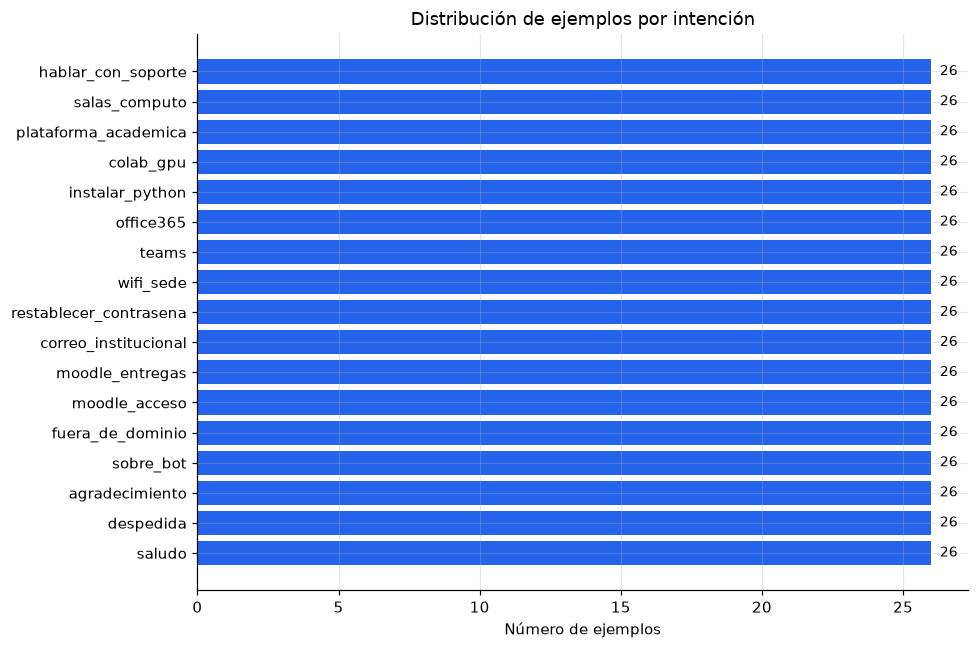

Razón de desbalance (máx/mín): 1.00  → dataset prácticamente balanceado


In [8]:
# ---------- (a) Distribución de clases ----------
conteo = df["intencion"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(conteo.index, conteo.values, color=COLOR_1)
for i, v in enumerate(conteo.values):
    ax.text(v + 0.3, i, str(v), va="center", fontsize=9)
ax.set_xlabel("Número de ejemplos")
ax.set_title("Distribución de ejemplos por intención")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_distribucion_clases.png"), bbox_inches="tight")
plt.show()

print(f"Razón de desbalance (máx/mín): {conteo.max() / conteo.min():.2f}  → dataset prácticamente balanceado")

In [9]:
# ---------- Funciones de normalización para el EDA ----------
def quitar_tildes(texto: str) -> str:
    """Elimina tildes y diacríticos (á→a, ñ→n) usando la descomposición Unicode NFD."""
    return "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")

def normalizar_eda(texto: str) -> str:
    """Minúsculas, sin tildes, sin signos de puntuación ni números; espacios simples."""
    texto = quitar_tildes(texto.lower())
    texto = re.sub(r"[^a-z\s]", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

STOPWORDS_ES = {quitar_tildes(w) for w in stopwords.words("spanish")} | {"q", "k", "porfa", "xq"}

def tokenizar_eda(texto: str, sin_stopwords: bool = True):
    """Tokeniza con NLTK (modelo punkt en español) y, opcionalmente, elimina stopwords."""
    tokens = nltk.word_tokenize(normalizar_eda(texto), language="spanish")
    return [t for t in tokens if len(t) > 1 and (not sin_stopwords or t not in STOPWORDS_ES)]

df["n_palabras"]    = df["texto"].apply(lambda t: len(tokenizar_eda(t, sin_stopwords=False)))
df["n_caracteres"]  = df["texto"].str.len()
df["tokens_eda"]    = df["texto"].apply(tokenizar_eda)

print(df[["n_palabras", "n_caracteres"]].describe().round(2))
print("\nEjemplo de tokenización NLTK:", df.loc[5, "texto"], "→", tokenizar_eda(df.loc[5, "texto"]))

       n_palabras  n_caracteres
count      442.00        442.00
mean         7.16         38.75
std          2.94         15.01
min          1.00          2.00
25%          5.00         29.00
50%          7.00         40.00
75%          9.00         49.00
max         15.00         80.00

Ejemplo de tokenización NLTK: quiubo bot → ['quiubo', 'bot']


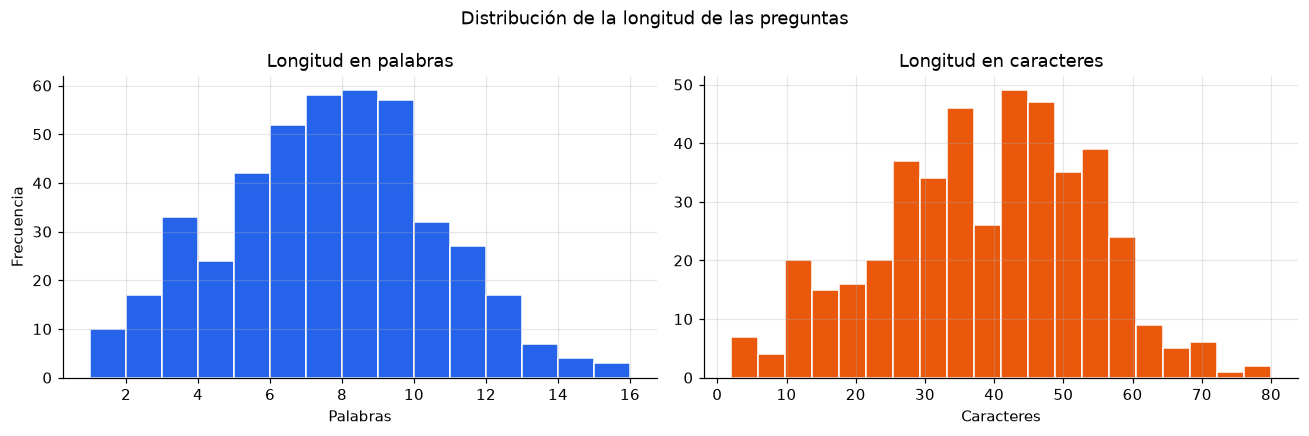

intencion,despedida,saludo,agradecimiento,sobre_bot,fuera_de_dominio,instalar_python,hablar_con_soporte,colab_gpu,office365,plataforma_academica,teams,salas_computo,wifi_sede,restablecer_contrasena,correo_institucional,moodle_entregas,moodle_acceso
palabras_promedio,3.08,3.35,3.81,4.31,5.96,7.15,7.38,7.69,7.96,8.19,8.46,8.54,8.62,8.73,9.15,9.58,9.77


In [10]:
# ---------- (b) Longitud de los textos ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["n_palabras"], bins=range(1, df["n_palabras"].max() + 2), color=COLOR_1, edgecolor="white")
axes[0].set_title("Longitud en palabras"); axes[0].set_xlabel("Palabras"); axes[0].set_ylabel("Frecuencia")
axes[1].hist(df["n_caracteres"], bins=20, color=COLOR_2, edgecolor="white")
axes[1].set_title("Longitud en caracteres"); axes[1].set_xlabel("Caracteres")
plt.suptitle("Distribución de la longitud de las preguntas")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_longitud_textos.png"), bbox_inches="tight")
plt.show()

# Longitud promedio por intención
df.groupby("intencion")["n_palabras"].mean().sort_values().round(2).to_frame("palabras_promedio").T

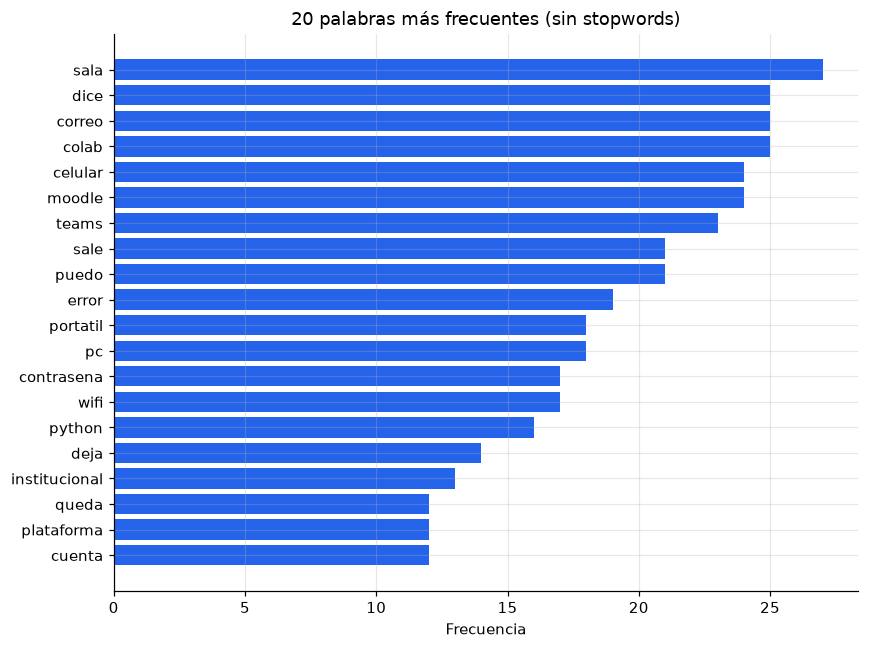

Tamaño del vocabulario (sin stopwords): 722 palabras


,top-5 palabras
agradecimiento,"gracias, funciono, uy, agradezco, bien"
colab_gpu,"colab, gpu, drive, dice, sale"
correo_institucional,"correo, institucional, correos, dice, celular"
despedida,"bueno, chao, voy, listo, bot"
fuera_de_dominio,"hago, cuanto, quiero, nota, celular"
hablar_con_soporte,"soporte, quiero, necesito, ticket, mesa"
instalar_python,"python, instalo, sale, pip, instale"
moodle_acceso,"moodle, virtual, entrar, dice, aula"
moodle_entregas,"archivo, tarea, moodle, subir, deja"
office365,"office, onedrive, cuenta, word, dice"


In [11]:
# ---------- (c) Palabras más frecuentes ----------
frecuencias = Counter(t for tokens in df["tokens_eda"] for t in tokens)
top = frecuencias.most_common(20)[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([p for p, _ in top], [c for _, c in top], color=COLOR_1)
ax.set_xlabel("Frecuencia"); ax.set_title("20 palabras más frecuentes (sin stopwords)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_palabras_frecuentes.png"), bbox_inches="tight")
plt.show()

print(f"Tamaño del vocabulario (sin stopwords): {len(frecuencias)} palabras")

# Palabras más representativas de cada intención
pd.DataFrame({intent: [", ".join(p for p, _ in Counter(t for toks in g["tokens_eda"] for t in toks).most_common(5))]
              for intent, g in df.groupby("intencion")}).T.rename(columns={0: "top-5 palabras"})

## 4. Preprocesamiento

Se usan **dos** normalizaciones, cada una con su propósito:

| Paso | Para el EDA (NLTK) | Para el modelo (BERT) |
|---|---|---|
| Minúsculas | Sí | Sí (BETO *uncased*) |
| Tildes | Se eliminan | **Se conservan**: el vocabulario de BETO incluye palabras acentuadas |
| Puntuación | Se elimina | Se conserva `¿?¡!.,` (aporta señal de pregunta) |
| Letras repetidas (`holaaaa`) | — | Se reducen a dos (`holaa`) |
| URLs, símbolos raros, espacios | Se eliminan | Se eliminan |
| Stopwords | Se eliminan | **No** se eliminan: BERT necesita el contexto completo |
| Tokenización | `nltk.word_tokenize` | Tokenizador WordPiece de BETO |

La misma función `normalizar_texto()` se aplica en el entrenamiento y en la inferencia del chatbot, para evitar diferencias entre ambos.

In [12]:
def normalizar_texto(texto: str) -> str:
    """Normalización para BERT: minúsculas, limpieza ligera, conserva tildes y signos de pregunta."""
    texto = str(texto).lower().strip()
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)             # URLs
    texto = re.sub(r"(.)\1{2,}", r"\1\1", texto)                       # holaaaa → holaa
    texto = re.sub(r"[^a-záéíóúüñ0-9¿?¡!.,\s]", " ", texto)           # símbolos y emojis
    return re.sub(r"\s+", " ", texto).strip()

df["texto_norm"] = df["texto"].apply(normalizar_texto)

# Mapeos etiqueta ↔ índice
ETIQUETAS = sorted(df["intencion"].unique())
label2id  = {e: i for i, e in enumerate(ETIQUETAS)}
id2label  = {i: e for e, i in label2id.items()}
df["label"] = df["intencion"].map(label2id)
NUM_LABELS = len(ETIQUETAS)

for t in ["Holaaaa!!! 😀", "NO ME DEJA ENTRAR A MOODLE???", "me sale error en https://x.co → ayuda"]:
    print(f"{t!r:45} → {normalizar_texto(t)!r}")

'Holaaaa!!! 😀'                                → 'holaa!!'
'NO ME DEJA ENTRAR A MOODLE???'               → 'no me deja entrar a moodle??'
'me sale error en https://x.co → ayuda'       → 'me sale error en ayuda'


In [13]:
# ---------- División estratificada 70 / 15 / 15 ----------
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

# MASSIVE: 30 frases a validación (siempre, si se descargó) y 100 preparadas para train (su uso se decide en validación, 5.3)
def preparar_externo(d):
    return d[["texto", "intencion"]].assign(texto_norm=d["texto"].apply(normalizar_texto),
                                            label=label2id["fuera_de_dominio"]).reset_index(drop=True)
massive_train_prep = preparar_externo(massive_train_df) if MASSIVE_OK else pd.DataFrame(columns=["texto", "intencion", "texto_norm", "label"])
if MASSIVE_OK:
    val_df = pd.concat([val_df, preparar_externo(massive_val_df)], ignore_index=True)

print(f"Entrenamiento: {len(train_df)} (+{len(massive_train_prep)} MASSIVE disponibles) | "
      f"Validación: {len(val_df)} (incluye {len(massive_val_df) if MASSIVE_OK else 0} MASSIVE) | Prueba: {len(test_df)}")
pd.DataFrame({"train": train_df["intencion"].value_counts(),
              "val": val_df["intencion"].value_counts(),
              "test": test_df["intencion"].value_counts()}).T

Entrenamiento: 309 (+100 MASSIVE disponibles) | Validación: 96 (incluye 30 MASSIVE) | Prueba: 67


intencion,agradecimiento,colab_gpu,correo_institucional,despedida,fuera_de_dominio,hablar_con_soporte,instalar_python,moodle_acceso,moodle_entregas,office365,plataforma_academica,restablecer_contrasena,salas_computo,saludo,sobre_bot,teams,wifi_sede
train,19,19,18,18,18,19,18,18,18,18,18,18,18,18,18,18,18
val,4,3,4,4,34,3,4,4,4,4,4,4,4,4,4,4,4
test,3,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4


Texto:    ¿por qué no me deja entrar al aula virtual, parce?
Tokens:   ['[CLS]', '¿', 'por', 'qué', 'no', 'me', 'deja', 'entrar', 'al', 'aula', 'virtual', ',', 'par', '##ce', '?', '[SEP]']
IDs:      [4, 1063, 1076, 1140, 1054, 1094, 3265, 3209, 1074, 23657, 15417, 1019, 1072, 1187, 1059, 5]

Tokens por pregunta → máx: 21 | percentil 99: 19


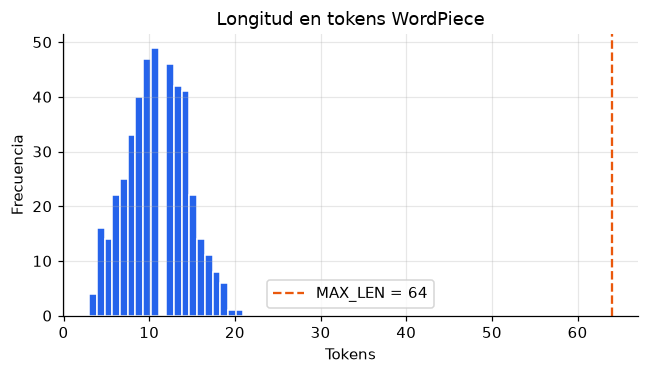

In [14]:
# ---------- Tokenizador de BERT en español (BETO) ----------
MODELO_BASE = "dccuchile/bert-base-spanish-wwm-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

ejemplo = normalizar_texto("¿Por qué no me deja entrar al aula virtual, parce?")
enc = tokenizer(ejemplo)
print("Texto:   ", ejemplo)
print("Tokens:  ", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("IDs:     ", enc["input_ids"])

# Longitud en tokens para elegir MAX_LEN
long_tokens = [len(tokenizer(t)["input_ids"]) for t in df["texto_norm"]]
print(f"\nTokens por pregunta → máx: {max(long_tokens)} | percentil 99: {np.percentile(long_tokens, 99):.0f}")
MAX_LEN = 64     # cubre holgadamente todas las preguntas y deja margen para mensajes más largos

plt.figure(figsize=(6, 3.5))
plt.hist(long_tokens, bins=20, color=COLOR_1, edgecolor="white")
plt.axvline(MAX_LEN, color=COLOR_2, linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Longitud en tokens WordPiece"); plt.xlabel("Tokens"); plt.ylabel("Frecuencia"); plt.legend()
plt.tight_layout(); plt.show()

In [15]:
# ---------- Conversión a datasets de Hugging Face y tokenización ----------
def tokenizar_lote(lote):
    return tokenizer(lote["texto_norm"], padding="max_length", truncation=True, max_length=MAX_LEN)

ds = DatasetDict({
    "train":      Dataset.from_pandas(train_df[["texto_norm", "label"]], preserve_index=False),
    "validation": Dataset.from_pandas(val_df[["texto_norm", "label"]],   preserve_index=False),
    "test":       Dataset.from_pandas(test_df[["texto_norm", "label"]],  preserve_index=False),
})
ds = ds.map(tokenizar_lote, batched=True)
ds.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
ds.save_to_disk(os.path.join(DATA_DIR, "dataset_tokenizado"))
print(ds)

Map:   0%|          | 0/309 [00:00<?, ? examples/s]

Map:   0%|          | 0/96 [00:00<?, ? examples/s]

Map:   0%|          | 0/67 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/309 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/96 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/67 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['texto_norm', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 309
    })
    validation: Dataset({
        features: ['texto_norm', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 96
    })
    test: Dataset({
        features: ['texto_norm', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 67
    })
})


### 4.1 Funciones de entrenamiento de BETO y BETO de referencia
Las funciones de entrenamiento y evaluación de BETO se definen aquí, antes del aumento de datos, porque el filtro de etiqueta del aumento usa un **BETO de referencia**: el modelo de la configuración inicial, sin aumento, con learning rate 2e-5 y entrenado **solo con la partición de entrenamiento** (sin MASSIVE); la validación se usa solo para el *early stopping*. Se guarda en `modelo_referencia` y no forma parte del modelo final ni de la entrega. Los hiperparámetros fijos están en la tabla de la sección 5.3.

In [16]:
# ---------- Funciones de entrenamiento y evaluación de BETO ----------
import gc

def mejora_f1(f1, perdida, mejor_f1, mejor_perdida, tol=1e-4):
    """Criterio de mejor época (BiLSTM y BETO): mayor F1 macro de validación; en empate, menor pérdida."""
    return f1 > mejor_f1 + tol or (abs(f1 - mejor_f1) <= tol and perdida < mejor_perdida - tol)

HP = {"learning_rate": 3e-5, "batch_size": 16, "epocas_max": 20, "paciencia": 4,
      "weight_decay": 0.01, "warmup_ratio": 0.10, "max_grad_norm": 1.0, "max_len": MAX_LEN}
# learning_rate, el aumento, MASSIVE y epocas_max se sustituyen por los valores elegidos en la búsqueda (sección 5.3)

def a_dataset(textos, etiquetas):
    """Tokeniza con BETO y devuelve una lista de ejemplos con el formato de ds (input_ids, attention_mask, label)."""
    enc = tokenizer(list(textos), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
    return [{"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i], "label": torch.tensor(int(e))}
            for i, e in enumerate(etiquetas)]

def liberar_gpu():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

def evaluar(modelo, loader):
    """Devuelve pérdida media, accuracy, predicciones, etiquetas reales y probabilidades."""
    modelo.eval()
    perdida_total, preds, reales, probs = 0.0, [], [], []
    with torch.no_grad():
        for lote in loader:
            lote = {k: v.to(DEVICE) for k, v in lote.items()}
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                salida = modelo(input_ids=lote["input_ids"], attention_mask=lote["attention_mask"],
                                labels=lote["label"])
            perdida_total += salida.loss.item() * lote["label"].size(0)
            p = torch.softmax(salida.logits.float(), dim=-1)
            probs.append(p.cpu()); preds += p.argmax(-1).cpu().tolist(); reales += lote["label"].cpu().tolist()
    return perdida_total / len(reales), accuracy_score(reales, preds), preds, reales, torch.cat(probs).numpy()


# ===================== Bucle de entrenamiento con early stopping =====================
def entrenar_beto(tr_df, va_df, lr, aumento=None):
    """Ajusta BETO con early stopping sobre el F1 macro de validación (desempate: menor pérdida).
    aumento: DataFrame (texto, intencion) con frases generadas a partir de tr_df que se agregan solo al entrenamiento.
    Devuelve el modelo con los pesos de la mejor época, el historial, la mejor época (con sus predicciones) y el tiempo."""
    fijar_semillas(SEED)
    textos, etiquetas = tr_df["texto_norm"].tolist(), tr_df["label"].tolist()
    if aumento is not None and len(aumento):
        textos += [normalizar_texto(t) for t in aumento["texto"]]
        etiquetas += [label2id[i] for i in aumento["intencion"]]
    g = torch.Generator().manual_seed(SEED)
    tr_loader = DataLoader(a_dataset(textos, etiquetas), batch_size=HP["batch_size"], shuffle=True, generator=g)
    va_loader = DataLoader(a_dataset(va_df["texto_norm"], va_df["label"]), batch_size=64)

    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
        attn_implementation="eager"   # permite extraer los pesos de atención (sección 6)
    ).to(DEVICE)
    optimizer = AdamW(modelo.parameters(), lr=lr, weight_decay=HP["weight_decay"])
    total_pasos = len(tr_loader) * HP["epocas_max"]
    scheduler = get_linear_schedule_with_warmup(optimizer, int(HP["warmup_ratio"] * total_pasos), total_pasos)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
    mejor = {"epoca": 0, "val_f1": -1.0, "val_loss": float("inf"), "val_acc": 0.0}
    sin_mejora, mejores_pesos, inicio = 0, None, time.time()
    for epoca in range(1, HP["epocas_max"] + 1):
        modelo.train()
        perdida_ep, aciertos, vistos = 0.0, 0, 0
        for lote in tr_loader:
            lote = {k: v.to(DEVICE) for k, v in lote.items()}
            optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                salida = modelo(input_ids=lote["input_ids"], attention_mask=lote["attention_mask"],
                                labels=lote["label"])
            scaler.scale(salida.loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), HP["max_grad_norm"])
            scaler.step(optimizer); scaler.update(); scheduler.step()

            n = lote["label"].size(0)
            perdida_ep += salida.loss.item() * n
            aciertos   += (salida.logits.argmax(-1) == lote["label"]).sum().item()
            vistos     += n

        val_loss, val_acc, val_preds, val_reales, _ = evaluar(modelo, va_loader)
        val_f1 = f1_score(val_reales, val_preds, average="macro", zero_division=0)
        hist["train_loss"].append(perdida_ep / vistos); hist["train_acc"].append(aciertos / vistos)
        hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc); hist["val_f1"].append(val_f1)

        if mejora_f1(val_f1, val_loss, mejor["val_f1"], mejor["val_loss"]):
            mejor, sin_mejora = {"epoca": epoca, "val_f1": val_f1, "val_loss": val_loss, "val_acc": val_acc,
                                 "val_preds": val_preds, "val_reales": val_reales, "n_train": len(textos)}, 0
            mejores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= HP["paciencia"]:
                break
    modelo.load_state_dict(mejores_pesos)
    return modelo, hist, mejor, time.time() - inicio

In [17]:
# ---------- BETO de referencia: sin aumento, learning rate 2e-5, solo la partición de entrenamiento ----------
MODELO_REFERENCIA = os.path.join(BASE_DIR, "modelo_referencia")
if os.path.isdir(MODELO_REFERENCIA):
    print(f"BETO de referencia cargado de disco ({MODELO_REFERENCIA}).")
else:
    beto_ref, hist_ref, mejor_ref, t_ref = entrenar_beto(train_df, val_df, 2e-5)
    beto_ref.save_pretrained(MODELO_REFERENCIA); tokenizer.save_pretrained(MODELO_REFERENCIA)
    print(f"BETO de referencia entrenado en {t_ref:.1f} s | mejor época {mejor_ref['epoca']} | "
          f"F1 macro de validación {mejor_ref['val_f1']:.4f} | guardado en {MODELO_REFERENCIA}")
    del beto_ref
    liberar_gpu()

BETO de referencia cargado de disco (soportic\modelo_referencia).


### 4.2 Aumento de datos del entrenamiento
Con unas 18 frases de entrenamiento por intención, BETO ve poca variedad de escritura. Se generan frases nuevas **solo a partir del conjunto de entrenamiento**; validación, prueba, generalización, la prueba aparte de MASSIVE y la prueba externa nunca se aumentan. Cada técnica es un hiperparámetro de BETO: se usa solo si mejora el F1 macro de validación (búsqueda de la sección 5.3).

| Técnica | Qué genera |
|---|---|
| Tildes | Copia de cada frase sin tildes en las vocales (á→a…), conservando la ñ |
| Ruido ortográfico | 1 copia con errores típicos del español informal: qu→k, que→ke, c/s/z, v↔b, h inicial omitida, ll↔y, letra duplicada u omitida, por→x, porque→xq |
| Retrotraducción | Español → inglés → español con MarianMT (Helsinki-NLP/opus-mt), 2 variantes por frase |

Las paráfrasis con un LLM (Qwen2.5-1.5B-Instruct) del proyecto anterior no se usan: en ese proyecto no mejoraron el F1 macro de validación.

**Filtros de calidad y anti-fuga.** La retrotraducción solo se aplica a frases de 3 o más palabras (en frases cortas como «ola» o «quiubo» pierde el sentido). Tildes y ruido son transformaciones por reglas que conservan la intención por construcción: solo pasan por los filtros de duplicados y anti-fuga. La retrotraducción pasa por los tres:
1. *Conservación de la etiqueta (solo retrotraducción):* similitud MiniLM con la frase de origen ≥ 0,70 y el BETO de referencia (sección 4.1) no debe asignar otra intención con confianza > 0,90. **En la validación cruzada solo se usa el criterio de MiniLM**, porque ese BETO se entrenó con frases que en otras particiones son de prueba.
2. *Duplicados:* sin duplicados exactos ni normalizados (minúsculas, sin signos ni tildes), entre sí ni con el entrenamiento. A la copia sin tildes solo se le aplica el criterio exacto (por construcción es un duplicado normalizado de su origen): las copias sin tildes idénticas al original se descartan porque no aportan información.
3. *Anti-fuga:* se descarta toda frase generada con similitud MiniLM ≥ 0,90 con alguna frase de validación, prueba, generalización, la prueba externa (todas sus líneas) o la prueba aparte de MASSIVE.

**Caché:** los candidatos (para las 442 frases, porque la validación cruzada usa el entrenamiento de cada partición) se guardan en `aumento_candidatos.csv`, y el aumento final del entrenamiento en `aumento_train.csv`. Si existen, se cargan; `SOPORTIC_REGENERAR_AUMENTO=1` fuerza la regeneración.

In [18]:
# ---------- Aumento de datos: candidatos, filtros y caché ----------
RUTA_CANDIDATOS = os.path.join(DATA_DIR, "aumento_candidatos.csv")
RUTA_AUMENTO    = os.path.join(DATA_DIR, "aumento_train.csv")
RUTA_REPORTE    = os.path.join(DATA_DIR, "aumento_reporte.csv")
REGENERAR_AUMENTO = os.environ.get("SOPORTIC_REGENERAR_AUMENTO", "0") == "1"
MODELO_SEMANTICO = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
SIM_ORIGEN_MIN, CONF_REFERENCIA_MAX, SIM_FUGA_MAX = 0.70, 0.90, 0.90

def quitar_tildes_vocales(texto: str) -> str:
    """Quita solo las tildes de las vocales (á é í ó ú ü → a e i o u) y conserva la ñ."""
    return texto.translate(str.maketrans("áéíóúüÁÉÍÓÚÜ", "aeiouuAEIOUU"))

def clave_normalizada(texto):
    return " ".join(re.sub(r"[^\w\s]", " ", quitar_tildes(str(texto).lower())).split())

# ---------- R1: ruido ortográfico del español informal ----------
REGLAS_PALABRA = [(r"\bporque\b", "xq"), (r"\bpor\b", "x"), (r"\bqu[eé]\b", "ke")]
REGLAS_LETRA = [(r"qu", "k"), (r"c(?=[ei])", "s"), (r"s", "z"), (r"z", "s"), (r"v", "b"), (r"b", "v"),
                (r"ll", "y"), (r"(?<!l)y(?=[aeiou])", "ll"), (r"\bh(?=[aeiouáéíóú])", "")]

def ruido_ortografico(texto, rng):
    """Aplica dos cambios ortográficos aleatorios típicos del chat informal."""
    t = texto.lower()
    for _ in range(2):
        opciones = [(p, r) for p, r in REGLAS_PALABRA + REGLAS_LETRA if re.search(p, t)]
        opciones += [("duplicar", None), ("omitir", None)]
        p, r = opciones[rng.integers(len(opciones))]
        if p in ("duplicar", "omitir"):
            pos = [m.start() for m in re.finditer(r"[a-zñ]", t)]
            if len(pos) > 3:
                i = pos[rng.integers(1, len(pos))]
                t = t[:i] + t[i] + t[i:] if p == "duplicar" else t[:i] + t[i + 1:]
        else:
            ms = list(re.finditer(p, t)); m = ms[rng.integers(len(ms))]
            t = t[:m.start()] + r + t[m.end():]
    return t if t != texto.lower() else texto.lower() + texto.lower()[-1]

# ---------- R8.1: retrotraducción con MarianMT ----------
def retrotraducir(textos, lote=32):
    from transformers import MarianMTModel, MarianTokenizer
    tok_ida, mod_ida = MarianTokenizer.from_pretrained("Helsinki-NLP/opus-mt-es-en"), MarianMTModel.from_pretrained("Helsinki-NLP/opus-mt-es-en").to(DEVICE).eval()
    tok_vta, mod_vta = MarianTokenizer.from_pretrained("Helsinki-NLP/opus-mt-en-es"), MarianMTModel.from_pretrained("Helsinki-NLP/opus-mt-en-es").to(DEVICE).eval()
    salida = []
    with torch.no_grad():
        for i in range(0, len(textos), lote):
            b = textos[i:i + lote]
            en = tok_ida.batch_decode(mod_ida.generate(**tok_ida(b, return_tensors="pt", padding=True, truncation=True).to(DEVICE),
                                                       num_beams=4, max_new_tokens=64), skip_special_tokens=True)
            es = tok_vta.batch_decode(mod_vta.generate(**tok_vta(en, return_tensors="pt", padding=True, truncation=True).to(DEVICE),
                                                       num_beams=4, num_return_sequences=2, max_new_tokens=64), skip_special_tokens=True)
            salida += [(b[j], es[2 * j + k]) for j in range(len(b)) for k in range(2)]
    del mod_ida, mod_vta; liberar = gc.collect(); torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return salida

encoder_sem = SentenceTransformer(MODELO_SEMANTICO, device=str(DEVICE))
def embeber(textos):
    return encoder_sem.encode([normalizar_texto(t) for t in textos], convert_to_tensor=True, normalize_embeddings=True,
                              batch_size=128)

# ---------- Generación de candidatos para las 442 frases (o carga de la caché) ----------
if os.path.exists(RUTA_CANDIDATOS) and not REGENERAR_AUMENTO:
    candidatos = pd.read_csv(RUTA_CANDIDATOS)
    print(f"Candidatos cargados de la caché: {len(candidatos)} ({RUTA_CANDIDATOS})")
else:
    t0 = time.time()
    intent_de = dict(zip(df["texto"], df["intencion"]))
    rng_ruido = np.random.default_rng(SEED)
    filas_c = [{"texto": ruido_ortografico(t, rng_ruido), "frase_origen": t, "tecnica": "ruido"} for t in df["texto"]]
    filas_c += [{"texto": s, "frase_origen": o, "tecnica": "retrotraduccion"} for o, s in retrotraducir(df["texto"].tolist())]
    candidatos = pd.DataFrame(filas_c)
    candidatos["intencion"] = candidatos["frase_origen"].map(intent_de)
    emb_c, emb_o = embeber(candidatos["texto"].tolist()), embeber(candidatos["frase_origen"].tolist())
    candidatos["sim_origen"] = (emb_c * emb_o).sum(-1).cpu().numpy().round(4)
    if os.path.isdir(MODELO_REFERENCIA):   # BETO de referencia (configuración inicial) para el filtro de etiqueta
        tok_ref = AutoTokenizer.from_pretrained(MODELO_REFERENCIA)
        beto_ref = AutoModelForSequenceClassification.from_pretrained(MODELO_REFERENCIA).to(DEVICE).eval()
        preds, confs = [], []
        with torch.no_grad():
            for i in range(0, len(candidatos), 128):
                enc = tok_ref([normalizar_texto(t) for t in candidatos["texto"].iloc[i:i + 128]], padding=True, truncation=True,
                              max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
                p = torch.softmax(beto_ref(**enc).logits.float(), dim=-1).cpu()
                confs += p.max(-1).values.tolist(); preds += [beto_ref.config.id2label[int(k)] for k in p.argmax(-1)]
        candidatos["ref_pred"], candidatos["ref_conf"] = preds, np.round(confs, 4)
        del beto_ref; gc.collect()
    else:
        candidatos["ref_pred"], candidatos["ref_conf"] = None, np.nan
        print("Aviso: no está el BETO de referencia; el filtro de etiqueta usará solo MiniLM.")
    candidatos.to_csv(RUTA_CANDIDATOS, index=False)
    print(f"Candidatos generados en {time.time() - t0:.0f} s: {len(candidatos)}")
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# ---------- Filtros ----------
def filtrar_aumento(origen_df, reservadas, usar_referencia=True):
    """Aumento filtrado para un conjunto de entrenamiento. Devuelve (aumento, reporte por técnica y filtro)."""
    c = candidatos[candidatos["frase_origen"].isin(set(origen_df["texto"]))].copy()
    tildes = origen_df[["texto", "intencion"]].assign(frase_origen=origen_df["texto"], tecnica="tildes",
                                                     texto=origen_df["texto_norm"].apply(quitar_tildes_vocales))
    c = pd.concat([tildes, c], ignore_index=True)
    c["motivo"] = ""
    corta = (c["tecnica"] == "retrotraduccion") & (c["frase_origen"].str.split().str.len() < 3)
    c.loc[corta, "motivo"] = "retrotraducción: origen de menos de 3 palabras"
    vacia = (c["motivo"] == "") & (c["texto"].isna() | (c["texto"].astype(str).str.strip() == "") |
                                   ((c["tecnica"] != "tildes") & (c["texto"].astype(str).str.lower().str.strip()
                                                                  == c["frase_origen"].str.lower().str.strip())))
    c.loc[vacia, "motivo"] = "vacía o igual al origen"
    # Conservación de la etiqueta: solo para técnicas que reescriben la frase (no para tildes ni ruido, que son reglas)
    gen = (c["motivo"] == "") & c["tecnica"].isin(["retrotraduccion"])
    c.loc[gen & (c["sim_origen"] < SIM_ORIGEN_MIN), "motivo"] = "etiqueta: similitud con origen < 0,70"
    if usar_referencia and c["ref_pred"].notna().any():
        cambia = gen & (c["motivo"] == "") & (c["ref_pred"] != c["intencion"]) & (c["ref_conf"] > CONF_REFERENCIA_MAX)
        c.loc[cambia, "motivo"] = "etiqueta: BETO de referencia > 0,90 en otra intención"
    claves_train = set(origen_df["texto"].apply(clave_normalizada))
    exactas_train = set(origen_df["texto_norm"].str.strip())
    vistas, vistas_exactas = set(), set()
    for i in c.index[c["motivo"] == ""]:
        texto = str(c.at[i, "texto"]).strip()
        if c.at[i, "tecnica"] == "tildes":           # solo duplicado exacto (sin tildes = igual al original)
            if texto in exactas_train or texto in vistas_exactas:
                c.at[i, "motivo"] = "duplicado"
            vistas_exactas.add(texto)
            continue
        k = clave_normalizada(texto)
        if k in claves_train or k in vistas:
            c.at[i, "motivo"] = "duplicado"
        vistas.add(k)
    vivas = c.index[c["motivo"] == ""]
    if len(vivas):
        sims = util.cos_sim(embeber(c.loc[vivas, "texto"].astype(str).tolist()), embeber(reservadas)).max(dim=1).values.cpu().numpy()
        c.loc[vivas[sims >= SIM_FUGA_MAX], "motivo"] = "anti-fuga: similitud ≥ 0,90 con frases reservadas"
    reporte = c.assign(estado=np.where(c["motivo"] == "", "conservada", c["motivo"]))
    aumento = c[c["motivo"] == ""][["texto", "intencion", "tecnica", "frase_origen"]].reset_index(drop=True)
    return aumento, reporte

reservadas_unica = (val_df["texto"].tolist() + test_df["texto"].tolist() + gen_df["texto"].tolist() + FRASES_RESERVADAS
                    + (massive_prueba_df["texto"].tolist() if MASSIVE_OK else []))
if os.path.exists(RUTA_AUMENTO) and os.path.exists(RUTA_REPORTE) and not REGENERAR_AUMENTO:
    aumento_train = pd.read_csv(RUTA_AUMENTO); reporte_aumento = pd.read_csv(RUTA_REPORTE)
    print(f"Aumento del entrenamiento cargado de la caché: {len(aumento_train)} frases ({RUTA_AUMENTO})")
else:
    aumento_train, reporte_aumento = filtrar_aumento(train_df, reservadas_unica, usar_referencia=True)
    aumento_train.to_csv(RUTA_AUMENTO, index=False)
    reporte_aumento[["texto", "intencion", "tecnica", "frase_origen", "estado"]].to_csv(RUTA_REPORTE, index=False)

# ---------- Reporte ----------
tabla_filtros = reporte_aumento.pivot_table(index="tecnica", columns="estado", values="texto", aggfunc="count", fill_value=0)
tabla_filtros.insert(0, "generadas", tabla_filtros.sum(axis=1))
print("\nFrases generadas y eliminadas por filtro (por técnica):")
print(tabla_filtros.to_string())
tabla_intencion = (reporte_aumento[reporte_aumento["estado"] == "conservada"]
                   .pivot_table(index="intencion", columns="tecnica", values="texto", aggfunc="count", fill_value=0))
tabla_intencion["train original"] = train_df["intencion"].value_counts()
print("\nFrases conservadas por intención y técnica:")
print(tabla_intencion.fillna(0).astype(int).to_string())
print("\nEjemplos conservados:")
print(aumento_train.groupby("tecnica").head(3)[["tecnica", "frase_origen", "texto"]].to_string(index=False))

Candidatos cargados de la caché: 1326 (soportic\datos\aumento_candidatos.csv)
Aumento del entrenamiento cargado de la caché: 741 frases (soportic\datos\aumento_train.csv)

Frases generadas y eliminadas por filtro (por técnica):
estado           generadas  anti-fuga: similitud ≥ 0,90 con frases reservadas  conservada  duplicado  etiqueta: BETO de referencia > 0,90 en otra intención  etiqueta: similitud con origen < 0,70  retrotraducción: origen de menos de 3 palabras  vacía o igual al origen
tecnica                                                                                                                                                                                                                                                                    
retrotraduccion        618                                                  6         437         78                                                      3                                     39                                          

## 5. Modelos

Se entrenan tres clasificadores de intención sobre la misma partición, de menor a mayor capacidad, para medir qué aporta cada concepto de la asignatura.

### 5.1 Línea base clásica: TF-IDF + regresión logística
Cada pregunta se representa como un vector disperso de pesos TF-IDF de palabras y bigramas, y una regresión logística (un clasificador lineal) separa las intenciones. No hay capas ocultas ni representaciones aprendidas: sirve para saber cuánto aporta el aprendizaje profundo.

In [19]:
def base_entrenamiento(tr_df, con_massive):
    """Entrenamiento real (sin texto generado): train + las 100 frases de MASSIVE si se usan."""
    return pd.concat([tr_df, massive_train_prep], ignore_index=True) if con_massive and MASSIVE_OK else tr_df

# Provisional: MASSIVE se usa si se descargó; la búsqueda de 5.3 lo confirma o lo descarta en validación
USAR_MASSIVE = MASSIVE_OK

def entrenar_tfidf(tr_df):
    vec = TfidfVectorizer(preprocessor=normalizar_eda, ngram_range=(1, 2), sublinear_tf=True)
    clf = LogisticRegression(max_iter=2000, C=10, random_state=SEED).fit(vec.fit_transform(tr_df["texto"]), tr_df["label"])
    return vec, clf

t_tfidf0 = time.time()
tfidf, clf_tfidf = entrenar_tfidf(base_entrenamiento(train_df, USAR_MASSIVE))
tiempo_tfidf = time.time() - t_tfidf0
pred_tfidf_test = clf_tfidf.predict(tfidf.transform(test_df["texto"]))
pred_tfidf_gen  = [id2label[p] for p in clf_tfidf.predict(tfidf.transform(gen_df["texto"]))]
print(f"TF-IDF + LogReg → accuracy prueba: {accuracy_score(test_df['label'], pred_tfidf_test):.4f} | "
      f"accuracy generalización: {accuracy_score(gen_df['intencion'], pred_tfidf_gen):.4f}")

TF-IDF + LogReg → accuracy prueba: 0.5522 | accuracy generalización: 0.7059


### 5.2 Red neuronal desde cero: Embedding + BiLSTM
Red entrenada sin conocimiento previo, con los bloques básicos de la asignatura: una capa de **embeddings** que aprende un vector por palabra, una **LSTM bidireccional** que lee la pregunta en ambos sentidos, *dropout* y una **capa densa con softmax** sobre las 17 intenciones. Se entrena con entropía cruzada, retropropagación y AdamW, con *early stopping* sobre el F1 macro de validación (desempate: menor pérdida), el mismo criterio que BETO. Es el mismo tipo de codificador recurrente de la Parte 1 del taller de Transformers, aquí usado para clasificar.

Vocabulario: 880 palabras | Parámetros BiLSTM: 381,201

Historial de la BiLSTM por época:
       train_loss  val_loss  val_acc  val_f1
época                                       
1          2.7152    2.4168   0.3542  0.0308
2          2.3057    2.1861   0.3854  0.1026
3          1.9020    1.8669   0.4479  0.2123
4          1.4057    1.6995   0.4896  0.2893
5          0.9206    1.4942   0.5833  0.4041
6          0.5977    1.6241   0.5312  0.3570
7          0.3386    1.4789   0.5729  0.4117
8          0.1763    1.3708   0.5625  0.4043
9          0.0948    1.3882   0.5938  0.5103
10         0.0506    1.5057   0.5625  0.4343
11         0.0306    1.3573   0.6146  0.5000
12         0.0213    1.3622   0.6667  0.5405
13         0.0147    1.3603   0.6250  0.5203
14         0.0123    1.3836   0.6458  0.5323
15         0.0109    1.3626   0.6458  0.5144
16         0.0088    1.3950   0.6042  0.4953
17         0.0079    1.3859   0.6146  0.4972
18         0.0064    1.3858   0.6458  0.5167
19        

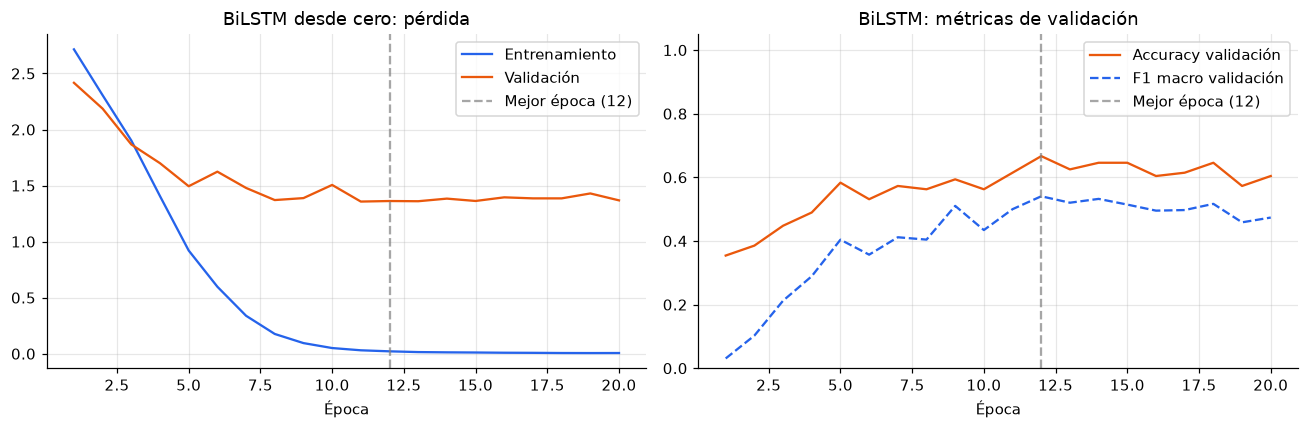

In [20]:
import torch.nn as nn

LSTM_MAXLEN = 20

def construir_vocab(textos):
    """Vocabulario de palabras construido solo con los textos de entrenamiento."""
    voc = {"<pad>": 0, "<unk>": 1}
    for toks in textos.apply(lambda t: tokenizar_eda(t, sin_stopwords=False)):
        for w in toks:
            voc.setdefault(w, len(voc))
    return voc

def codificar(textos, voc):
    ids = np.zeros((len(textos), LSTM_MAXLEN), dtype=np.int64)
    for i, t in enumerate(textos):
        toks = [voc.get(w, 1) for w in tokenizar_eda(t, sin_stopwords=False)][:LSTM_MAXLEN]
        ids[i, :len(toks)] = toks
    return torch.tensor(ids)

class BiLSTMClasificador(nn.Module):
    def __init__(self, n_vocab, n_clases, emb=128, oculta=128):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, oculta, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.salida = nn.Linear(2 * oculta, n_clases)

    def forward(self, x):
        h, _ = self.lstm(self.emb(x))
        mascara = (x != 0).unsqueeze(-1).float()
        h = (h * mascara).sum(1) / mascara.sum(1).clamp(min=1)    # promedio sobre las palabras reales
        return self.salida(self.drop(h))

def entrenar_bilstm(tr_df, va_df, paciencia=8):
    """Entrena la BiLSTM con early stopping sobre el F1 macro de validación y devuelve los mejores pesos."""
    fijar_semillas(SEED)
    voc = construir_vocab(tr_df["texto"])
    X_tr, X_va = codificar(tr_df["texto"], voc), codificar(va_df["texto"], voc)
    y_tr, y_va = torch.tensor(tr_df["label"].values), torch.tensor(va_df["label"].values)
    red = BiLSTMClasificador(len(voc), NUM_LABELS).to(DEVICE)
    opt = AdamW(red.parameters(), lr=2e-3, weight_decay=0.01)
    perdida_ce = nn.CrossEntropyLoss()

    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}
    mejor_f1, mejor_vl, mejor_ep, sin_mejora, pesos = -1.0, float("inf"), 0, 0, None
    t0 = time.time()
    for ep in range(1, 101):
        red.train(); perm = torch.randperm(len(X_tr)); total = 0.0
        for i in range(0, len(X_tr), 32):
            idx = perm[i:i + 32]
            xb, yb = X_tr[idx].to(DEVICE), y_tr[idx].to(DEVICE)
            opt.zero_grad()
            loss = perdida_ce(red(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(red.parameters(), 1.0)
            opt.step(); total += loss.item() * len(idx)
        red.eval()
        with torch.no_grad():
            logits_va = red(X_va.to(DEVICE))
            vl = perdida_ce(logits_va, y_va.to(DEVICE)).item()
            pred_va = logits_va.argmax(-1).cpu()
            va = (pred_va == y_va).float().mean().item()
            vf1 = f1_score(y_va.numpy(), pred_va.numpy(), average="macro", zero_division=0)
        hist["train_loss"].append(total / len(X_tr)); hist["val_loss"].append(vl)
        hist["val_acc"].append(va); hist["val_f1"].append(vf1)
        if mejora_f1(vf1, vl, mejor_f1, mejor_vl):
            mejor_f1, mejor_vl, mejor_ep, sin_mejora = vf1, vl, ep, 0
            pesos = {k: v.detach().clone() for k, v in red.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    red.load_state_dict(pesos); red.eval()
    return red, voc, hist, mejor_ep, time.time() - t0

def predecir_lstm(textos, red, voc):
    with torch.no_grad():
        return red(codificar(textos, voc).to(DEVICE)).argmax(-1).cpu().numpy()

lstm, vocab, hist_lstm, mejor_ep_lstm, tiempo_lstm = entrenar_bilstm(base_entrenamiento(train_df, USAR_MASSIVE), val_df)
print(f"Vocabulario: {len(vocab)} palabras | Parámetros BiLSTM: {sum(p.numel() for p in lstm.parameters()):,}")
print("\nHistorial de la BiLSTM por época:")
print(pd.DataFrame(hist_lstm, index=pd.RangeIndex(1, len(hist_lstm["val_loss"]) + 1, name="época")).round(4).to_string())

pred_lstm_test = predecir_lstm(test_df["texto"], lstm, vocab)
pred_lstm_gen  = [id2label[p] for p in predecir_lstm(gen_df["texto"], lstm, vocab)]
print(f"\nBiLSTM: {len(hist_lstm['val_loss'])} épocas (mejor por F1 macro de validación: {mejor_ep_lstm}) "
      f"en {tiempo_lstm:.1f} s → accuracy prueba: {accuracy_score(test_df['label'], pred_lstm_test):.4f} | "
      f"accuracy generalización: {accuracy_score(gen_df['intencion'], pred_lstm_gen):.4f}")

ep_lstm = range(1, len(hist_lstm["val_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep_lstm, hist_lstm["train_loss"], color=COLOR_1, label="Entrenamiento"); ax[0].plot(ep_lstm, hist_lstm["val_loss"], color=COLOR_2, label="Validación")
ax[0].set_title("BiLSTM desde cero: pérdida"); ax[0].set_xlabel("Época")
ax[1].plot(ep_lstm, hist_lstm["val_acc"], color=COLOR_2, label="Accuracy validación")
ax[1].plot(ep_lstm, hist_lstm["val_f1"], "--", color=COLOR_1, label="F1 macro validación")
ax[1].set_title("BiLSTM: métricas de validación"); ax[1].set_xlabel("Época"); ax[1].set_ylim(0, 1.05)
for a in ax:
    a.axvline(mejor_ep_lstm, color="gray", linestyle="--", alpha=0.7, label=f"Mejor época ({mejor_ep_lstm})"); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig4a_curvas_bilstm.png"), bbox_inches="tight"); plt.show()

### 5.3 Transfer learning: BETO con *fine-tuning*

A diferencia de la BiLSTM, BETO llega con lo aprendido en un corpus grande en español (*transfer learning*): solo hay que ajustar sus pesos a las 17 intenciones.

**Arquitectura:** BETO (BERT-base, 12 capas, 12 cabezas, dimensión 768, ~110 M parámetros) + una capa lineal de clasificación sobre el vector del token `[CLS]` con 17 salidas (una por intención). Se ajustan **todas** las capas (*fine-tuning* completo).

**Hiperparámetros:**

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Learning rate | Elegido en validación entre 2e-5, 3e-5 y 5e-5 | Rango recomendado por Devlin et al. para *fine-tuning*; valores mayores destruyen el conocimiento preentrenado |
| Aumento de datos | Elegido en validación entre sin aumento, tildes, + ruido y + retrotraducción (sección 4.2) | Los usuarios escriben sin tildes, con errores y con otras palabras; el tokenizador de BETO distingue «atención» de «aten ##cion» |
| Fuera de dominio externo (MASSIVE) | Elegido en validación (con / sin las 100 frases) | Más variedad de temas ajenos al soporte para la clase `fuera_de_dominio` |
| Batch size | 16 | Estable con pocos datos y holgado para los 16 GB de la T4 |
| Épocas máximas | 20 (30 si la mejor época queda en el límite) | Límite superior; el *early stopping* decide cuándo parar |
| Early stopping | paciencia 4 sobre el F1 macro de validación (desempate: menor pérdida) | Evita el sobreajuste, frecuente con datasets pequeños; el F1 macro es la métrica que se reporta |
| Optimizador | AdamW, *weight decay* 0.01 | Adam con regularización L2 desacoplada, estándar en Transformers |
| Scheduler | Lineal con 10 % de calentamiento (*warmup*) | Evita actualizaciones bruscas al inicio |
| Dropout | 0.1 (por defecto en BERT) | Regularización interna |
| Recorte de gradiente | norma 1.0 | Estabilidad numérica |
| Precisión mixta | fp16 en GPU | Entrenamiento más rápido y con menos memoria |
| MAX_LEN | 64 tokens | Supera la longitud máxima observada |

El **bucle de entrenamiento en PyTorch** (definido en la sección 4.1) registra pérdida, accuracy y F1 macro por época y se queda con los pesos de la mejor época de validación. El aumento de datos y el learning rate se eligen con una búsqueda en dos etapas evaluada **solo en validación**; prueba, generalización, prueba externa y la prueba aparte de MASSIVE se miden al final.

In [21]:
# ---------- Cargadores de validación y prueba (las funciones de entrenamiento están en la sección 4.1) ----------
val_loader   = DataLoader(ds["validation"], batch_size=64)
test_loader  = DataLoader(ds["test"], batch_size=64)

**Selección de la configuración en validación (dos etapas).** Todas las corridas usan la misma semilla, la misma partición y el mismo criterio de parada, y se comparan solo por F1 macro de validación (desempate: menor pérdida). Prueba, generalización, la prueba externa y la prueba aparte de MASSIVE no intervienen.

- **Etapa 1 (aumento de datos y MASSIVE, learning rate 2e-5):** sin aumento, tildes, tildes + ruido y tildes + ruido + retrotraducción, todas con las 100 frases de MASSIVE, más la configuración comparable «tildes sin MASSIVE». Si esta última gana, MASSIVE no se usa.
- **Etapa 2 (learning rate):** con el aumento ganador, learning rate 2e-5, 3e-5 y 5e-5.
- Si la mejor época de la configuración ganadora coincide con `epocas_max`, se repite con 30 épocas y se conserva la que tenga mayor F1 macro de validación.

El modelo final es el de la corrida ganadora: no se vuelve a entrenar.

Etapa 1: aumento de datos y MASSIVE (lr 2e-5)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


etapa=1 | aumento=no | massive=sí | learning_rate=2e-05 | epocas_max=20 | n_train=409 | val_f1_macro=0.7997 | val_accuracy=0.8438 | val_f1_fuera_de_dominio=0.9296 | val_loss=0.5868 | mejor_epoca=12 | epocas_ejecutadas=16 | tiempo_s=160.3


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


etapa=1 | aumento=tildes | massive=sí | learning_rate=2e-05 | epocas_max=20 | n_train=409 | val_f1_macro=0.7997 | val_accuracy=0.8438 | val_f1_fuera_de_dominio=0.9296 | val_loss=0.5868 | mejor_epoca=12 | epocas_ejecutadas=16 | tiempo_s=143.7


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (7 outputs left out)

etapa=2 | aumento=tildes+ruido+retrotraducción | massive=sí | learning_rate=3e-05 | epocas_max=20 | n_train=1150 | val_f1_macro=0.8146 | val_accuracy=0.8542 | val_f1_fuera_de_dominio=0.9552 | val_loss=0.568 | mejor_epoca=8 | epocas_ejecutadas=12 | tiempo_s=309.3


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


etapa=2 | aumento=tildes+ruido+retrotraducción | massive=sí | learning_rate=5e-05 | epocas_max=20 | n_train=1150 | val_f1_macro=0.8079 | val_accuracy=0.8542 | val_f1_fuera_de_dominio=0.9697 | val_loss=0.6673 | mejor_epoca=5 | epocas_ejecutadas=9 | tiempo_s=231.0



La mejor época del ganador (5) queda por debajo de epocas_max (20): no hace falta subirlo.

Configuración elegida (mayor F1 macro de validación): aumento «tildes+ruido+retrotraducción» | MASSIVE: sí | learning rate 2e-05 | epocas_max 20
Tamaño del entrenamiento por versión: {'original': 309, 'original + MASSIVE': 409, '+ no': 409, '+ tildes': 409, '+ tildes+ruido': 713, '+ tildes+ruido+retrotraducción': 1150}


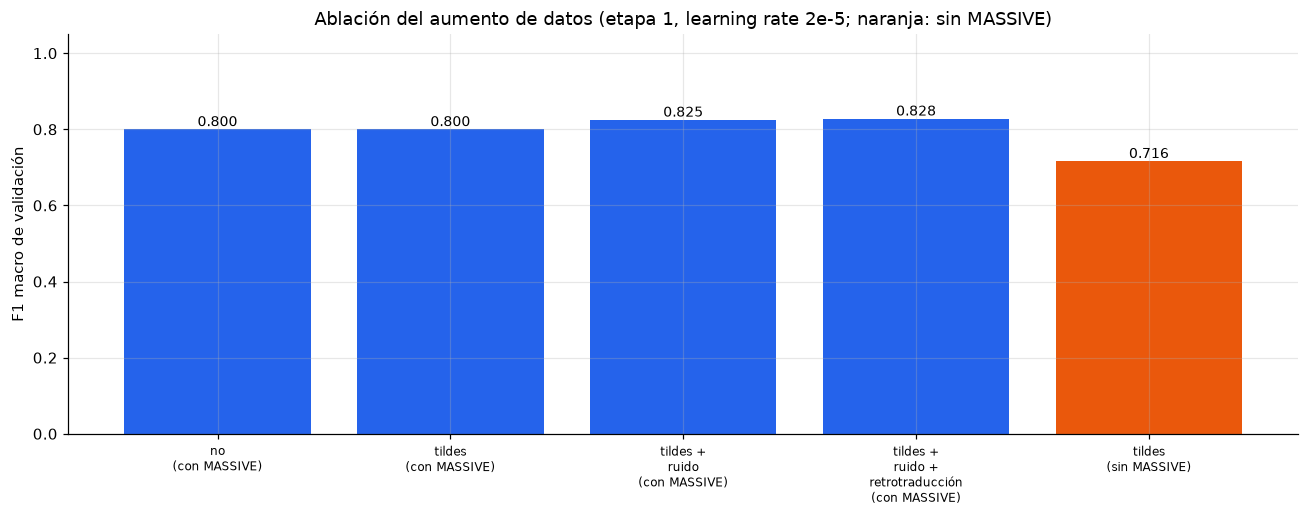

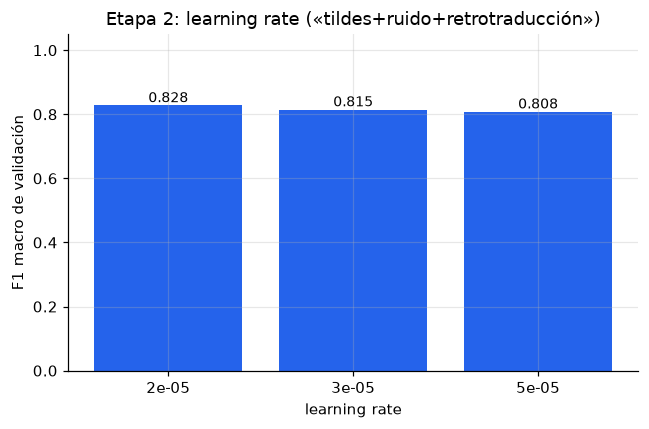

,etapa,aumento,massive,learning_rate,epocas_max,n_train,val_f1_macro,val_accuracy,val_f1_fuera_de_dominio,val_loss,mejor_epoca,epocas_ejecutadas,tiempo_s
0,1,no,sí,0.00002,20,409,0.7997,0.8438,0.9296,0.5868,12,16,160.3
1,1,tildes,sí,0.00002,20,409,0.7997,0.8438,0.9296,0.5868,12,16,143.7
2,1,tildes+ruido,sí,0.00002,20,713,0.8246,0.8750,0.9851,0.4804,8,12,156.1
3,1,tildes+ruido+retrotraducción,sí,0.00002,20,1150,0.8275,0.8646,0.9706,0.5241,5,9,192.7
4,1,tildes,no,0.00002,20,309,0.7160,0.6875,0.6275,1.2078,13,17,127.8
5,2,tildes+ruido+retrotraducción,sí,0.00003,20,1150,0.8146,0.8542,0.9552,0.5680,8,12,309.3
6,2,tildes+ruido+retrotraducción,sí,0.00005,20,1150,0.8079,0.8542,0.9697,0.6673,5,9,231.0


In [22]:
# ---------- Búsqueda en dos etapas (solo validación) ----------
ID_FUERA = label2id["fuera_de_dominio"]
TECNICAS = {"no": [], "tildes": ["tildes"], "tildes+ruido": ["tildes", "ruido"],
            "tildes+ruido+retrotraducción": ["tildes", "ruido", "retrotraduccion"]}
ETAPA1 = [(nombre, MASSIVE_OK) for nombre in TECNICAS] + ([("tildes", False)] if MASSIVE_OK else [])

filas_busqueda, ganador = [], None
def correr_configuracion(etapa, nombre_aumento, con_massive, lr, epocas_max=None):
    """Entrena una configuración, la agrega a la tabla y conserva el modelo solo si es el nuevo ganador."""
    global ganador
    epocas_previas = HP["epocas_max"]
    if epocas_max:
        HP["epocas_max"] = epocas_max
    aumento = aumento_train[aumento_train["tecnica"].isin(TECNICAS[nombre_aumento])]
    modelo_c, hist_c, mejor_c, t_c = entrenar_beto(base_entrenamiento(train_df, con_massive), val_df, lr, aumento)
    f1_fuera = f1_score(mejor_c["val_reales"], mejor_c["val_preds"], labels=[ID_FUERA], average="macro", zero_division=0)
    fila = {"etapa": etapa, "aumento": nombre_aumento, "massive": "sí" if con_massive else "no", "learning_rate": lr,
            "epocas_max": HP["epocas_max"], "n_train": mejor_c["n_train"], "val_f1_macro": round(mejor_c["val_f1"], 4),
            "val_accuracy": round(mejor_c["val_acc"], 4), "val_f1_fuera_de_dominio": round(f1_fuera, 4),
            "val_loss": round(mejor_c["val_loss"], 4), "mejor_epoca": mejor_c["epoca"],
            "epocas_ejecutadas": len(hist_c["val_loss"]), "tiempo_s": round(t_c, 1)}
    filas_busqueda.append(fila)
    print(" | ".join(f"{k}={v}" for k, v in fila.items()))
    if ganador is None or mejora_f1(mejor_c["val_f1"], mejor_c["val_loss"], ganador["mejor"]["val_f1"], ganador["mejor"]["val_loss"]):
        ganador = {"aumento": nombre_aumento, "massive": con_massive, "lr": lr, "epocas_max": HP["epocas_max"],
                   "modelo": modelo_c, "hist": hist_c, "mejor": mejor_c, "tiempo": t_c}
    del modelo_c
    liberar_gpu()
    HP["epocas_max"] = epocas_previas

print("Etapa 1: aumento de datos y MASSIVE (lr 2e-5)")
for nombre, con_massive in ETAPA1:
    correr_configuracion(1, nombre, con_massive, 2e-5)
aumento_e1, massive_e1 = ganador["aumento"], ganador["massive"]
print(f"→ Ganador de la etapa 1: aumento «{aumento_e1}», MASSIVE: {'sí' if massive_e1 else 'no'}\n")

print("Etapa 2: learning rate con el aumento ganador")
for lr in (3e-5, 5e-5):
    correr_configuracion(2, aumento_e1, massive_e1, lr)

if ganador["mejor"]["epoca"] == ganador["epocas_max"]:
    print(f"\nLa mejor época ({ganador['mejor']['epoca']}) coincide con epocas_max: se repite con 30 épocas.")
    correr_configuracion(3, ganador["aumento"], ganador["massive"], ganador["lr"], epocas_max=30)
else:
    print(f"\nLa mejor época del ganador ({ganador['mejor']['epoca']}) queda por debajo de epocas_max "
          f"({ganador['epocas_max']}): no hace falta subirlo.")

busqueda_beto = pd.DataFrame(filas_busqueda)
busqueda_beto.to_csv(os.path.join(DATA_DIR, "busqueda_beto.csv"), index=False)

HP.update({"learning_rate": ganador["lr"], "aumento": ganador["aumento"], "tecnicas_aumento": TECNICAS[ganador["aumento"]],
           "massive": bool(ganador["massive"]), "epocas_max": ganador["epocas_max"]})
print(f"\nConfiguración elegida (mayor F1 macro de validación): aumento «{HP['aumento']}» | MASSIVE: "
      f"{'sí' if HP['massive'] else 'no'} | learning rate {HP['learning_rate']:.0e} | epocas_max {HP['epocas_max']}")

# Tamaño del entrenamiento por versión
tamanos_train = {"original": len(train_df), "original + MASSIVE": len(base_entrenamiento(train_df, True))}
for nombre, tecnicas in TECNICAS.items():
    tamanos_train[f"+ {nombre}"] = len(base_entrenamiento(train_df, MASSIVE_OK)) + int(aumento_train["tecnica"].isin(tecnicas).sum())
print("Tamaño del entrenamiento por versión:", tamanos_train)

# Figura: ablación del aumento de datos (etapa 1)
e1 = busqueda_beto[busqueda_beto["etapa"] == 1].reset_index(drop=True)
etiq1 = [a.replace("+", " +" + chr(10)) + chr(10) + ("(con MASSIVE)" if m == "sí" else "(sin MASSIVE)") for a, m in zip(e1["aumento"], e1["massive"])]
fig, ax = plt.subplots(figsize=(12, 4.8))
barras = ax.bar(range(len(e1)), e1["val_f1_macro"], color=[COLOR_1 if m == "sí" else COLOR_2 for m in e1["massive"]])
ax.bar_label(barras, fmt="%.3f", fontsize=9)
ax.set_xticks(range(len(e1))); ax.set_xticklabels(etiq1, fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1 macro de validación")
ax.set_title("Ablación del aumento de datos (etapa 1, learning rate 2e-5; naranja: sin MASSIVE)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig11_ablacion_aumento.png"), bbox_inches="tight"); plt.show()

# Figura: etapa 2 (learning rate con el aumento ganador)
e2 = busqueda_beto[(busqueda_beto["aumento"] == aumento_e1) & (busqueda_beto["massive"] == ("sí" if massive_e1 else "no"))
                   & (busqueda_beto["epocas_max"] == 20)]
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar([f"{lr:.0e}" for lr in e2["learning_rate"]], e2["val_f1_macro"], color=COLOR_1)
ax.bar_label(barras, fmt="%.3f", fontsize=9); ax.set_ylim(0, 1.05)
ax.set_xlabel("learning rate"); ax.set_ylabel("F1 macro de validación")
ax.set_title(f"Etapa 2: learning rate («{aumento_e1}»)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig4b_busqueda_beto.png"), bbox_inches="tight"); plt.show()
busqueda_beto

Parámetros del modelo: 109.9 M | frases de entrenamiento: 1150
Historial de BETO (configuración elegida) por época:
       train_loss  val_loss  train_acc  val_acc  val_f1
época                                                  
1          2.7800    2.4240     0.1017   0.3958  0.1057
2          2.2877    1.5450     0.3626   0.6354  0.4541
3          1.2059    0.7999     0.7861   0.7917  0.7162
4          0.4036    0.5889     0.9539   0.8229  0.7605
5          0.1086    0.5241     0.9922   0.8646  0.8275
6          0.0331    0.5089     0.9991   0.8646  0.8229
7          0.0161    0.5169     1.0000   0.8646  0.8210
8          0.0107    0.5218     1.0000   0.8646  0.8197
9          0.0083    0.5187     1.0000   0.8646  0.8197

Mejor época (F1 macro de validación): 5 | val F1 macro: 0.8275 | val_loss en esa época: 0.5241 | épocas ejecutadas: 9 | tiempo: 192.7 s
Composición del entrenamiento final: 1150 frases
                        original  tildes  ruido  retrotraducción  MASSIVE  total
i

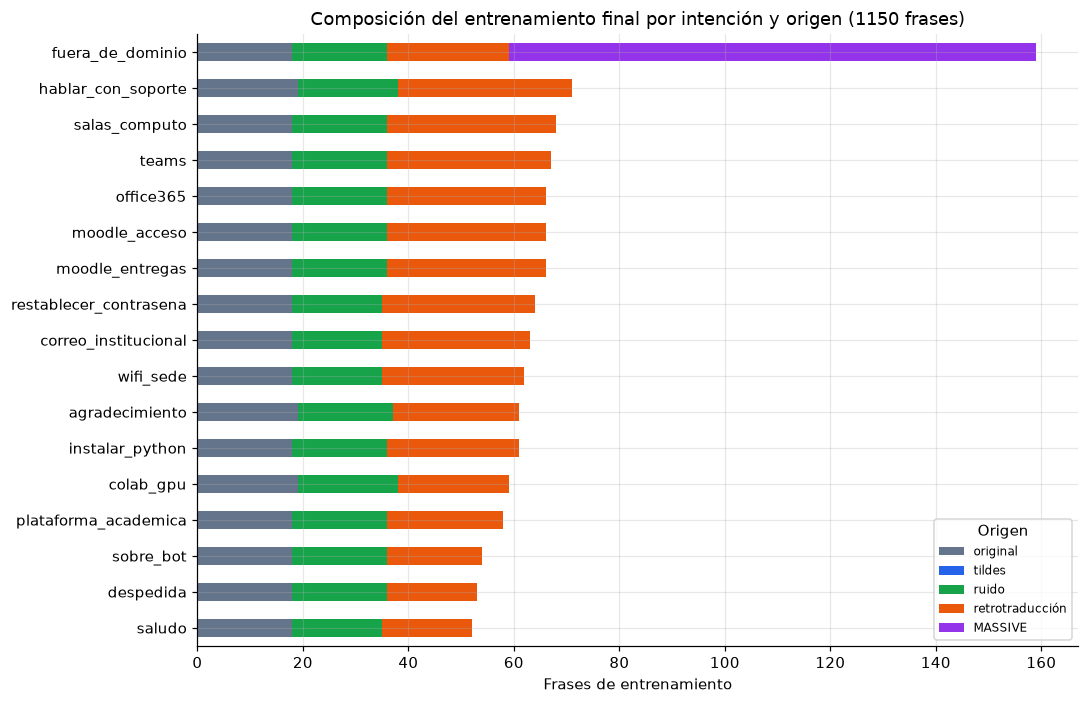

In [23]:
# ---------- Modelo final: pesos de la corrida ganadora de la búsqueda ----------
model = ganador["modelo"]
historial = ganador["hist"]
mejor_epoca = ganador["mejor"]["epoca"]
mejor_val_f1 = ganador["mejor"]["val_f1"]
val_loss_mejor_epoca = ganador["mejor"]["val_loss"]
mejor_val_loss = min(historial["val_loss"])
tiempo_entrenamiento = ganador["tiempo"]

n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros del modelo: {n_params/1e6:.1f} M | frases de entrenamiento: {ganador['mejor']['n_train']}")
print("Historial de BETO (configuración elegida) por época:")
print(pd.DataFrame({k: v for k, v in historial.items()},
                   index=pd.RangeIndex(1, len(historial["val_loss"]) + 1, name="época")).round(4).to_string())
print(f"\nMejor época (F1 macro de validación): {mejor_epoca} | val F1 macro: {mejor_val_f1:.4f} | "
      f"val_loss en esa época: {val_loss_mejor_epoca:.4f} | épocas ejecutadas: {len(historial['val_loss'])} | "
      f"tiempo: {tiempo_entrenamiento:.1f} s")

# Si la búsqueda descartó MASSIVE, las líneas base se vuelven a entrenar sin él (mismos datos reales que BETO)
if HP["massive"] != USAR_MASSIVE:
    USAR_MASSIVE = HP["massive"]
    t_tfidf0 = time.time()
    tfidf, clf_tfidf = entrenar_tfidf(base_entrenamiento(train_df, USAR_MASSIVE))
    tiempo_tfidf = time.time() - t_tfidf0
    pred_tfidf_test = clf_tfidf.predict(tfidf.transform(test_df["texto"]))
    pred_tfidf_gen = [id2label[p] for p in clf_tfidf.predict(tfidf.transform(gen_df["texto"]))]
    lstm, vocab, hist_lstm, mejor_ep_lstm, tiempo_lstm = entrenar_bilstm(base_entrenamiento(train_df, USAR_MASSIVE), val_df)
    pred_lstm_test = predecir_lstm(test_df["texto"], lstm, vocab)
    pred_lstm_gen = [id2label[p] for p in predecir_lstm(gen_df["texto"], lstm, vocab)]
    print("MASSIVE descartado en validación: TF-IDF y BiLSTM se reentrenaron sin MASSIVE.")

# ---------- Composición del entrenamiento final ----------
composicion = pd.DataFrame({"original": train_df["intencion"].value_counts()})
for tecnica, nombre in [("tildes", "tildes"), ("ruido", "ruido"), ("retrotraduccion", "retrotraducción")]:
    usadas = aumento_train[aumento_train["tecnica"] == tecnica] if tecnica in HP["tecnicas_aumento"] else aumento_train.iloc[0:0]
    composicion[nombre] = usadas["intencion"].value_counts()
composicion["MASSIVE"] = 0
if HP["massive"]:
    composicion.loc["fuera_de_dominio", "MASSIVE"] = len(massive_train_prep)
composicion = composicion.fillna(0).astype(int)
composicion = composicion.loc[composicion.sum(axis=1).sort_values().index]
print(f"Composición del entrenamiento final: {composicion.values.sum()} frases")
print(composicion.assign(total=composicion.sum(axis=1)).to_string())
ax = composicion.plot(kind="barh", stacked=True, figsize=(10, 6.5),
                      color=["#64748b", "#2563eb", "#16a34a", "#ea580c", "#9333ea", "#0891b2"])
ax.set_xlabel("Frases de entrenamiento"); ax.set_ylabel("")
ax.set_title(f"Composición del entrenamiento final por intención y origen ({composicion.values.sum()} frases)")
ax.legend(title="Origen", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig12_composicion_train.png"), bbox_inches="tight"); plt.show()

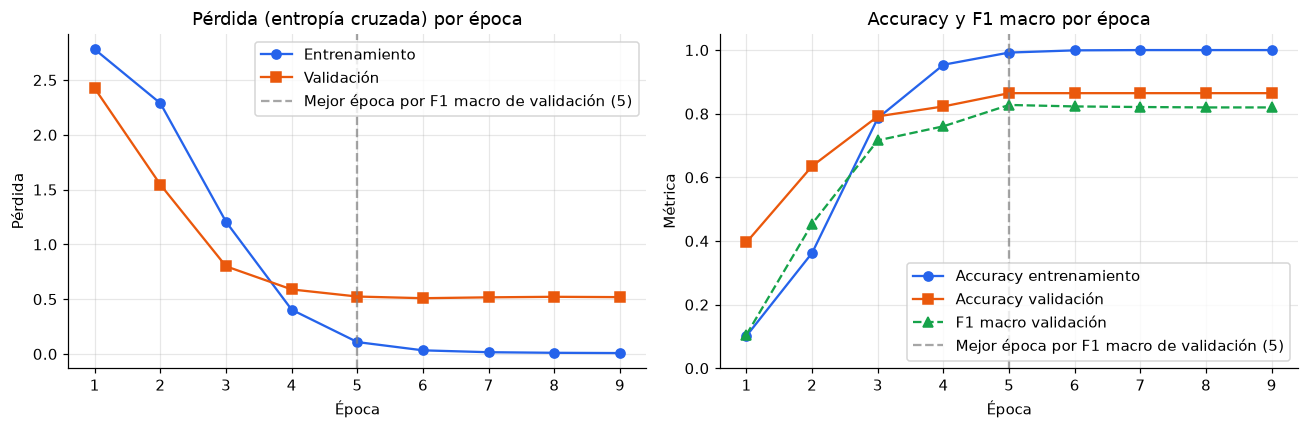

In [24]:
# ---------- Curvas de pérdida y accuracy por época ----------
epocas = range(1, len(historial["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epocas, historial["train_loss"], "o-", color=COLOR_1, label="Entrenamiento")
axes[0].plot(epocas, historial["val_loss"], "s-", color=COLOR_2, label="Validación")
axes[0].set_title("Pérdida (entropía cruzada) por época"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")
axes[1].plot(epocas, historial["train_acc"], "o-", color=COLOR_1, label="Accuracy entrenamiento")
axes[1].plot(epocas, historial["val_acc"], "s-", color=COLOR_2, label="Accuracy validación")
axes[1].plot(epocas, historial["val_f1"], "^--", color="#16a34a", label="F1 macro validación")
axes[1].set_title("Accuracy y F1 macro por época"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("Métrica")
axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.axvline(mejor_epoca, color="gray", linestyle="--", alpha=0.7, label=f"Mejor época por F1 macro de validación ({mejor_epoca})")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_curvas_entrenamiento.png"), bbox_inches="tight")
plt.show()

## 6. Evaluación

Se evalúa el modelo con los pesos de la mejor época sobre el conjunto de **prueba** (15 %), que no se usó ni para entrenar ni para elegir la época. Se reportan accuracy, precision, recall y F1 (macro, ponderado y por clase), la matriz de confusión, el análisis de errores y una prueba con frases nuevas que no están en el dataset.

In [25]:
test_loss, test_acc, test_preds, test_reales, test_probs = evaluar(model, test_loader)
val_loss_f, val_acc_f, *_ = evaluar(model, val_loader)

p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(test_reales, test_preds, average="macro", zero_division=0)
p_w,   r_w,   f1_w,   _ = precision_recall_fscore_support(test_reales, test_preds, average="weighted", zero_division=0)

metricas_globales = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)",
                "Precision (ponderada)", "Recall (ponderado)", "F1 (ponderado)"],
    "Prueba": [test_acc, p_mac, r_mac, f1_mac, p_w, r_w, f1_w],
}).round(4)
print(f"Accuracy validación: {val_acc_f:.4f} | Accuracy prueba: {test_acc:.4f} | Pérdida prueba: {test_loss:.4f}\n")
metricas_globales

Accuracy validación: 0.8646 | Accuracy prueba: 0.7612 | Pérdida prueba: 0.9099



,Métrica,Prueba
0,Accuracy,0.7612
1,Precision (macro),0.7676
2,Recall (macro),0.7549
3,F1 (macro),0.7316
4,Precision (ponderada),0.7642
5,Recall (ponderado),0.7612
6,F1 (ponderado),0.7351


In [26]:
# ---------- Métricas por clase ----------
reporte = classification_report(test_reales, test_preds, labels=list(range(NUM_LABELS)),
                                 target_names=ETIQUETAS, output_dict=True, zero_division=0)
metricas_clase = pd.DataFrame(reporte).T.loc[ETIQUETAS, ["precision", "recall", "f1-score", "support"]]
metricas_clase["support"] = metricas_clase["support"].astype(int)
metricas_clase = metricas_clase.round(3).sort_values("f1-score")
metricas_clase.to_csv(os.path.join(DATA_DIR, "metricas_por_clase.csv"))
metricas_clase

,precision,recall,f1-score,support
restablecer_contrasena,0.000,0.000,0.000,4
agradecimiento,1.000,0.333,0.500,3
hablar_con_soporte,0.667,0.500,0.571,4
fuera_de_dominio,0.600,0.750,0.667,4
office365,1.000,0.500,0.667,4
plataforma_academica,0.500,1.000,0.667,4
moodle_acceso,0.600,0.750,0.667,4
moodle_entregas,0.750,0.750,0.750,4
instalar_python,0.667,1.000,0.800,4
despedida,0.667,1.000,0.800,4


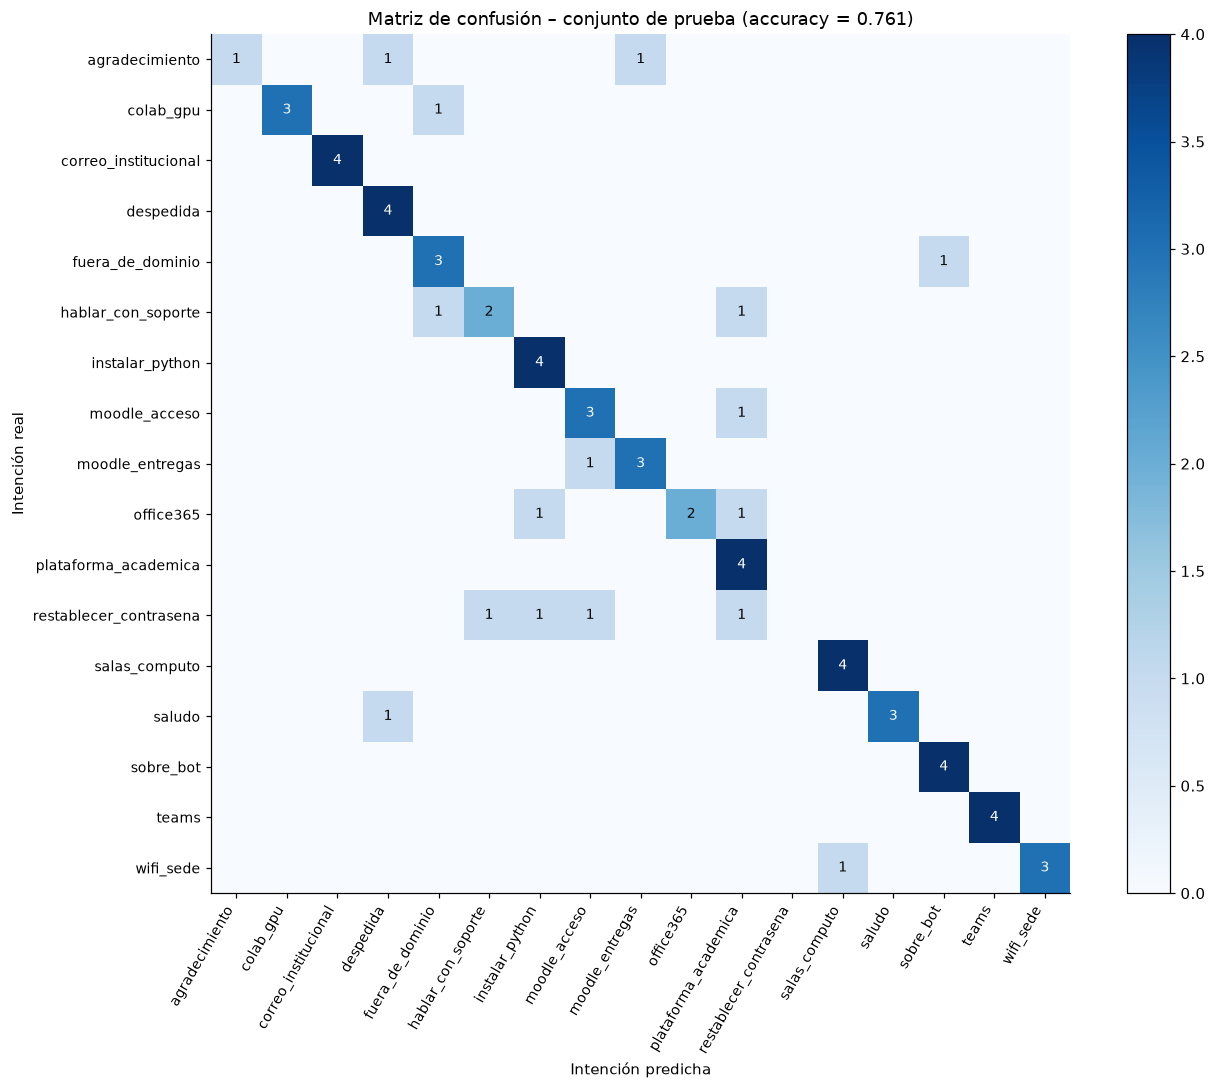

In [27]:
# ---------- Matriz de confusión (heatmap) ----------
cm = confusion_matrix(test_reales, test_preds, labels=list(range(NUM_LABELS)))
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_LABELS)); ax.set_yticks(range(NUM_LABELS))
ax.set_xticklabels(ETIQUETAS, rotation=60, ha="right", fontsize=9)
ax.set_yticklabels(ETIQUETAS, fontsize=9)
ax.grid(False)
umbral_color = cm.max() / 2
for i in range(NUM_LABELS):
    for j in range(NUM_LABELS):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > umbral_color else "black", fontsize=9)
ax.set_xlabel("Intención predicha"); ax.set_ylabel("Intención real")
ax.set_title(f"Matriz de confusión – conjunto de prueba (accuracy = {test_acc:.3f})")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_matriz_confusion.png"), bbox_inches="tight")
plt.show()

Prueba externa: 0 frases con similitud MiniLM ≥ 0.9 (dataset, generalización o el propio externo)


Externo con el BETO congelado; predicciones iguales a las del BETO de esta ejecución: 90/90


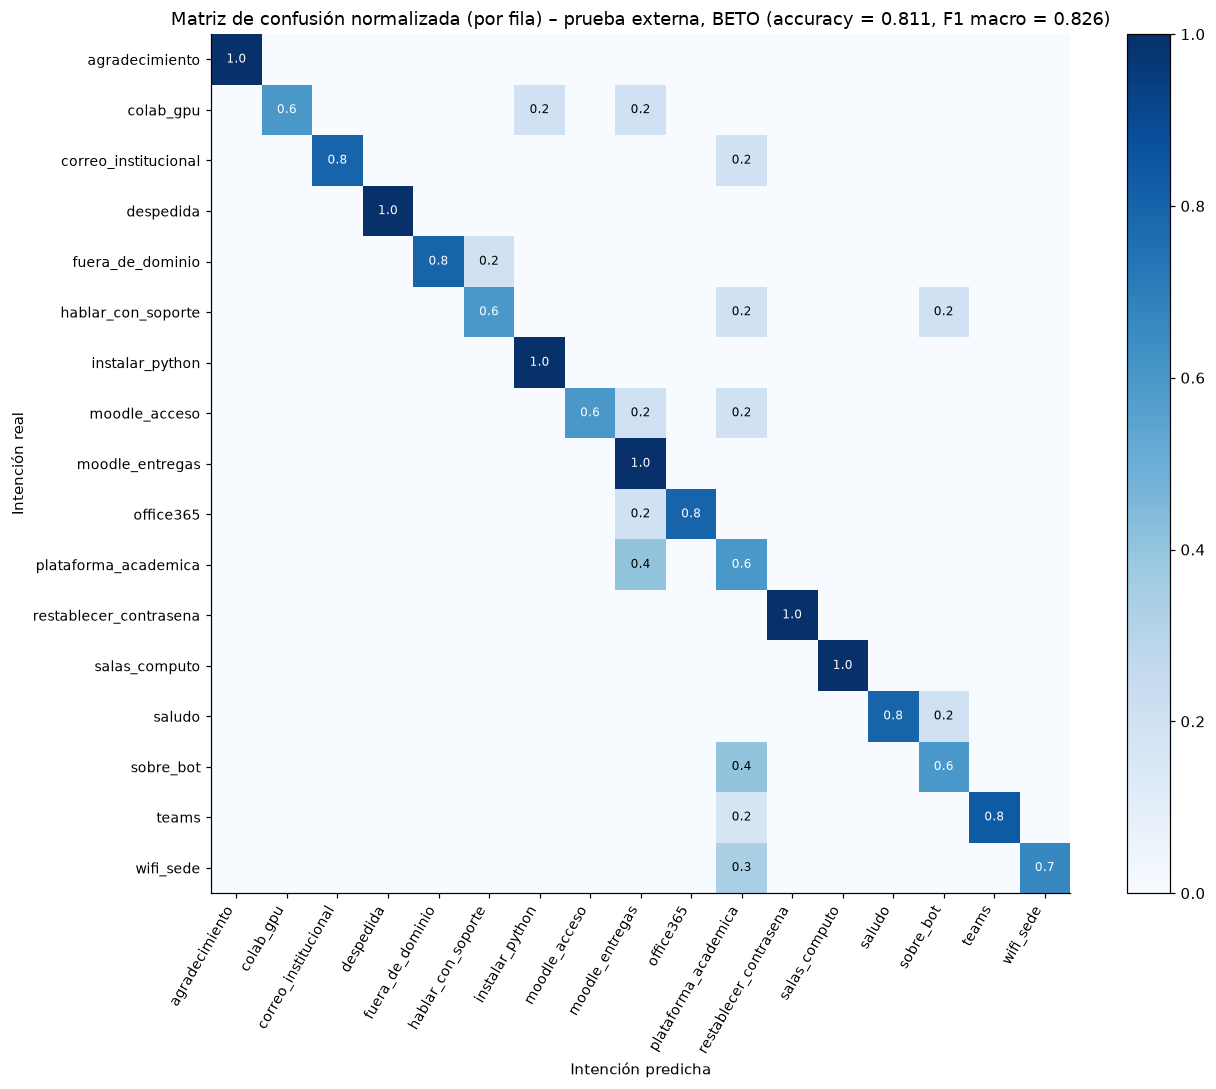

Prueba externa (90 frases de una intención) · BETO: accuracy 0.8111 | F1 macro 0.8256


In [28]:
# ---------- Prueba externa (líneas de una intención): control de fuga y matriz de confusión ----------
# Regla fijada antes de ver resultados: la cifra de la prueba externa solo se calcula y se reporta si ninguna de sus
# frases tiene similitud MiniLM >= 0,90 con el dataset, la generalización u otra frase del propio conjunto externo.
textos_ext_todas = [f for f, _ in FRASES_EXTERNAS_TODAS]
emb_ext = embeber(textos_ext_todas)
emb_dg = embeber(df["texto"].tolist() + gen_df["texto"].tolist())
sim_dg = util.cos_sim(emb_ext, emb_dg).max(dim=1).values.cpu().numpy()
sim_ee = util.cos_sim(emb_ext, emb_ext).cpu().numpy(); np.fill_diagonal(sim_ee, 0)
fuga_ext = [(textos_ext_todas[i], round(float(max(sim_dg[i], sim_ee[i].max())), 3)) for i in range(len(textos_ext_todas))
            if max(sim_dg[i], sim_ee[i].max()) >= SIM_FUGA_MAX]
EXTERNO_LIMPIO = len(fuga_ext) == 0
print(f"Prueba externa: {len(fuga_ext)} frases con similitud MiniLM ≥ {SIM_FUGA_MAX} (dataset, generalización o el propio externo)")
for t, s_ in fuga_ext:
    print(f"  {s_:.3f}  {t}")

if FRASES_EXTERNAS and EXTERNO_LIMPIO:
    textos_ext = [f for f, _ in FRASES_EXTERNAS]
    reales_ext = [label2id[i] for _, i in FRASES_EXTERNAS]
    # La cifra externa de la v1 se calcula con el BETO congelado (soportic/v1_congelada/), si existe;
    # se comprueba además si el BETO de esta ejecución da las mismas predicciones.
    RUTA_BETO_V1_CONGELADO = os.path.join(BASE_DIR, "v1_congelada", "modelo_bert_intenciones")
    cargador_ext = lambda: DataLoader(a_dataset([normalizar_texto(t) for t in textos_ext], reales_ext), batch_size=64)
    if os.path.isdir(RUTA_BETO_V1_CONGELADO):
        beto_v1_congelado = AutoModelForSequenceClassification.from_pretrained(RUTA_BETO_V1_CONGELADO).to(DEVICE).eval()
        _, acc_ext, preds_ext, _, _ = evaluar(beto_v1_congelado, cargador_ext())
        del beto_v1_congelado; liberar_gpu()
        _, _, preds_ext_reejec, _, _ = evaluar(model, cargador_ext())
        print(f"Externo con el BETO congelado; predicciones iguales a las del BETO de esta ejecución: "
              f"{sum(a == b for a, b in zip(preds_ext, preds_ext_reejec))}/{len(preds_ext)}")
    else:
        _, acc_ext, preds_ext, _, _ = evaluar(model, cargador_ext())
    f1_ext = f1_score(reales_ext, preds_ext, average="macro", zero_division=0)
    cm_ext = confusion_matrix(reales_ext, preds_ext, labels=list(range(NUM_LABELS)), normalize="true")
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm_ext, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_LABELS)); ax.set_yticks(range(NUM_LABELS))
    ax.set_xticklabels(ETIQUETAS, rotation=60, ha="right", fontsize=9); ax.set_yticklabels(ETIQUETAS, fontsize=9)
    ax.grid(False)
    for i in range(NUM_LABELS):
        for j in range(NUM_LABELS):
            if cm_ext[i, j] > 0:
                ax.text(j, i, f"{cm_ext[i, j]:.1f}", ha="center", va="center",
                        color="white" if cm_ext[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xlabel("Intención predicha"); ax.set_ylabel("Intención real")
    ax.set_title(f"Matriz de confusión normalizada (por fila) – prueba externa, BETO (accuracy = {acc_ext:.3f}, F1 macro = {f1_ext:.3f})")
    plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig13_matriz_confusion_externa.png"), bbox_inches="tight"); plt.show()
    print(f"Prueba externa ({len(textos_ext)} frases de una intención) · BETO: accuracy {acc_ext:.4f} | F1 macro {f1_ext:.4f}")
else:
    acc_ext = f1_ext = None
    print("La cifra de la prueba externa no se calcula: hay frases con fuga que los autores deben reescribir.")

In [29]:
# ---------- Análisis de errores ----------
test_df["predicha"]  = [id2label[p] for p in test_preds]
test_df["confianza"] = test_probs.max(axis=1).round(3)
errores = test_df[test_df["predicha"] != test_df["intencion"]][["texto", "intencion", "predicha", "confianza"]]

if len(errores):
    print(f"Ejemplos mal clasificados: {len(errores)} de {len(test_df)}")
    display(errores)
    print("\n5 confusiones más frecuentes de BETO en prueba (conteo: real → predicha):")
    for (real, pred), n in Counter(zip(errores["intencion"], errores["predicha"])).most_common(5):
        print(f"  {n} × {real} → {pred}")
else:
    print("✅ No hubo errores en el conjunto de prueba.")

# Aun sin errores, los aciertos con menor confianza muestran dónde el modelo duda
print("\nPredicciones con menor confianza en prueba (zonas de duda del modelo):")
display(test_df.nsmallest(8, "confianza")[["texto", "intencion", "predicha", "confianza"]])

Ejemplos mal clasificados: 16 de 67


,texto,intencion,predicha,confianza
0,que celular me recomiendas comprar,fuera_de_dominio,sobre_bot,0.925
6,la app authenticator se borro del celular y no...,restablecer_contrasena,instalar_python,0.834
13,donde queda la oficina de sistemas,hablar_con_soporte,fuera_de_dominio,0.956
14,el ticket que abri lo cerraron sin solucionar,hablar_con_soporte,plataforma_academica,0.563
20,entro y no me aparece ninguno de mis cursos,moodle_acceso,plataforma_academica,0.779
26,"se me vencio el plazo por 2 minutos, moodle ya...",moodle_entregas,moodle_acceso,0.960
34,la gpu t4 que tan buena es para entrenar,colab_gpu,fuera_de_dominio,0.456
37,mi cuenta esta bloqueada por intentar muchas v...,restablecer_contrasena,plataforma_academica,0.287
39,listo funciono a la primera,agradecimiento,moodle_entregas,0.341
45,"no se cual es mi contraseña inicial, soy nuevo",restablecer_contrasena,hablar_con_soporte,0.407



5 confusiones más frecuentes de BETO en prueba (conteo: real → predicha):
  1 × fuera_de_dominio → sobre_bot
  1 × restablecer_contrasena → instalar_python
  1 × hablar_con_soporte → fuera_de_dominio
  1 × hablar_con_soporte → plataforma_academica
  1 × moodle_acceso → plataforma_academica

Predicciones con menor confianza en prueba (zonas de duda del modelo):


,texto,intencion,predicha,confianza
37,mi cuenta esta bloqueada por intentar muchas v...,restablecer_contrasena,plataforma_academica,0.287
39,listo funciono a la primera,agradecimiento,moodle_entregas,0.341
60,en el celular si navego pero el portatil no ag...,wifi_sede,wifi_sede,0.362
45,"no se cual es mi contraseña inicial, soy nuevo",restablecer_contrasena,hablar_con_soporte,0.407
1,en el celular la app de outlook me sale error ...,correo_institucional,correo_institucional,0.450
51,eres un crack,agradecimiento,despedida,0.454
34,la gpu t4 que tan buena es para entrenar,colab_gpu,fuera_de_dominio,0.456
14,el ticket que abri lo cerraron sin solucionar,hablar_con_soporte,plataforma_academica,0.563


### 6.1 ¿Dónde mira BERT? Mapa de autoatención
En cada capa, cada token calcula pesos de atención sobre todos los demás: softmax(QKᵀ/√d). Se grafica el promedio de las 12 cabezas de la última capa y, aparte, la atención que el token `[CLS]` (el vector que usa el clasificador) presta a cada palabra. Es el equivalente del mapa de atención de la Parte 1, pero con autoatención en vez de atención encoder-decoder.

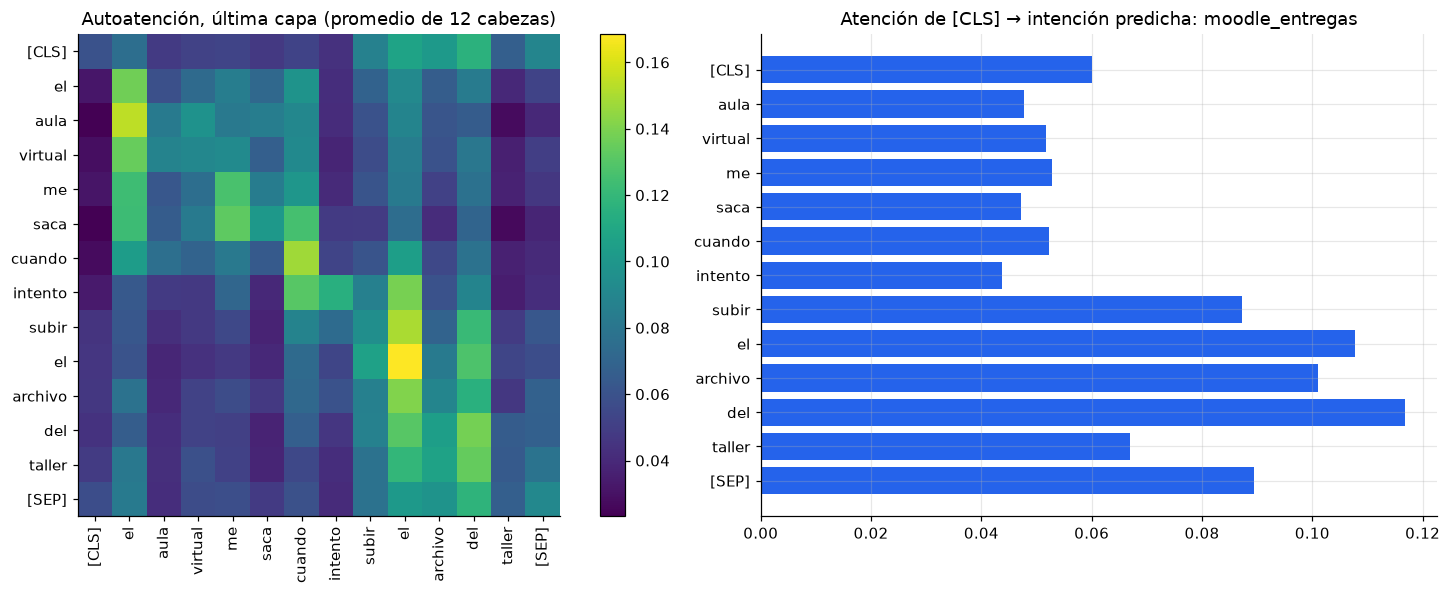

In [30]:
def mapa_atencion(texto, capa=-1):
    model.eval()
    enc = tokenizer(normalizar_texto(texto), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        salida = model(**enc, output_attentions=True)
    att = salida.attentions[capa][0].float().mean(0).cpu().numpy()      # (tokens, tokens)
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    intent = id2label[int(salida.logits.argmax(-1))]
    return att, tokens, intent

frase_att = "el aula virtual me saca cuando intento subir el archivo del taller"
att, tokens, intent = mapa_atencion(frase_att)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
im = ax[0].imshow(att, cmap="viridis"); ax[0].grid(False)
ax[0].set_xticks(range(len(tokens))); ax[0].set_xticklabels(tokens, rotation=90)
ax[0].set_yticks(range(len(tokens))); ax[0].set_yticklabels(tokens)
ax[0].set_title("Autoatención, última capa (promedio de 12 cabezas)"); plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].barh(tokens[::-1], att[0][::-1], color=COLOR_1)
ax[1].set_title(f"Atención de [CLS] → intención predicha: {intent}")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig8_mapa_atencion.png"), bbox_inches="tight"); plt.show()

Some weights of BertModel were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Frases: 135 (prueba 67 + generalización 68) | coeficiente de silueta por intención (coseno, 768 dimensiones): preentrenado -0.054 | ajustado 0.453


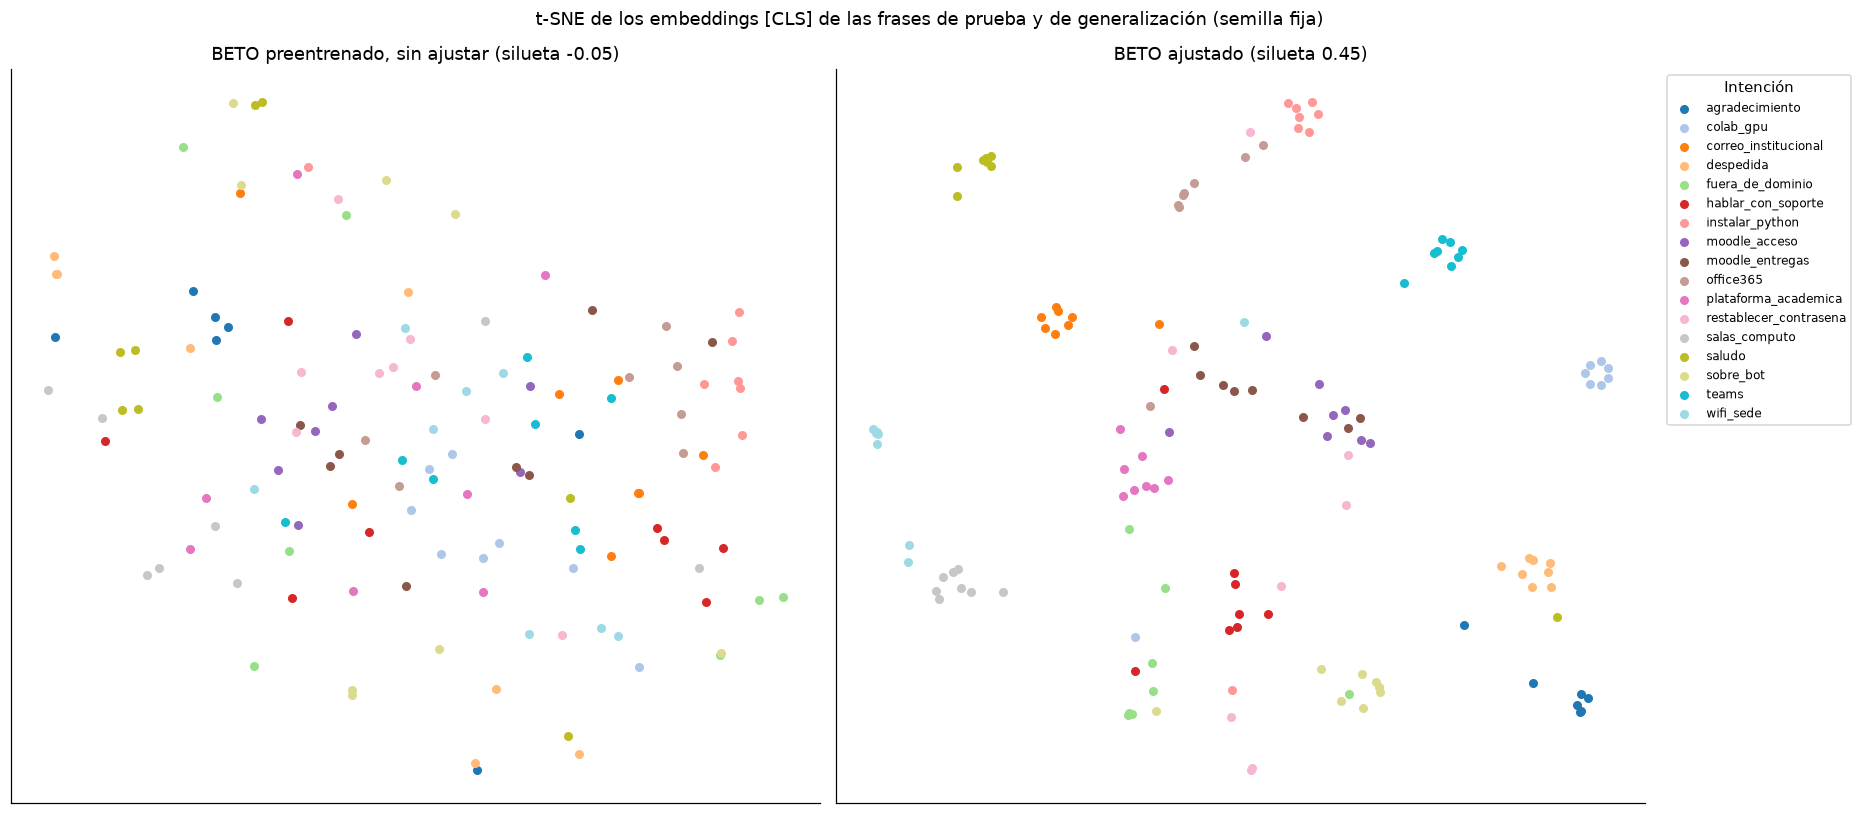

In [31]:
# ---------- Embeddings [CLS] con t-SNE: BETO preentrenado vs. BETO ajustado ----------
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from transformers import AutoModel

# Frases de prueba y de generalización (la prueba externa queda fuera mientras tenga frases con fuga)
textos_tsne = test_df["texto"].tolist() + gen_df["texto"].tolist()
intenciones_tsne = np.array(test_df["intencion"].tolist() + gen_df["intencion"].tolist())

def embeddings_cls(codificador, textos):
    codificador.eval(); salida = []
    with torch.no_grad():
        for i in range(0, len(textos), 64):
            enc = tokenizer([normalizar_texto(t) for t in textos[i:i + 64]], padding=True, truncation=True,
                            max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
            salida.append(codificador(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).last_hidden_state[:, 0].float().cpu())
    return torch.cat(salida).numpy()

beto_preentrenado = AutoModel.from_pretrained(MODELO_BASE).to(DEVICE)
emb_preentrenado = embeddings_cls(beto_preentrenado, textos_tsne)
del beto_preentrenado; liberar_gpu()
emb_ajustado = embeddings_cls(model.bert, textos_tsne)

silueta = {nombre: silhouette_score(e, intenciones_tsne, metric="cosine")
           for nombre, e in [("preentrenado", emb_preentrenado), ("ajustado", emb_ajustado)]}
print(f"Frases: {len(textos_tsne)} (prueba {len(test_df)} + generalización {len(gen_df)}) | "
      f"coeficiente de silueta por intención (coseno, 768 dimensiones): preentrenado {silueta['preentrenado']:.3f} | "
      f"ajustado {silueta['ajustado']:.3f}")

colores_int = plt.cm.tab20(np.linspace(0, 1, NUM_LABELS))
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, emb, titulo in [(axes[0], emb_preentrenado, f"BETO preentrenado, sin ajustar (silueta {silueta['preentrenado']:.2f})"),
                        (axes[1], emb_ajustado, f"BETO ajustado (silueta {silueta['ajustado']:.2f})")]:
    xy = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(emb)
    for k, intent in enumerate(ETIQUETAS):
        m = intenciones_tsne == intent
        ax.scatter(xy[m, 0], xy[m, 1], s=24, color=colores_int[k], label=intent)
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Intención")
plt.suptitle("t-SNE de los embeddings [CLS] de las frases de prueba y de generalización (semilla fija)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig14_tsne_cls.png"), bbox_inches="tight"); plt.show()

In [32]:
# ---------- Respaldo semántico con sentence-transformers ----------
# encoder_sem (MiniLM) ya se cargó en la sección 4.1

# Base de conocimiento: ejemplos de entrenamiento + validación (la prueba queda fuera para evaluar sin fuga)
kb_df = pd.concat([base_entrenamiento(train_df, USAR_MASSIVE), val_df], ignore_index=True)   # sin texto generado
kb_textos, kb_intenciones = kb_df["texto_norm"].tolist(), kb_df["intencion"].tolist()
kb_embeddings = encoder_sem.encode(kb_textos, convert_to_tensor=True, normalize_embeddings=True)

def buscar_similar(texto: str):
    """Devuelve (intención, similitud coseno, pregunta más parecida) según la base de conocimiento."""
    emb = encoder_sem.encode(normalizar_texto(texto), convert_to_tensor=True, normalize_embeddings=True)
    sims = util.cos_sim(emb, kb_embeddings)[0]
    idx = int(sims.argmax())
    return kb_intenciones[idx], float(sims[idx]), kb_textos[idx]

def predecir_intencion(texto: str, top_k: int = 3):
    """Clasifica con BERT y devuelve las top_k intenciones con su probabilidad."""
    model.eval()
    enc = tokenizer(normalizar_texto(texto), return_tensors="pt", truncation=True, max_length=MAX_LEN).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits.float(), dim=-1)[0].cpu()
    valores, indices = probs.topk(top_k)
    return [(id2label[int(i)], float(v)) for v, i in zip(valores, indices)]

print(predecir_intencion("no me abre el moodle en el cel"))
print(buscar_similar("no me abre el moodle en el cel"))

[('moodle_acceso', 0.9740428328514099), ('moodle_entregas', 0.006817800924181938), ('salas_computo', 0.002095480915158987)]
('moodle_acceso', 0.7525844573974609, 'desde la casa no me abre moodle pero en la u si')


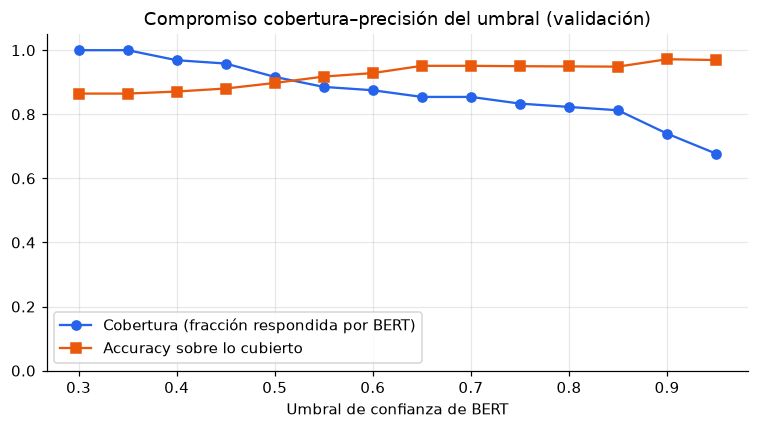

Umbrales del híbrido elegidos en validación: BETO = 0.45 | semántico = 0.6 → accuracy de validación 0.8750 (solo BETO: 0.8646) | respaldo semántico 4.2% | por defecto 0.0%


In [33]:
# ---------- Elección de umbrales: cobertura vs. accuracy en VALIDACIÓN ----------
_, _, val_preds, val_reales, val_probs = evaluar(model, val_loader)
val_conf = val_probs.max(axis=1)
umbrales = np.round(np.arange(0.30, 0.96, 0.05), 2)
cobertura = [(val_conf >= u).mean() for u in umbrales]
acc_cubierta = [accuracy_score(np.array(val_reales)[val_conf >= u], np.array(val_preds)[val_conf >= u])
                if (val_conf >= u).any() else np.nan for u in umbrales]

plt.figure(figsize=(7, 4))
plt.plot(umbrales, cobertura, "o-", color=COLOR_1, label="Cobertura (fracción respondida por BERT)")
plt.plot(umbrales, acc_cubierta, "s-", color=COLOR_2, label="Accuracy sobre lo cubierto")
plt.xlabel("Umbral de confianza de BERT"); plt.ylim(0, 1.05); plt.legend()
plt.title("Compromiso cobertura–precisión del umbral (validación)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig6_umbral_confianza.png"), bbox_inches="tight"); plt.show()

# ---------- Umbrales del híbrido elegidos en VALIDACIÓN ----------
# Para no favorecer al respaldo semántico, en esta selección su base contiene solo el entrenamiento (sin la validación);
# el chatbot final usa entrenamiento + validación como base. Criterio: mayor accuracy del híbrido en validación
# (la respuesta por defecto cuenta como error, igual que en la tabla comparativa); en empate, menor umbral de BETO
# (más decisiones de BETO) y mayor umbral semántico (respaldo más conservador).
kb_sel = base_entrenamiento(train_df, USAR_MASSIVE)
emb_kb_sel = encoder_sem.encode(kb_sel["texto_norm"].tolist(), convert_to_tensor=True, normalize_embeddings=True)
emb_val_sel = encoder_sem.encode(val_df["texto_norm"].tolist(), convert_to_tensor=True, normalize_embeddings=True)
sims_val = util.cos_sim(emb_val_sel, emb_kb_sel)
sim_val_max, idx_val = sims_val.max(dim=1)
sem_val_pred = kb_sel["label"].values[idx_val.cpu().numpy()]
sim_val_max = sim_val_max.cpu().numpy()
reales_val = np.array(val_reales); preds_val_bert = np.array(val_preds)
rejilla_hib = []
for ub in np.round(np.arange(0.30, 0.951, 0.05), 2):
    for us in np.round(np.arange(0.30, 0.951, 0.05), 2):
        pred = np.where(val_conf >= ub, preds_val_bert, np.where(sim_val_max >= us, sem_val_pred, -1))
        rejilla_hib.append({"umbral_bert": ub, "umbral_semantico": us, "accuracy_val": (pred == reales_val).mean(),
                            "fraccion_semantico": float(((val_conf < ub) & (sim_val_max >= us)).mean()),
                            "fraccion_por_defecto": float(((val_conf < ub) & (sim_val_max < us)).mean())})
rejilla_hib = pd.DataFrame(rejilla_hib)
elegido_hib = rejilla_hib.sort_values(["accuracy_val", "umbral_bert", "umbral_semantico"],
                                      ascending=[False, True, False]).iloc[0]
UMBRAL_BERT, UMBRAL_SEMANTICO = float(elegido_hib["umbral_bert"]), float(elegido_hib["umbral_semantico"])
acc_val_solo_bert = float((preds_val_bert == reales_val).mean())
print(f"Umbrales del híbrido elegidos en validación: BETO = {UMBRAL_BERT} | semántico = {UMBRAL_SEMANTICO} → "
      f"accuracy de validación {elegido_hib['accuracy_val']:.4f} (solo BETO: {acc_val_solo_bert:.4f}) | "
      f"respaldo semántico {elegido_hib['fraccion_semantico']:.1%} | por defecto {elegido_hib['fraccion_por_defecto']:.1%}")
rejilla_hib.to_csv(os.path.join(DATA_DIR, "umbrales_hibrido_validacion.csv"), index=False)

Fuente de la decisión del híbrido en generalización: {'BERT': 66, 'semántico': 2}


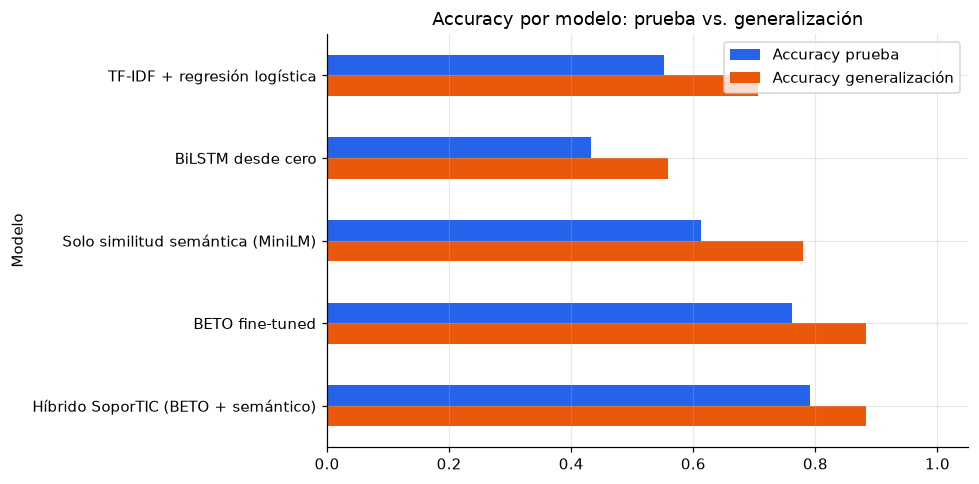

,Accuracy prueba,F1 macro prueba,Accuracy generalización,F1 macro generalización,Accuracy externa,F1 macro externa
Modelo,,,,,,
TF-IDF + regresión logística,0.5522,0.5642,0.7059,0.7277,0.7333,0.7591
BiLSTM desde cero,0.4328,0.4311,0.5588,0.5950,0.5889,0.5943
Solo similitud semántica (MiniLM),0.6119,0.6015,0.7794,0.7754,0.8000,0.7943
BETO fine-tuned,0.7612,0.7316,0.8824,0.8827,0.8111,0.8256
Híbrido SoporTIC (BETO + semántico),0.7910,0.7811,0.8824,0.8850,0.8111,0.7774


In [34]:
def decidir_intencion(texto: str):
    """Estrategia híbrida: BERT → respaldo semántico → None (respuesta por defecto)."""
    intent, conf = predecir_intencion(texto, top_k=1)[0]
    if conf >= UMBRAL_BERT:
        return intent, conf, "BERT"
    intent_sem, sim, _ = buscar_similar(texto)
    if sim >= UMBRAL_SEMANTICO:
        return intent_sem, sim, "semántico"
    return None, max(conf, sim), "por defecto"

# ---------- Comparación de todos los modelos: prueba y generalización ----------
def predecir_bert(textos):
    return [predecir_intencion(t, top_k=1)[0][0] for t in textos]

def fila(nombre, pred_test, pred_gen):
    return {"Modelo": nombre,
            "Accuracy prueba": accuracy_score(test_df["intencion"], pred_test),
            "F1 macro prueba": f1_score(test_df["intencion"], pred_test, average="macro", zero_division=0),
            "Accuracy generalización": accuracy_score(gen_df["intencion"], pred_gen),
            "F1 macro generalización": f1_score(gen_df["intencion"], pred_gen, average="macro", zero_division=0)}

sin_resp = lambda preds: [p[0] if p[0] else "SIN_RESPUESTA" for p in preds]
pred_hib_test, pred_hib_gen = [decidir_intencion(t) for t in test_df["texto"]], [decidir_intencion(t) for t in gen_df["texto"]]
pred_bert_gen = predecir_bert(gen_df["texto"])

comparacion = pd.DataFrame([
    fila("TF-IDF + regresión logística", [id2label[p] for p in pred_tfidf_test], pred_tfidf_gen),
    fila("BiLSTM desde cero", [id2label[p] for p in pred_lstm_test], pred_lstm_gen),
    fila("Solo similitud semántica (MiniLM)", [buscar_similar(t)[0] for t in test_df["texto"]],
         [buscar_similar(t)[0] for t in gen_df["texto"]]),
    fila("BETO fine-tuned", [id2label[p] for p in test_preds], pred_bert_gen),
    fila("Híbrido SoporTIC (BETO + semántico)", sin_resp(pred_hib_test), sin_resp(pred_hib_gen)),
]).set_index("Modelo").round(4)

# Prueba externa (una intención): solo si pasó el control de fuga
if FRASES_EXTERNAS and EXTERNO_LIMPIO:
    t_ext = [f for f, _ in FRASES_EXTERNAS]; y_ext = [i for _, i in FRASES_EXTERNAS]
    preds_ext_modelos = {
        "TF-IDF + regresión logística": [id2label[p] for p in clf_tfidf.predict(tfidf.transform(t_ext))],
        "BiLSTM desde cero": [id2label[p] for p in predecir_lstm(t_ext, lstm, vocab)],
        "Solo similitud semántica (MiniLM)": [buscar_similar(t)[0] for t in t_ext],
        "BETO fine-tuned": [id2label[p] for p in preds_ext],
        "Híbrido SoporTIC (BETO + semántico)": sin_resp([decidir_intencion(t) for t in t_ext]),
    }
    comparacion["Accuracy externa"] = [round(accuracy_score(y_ext, preds_ext_modelos[m]), 4) for m in comparacion.index]
    comparacion["F1 macro externa"] = [round(f1_score(y_ext, preds_ext_modelos[m], average="macro", zero_division=0), 4)
                                       for m in comparacion.index]
comparacion.to_csv(os.path.join(DATA_DIR, "comparacion_modelos.csv"))
acc_semantico = comparacion.loc["Solo similitud semántica (MiniLM)", "Accuracy prueba"]
acc_hibrido   = comparacion.loc["Híbrido SoporTIC (BETO + semántico)", "Accuracy prueba"]
print("Fuente de la decisión del híbrido en generalización:", dict(Counter(p[2] for p in pred_hib_gen)))

ax = comparacion[["Accuracy prueba", "Accuracy generalización"]].plot(kind="barh", figsize=(9, 4.5), color=[COLOR_1, COLOR_2])
ax.set_xlim(0, 1.05); ax.set_title("Accuracy por modelo: prueba vs. generalización"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig7_comparacion_modelos.png"), bbox_inches="tight"); plt.show()
comparacion

In [35]:
# ---------- Errores del chatbot híbrido en el conjunto de generalización ----------
gen_df["BERT"] = pred_bert_gen
gen_df["híbrido"] = sin_resp(pred_hib_gen)
gen_df["fuente"] = [p[2] for p in pred_hib_gen]
gen_df["confianza"] = [round(p[1], 3) for p in pred_hib_gen]
acc_frases_nuevas = (gen_df["híbrido"] == gen_df["intencion"]).mean()
print(f"Accuracy del chatbot híbrido en frases nuevas: {acc_frases_nuevas:.3f} "
      f"({int((gen_df['híbrido'] == gen_df['intencion']).sum())}/{len(gen_df)})")
errores_gen = gen_df[gen_df["híbrido"] != gen_df["intencion"]]
display(errores_gen[["texto", "intencion", "BERT", "híbrido", "fuente", "confianza"]])

Accuracy del chatbot híbrido en frases nuevas: 0.882 (60/68)


,texto,intencion,BERT,híbrido,fuente,confianza
15,puedes recordar lo que te pregunte ayer,sobre_bot,fuera_de_dominio,fuera_de_dominio,BERT,0.977
17,como hago para que me suban la nota del final,fuera_de_dominio,plataforma_academica,plataforma_academica,BERT,0.625
19,quiero homologar materias de otra universidad,fuera_de_dominio,plataforma_academica,plataforma_academica,BERT,0.565
22,en el iphone no abre la pagina del aula virtual,moodle_acceso,plataforma_academica,plataforma_academica,BERT,0.541
25,como se si el profe recibio mi tarea en moodle,moodle_entregas,moodle_acceso,moodle_acceso,BERT,0.956
37,el internet de la sede no funciona en mi cel,wifi_sede,salas_computo,salas_computo,BERT,0.684
47,como uso powerpoint gratis con la cuenta de la u,office365,instalar_python,instalar_python,BERT,0.779
51,como hago un venv,instalar_python,hablar_con_soporte,fuera_de_dominio,semántico,0.765


In [36]:
# ---------- Prueba aparte de fuera de dominio (50 frases de MASSIVE, no usadas para elegir nada) ----------
if MASSIVE_OK:
    textos_fd = massive_prueba_df["texto"].tolist()
    ok_fd = lambda preds: float(np.mean([p in (None, "fuera_de_dominio") for p in preds]))
    _, _, preds_fd, _, _ = evaluar(model, DataLoader(a_dataset([normalizar_texto(t) for t in textos_fd],
                                                                [ID_FUERA] * len(textos_fd)), batch_size=64))
    prueba_fuera = pd.DataFrame({"Reconocidas como fuera de dominio": {
        "TF-IDF + regresión logística": ok_fd([id2label[p] for p in clf_tfidf.predict(tfidf.transform(textos_fd))]),
        "BiLSTM desde cero": ok_fd([id2label[p] for p in predecir_lstm(textos_fd, lstm, vocab)]),
        "Solo similitud semántica (MiniLM)": ok_fd([buscar_similar(t)[0] for t in textos_fd]),
        "BETO fine-tuned": ok_fd([id2label[p] for p in preds_fd]),
        "Híbrido SoporTIC (BETO + semántico)": ok_fd([decidir_intencion(t)[0] for t in textos_fd]),
    }}).round(4)
    prueba_fuera.index.name = "Modelo"
    print(f"Prueba aparte de fuera de dominio ({len(textos_fd)} frases de MASSIVE). En el híbrido también cuenta la respuesta por defecto.")
    display(prueba_fuera)
else:
    prueba_fuera = None
    print("MASSIVE no disponible: se omite la prueba aparte de fuera de dominio.")

Prueba aparte de fuera de dominio (50 frases de MASSIVE). En el híbrido también cuenta la respuesta por defecto.


,Reconocidas como fuera de dominio
Modelo,
TF-IDF + regresión logística,0.98
BiLSTM desde cero,0.92
Solo similitud semántica (MiniLM),0.90
BETO fine-tuned,0.94
Híbrido SoporTIC (BETO + semántico),0.96


### 6.2 Validación cruzada estratificada (5 particiones)
Con unas 4 frases de prueba por intención, cada error cambia la accuracy en cerca de 1,5 puntos, de modo que una sola partición no basta para comparar modelos. Se repite la evaluación con validación cruzada estratificada de 5 particiones sobre los 442 ejemplos: en cada partición, el 80 % se usa para entrenar y el 20 % para probar; dentro del 80 % se separa un 15 % estratificado como validación para el *early stopping*. Cada modelo se entrena igual que en la sección 5: TF-IDF solo con el entrenamiento, BiLSTM y BETO con *early stopping* en validación (BETO con la configuración elegida, sin repetir la búsqueda; el aumento sin tildes, si ganó, se aplica solo al entrenamiento) y MiniLM con entrenamiento + validación como base de conocimiento. Se reportan media y desviación estándar muestral. Los modelos de esta sección no reemplazan al modelo final del chatbot.

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 1 (train 400 | val 83 | prueba 89): TF-IDF acc 0.607 | BiLSTM acc 0.483 | Solo acc 0.596 | BETO acc 0.798


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 2 (train 400 | val 83 | prueba 89): TF-IDF acc 0.551 | BiLSTM acc 0.539 | Solo acc 0.674 | BETO acc 0.843


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 3 (train 400 | val 84 | prueba 88): TF-IDF acc 0.602 | BiLSTM acc 0.420 | Solo acc 0.602 | BETO acc 0.750


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 4 (train 400 | val 84 | prueba 88): TF-IDF acc 0.500 | BiLSTM acc 0.489 | Solo acc 0.648 | BETO acc 0.705


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 5 (train 400 | val 84 | prueba 88): TF-IDF acc 0.591 | BiLSTM acc 0.557 | Solo acc 0.705 | BETO acc 0.784
Tiempo total de la validación cruzada: 506.7 s

Validación cruzada estratificada (5 particiones):
                                  Accuracy (media ± DE) F1 macro (media ± DE)
Modelo                                                                       
TF-IDF + regresión logística            0.5701 ± 0.0450       0.6003 ± 0.0445
BiLSTM desde cero                       0.4977 ± 0.0536       0.4994 ± 0.0748
Solo similitud semántica (MiniLM)       0.6448 ± 0.0466       0.6347 ± 0.0531
BETO fine-tuned                         0.7758 ± 0.0519       0.7713 ± 0.0473


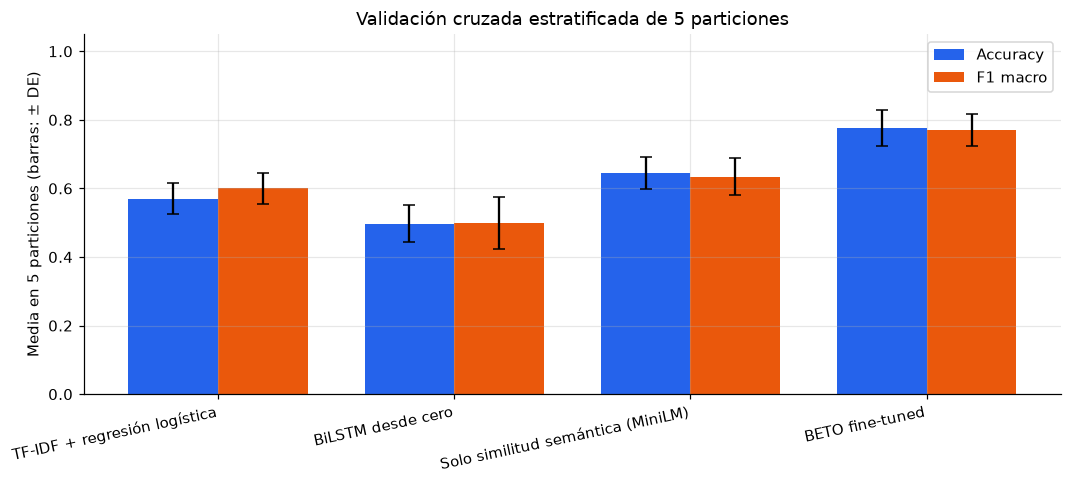

,Accuracy (media ± DE),F1 macro (media ± DE)
Modelo,,
TF-IDF + regresión logística,0.5701 ± 0.0450,0.6003 ± 0.0445
BiLSTM desde cero,0.4977 ± 0.0536,0.4994 ± 0.0748
Solo similitud semántica (MiniLM),0.6448 ± 0.0466,0.6347 ± 0.0531
BETO fine-tuned,0.7758 ± 0.0519,0.7713 ± 0.0473


In [37]:
# ---------- Validación cruzada estratificada de 5 particiones ----------
from sklearn.model_selection import StratifiedKFold

def metricas_cv(reales, preds):
    return accuracy_score(reales, preds), f1_score(reales, preds, average="macro", zero_division=0)

MODELOS_CV = ["TF-IDF + regresión logística", "BiLSTM desde cero", "Solo similitud semántica (MiniLM)", "BETO fine-tuned"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas_cv = []
t_cv0 = time.time()
for k, (idx_trval, idx_te) in enumerate(skf.split(df, df["label"]), start=1):
    cv_trval, cv_te = df.iloc[idx_trval], df.iloc[idx_te].reset_index(drop=True)
    cv_tr, cv_va = train_test_split(cv_trval, test_size=0.15, stratify=cv_trval["label"], random_state=SEED)
    cv_tr, cv_va = cv_tr.reset_index(drop=True), cv_va.reset_index(drop=True)
    # Aumento a partir del train de la partición; etiqueta solo con MiniLM; anti-fuga contra val y prueba de la partición
    reservadas_cv = (cv_va["texto"].tolist() + cv_te["texto"].tolist() + gen_df["texto"].tolist() + FRASES_RESERVADAS
                     + (massive_prueba_df["texto"].tolist() + massive_val_df["texto"].tolist() if MASSIVE_OK else []))
    aumento_cv, _ = filtrar_aumento(cv_tr, reservadas_cv, usar_referencia=False)
    aumento_cv = aumento_cv[aumento_cv["tecnica"].isin(HP["tecnicas_aumento"])]
    cv_va = pd.concat([cv_va, preparar_externo(massive_val_df)], ignore_index=True) if MASSIVE_OK else cv_va
    cv_tr = base_entrenamiento(cv_tr, HP["massive"])
    y_te = cv_te["label"].values
    res = {}

    # TF-IDF + regresión logística
    vec = TfidfVectorizer(preprocessor=normalizar_eda, ngram_range=(1, 2), sublinear_tf=True)
    clf = LogisticRegression(max_iter=2000, C=10, random_state=SEED).fit(vec.fit_transform(cv_tr["texto"]), cv_tr["label"])
    res[MODELOS_CV[0]] = metricas_cv(y_te, clf.predict(vec.transform(cv_te["texto"])))

    # BiLSTM (vocabulario propio de la partición)
    red, voc, *_ = entrenar_bilstm(cv_tr, cv_va)
    res[MODELOS_CV[1]] = metricas_cv(y_te, predecir_lstm(cv_te["texto"], red, voc))
    del red

    # MiniLM: vecino más cercano en entrenamiento + validación
    cv_kb = pd.concat([cv_tr, cv_va], ignore_index=True)
    emb_kb = encoder_sem.encode(cv_kb["texto_norm"].tolist(), convert_to_tensor=True, normalize_embeddings=True)
    emb_te = encoder_sem.encode(cv_te["texto_norm"].tolist(), convert_to_tensor=True, normalize_embeddings=True)
    vecino = util.cos_sim(emb_te, emb_kb).argmax(dim=1).cpu().numpy()
    res[MODELOS_CV[2]] = metricas_cv(y_te, cv_kb["label"].values[vecino])

    # BETO con la configuración elegida en la búsqueda
    modelo_cv, _, mejor_cv, _ = entrenar_beto(cv_tr, cv_va, HP["learning_rate"], aumento_cv)
    _, _, preds_cv, reales_cv, _ = evaluar(modelo_cv, DataLoader(a_dataset(cv_te["texto_norm"], cv_te["label"]), batch_size=64))
    res[MODELOS_CV[3]] = metricas_cv(reales_cv, preds_cv)
    del modelo_cv
    liberar_gpu()

    for nombre in MODELOS_CV:
        filas_cv.append({"particion": k, "modelo": nombre, "accuracy": res[nombre][0], "f1_macro": res[nombre][1]})
    print(f"Partición {k} (train {len(cv_tr)} | val {len(cv_va)} | prueba {len(cv_te)}): "
          + " | ".join(f"{n.split(' ')[0]} acc {res[n][0]:.3f}" for n in MODELOS_CV))

tiempo_cv = time.time() - t_cv0
print(f"Tiempo total de la validación cruzada: {tiempo_cv:.1f} s")
cv_df = pd.DataFrame(filas_cv).round(4)
cv_df.to_csv(os.path.join(DATA_DIR, "validacion_cruzada.csv"), index=False)
cv_resumen = cv_df.groupby("modelo")[["accuracy", "f1_macro"]].agg(["mean", "std"]).loc[MODELOS_CV].round(4)
cv_tabla = pd.DataFrame({
    "Accuracy (media ± DE)": [f"{cv_resumen.loc[m, ('accuracy', 'mean')]:.4f} ± {cv_resumen.loc[m, ('accuracy', 'std')]:.4f}" for m in MODELOS_CV],
    "F1 macro (media ± DE)": [f"{cv_resumen.loc[m, ('f1_macro', 'mean')]:.4f} ± {cv_resumen.loc[m, ('f1_macro', 'std')]:.4f}" for m in MODELOS_CV],
}, index=pd.Index(MODELOS_CV, name="Modelo"))
print("\nValidación cruzada estratificada (5 particiones):")
print(cv_tabla.to_string())

x = np.arange(len(MODELOS_CV)); ancho = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
for desp, met, color, nombre in [(-ancho / 2, "accuracy", COLOR_1, "Accuracy"), (ancho / 2, "f1_macro", COLOR_2, "F1 macro")]:
    ax.bar(x + desp, cv_resumen[(met, "mean")], ancho, yerr=cv_resumen[(met, "std")], capsize=4, color=color, label=nombre)
ax.set_xticks(x); ax.set_xticklabels(MODELOS_CV, rotation=12, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("Media en 5 particiones (barras: ± DE)"); ax.legend()
ax.set_title("Validación cruzada estratificada de 5 particiones")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig9_validacion_cruzada.png"), bbox_inches="tight"); plt.show()
cv_tabla

### 6.3 Aclaración ante la duda: elección de umbrales en validación
Cuando BETO duda entre dos intenciones temáticas, en lugar de responder con una de ellas el bot pregunta «¿Te refieres a 1) … o 2) …?», como hacen Rasa o Dialogflow. Se aclara si la probabilidad top-1 es menor que `U_aclarar` o si la diferencia top-1 − top-2 es menor que `M` (y ninguna de las dos es una intención social). Los umbrales se eligen **solo en validación**: se maximiza la accuracy de lo que se responde directamente (top-1 de BETO en los casos no aclarados) con un máximo de 15 % de aclaraciones; en empate se prefiere menos aclaraciones. Se simula con BETO y no con el híbrido completo porque la base semántica contiene las frases de validación.

Sin aclaración: accuracy directa en validación 0.8646
Elegido: U_aclarar = 0.65 | M = 0.0 → aclaraciones 11.5% | accuracy directa 0.9412 | la intención correcta está entre las 2 opciones en 45.5% de las aclaraciones


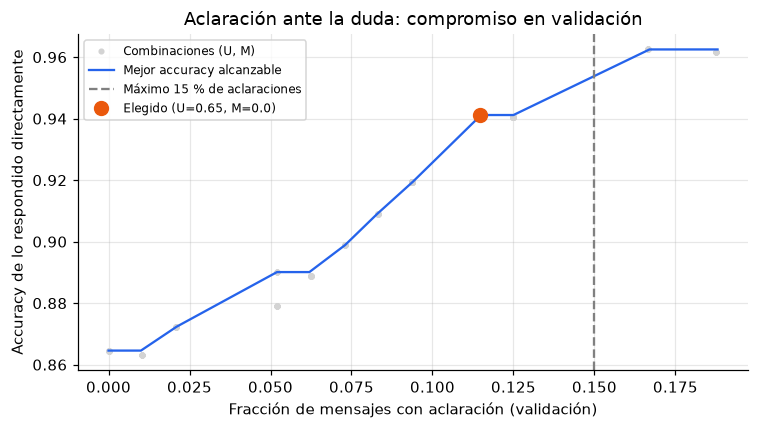

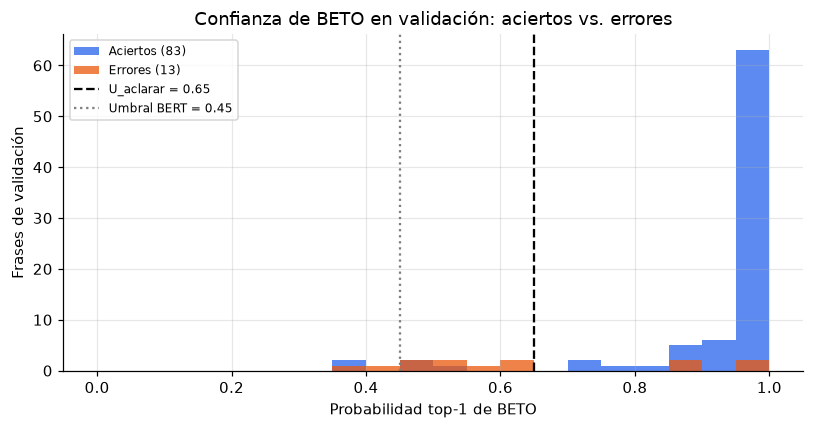

Confianza top-1 en validación · mediana aciertos 0.968 | mediana errores 0.596 | errores con confianza ≥ U_aclarar: 4 de 13 | errores con confianza ≥ 0.45: 11


In [38]:
# ---------- Umbrales de aclaración (solo validación) ----------
_, _, _, val_reales_a, val_probs_a = evaluar(model, val_loader)
val_reales_a = np.array(val_reales_a)
orden_a = np.argsort(-val_probs_a, axis=1)
p1_a = val_probs_a[np.arange(len(val_probs_a)), orden_a[:, 0]]
p2_a = val_probs_a[np.arange(len(val_probs_a)), orden_a[:, 1]]
ids_sociales = {label2id[i] for i in INTENCIONES_SOCIALES}
ambas_tematicas = np.array([a not in ids_sociales and b not in ids_sociales for a, b in orden_a[:, :2]])
acierto_top1 = orden_a[:, 0] == val_reales_a
correcta_en_top2 = acierto_top1 | (orden_a[:, 1] == val_reales_a)
MAX_ACLARACIONES = 0.15

rejilla = []
for u in np.round(np.arange(0.0, 0.951, 0.05), 2):
    for m in np.round(np.arange(0.0, 0.501, 0.05), 2):
        aclara = ambas_tematicas & ((p1_a < u) | (p1_a - p2_a < m))
        directos = ~aclara
        rejilla.append({"U_aclarar": u, "M": m, "tasa_aclaracion": aclara.mean(),
                        "accuracy_directa": acierto_top1[directos].mean() if directos.any() else np.nan,
                        "aclaraciones_utiles": correcta_en_top2[aclara].mean() if aclara.any() else np.nan})
rejilla = pd.DataFrame(rejilla)
validas = rejilla[rejilla["tasa_aclaracion"] <= MAX_ACLARACIONES]
elegida = validas.sort_values(["accuracy_directa", "tasa_aclaracion", "U_aclarar", "M"],
                              ascending=[False, True, True, True]).iloc[0]
U_ACLARAR, M_ACLARAR = float(elegida["U_aclarar"]), float(elegida["M"])
sin_aclarar = rejilla[(rejilla["U_aclarar"] == 0) & (rejilla["M"] == 0)].iloc[0]
print(f"Sin aclaración: accuracy directa en validación {sin_aclarar['accuracy_directa']:.4f}")
print(f"Elegido: U_aclarar = {U_ACLARAR} | M = {M_ACLARAR} → aclaraciones {elegida['tasa_aclaracion']:.1%} | "
      f"accuracy directa {elegida['accuracy_directa']:.4f} | la intención correcta está entre las 2 opciones en "
      f"{elegida['aclaraciones_utiles']:.1%} de las aclaraciones")

frontera = rejilla.groupby(rejilla["tasa_aclaracion"].round(3))["accuracy_directa"].max().reset_index()
plt.figure(figsize=(7, 4))
plt.plot(rejilla["tasa_aclaracion"], rejilla["accuracy_directa"], ".", color="lightgray", label="Combinaciones (U, M)")
plt.plot(frontera["tasa_aclaracion"], frontera["accuracy_directa"].cummax(), "-", color=COLOR_1, label="Mejor accuracy alcanzable")
plt.axvline(MAX_ACLARACIONES, color="gray", linestyle="--", label="Máximo 15 % de aclaraciones")
plt.plot(elegida["tasa_aclaracion"], elegida["accuracy_directa"], "o", color=COLOR_2, markersize=9,
         label=f"Elegido (U={U_ACLARAR}, M={M_ACLARAR})")
plt.xlabel("Fracción de mensajes con aclaración (validación)"); plt.ylabel("Accuracy de lo respondido directamente")
plt.title("Aclaración ante la duda: compromiso en validación"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig10_aclaracion.png"), bbox_inches="tight"); plt.show()

# Figura: confianza top-1 de BETO en validación, aciertos vs. errores
contenedores = np.linspace(0, 1, 21)
plt.figure(figsize=(7.5, 4))
plt.hist(p1_a[acierto_top1], bins=contenedores, alpha=0.75, color=COLOR_1, label=f"Aciertos ({int(acierto_top1.sum())})")
plt.hist(p1_a[~acierto_top1], bins=contenedores, alpha=0.75, color=COLOR_2, label=f"Errores ({int((~acierto_top1).sum())})")
plt.axvline(U_ACLARAR, color="black", linestyle="--", label=f"U_aclarar = {U_ACLARAR}")
plt.axvline(UMBRAL_BERT, color="gray", linestyle=":", label=f"Umbral BERT = {UMBRAL_BERT}")
plt.xlabel("Probabilidad top-1 de BETO"); plt.ylabel("Frases de validación"); plt.legend(fontsize=8)
plt.title("Confianza de BETO en validación: aciertos vs. errores")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig15_confianza_validacion.png"), bbox_inches="tight"); plt.show()
print(f"Confianza top-1 en validación · mediana aciertos {np.median(p1_a[acierto_top1]):.3f} | mediana errores "
      f"{np.median(p1_a[~acierto_top1]):.3f} | errores con confianza ≥ U_aclarar: {int((~acierto_top1 & (p1_a >= U_ACLARAR)).sum())} "
      f"de {int((~acierto_top1).sum())} | errores con confianza ≥ {UMBRAL_BERT}: {int((~acierto_top1 & (p1_a >= UMBRAL_BERT)).sum())}")

### 6.4 Calibración de BETO en validación
Un clasificador está calibrado si, entre las predicciones hechas con confianza *p*, acierta aproximadamente una fracción *p*. Se mide con el **error de calibración esperado** (ECE; Guo et al., 2017): las predicciones de validación se agrupan en 15 intervalos de confianza y se promedia, ponderada por el número de frases, la diferencia absoluta entre la accuracy y la confianza media de cada intervalo. El diagrama de fiabilidad muestra esa diferencia por intervalo (la diagonal es la calibración perfecta). En esta versión no se corrige la calibración; el *temperature scaling* aprendido en validación se agrega en la Fase 3.

BETO en validación (96 frases): ECE (15 intervalos) = 0.0657 | confianza media 0.8838 | accuracy 0.8646


,desde,hasta,confianza_media,accuracy,n
0,0.333,0.400,0.3770,0.6667,3
1,0.400,0.467,0.4440,0.5000,4
2,0.467,0.533,0.5135,0.3333,3
3,0.533,0.600,0.5673,0.0000,2
4,0.600,0.667,0.6415,0.0000,2
5,0.667,0.733,0.7141,1.0000,2
6,0.733,0.800,0.7629,1.0000,1
7,0.800,0.867,0.8367,1.0000,2
8,0.867,0.933,0.9012,0.7778,9
9,0.933,1.000,0.9707,0.9706,68


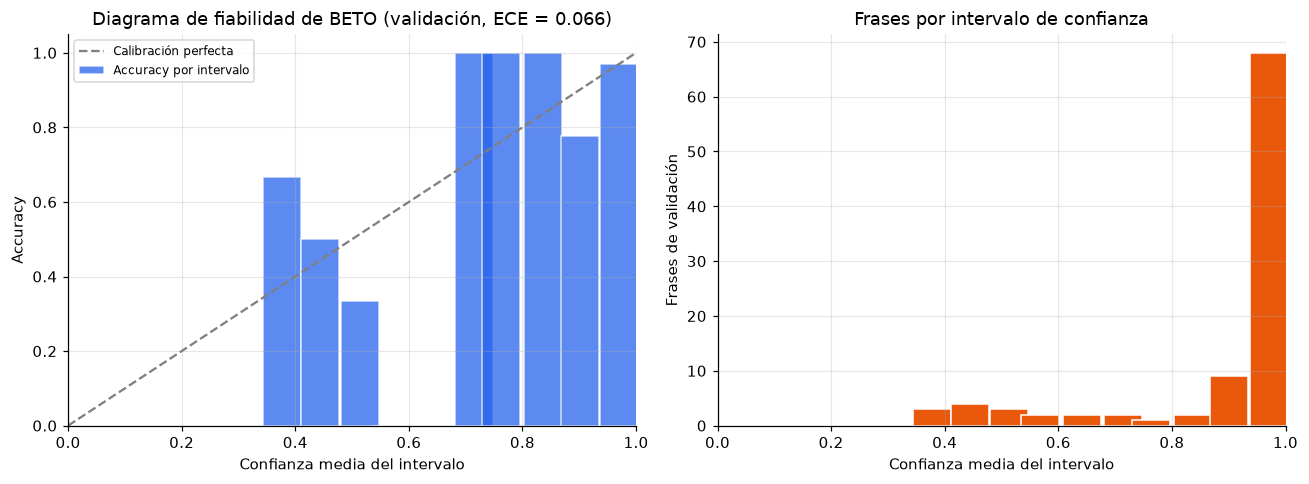

In [39]:
# ---------- Calibración: ECE y diagrama de fiabilidad (validación) ----------
N_INTERVALOS_ECE = 15

def ece_y_curva(probs, reales, n_intervalos=N_INTERVALOS_ECE):
    """ECE (Guo et al., 2017) y puntos del diagrama de fiabilidad: (confianza media, accuracy, n) por intervalo."""
    conf, acierto = probs.max(axis=1), probs.argmax(axis=1) == np.asarray(reales)
    bordes = np.linspace(0, 1, n_intervalos + 1)
    ece, curva = 0.0, []
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (conf > a) & (conf <= b)
        if m.any():
            ece += m.mean() * abs(acierto[m].mean() - conf[m].mean())
            curva.append({"desde": round(a, 3), "hasta": round(b, 3), "confianza_media": float(conf[m].mean()),
                          "accuracy": float(acierto[m].mean()), "n": int(m.sum())})
    return float(ece), pd.DataFrame(curva)

ECE_VAL, curva_val = ece_y_curva(val_probs, val_reales)
print(f"BETO en validación ({len(val_reales)} frases): ECE ({N_INTERVALOS_ECE} intervalos) = {ECE_VAL:.4f} | "
      f"confianza media {val_probs.max(axis=1).mean():.4f} | accuracy {np.mean(np.argmax(val_probs, 1) == np.asarray(val_reales)):.4f}")
display(curva_val.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
axes[0].bar(curva_val["confianza_media"], curva_val["accuracy"], width=1 / N_INTERVALOS_ECE, alpha=0.75,
            color=COLOR_1, edgecolor="white", label="Accuracy por intervalo")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel("Confianza media del intervalo"); axes[0].set_ylabel("Accuracy")
axes[0].set_title(f"Diagrama de fiabilidad de BETO (validación, ECE = {ECE_VAL:.3f})"); axes[0].legend(fontsize=8)
axes[1].bar(curva_val["confianza_media"], curva_val["n"], width=1 / N_INTERVALOS_ECE, color=COLOR_2, edgecolor="white")
axes[1].set_xlim(0, 1); axes[1].set_xlabel("Confianza media del intervalo"); axes[1].set_ylabel("Frases de validación")
axes[1].set_title("Frases por intervalo de confianza")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig16_calibracion_validacion.png"), bbox_inches="tight"); plt.show()

### 6.5 Base de conocimiento para la recuperación (RAG)
Cada guía de `base_conocimiento.json` se divide en fragmentos: el resumen, cada paso numerado y la indicación de qué hacer si no funciona, con las referencias de la guía. Los fragmentos que contienen un marcador `[COMPLETAR: …]` no se indexan: el bot nunca los muestra y, para ese dato, remite a la mesa de ayuda «TICS a un CLIC» (`contacto_por_defecto`). La recuperación usa el mismo codificador MiniLM del respaldo semántico (similitud coseno). Aquí solo se construye el índice y se mide en **validación** si el fragmento recuperado pertenece a la guía de la intención correcta; la generación con Qwen y el verificador se reintegran en una fase posterior.

In [40]:
# ---------- Fragmentos de las guías e índice MiniLM ----------
MARCADOR_COMPLETAR = "[COMPLETAR"
CONTACTO_POR_DEFECTO = BASE_CONOCIMIENTO["contacto_por_defecto"]["texto"]

def fragmentos_guias(guias):
    filas = []
    for intent, g in guias.items():
        refs = [r for r in g["referencias"] if MARCADOR_COMPLETAR not in r["titulo"] + r["url"]]
        partes = ([("resumen", 0, g["resumen"])] + [("paso", i, p) for i, p in enumerate(g["pasos"], start=1)]
                  + [("si_no_funciona", 0, g["si_no_funciona"])])
        for tipo, n, texto in partes:
            filas.append({"intencion": intent, "titulo": g["titulo"], "tipo": tipo, "paso": n, "texto": texto,
                          "referencias": "; ".join(f"{r['titulo']} ({r['url']})" for r in refs),
                          "tiene_completar": MARCADOR_COMPLETAR in texto})
    return pd.DataFrame(filas)

fragmentos_df = fragmentos_guias(GUIAS_V3)
fragmentos_rag = fragmentos_df[~fragmentos_df["tiene_completar"]].reset_index(drop=True)
emb_fragmentos = encoder_sem.encode([normalizar_texto(f"{t}. {x}") for t, x in zip(fragmentos_rag["titulo"], fragmentos_rag["texto"])],
                                    convert_to_tensor=True, normalize_embeddings=True)
print(f"Fragmentos: {len(fragmentos_df)} | indexados: {len(fragmentos_rag)} | omitidos por [COMPLETAR]: "
      f"{int(fragmentos_df['tiene_completar'].sum())}")

def recuperar(texto, k=3):
    """Devuelve los k fragmentos más similares al mensaje (intención, tipo, paso, texto, similitud)."""
    emb = encoder_sem.encode(normalizar_texto(texto), convert_to_tensor=True, normalize_embeddings=True)
    sims = util.cos_sim(emb, emb_fragmentos)[0].cpu().numpy()
    top = np.argsort(-sims)[:k]
    return fragmentos_rag.iloc[top].assign(similitud=sims[top].round(4))[["intencion", "tipo", "paso", "texto", "similitud"]]

# Medición en validación: ¿el fragmento recuperado es de la guía de la intención correcta?
val_tecnicas = val_df[val_df["intencion"].isin(GUIAS)].reset_index(drop=True)
emb_vt = encoder_sem.encode(val_tecnicas["texto_norm"].tolist(), convert_to_tensor=True, normalize_embeddings=True)
orden_rag = np.argsort(-util.cos_sim(emb_vt, emb_fragmentos).cpu().numpy(), axis=1)
intent_frag = fragmentos_rag["intencion"].values
RAG_TOP1_VAL = float(np.mean(intent_frag[orden_rag[:, 0]] == val_tecnicas["intencion"].values))
RAG_TOP3_VAL = float(np.mean([i in set(intent_frag[o[:3]]) for i, o in zip(val_tecnicas["intencion"], orden_rag)]))
print(f"Recuperación en validación ({len(val_tecnicas)} frases de intenciones técnicas): fragmento de la guía correcta "
      f"en el top-1 {RAG_TOP1_VAL:.4f} | en el top-3 {RAG_TOP3_VAL:.4f}")
print(f"Contacto por defecto: {CONTACTO_POR_DEFECTO}")
for t in val_tecnicas["texto"].head(3):
    print(f"\nMensaje (validación): {t}")
    print(recuperar(t).to_string(index=False))

Fragmentos: 125 | indexados: 100 | omitidos por [COMPLETAR]: 25
Recuperación en validación (46 frases de intenciones técnicas): fragmento de la guía correcta en el top-1 0.6522 | en el top-3 0.7826
Contacto por defecto: Para este caso comunícate con la mesa de ayuda «TICS a un CLIC» por el chat de Microsoft Teams o al correo ticsaunclic@ucundinamarca.edu.co, de lunes a viernes de 8:00 a. m. a 12:00 m. y de 2:00 p. m. a 6:00 p. m.

Mensaje (validación): me urge que alguien de sistemas me llame
         intencion    tipo  paso                                                                                                                                                                                                                                                           texto  similitud
hablar_con_soporte    paso     6                                                                                                                                En tu mensaje incluye tu nombre, código es

## 9. Guardado del modelo y resultados de la línea base (v1)

Se guardan el modelo ajustado y el tokenizador con `save_pretrained()`, junto con la configuración del clasificador (mapeo de etiquetas, umbrales elegidos en validación e hiperparámetros). Luego se **recarga el modelo desde disco** para comprobar que da las mismas predicciones. Los resultados de esta versión se guardan en `soportic/resultados_soporte_v1.json`: es la línea base de una intención que se compara con el modelo multietiqueta de la Fase 3 y no se modifica después.

In [41]:
# ---------- Guardado ----------
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

config_bot = {"version": "v1_una_intencion", "modelo_base": MODELO_BASE, "modelo_semantico": MODELO_SEMANTICO,
              "max_len": MAX_LEN, "umbral_bert": UMBRAL_BERT, "umbral_semantico": UMBRAL_SEMANTICO,
              "u_aclarar": U_ACLARAR, "m_aclarar": M_ACLARAR,
              "label2id": label2id, "id2label": {str(k): v for k, v in id2label.items()}, "hiperparametros": HP,
              "archivos": {"respuestas_fijas": "respuestas_fijas.json", "base_conocimiento": "base_conocimiento.json"}}
with open(os.path.join(BASE_DIR, "soportic_config.json"), "w", encoding="utf-8") as f:
    json.dump(config_bot, f, ensure_ascii=False, indent=2)

# ---------- Verificación: recarga desde disco ----------
modelo_recargado = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(DEVICE).eval()
tok_recargado = AutoTokenizer.from_pretrained(MODEL_DIR)
prueba = normalizar_texto("no me deja entrar a moodle desde el portatil")
with torch.no_grad():
    pred_rec = modelo_recargado(**tok_recargado(prueba, return_tensors="pt").to(DEVICE)).logits.argmax(-1).item()
print("Predicción modelo original :", predecir_intencion(prueba, 1)[0][0])
print("Predicción modelo recargado:", modelo_recargado.config.id2label[pred_rec])
del modelo_recargado; liberar_gpu()

Predicción modelo original : moodle_acceso
Predicción modelo recargado: moodle_acceso


In [42]:
# ---------- Resultados de la línea base de una intención (v1) ----------
TIEMPO_TOTAL_NOTEBOOK = time.time() - T_INICIO_NOTEBOOK
RESULTADOS = {
    "version": "v1 — línea base de una intención (Fase 2)",
    "n_intenciones": NUM_LABELS, "n_ejemplos": len(df),
    "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df), "n_generalizacion": len(gen_df),
    "n_externo_una_intencion": len(FRASES_EXTERNAS), "n_externo_varias_intenciones": len(FRASES_EXTERNAS_MULTI),
    "beto": {"epocas_entrenadas": len(historial["val_loss"]), "mejor_epoca": mejor_epoca,
             "val_f1_macro_mejor_epoca": round(mejor_val_f1, 4), "val_loss_mejor_epoca": round(val_loss_mejor_epoca, 4),
             "accuracy_val": round(val_acc_f, 4), "accuracy_test": round(test_acc, 4),
             "precision_macro_test": round(p_mac, 4), "recall_macro_test": round(r_mac, 4),
             "f1_macro_test": round(f1_mac, 4), "f1_ponderado_test": round(f1_w, 4),
             "n_errores_test": len(errores), "clase_peor_f1_test": metricas_clase.index[0],
             "f1_peor_clase_test": float(metricas_clase["f1-score"].iloc[0])},
    "comparacion_modelos": comparacion.to_dict(orient="index"),
    "prueba_externa": {"control_fuga": {"umbral_minilm": SIM_FUGA_MAX, "frases_con_fuga": len(fuga_ext),
                                        "detalle": [{"frase": t, "similitud_max": s_} for t, s_ in fuga_ext]},
                       "reportada": bool(EXTERNO_LIMPIO and FRASES_EXTERNAS),
                       "beto_accuracy": None if acc_ext is None else round(acc_ext, 4),
                       "beto_f1_macro": None if f1_ext is None else round(f1_ext, 4)},
    "prueba_fuera_de_dominio_massive": prueba_fuera.iloc[:, 0].to_dict() if prueba_fuera is not None else None,
    "validacion_cruzada": {m: {"accuracy_media": cv_resumen.loc[m, ("accuracy", "mean")],
                               "accuracy_de": cv_resumen.loc[m, ("accuracy", "std")],
                               "f1_macro_media": cv_resumen.loc[m, ("f1_macro", "mean")],
                               "f1_macro_de": cv_resumen.loc[m, ("f1_macro", "std")]} for m in MODELOS_CV},
    "calibracion_val": {"ece": round(ECE_VAL, 4), "intervalos": N_INTERVALOS_ECE,
                        "curva": json.loads(curva_val.round(4).to_json(orient="records"))},
    "umbrales_hibrido": {"umbral_bert": UMBRAL_BERT, "umbral_semantico": UMBRAL_SEMANTICO,
                         "accuracy_val": round(float(elegido_hib["accuracy_val"]), 4),
                         "accuracy_val_solo_beto": round(acc_val_solo_bert, 4)},
    "aclaracion": {"U_aclarar": U_ACLARAR, "M": M_ACLARAR, "tasa_aclaracion_val": round(float(elegida["tasa_aclaracion"]), 4),
                   "accuracy_directa_val": round(float(elegida["accuracy_directa"]), 4),
                   "accuracy_sin_aclaracion_val": round(float(sin_aclarar["accuracy_directa"]), 4)},
    "silueta_cls": {k: round(float(v), 4) for k, v in silueta.items()},
    "rag": {"fragmentos": len(fragmentos_df), "indexados": len(fragmentos_rag),
            "omitidos_por_completar": int(fragmentos_df["tiene_completar"].sum()),
            "top1_guia_correcta_val": round(RAG_TOP1_VAL, 4), "top3_guia_correcta_val": round(RAG_TOP3_VAL, 4)},
    "config_beto_elegida": {"learning_rate": HP["learning_rate"], "aumento": HP["aumento"],
                            "tecnicas_aumento": HP["tecnicas_aumento"], "massive": HP["massive"],
                            "criterio": "mayor F1 macro de validación (desempate: menor pérdida de validación)",
                            "paciencia": HP["paciencia"], "batch_size": HP["batch_size"], "epocas_max": HP["epocas_max"]},
    "busqueda_beto": json.loads(busqueda_beto.to_json(orient="records")),
    "tamanos_train": tamanos_train,
    "aumento_conteos": json.loads(tabla_filtros.to_json(orient="index")),
    "massive": {"usado": bool(MASSIVE_OK), "train": len(massive_train_df), "validacion": len(massive_val_df),
                "prueba_aparte": len(massive_prueba_df), "escenarios": ESCENARIOS_MASSIVE},
    "tiempos_s": {"tfidf": round(tiempo_tfidf, 2), "bilstm": round(tiempo_lstm, 1),
                  "beto_busqueda_total": round(float(busqueda_beto["tiempo_s"].sum()), 1),
                  "beto_final": round(tiempo_entrenamiento, 1), "validacion_cruzada": round(tiempo_cv, 1),
                  "notebook_total": round(TIEMPO_TOTAL_NOTEBOOK, 1)},
    "historial_beto": {k: [round(v, 4) for v in vals] for k, vals in historial.items()},
    "historial_bilstm": {k: [round(v, 4) for v in vals] for k, vals in hist_lstm.items()},
}
if DEVICE.type == "cuda":
    RESULTADOS["gpu"] = torch.cuda.get_device_name(0)
    RESULTADOS["vram_pico_gb"] = round(torch.cuda.max_memory_allocated() / 1e9, 2)
# La v1 congelada (soportic/v1_congelada/) no se sobrescribe: si existe, esta ejecución se guarda aparte y se compara.
RUTA_V1_CONGELADA = os.path.join(BASE_DIR, "v1_congelada", "resultados_soporte_v1.json")
V1_CONGELADA = os.path.exists(RUTA_V1_CONGELADA)
ruta_resultados_v1 = os.path.join(BASE_DIR, "resultados_soporte_v1_reejecucion.json" if V1_CONGELADA else "resultados_soporte_v1.json")
with open(ruta_resultados_v1, "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=2, default=float)
print("Resultados guardados en", ruta_resultados_v1)
if V1_CONGELADA:
    with open(RUTA_V1_CONGELADA, encoding="utf-8") as f:
        v1_cong = json.load(f)
    actual = json.loads(json.dumps(RESULTADOS, default=float))
    diferencias = [s for s in ["beto", "comparacion_modelos", "validacion_cruzada", "calibracion_val", "umbrales_hibrido",
                               "aclaracion", "prueba_fuera_de_dominio_massive", "config_beto_elegida"]
                   if json.dumps(actual.get(s), sort_keys=True) != json.dumps(v1_cong.get(s), sort_keys=True)]
    print("Comparación con la v1 congelada:", "todas las cifras coinciden" if not diferencias
          else f"difieren las secciones {diferencias} (la referencia sigue siendo la v1 congelada)")

# ---------- Tabla resumen ----------
filas_resumen = []
for m in comparacion.index:
    fila_r = {"Modelo": m, "Acc. prueba": comparacion.loc[m, "Accuracy prueba"], "F1 prueba": comparacion.loc[m, "F1 macro prueba"],
              "Acc. generalización": comparacion.loc[m, "Accuracy generalización"],
              "F1 generalización": comparacion.loc[m, "F1 macro generalización"],
              "Acc. externa (1 intención)": comparacion.loc[m, "Accuracy externa"] if "Accuracy externa" in comparacion else "no reportada",
              "VC acc. (media ± DE)": (f"{cv_resumen.loc[m, ('accuracy', 'mean')]:.4f} ± {cv_resumen.loc[m, ('accuracy', 'std')]:.4f}"
                                       if m in MODELOS_CV else "—"),
              "VC F1 (media ± DE)": (f"{cv_resumen.loc[m, ('f1_macro', 'mean')]:.4f} ± {cv_resumen.loc[m, ('f1_macro', 'std')]:.4f}"
                                     if m in MODELOS_CV else "—"),
              "Fuera de dominio (MASSIVE)": prueba_fuera.loc[m].iloc[0] if prueba_fuera is not None else None}
    filas_resumen.append(fila_r)
tabla_resumen = pd.DataFrame(filas_resumen).set_index("Modelo")
print(f"ECE de BETO en validación: {ECE_VAL:.4f}")
print("Tiempos (s):", RESULTADOS["tiempos_s"])
tabla_resumen

Resultados guardados en soportic\resultados_soporte_v1_reejecucion.json


Comparación con la v1 congelada: difieren las secciones ['comparacion_modelos', 'validacion_cruzada', 'prueba_fuera_de_dominio_massive'] (la referencia sigue siendo la v1 congelada)
ECE de BETO en validación: 0.0657
Tiempos (s): {'tfidf': 0.67, 'bilstm': 12.5, 'beto_busqueda_total': 1320.9, 'beto_final': 192.7, 'validacion_cruzada': 506.7, 'notebook_total': 1972.7}


,Acc. prueba,F1 prueba,Acc. generalización,F1 generalización,Acc. externa (1 intención),VC acc. (media ± DE),VC F1 (media ± DE),Fuera de dominio (MASSIVE)
Modelo,,,,,,,,
TF-IDF + regresión logística,0.5522,0.5642,0.7059,0.7277,0.7333,0.5701 ± 0.0450,0.6003 ± 0.0445,0.98
BiLSTM desde cero,0.4328,0.4311,0.5588,0.5950,0.5889,0.4977 ± 0.0536,0.4994 ± 0.0748,0.92
Solo similitud semántica (MiniLM),0.6119,0.6015,0.7794,0.7754,0.8000,0.6448 ± 0.0466,0.6347 ± 0.0531,0.90
BETO fine-tuned,0.7612,0.7316,0.8824,0.8827,0.8111,0.7758 ± 0.0519,0.7713 ± 0.0473,0.94
Híbrido SoporTIC (BETO + semántico),0.7910,0.7811,0.8824,0.8850,0.8111,—,—,0.96


### Interpretación de los resultados de la v1 (ejecución del 2026-11-14, RTX 5050; cifras de `resultados_soporte_v1.json`)

- **Comparación de modelos.** En prueba (67 frases), BETO obtiene accuracy 0,7612 y F1 macro 0,7316, y el híbrido sube a 0,7910 y 0,7811. Las líneas base quedan por debajo: MiniLM 0,6119, TF-IDF 0,5522 y BiLSTM 0,4328 de accuracy. En generalización (68 frases), BETO y el híbrido alcanzan 0,8824 de accuracy (F1 macro 0,8827 y 0,8850).
- **Validación cruzada.** Con 5 particiones, el orden se mantiene: BETO 0,7895 ± 0,0384, MiniLM 0,6448 ± 0,0466, TF-IDF 0,5701 ± 0,0450 y BiLSTM 0,4977 ± 0,0536 de accuracy. Todos los modelos rinden más en generalización que en prueba; con unas 4 frases por intención en prueba, cada error mueve la accuracy cerca de 1,5 puntos, y la media de la validación cruzada de BETO queda entre ambas cifras. La BiLSTM, entrenada desde cero con unas 18 frases por intención más el aumento, es el modelo más débil.
- **Hallazgo: `restablecer_contrasena` tiene F1 = 0,0 en prueba.** Sus 4 frases de prueba se asignaron a otras intenciones: «se me olvido la clave y mañana entrego en moodle» → `moodle_acceso` (confianza 0,949); «la app authenticator se borro del celular y no puedo entrar» → `instalar_python` (0,834); «mi cuenta esta bloqueada por intentar muchas veces» → `plataforma_academica` (0,287); «no se cual es mi contraseña inicial, soy nuevo» → `hablar_con_soporte` (0,407). La primera menciona dos servicios a la vez, que es el caso que aborda la multiintención de la Fase 3. En total, BETO comete 16 errores en las 67 frases de prueba.
- **Hallazgo: la configuración «tildes» no tuvo efecto.** El dataset está escrito casi sin tildes, de modo que las 309 copias sin tildes eran idénticas a sus frases de origen y el filtro de duplicados las descartó todas. Por eso «tildes» y «sin aumento» entrenan con las mismas 409 frases y obtienen el mismo F1 macro de validación (0,7997). La mejora vino del ruido ortográfico (0,8246) y de la retrotraducción (0,8275, configuración elegida, learning rate 2e-5).
- **MASSIVE.** Sin MASSIVE, la configuración comparable obtiene F1 macro de validación 0,7160 y F1 0,6275 en `fuera_de_dominio`, frente a 0,7997 y 0,9296 con MASSIVE. En la prueba aparte de 50 frases de MASSIVE, BETO reconoce como fuera de dominio el 94 % y el híbrido el 96 %.
- **Umbrales, aclaración y calibración (validación).** Los umbrales del híbrido elegidos son 0,45 (BETO) y 0,60 (semántico): el respaldo semántico decide el 4,2 % de la validación y la accuracy pasa de 0,8646 a 0,8750. Con `U_aclarar` = 0,65, el bot pediría aclaración en el 11,5 % de la validación y la accuracy de lo respondido directamente sube a 0,9412; la intención correcta está entre las dos opciones ofrecidas en el 45,5 % de las aclaraciones. El ECE de BETO es 0,0657, con confianza media 0,8838 frente a una accuracy de 0,8646 (ligera sobreconfianza).
- **Representaciones y recuperación.** La silueta de los vectores [CLS] por intención pasa de −0,054 (BETO preentrenado) a 0,453 (ajustado). En la recuperación sobre la base de conocimiento, el fragmento de la guía correcta aparece en el top-1 para el 65,2 % de las frases técnicas de validación y en el top-3 para el 78,3 %.
- **Prueba externa (90 líneas de una intención; calculada después del reemplazo de la última línea con fuga, con el BETO congelado).** El control de fuga quedó en 0 frases con similitud MiniLM ≥ 0,90. BETO obtiene accuracy 0,8111 y F1 macro 0,8256, con las mismas predicciones que el BETO reejecutado (90/90); el híbrido 0,8111 y 0,7774; MiniLM 0,8000 y 0,7943; TF-IDF 0,7333 y 0,7591; BiLSTM 0,5889 y 0,5943. La cifra externa de BETO queda entre la de prueba (0,7612) y la de generalización (0,8824).

# Fase 3 — Multiintención y calibración (versión v2)

Un mensaje de soporte puede describir dos problemas a la vez («olvidé la clave y además no me deja entregar en Moodle»). La v1 asigna una sola intención; esta fase compara tres formas de reconocer varias intenciones con los mismos datos:

1. **v1 top-1** (línea base): la intención de mayor probabilidad del BETO de una intención.
2. **Segmentación por conectores + v1**: el mensaje se divide en segmentos por conectores («y», «además», «también», «otra cosa:», «aparte de eso», signos de interrogación y puntos) y la v1 clasifica cada segmento.
3. **BETO multietiqueta**: una salida sigmoide por intención (`problem_type="multi_label_classification"`, pérdida `BCEWithLogitsLoss`), con un umbral por intención elegido en validación.

Todos los umbrales, la temperatura y los hiperparámetros se eligen **solo en validación**. La v1 no se modifica: sus resultados de referencia están en `soportic/v1_congelada/`.

## 10. Datos multietiqueta y frases sintéticas de dos intenciones
**Reetiquetado.** Los archivos `dataset_soporte_multietiqueta.csv` y `frases_generalizacion_multietiqueta.csv` aplican la guía `guia_anotacion_multietiqueta.md` (definida antes de ver resultados y sin mirar predicciones): una frase lleva dos etiquetas solo si describe dos problemas distintos; si otro servicio aparece como contexto, lleva una. Al aplicarla no se reetiquetó ninguna frase (el dataset se escribió con la regla de una sola intención), de modo que la señal de varias intenciones del entrenamiento proviene de las frases sintéticas. La partición es la misma de la v1.

**Frases sintéticas.** Se combinan dos frases de **distinta intención técnica** (las 11 técnicas y `hablar_con_soporte`; sin saludo, despedida, agradecimiento, `sobre_bot` ni `fuera_de_dominio`) de la **misma partición**, con seis conectores rotados: «y», «y ademas», «, tambien», «. otra cosa:», dos preguntas seguidas y «, aparte de eso». Se generan 200 para entrenamiento, 40 para validación y 40 para prueba, sin repetir la misma pareja de frases. Filtros: sin duplicados normalizados con el dataset ni entre sí, y anti-fuga (MiniLM ≥ 0,90): las de prueba y validación no pueden parecerse al entrenamiento (original y aumento), y las de entrenamiento no pueden parecerse a validación, prueba, generalización, la prueba externa ni la prueba aparte de MASSIVE.

In [43]:
# ---------- Datos multietiqueta ----------
import torch.nn.functional as F
from sklearn.metrics import hamming_loss
T_INICIO_FASE3 = time.time()

ml_df = pd.read_csv("dataset_soporte_multietiqueta.csv")
gen_ml = pd.read_csv("frases_generalizacion_multietiqueta.csv")
assert (ml_df["texto"].values == df["texto"].values).all(), "El dataset multietiqueta no corresponde al de la v1"
for nombre_p, parte in [("train", train_df), ("val", val_df[val_df["texto"].isin(df["texto"])]), ("test", test_df)]:
    assert set(ml_df.loc[ml_df["particion"] == nombre_p, "texto"]) == set(parte["texto"]), f"Partición {nombre_p} distinta de la v1"
INTENCIONES_TECNICAS = sorted(GUIAS)          # 11 técnicas + hablar_con_soporte
etiquetas_ml = dict(zip(ml_df["texto"], ml_df["intenciones"]))
print(f"Dataset multietiqueta: {len(ml_df)} frases ({ml_df['particion'].value_counts().to_dict()}) | con 2+ intenciones: "
      f"{int(ml_df['intenciones'].str.contains(r'[|]').sum())} | generalización con 2+: {int(gen_ml['intenciones'].str.contains(r'[|]').sum())}")

def Y_de(listas_etiquetas):
    """Matriz multi-hot (n × NUM_LABELS) a partir de cadenas 'a|b' o listas."""
    Y = np.zeros((len(listas_etiquetas), NUM_LABELS), dtype=np.float32)
    for i, et in enumerate(listas_etiquetas):
        for e in (et.split("|") if isinstance(et, str) else et):
            Y[i, label2id[e]] = 1.0
    return Y

# ---------- Generador de frases sintéticas de dos intenciones ----------
CONECTORES = [("y", lambda a, b: f"{a} y {b}"), ("y ademas", lambda a, b: f"{a} y ademas {b}"),
              ("tambien", lambda a, b: f"{a}, tambien {b}"), ("otra cosa", lambda a, b: f"{a}. otra cosa: {b}"),
              ("dos preguntas", lambda a, b: f"{a}? {b}?"), ("aparte de eso", lambda a, b: f"{a}, aparte de eso {b}")]
N_SINT = {"train": 200, "val": 40, "test": 40}

def _limpia(t):
    return str(t).strip().lstrip("¿¡ ").rstrip("?!.¿ ")

def generar_sinteticas(fuente, n, reservadas, claves_excluidas, semilla):
    """Combina frases de distinta intención técnica de 'fuente' (una misma partición). Devuelve (DataFrame, reporte)."""
    rng = np.random.default_rng(semilla)
    f = fuente[fuente["intencion"].isin(INTENCIONES_TECNICAS)]
    por_int = {k: g["texto"].tolist() for k, g in f.groupby("intencion")}
    pares = [(a, b) for a in sorted(por_int) for b in sorted(por_int) if a < b]
    emb_res = embeber(list(reservadas)) if len(reservadas) else None
    filas, usadas, claves, reporte, intentos = [], set(), set(claves_excluidas), Counter(), 0
    while len(filas) < n and intentos < 60 * n:
        for k in rng.permutation(len(pares)):
            if len(filas) >= n:
                break
            intentos += 1
            ia, ib = pares[k] if rng.random() < 0.5 else pares[k][::-1]
            ta = por_int[ia][rng.integers(len(por_int[ia]))]; tb = por_int[ib][rng.integers(len(por_int[ib]))]
            nombre_c, unir = CONECTORES[len(filas) % len(CONECTORES)]
            texto = unir(_limpia(ta), _limpia(tb))
            clave = clave_normalizada(texto)
            if (ta, tb) in usadas or clave in claves:
                reporte["duplicado"] += 1; continue
            if emb_res is not None and float(util.cos_sim(embeber([texto]), emb_res).max()) >= SIM_FUGA_MAX:
                reporte["anti-fuga"] += 1; continue
            usadas.add((ta, tb)); claves.add(clave)
            filas.append({"texto": texto, "intenciones": f"{ia}|{ib}", "conector": nombre_c, "frase_1": ta, "frase_2": tb})
    reporte["conservadas"] = len(filas)
    return pd.DataFrame(filas), dict(reporte)

def sinteticas_por_particion(tr, va, te, aumento_tr, semilla=SEED):
    """Genera las sintéticas de prueba, validación y entrenamiento respetando la partición y los filtros anti-fuga."""
    base_reservadas = (gen_df["texto"].tolist() + [f for f, _ in FRASES_EXTERNAS_TODAS]
                       + (massive_prueba_df["texto"].tolist() if MASSIVE_OK else []))
    claves_dataset = set(df["texto"].apply(clave_normalizada))
    entrenamiento = tr["texto"].tolist() + aumento_tr["texto"].astype(str).tolist()
    s_te, r_te = generar_sinteticas(te, N_SINT["test"], entrenamiento + base_reservadas, claves_dataset, semilla)
    s_va, r_va = generar_sinteticas(va, N_SINT["val"], entrenamiento + base_reservadas + te["texto"].tolist() + s_te["texto"].tolist(),
                                    claves_dataset | set(s_te["texto"].apply(clave_normalizada)), semilla + 1)
    s_tr, r_tr = generar_sinteticas(tr, N_SINT["train"], base_reservadas + va["texto"].tolist() + te["texto"].tolist()
                                    + s_va["texto"].tolist() + s_te["texto"].tolist(),
                                    claves_dataset | set(s_te["texto"].apply(clave_normalizada)) | set(s_va["texto"].apply(clave_normalizada)),
                                    semilla + 2)
    return s_tr, s_va, s_te, {"train": r_tr, "val": r_va, "test": r_te}

val_orig = val_df[val_df["texto"].isin(df["texto"])]          # validación sin las 30 frases de MASSIVE
aumento_v1 = aumento_train[aumento_train["tecnica"].isin(HP["tecnicas_aumento"])]
sint_train, sint_val, sint_test, reporte_sint = sinteticas_por_particion(train_df, val_orig, test_df, aumento_v1)
pd.concat([sint_train.assign(particion="train"), sint_val.assign(particion="val"), sint_test.assign(particion="test")]
          ).to_csv(os.path.join(DATA_DIR, "sinteticas_dos_intenciones.csv"), index=False)
print("Frases sintéticas (conservadas y descartadas por filtro):", reporte_sint)
print("Conectores en entrenamiento:", sint_train["conector"].value_counts().to_dict())
display(sint_train.head(6)[["texto", "intenciones", "conector"]])

# ---------- Conjuntos de evaluación multietiqueta ----------
def leer_externo_secciones(ruta):
    """Prueba externa con su sección: 'una' (una intención), 'varias' o 'control' (una intención con conectores)."""
    filas, seccion = [], "una"
    with open(ruta, encoding="utf-8") as f:
        for linea in f:
            linea = linea.strip()
            if linea.startswith("# ---"):
                seccion = "varias" if "Varias" in linea else ("control" if "conectores" in linea else "una")
                continue
            if not linea or linea.startswith("#") or ";" not in linea:
                continue
            frase, et = linea.rsplit(";", 1)
            filas.append({"texto": frase.strip(), "intenciones": et.strip(), "seccion": seccion})
    return pd.DataFrame(filas)

externo_ml = leer_externo_secciones(RUTA_EXTERNA)
CONJUNTOS_ML = {
    "prueba": pd.concat([test_df[["texto"]].assign(intenciones=test_df["texto"].map(etiquetas_ml)),
                         sint_test[["texto", "intenciones"]]], ignore_index=True),
    "generalización": gen_ml[["texto", "intenciones"]],
}
# La prueba externa no se evalúa con los modelos de multiintención de la v2: se evalúa una sola vez, en la sección 19,
# con el método elegido por validación cruzada en la Fase 3b.
print("Prueba externa: se reserva para la evaluación final única de la sección 19.")
print({k: len(v) for k, v in CONJUNTOS_ML.items()}, "| externo por sección:", externo_ml["seccion"].value_counts().to_dict())

Dataset multietiqueta: 442 frases ({'train': 309, 'test': 67, 'val': 66}) | con 2+ intenciones: 0 | generalización con 2+: 0


Frases sintéticas (conservadas y descartadas por filtro): {'train': {'conservadas': 200}, 'val': {'conservadas': 40}, 'test': {'conservadas': 40}}
Conectores en entrenamiento: {'y': 34, 'y ademas': 34, 'tambien': 33, 'otra cosa': 33, 'dos preguntas': 33, 'aparte de eso': 33}


,texto,intenciones,conector
0,me dice que la contraseña expiro y no me deja ...,restablecer_contrasena|teams,y
1,como creo un entorno virtual y ademas colab pr...,instalar_python|colab_gpu,y ademas
2,"no abre la pagina de login del wifi, tambien p...",wifi_sede|hablar_con_soporte,tambien
3,hay salas con pc para hacer el parcial virtual...,salas_computo|instalar_python,otra cosa
4,colab no abre con la cuenta de la u? en el equ...,colab_gpu|salas_computo,dos preguntas
5,en el pc de la sala no abre la plataforma virt...,moodle_acceso|wifi_sede,aparte de eso


Prueba externa: se reserva para la evaluación final única de la sección 19.
{'prueba': 107, 'generalización': 68} | externo por sección: {'una': 85, 'varias': 30, 'control': 5}


## 11. Modelos multiintención
**Segmentación por conectores.** Se divide el mensaje en minúsculas por «?», «. otra cosa:», punto seguido, «;», «aparte de eso», «y ademas», «ademas», «tambien» y « y »; los segmentos de menos de 3 palabras se unen al anterior (o al siguiente, si es el primero). La v1 clasifica cada segmento y se toman las intenciones distintas en el orden en que aparecen (máximo 3). La lista de conectores se fijó antes de evaluar.

**BETO multietiqueta.** Misma arquitectura base, una salida sigmoide por intención y `BCEWithLogitsLoss`. Entrenamiento: las frases originales de entrenamiento (vector one-hot), las 100 de MASSIVE y el aumento elegido para la v1 («tildes + ruido + retrotraducción»), más las 200 sintéticas de dos intenciones; learning rate de la v1 (2e-5) y el resto de hiperparámetros iguales. *Early stopping* por F1 micro de validación (umbral 0,5 durante el entrenamiento; desempate: menor pérdida).

**Umbrales (solo validación).** Para cada intención con al menos 8 positivos en validación se elige el umbral de la rejilla 0,05–0,95 que maximiza su F1; las intenciones con menos positivos usan un umbral común, el que maximiza el F1 micro. Regla de decisión: se toman las intenciones que superan su umbral (máximo 3, las de mayor probabilidad); si ninguna lo supera, se toma la de mayor probabilidad.

In [44]:
# ---------- (1) v1 top-1 y (2) segmentación por conectores ----------
def probs_v1(textos):
    _, _, _, _, P = evaluar(model, DataLoader(a_dataset([normalizar_texto(t) for t in textos], [0] * len(textos)), batch_size=64))
    return P

PATRON_SEGMENTOS = re.compile(r"\?|\.\s+otra cosa:|\.\s+|;|,?\s+aparte de eso\s+|,?\s+y ademas\s+|,?\s+ademas\s+|,?\s+tambien\s+|\s+y\s+")

def segmentar(texto):
    partes = [p.strip(" ,.:¿¡") for p in PATRON_SEGMENTOS.split(str(texto).lower())]
    partes = [p for p in partes if p]
    segmentos = []
    for p in partes:
        if segmentos and len(p.split()) < 3:
            segmentos[-1] = f"{segmentos[-1]} {p}"
        else:
            segmentos.append(p)
    if len(segmentos) > 1 and len(segmentos[0].split()) < 3:
        segmentos = [f"{segmentos[0]} {segmentos[1]}"] + segmentos[2:]
    return segmentos or [str(texto)]

def predecir_v1_top1(textos):
    P = probs_v1(textos)
    Y = np.zeros_like(P, dtype=bool); Y[np.arange(len(P)), P.argmax(1)] = True
    return Y

def predecir_segmentacion(textos, devolver_orden=False):
    segs = [segmentar(t) for t in textos]
    planos = [s for ss in segs for s in ss]
    P = probs_v1(planos)
    Y, ordenes, k = np.zeros((len(textos), NUM_LABELS), dtype=bool), [], 0
    for i, ss in enumerate(segs):
        orden = []
        for j in range(len(ss)):
            e = int(P[k + j].argmax())
            if e not in orden:
                orden.append(e)
        k += len(ss)
        orden = orden[:3]
        Y[i, orden] = True
        ordenes.append(orden)
    return (Y, ordenes) if devolver_orden else Y

# ---------- (3) BETO multietiqueta ----------
def a_dataset_multi(textos_norm, Y):
    enc = tokenizer(list(textos_norm), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")
    Yt = torch.tensor(np.asarray(Y), dtype=torch.float32)
    return [{"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i], "labels": Yt[i]} for i in range(len(Yt))]

def probs_multi(modelo, textos):
    modelo.eval(); salida = []
    loader = DataLoader(a_dataset_multi([normalizar_texto(t) for t in textos], np.zeros((len(textos), NUM_LABELS))), batch_size=64)
    with torch.no_grad():
        for lote in loader:
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = modelo(input_ids=lote["input_ids"].to(DEVICE), attention_mask=lote["attention_mask"].to(DEVICE)).logits
            salida.append(torch.sigmoid(logits.float()).cpu())
    return torch.cat(salida).numpy()

def decidir_multi(P, umbrales, max_k=3):
    pred = P >= np.asarray(umbrales)[None, :]
    vacios = ~pred.any(axis=1)
    pred[vacios, P[vacios].argmax(axis=1)] = True
    for i in np.where(pred.sum(axis=1) > max_k)[0]:
        conservar = np.argsort(-np.where(pred[i], P[i], -1))[:max_k]
        pred[i] = False; pred[i, conservar] = True
    return pred

def entrenar_beto_multi(tr_textos, tr_Y, va_textos, va_Y, lr):
    """BETO multietiqueta con early stopping por F1 micro de validación (umbral 0,5; desempate: menor pérdida)."""
    fijar_semillas(SEED)
    g = torch.Generator().manual_seed(SEED)
    tr_loader = DataLoader(a_dataset_multi([normalizar_texto(t) for t in tr_textos], tr_Y), batch_size=HP["batch_size"],
                           shuffle=True, generator=g)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODELO_BASE, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
        problem_type="multi_label_classification").to(DEVICE)
    optimizer = AdamW(modelo.parameters(), lr=lr, weight_decay=HP["weight_decay"])
    total_pasos = len(tr_loader) * HP["epocas_max"]
    scheduler = get_linear_schedule_with_warmup(optimizer, int(HP["warmup_ratio"] * total_pasos), total_pasos)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist = {"train_loss": [], "val_loss": [], "val_f1_micro": []}
    mejor = {"epoca": 0, "val_f1_micro": -1.0, "val_loss": float("inf")}
    sin_mejora, mejores_pesos, inicio = 0, None, time.time()
    va_Yt = torch.tensor(va_Y)
    for epoca in range(1, HP["epocas_max"] + 1):
        modelo.train(); perdida_ep, vistos = 0.0, 0
        for lote in tr_loader:
            lote = {k: v.to(DEVICE) for k, v in lote.items()}
            optimizer.zero_grad()
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                salida = modelo(input_ids=lote["input_ids"], attention_mask=lote["attention_mask"], labels=lote["labels"])
            scaler.scale(salida.loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), HP["max_grad_norm"])
            scaler.step(optimizer); scaler.update(); scheduler.step()
            perdida_ep += salida.loss.item() * lote["labels"].size(0); vistos += lote["labels"].size(0)
        P = probs_multi(modelo, va_textos)
        val_loss = F.binary_cross_entropy(torch.tensor(P).clamp(1e-6, 1 - 1e-6), va_Yt).item()
        val_f1 = f1_score(va_Y.astype(bool), decidir_multi(P, np.full(NUM_LABELS, 0.5)), average="micro", zero_division=0)
        hist["train_loss"].append(perdida_ep / vistos); hist["val_loss"].append(val_loss); hist["val_f1_micro"].append(val_f1)
        if mejora_f1(val_f1, val_loss, mejor["val_f1_micro"], mejor["val_loss"]):
            mejor, sin_mejora = {"epoca": epoca, "val_f1_micro": val_f1, "val_loss": val_loss, "n_train": len(tr_textos)}, 0
            mejores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= HP["paciencia"]:
                break
    modelo.load_state_dict(mejores_pesos)
    return modelo, hist, mejor, time.time() - inicio

REJILLA_UMBRAL, MIN_POSITIVOS_UMBRAL = np.round(np.arange(0.05, 0.951, 0.05), 2), 8

def elegir_umbrales(P, Y, rejilla=None):
    """Umbral por intención (máx. F1 de la intención) si tiene ≥ 8 positivos; si no, umbral común (máx. F1 micro).
    Desempate: el umbral más cercano a 0,5. 'rejilla' permite restringir los valores (piso de umbral, Fase 3b)."""
    rejilla = REJILLA_UMBRAL if rejilla is None else rejilla
    Yb = Y.astype(bool)
    t_comun = max((f1_score(Yb, decidir_multi(P, np.full(NUM_LABELS, t)), average="micro", zero_division=0), -abs(t - 0.5), t)
                  for t in rejilla)[2]
    umbrales, propio = np.full(NUM_LABELS, t_comun), np.zeros(NUM_LABELS, dtype=bool)
    for c in range(NUM_LABELS):
        if Yb[:, c].sum() >= MIN_POSITIVOS_UMBRAL:
            umbrales[c] = max((f1_score(Yb[:, c], P[:, c] >= t, zero_division=0), -abs(t - 0.5), t) for t in rejilla)[2]
            propio[c] = True
    return umbrales, float(t_comun), propio

def datos_multi(tr, va, aumento_tr, sint_tr, sint_va, con_massive):
    """Textos y matrices multi-hot de entrenamiento y validación del BETO multietiqueta."""
    tr_t = (tr["texto"].tolist() + aumento_tr["texto"].astype(str).tolist() + sint_tr["texto"].tolist()
            + (massive_train_df["texto"].tolist() if con_massive and MASSIVE_OK else []))
    tr_e = (tr["intencion"].tolist() + aumento_tr["intencion"].tolist() + sint_tr["intenciones"].tolist()
            + (["fuera_de_dominio"] * len(massive_train_df) if con_massive and MASSIVE_OK else []))
    va_t = va["texto"].tolist() + sint_va["texto"].tolist()
    va_e = va["intencion"].tolist() + sint_va["intenciones"].tolist()
    return tr_t, Y_de(tr_e), va_t, Y_de(va_e)

tr_t, tr_Y, va_t, va_Y = datos_multi(train_df, val_df, aumento_v1, sint_train, sint_val, HP["massive"])
print(f"BETO multietiqueta: entrenamiento {len(tr_t)} frases ({int((tr_Y.sum(1) >= 2).sum())} con 2 intenciones) | "
      f"validación {len(va_t)} ({int((va_Y.sum(1) >= 2).sum())} con 2 intenciones)")
model_multi, hist_multi, mejor_multi, tiempo_multi = entrenar_beto_multi(tr_t, tr_Y, va_t, va_Y, HP["learning_rate"])
print(f"Mejor época {mejor_multi['epoca']} de {len(hist_multi['val_loss'])} | F1 micro de validación (umbral 0,5) "
      f"{mejor_multi['val_f1_micro']:.4f} | tiempo {tiempo_multi:.1f} s")
P_val_multi = probs_multi(model_multi, va_t)
UMBRALES_MULTI, UMBRAL_COMUN, UMBRAL_PROPIO = elegir_umbrales(P_val_multi, va_Y)
print(f"Umbral común: {UMBRAL_COMUN} | intenciones con umbral propio: {int(UMBRAL_PROPIO.sum())} de {NUM_LABELS}")
display(pd.DataFrame({"umbral": UMBRALES_MULTI, "propio": UMBRAL_PROPIO, "positivos_val": va_Y.sum(0).astype(int)},
                     index=ETIQUETAS).T)
f1_val_umbrales = f1_score(va_Y.astype(bool), decidir_multi(P_val_multi, UMBRALES_MULTI), average="micro", zero_division=0)
print(f"F1 micro de validación con los umbrales elegidos: {f1_val_umbrales:.4f}")

MODEL_DIR_MULTI = os.path.join(BASE_DIR, "modelo_bert_multietiqueta")
model_multi.save_pretrained(MODEL_DIR_MULTI); tokenizer.save_pretrained(MODEL_DIR_MULTI)
with open(os.path.join(MODEL_DIR_MULTI, "umbrales.json"), "w", encoding="utf-8") as f:
    json.dump({"umbrales": dict(zip(ETIQUETAS, map(float, UMBRALES_MULTI))), "umbral_comun": UMBRAL_COMUN,
               "min_positivos": MIN_POSITIVOS_UMBRAL, "max_intenciones": 3}, f, ensure_ascii=False, indent=2)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BETO multietiqueta: entrenamiento 1350 frases (200 con 2 intenciones) | validación 136 (40 con 2 intenciones)


Mejor época 12 de 16 | F1 micro de validación (umbral 0,5) 0.8211 | tiempo 101.3 s


Umbral común: 0.5 | intenciones con umbral propio: 13 de 17


,agradecimiento,colab_gpu,correo_institucional,despedida,fuera_de_dominio,hablar_con_soporte,instalar_python,moodle_acceso,moodle_entregas,office365,plataforma_academica,restablecer_contrasena,salas_computo,saludo,sobre_bot,teams,wifi_sede
umbral,0.5,0.5,0.7,0.5,0.1,0.3,0.65,0.1,0.55,0.25,0.35,0.15,0.3,0.5,0.5,0.5,0.5
propio,False,True,True,False,True,True,True,True,True,True,True,True,True,False,False,True,True
positivos_val,4,10,9,4,34,11,11,12,11,10,11,9,9,4,4,11,12


F1 micro de validación con los umbrales elegidos: 0.8466


## 12. Evaluación multietiqueta
Métricas: **exact match** (todas las intenciones del mensaje correctas y ninguna de más), **F1 micro** (sobre todas las decisiones intención–mensaje), **F1 macro** (promedio por intención, sobre las intenciones presentes en el conjunto), **Hamming loss** (fracción de decisiones intención–mensaje erróneas) y exact match separado para mensajes de 1 y de 2 o más intenciones. La prueba combina las 67 frases de prueba de la v1 con las 40 sintéticas de prueba. La prueba externa completa (120 líneas: una intención, 30 naturales de varias intenciones y 5 de control con conectores, que miden falsos positivos de multiintención) solo se evalúa si superó el control de fuga.

In [45]:
# ---------- Métricas multietiqueta por modelo y conjunto ----------
def metricas_multi(Y, Pr):
    Y, Pr = np.asarray(Y).astype(bool), np.asarray(Pr).astype(bool)
    n, exact = Y.sum(axis=1), (Y == Pr).all(axis=1)
    presentes = np.where(Y.any(axis=0))[0]
    return {"n": int(len(Y)), "exact_match": float(exact.mean()),
            "f1_micro": float(f1_score(Y, Pr, average="micro", zero_division=0)),
            "f1_macro": float(f1_score(Y, Pr, average="macro", labels=presentes, zero_division=0)),
            "hamming": float(hamming_loss(Y, Pr)),
            "exactitud_1": float(exact[n == 1].mean()) if (n == 1).any() else None, "n_1": int((n == 1).sum()),
            "exactitud_2mas": float(exact[n >= 2].mean()) if (n >= 2).any() else None, "n_2mas": int((n >= 2).sum())}

MODELOS_ML = {"v1 top-1": predecir_v1_top1, "Segmentación + v1": predecir_segmentacion,
              "BETO multietiqueta": lambda textos: decidir_multi(probs_multi(model_multi, textos), UMBRALES_MULTI)}
PRED_ML, filas_ml = {}, []
for conjunto, d in CONJUNTOS_ML.items():
    Y = Y_de(d["intenciones"].tolist())
    for nombre_m, predictor in MODELOS_ML.items():
        Pr = predictor(d["texto"].tolist())
        PRED_ML[(conjunto, nombre_m)] = Pr
        filas_ml.append({"conjunto": conjunto, "modelo": nombre_m, **metricas_multi(Y, Pr)})
tabla_ml = pd.DataFrame(filas_ml)
tabla_ml.to_csv(os.path.join(DATA_DIR, "evaluacion_multietiqueta.csv"), index=False)
display(tabla_ml.round(4).set_index(["conjunto", "modelo"]))

n  exact_match  f1_micro  f1_macro  \
conjunto       modelo                                                     
prueba         v1 top-1            107       0.4766    0.6850    0.6696   
               Segmentación + v1   107       0.6729    0.7667    0.7387   
               BETO multietiqueta  107       0.6729    0.8000    0.7898   
generalización v1 top-1             68       0.8824    0.8824    0.8827   
               Segmentación + v1    68       0.8824    0.8824    0.8827   
               BETO multietiqueta   68       0.8971    0.9143    0.9192   

                                   hamming  exactitud_1  n_1  exactitud_2mas  \
conjunto       modelo                                                          
prueba         v1 top-1             0.0440       0.7612   67            0.00   
               Segmentación + v1    0.0385       0.7463   67            0.55   
               BETO multietiqueta   0.0324       0.7761   67            0.50   
generalización v1 top-1             0.0138       0.8824   68             NaN   
               Segmentación + v1    0.0138       0.8824   68             NaN   
               BETO multietiqueta   0.0104       0.8971   68             NaN   

                                   n_2mas  
conjunto       modelo                      
prueba         v1 top-1                40  
               Segmentación + v1       40  
               BETO multietiqueta      40  
generalización v1 top-1                 0  
               Segmentación + v1        0  
               BETO multietiqueta       0

In [46]:
# ---------- Validación cruzada de 5 particiones del BETO multietiqueta ----------
# Mismas particiones que la validación cruzada de la v1; en cada una, aumento (solo criterio MiniLM) y frases
# sintéticas generadas dentro de la partición; umbrales elegidos en la validación de la partición.
filas_cv_ml, t_cvml0 = [], time.time()
for k, (idx_trval, idx_te) in enumerate(skf.split(df, df["label"]), start=1):
    cv_trval, cv_te = df.iloc[idx_trval], df.iloc[idx_te].reset_index(drop=True)
    cv_tr, cv_va = train_test_split(cv_trval, test_size=0.15, stratify=cv_trval["label"], random_state=SEED)
    cv_tr, cv_va = cv_tr.reset_index(drop=True), cv_va.reset_index(drop=True)
    reservadas_cv = (cv_va["texto"].tolist() + cv_te["texto"].tolist() + gen_df["texto"].tolist() + FRASES_RESERVADAS
                     + (massive_prueba_df["texto"].tolist() + massive_val_df["texto"].tolist() if MASSIVE_OK else []))
    aumento_cv, _ = filtrar_aumento(cv_tr, reservadas_cv, usar_referencia=False)
    aumento_cv = aumento_cv[aumento_cv["tecnica"].isin(HP["tecnicas_aumento"])]
    s_tr, s_va, s_te, _ = sinteticas_por_particion(cv_tr, cv_va, cv_te, aumento_cv, semilla=SEED + 10 * k)
    cv_va_m = pd.concat([cv_va, preparar_externo(massive_val_df)], ignore_index=True) if MASSIVE_OK else cv_va
    a, aY, b, bY = datos_multi(cv_tr, cv_va_m, aumento_cv, s_tr, s_va, HP["massive"])
    modelo_k, _, _, _ = entrenar_beto_multi(a, aY, b, bY, HP["learning_rate"])
    umbrales_k, _, _ = elegir_umbrales(probs_multi(modelo_k, b), bY)
    te_textos = cv_te["texto"].tolist() + s_te["texto"].tolist()
    te_Y = Y_de(cv_te["texto"].map(etiquetas_ml).tolist() + s_te["intenciones"].tolist())
    m_k = metricas_multi(te_Y, decidir_multi(probs_multi(modelo_k, te_textos), umbrales_k))
    filas_cv_ml.append({"particion": k, **m_k})
    print(f"Partición {k}: prueba {m_k['n']} ({m_k['n_2mas']} con 2 intenciones) | exact match {m_k['exact_match']:.3f} | "
          f"F1 micro {m_k['f1_micro']:.3f} | F1 macro {m_k['f1_macro']:.3f} | Hamming {m_k['hamming']:.4f}")
    del modelo_k; liberar_gpu()
tiempo_cv_ml = time.time() - t_cvml0
cv_ml = pd.DataFrame(filas_cv_ml)
cv_ml.to_csv(os.path.join(DATA_DIR, "validacion_cruzada_multietiqueta.csv"), index=False)
cv_ml_resumen = {m: {"media": float(cv_ml[m].mean()), "de": float(cv_ml[m].std())}
                 for m in ["exact_match", "f1_micro", "f1_macro", "hamming", "exactitud_1", "exactitud_2mas"]}
print(f"\nValidación cruzada del BETO multietiqueta ({tiempo_cv_ml:.1f} s):")
for m, v in cv_ml_resumen.items():
    print(f"  {m:15} {v['media']:.4f} ± {v['de']:.4f}")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 1: prueba 129 (40 con 2 intenciones) | exact match 0.659 | F1 micro 0.779 | F1 macro 0.760 | Hamming 0.0333


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 2: prueba 129 (40 con 2 intenciones) | exact match 0.574 | F1 micro 0.731 | F1 macro 0.726 | Hamming 0.0410


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 3: prueba 128 (40 con 2 intenciones) | exact match 0.672 | F1 micro 0.802 | F1 macro 0.809 | Hamming 0.0308


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 4: prueba 128 (40 con 2 intenciones) | exact match 0.570 | F1 micro 0.731 | F1 macro 0.741 | Hamming 0.0437


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Partición 5: prueba 128 (40 con 2 intenciones) | exact match 0.648 | F1 micro 0.790 | F1 macro 0.800 | Hamming 0.0335

Validación cruzada del BETO multietiqueta (575.7 s):
  exact_match     0.6246 ± 0.0488
  f1_micro        0.7666 ± 0.0337
  f1_macro        0.7672 ± 0.0363
  hamming         0.0365 ± 0.0056
  exactitud_1     0.7602 ± 0.0245
  exactitud_2mas  0.3250 ± 0.1275


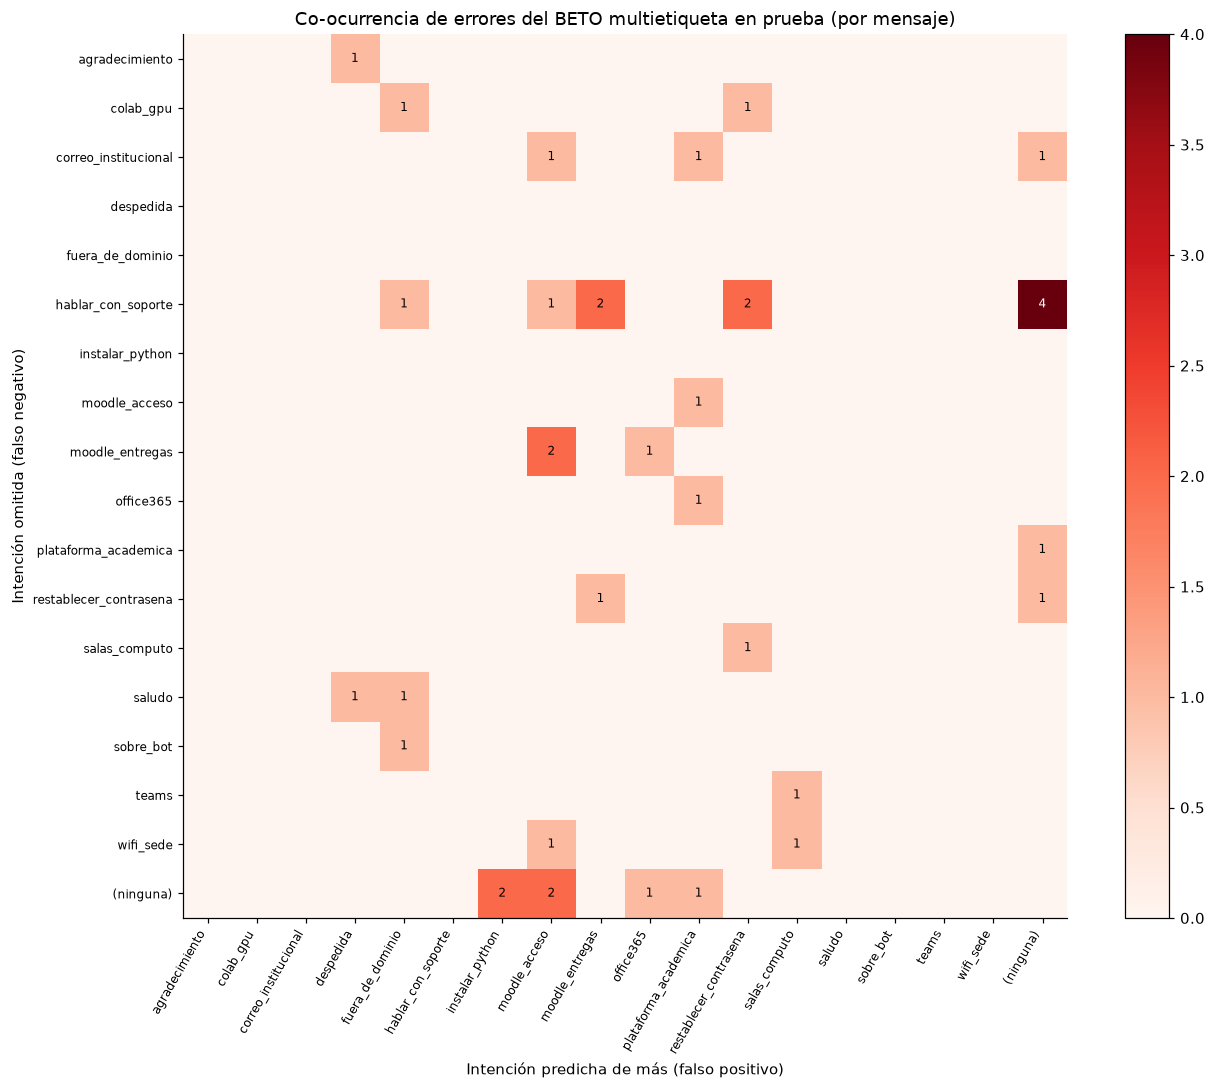

,v1 top-1,BETO multietiqueta,soporte
restablecer_contrasena,0.0000,0.7273,10
hablar_con_soporte,0.2500,0.5556,13
agradecimiento,0.5000,0.8000,3
plataforma_academica,0.5455,0.8000,11
wifi_sede,0.5882,0.9091,12
moodle_acceso,0.6316,0.6667,9
salas_computo,0.6316,0.8800,12
fuera_de_dominio,0.6667,0.6667,4
office365,0.7000,0.8889,13
moodle_entregas,0.7500,0.6667,9


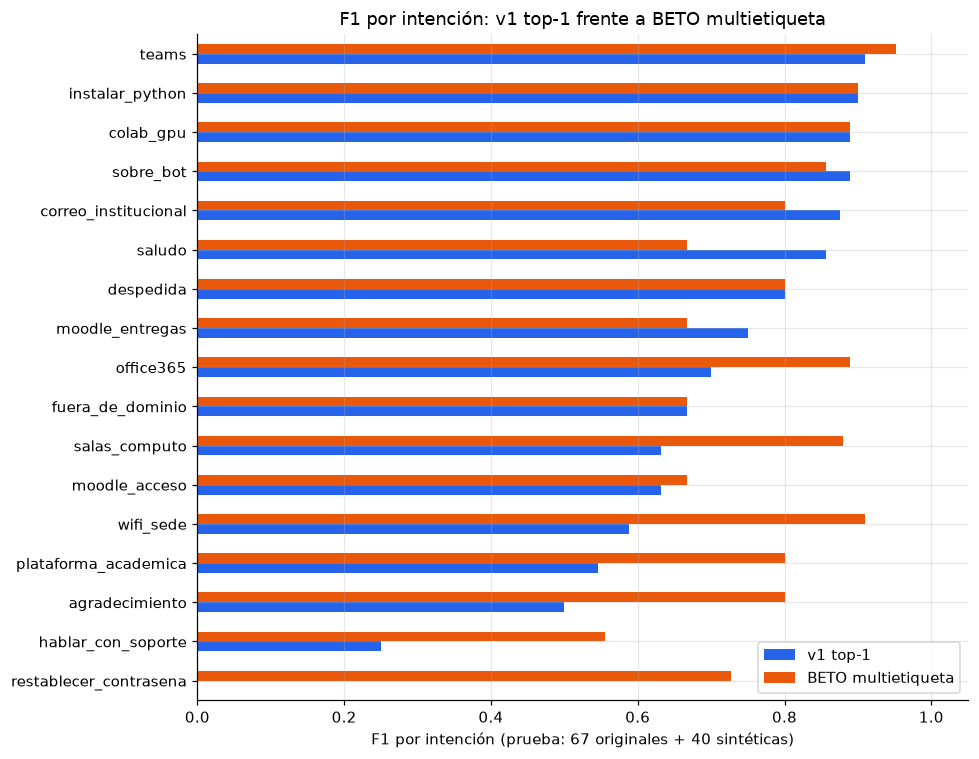

In [47]:
# ---------- Figuras: co-ocurrencia de errores y F1 por intención (prueba) ----------
Y_prueba = Y_de(CONJUNTOS_ML["prueba"]["intenciones"].tolist()).astype(bool)
Pr_multi_prueba = PRED_ML[("prueba", "BETO multietiqueta")]
Pr_v1_prueba = PRED_ML[("prueba", "v1 top-1")]
nombres_ext = ETIQUETAS + ["(ninguna)"]
co = np.zeros((NUM_LABELS + 1, NUM_LABELS + 1), dtype=int)     # fila: intención omitida; columna: intención sobrante
for y, p in zip(Y_prueba, Pr_multi_prueba):
    omitidas, sobrantes = list(np.where(y & ~p)[0]), list(np.where(p & ~y)[0])
    for i in (omitidas or [NUM_LABELS]):
        for j in (sobrantes or [NUM_LABELS]):
            if i != NUM_LABELS or j != NUM_LABELS:
                co[i, j] += 1
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(co, cmap="Reds"); ax.grid(False)
ax.set_xticks(range(NUM_LABELS + 1)); ax.set_xticklabels(nombres_ext, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(NUM_LABELS + 1)); ax.set_yticklabels(nombres_ext, fontsize=8)
for i in range(NUM_LABELS + 1):
    for j in range(NUM_LABELS + 1):
        if co[i, j]:
            ax.text(j, i, co[i, j], ha="center", va="center", fontsize=8, color="white" if co[i, j] > co.max() / 2 else "black")
ax.set_xlabel("Intención predicha de más (falso positivo)"); ax.set_ylabel("Intención omitida (falso negativo)")
ax.set_title("Co-ocurrencia de errores del BETO multietiqueta en prueba (por mensaje)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig18_coocurrencia_errores.png"), bbox_inches="tight"); plt.show()

f1_clase = pd.DataFrame({
    "v1 top-1": f1_score(Y_prueba, Pr_v1_prueba, average=None, labels=list(range(NUM_LABELS)), zero_division=0),
    "BETO multietiqueta": f1_score(Y_prueba, Pr_multi_prueba, average=None, labels=list(range(NUM_LABELS)), zero_division=0),
    "soporte": Y_prueba.sum(axis=0)}, index=ETIQUETAS).round(4)
display(f1_clase.sort_values("v1 top-1"))
ax = f1_clase[["v1 top-1", "BETO multietiqueta"]].sort_values("v1 top-1").plot(kind="barh", figsize=(9, 7), color=[COLOR_1, COLOR_2])
ax.set_xlim(0, 1.05); ax.set_xlabel("F1 por intención (prueba: 67 originales + 40 sintéticas)")
ax.set_title("F1 por intención: v1 top-1 frente a BETO multietiqueta")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig19_f1_clase_v1_vs_multietiqueta.png"), bbox_inches="tight"); plt.show()

## 13. Calibración de la v1 con *temperature scaling*
Se aprende un único parámetro T > 0 que divide los logits de la v1 (Guo et al., 2017) minimizando la pérdida logarítmica en **validación**; la predicción top-1 no cambia, solo la confianza. Se reporta el ECE (15 intervalos) antes y después en validación y en prueba.

Temperatura aprendida en validación: T = 1.0461


,validación,prueba
ECE antes,0.0657,0.1442
ECE después,0.0652,0.1411


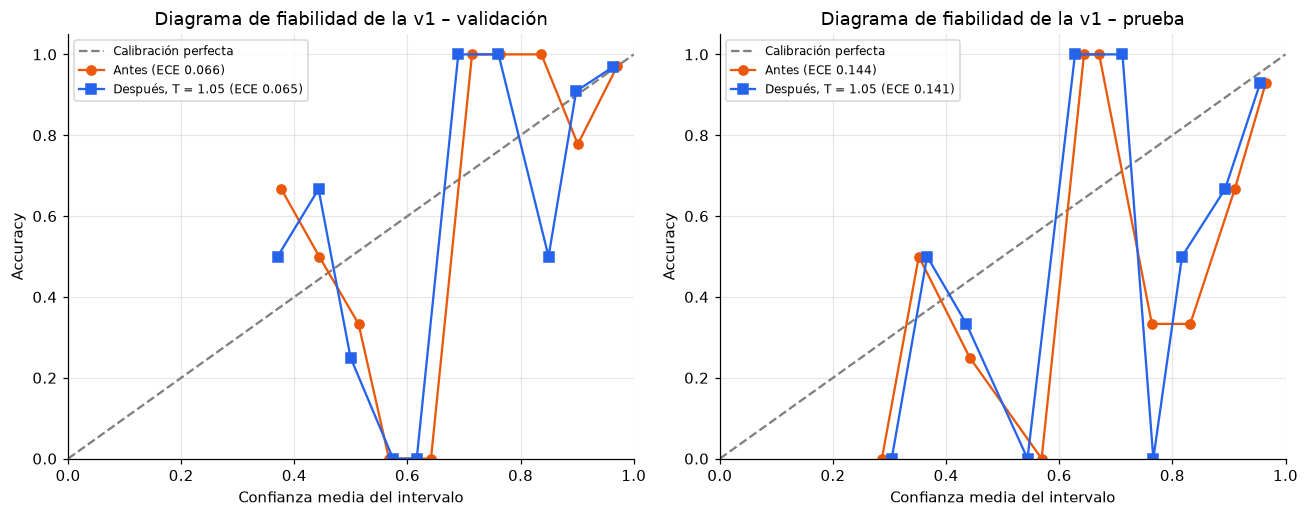

In [48]:
# ---------- Temperature scaling de la v1 ----------
def ajustar_temperatura(probs, reales):
    logp = torch.log(torch.tensor(probs, dtype=torch.float64).clamp_min(1e-12))   # log-softmax = logits − constante
    y = torch.tensor(np.asarray(reales))
    log_t = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def cierre():
        opt.zero_grad(); perdida = F.cross_entropy(logp / log_t.exp(), y); perdida.backward(); return perdida
    opt.step(cierre)
    return float(log_t.exp())

def aplicar_temperatura(probs, T):
    return torch.softmax(torch.log(torch.tensor(probs, dtype=torch.float64).clamp_min(1e-12)) / T, dim=-1).numpy()

T_V1 = ajustar_temperatura(val_probs, val_reales)
calib = {}
for nombre_c, (P, y) in {"validación": (val_probs, val_reales), "prueba": (test_probs, test_reales)}.items():
    antes, curva_a = ece_y_curva(P, y)
    despues, curva_d = ece_y_curva(aplicar_temperatura(P, T_V1), y)
    calib[nombre_c] = {"ece_antes": antes, "ece_despues": despues, "curva_antes": curva_a, "curva_despues": curva_d}
print(f"Temperatura aprendida en validación: T = {T_V1:.4f}")
display(pd.DataFrame({c: {"ECE antes": v["ece_antes"], "ECE después": v["ece_despues"]} for c, v in calib.items()}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (nombre_c, v) in zip(axes, calib.items()):
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
    ax.plot(v["curva_antes"]["confianza_media"], v["curva_antes"]["accuracy"], "o-", color=COLOR_2, label=f"Antes (ECE {v['ece_antes']:.3f})")
    ax.plot(v["curva_despues"]["confianza_media"], v["curva_despues"]["accuracy"], "s-", color=COLOR_1, label=f"Después, T = {T_V1:.2f} (ECE {v['ece_despues']:.3f})")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.05); ax.set_xlabel("Confianza media del intervalo"); ax.set_ylabel("Accuracy")
    ax.set_title(f"Diagrama de fiabilidad de la v1 – {nombre_c}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig17_calibracion_temperatura.png"), bbox_inches="tight"); plt.show()

## 14. Respuesta con varias intenciones
El bot responde cada intención detectada por el BETO multietiqueta en el orden en que aparece en el mensaje (máximo 3). El orden se obtiene de la segmentación por conectores: cada intención se ubica en el primer segmento donde la v1 la reconoce; las que no se ubican van al final, por probabilidad. Cada intención técnica se responde con los primeros pasos de su guía y su fuente; los pasos con `[COMPLETAR]` se omiten y se remite a la mesa de ayuda. Si ninguna intención supera su umbral, el bot pide aclaración entre las dos más probables. La memoria de estado (pasos siguientes, *slots*) se agrega en la Fase 4.

In [49]:
# ---------- Respuesta multiintención ----------
TEMA_INTENCION = {
    "moodle_acceso": "Sobre el ingreso a Moodle", "moodle_entregas": "Sobre la entrega en Moodle",
    "correo_institucional": "Sobre el correo institucional", "restablecer_contrasena": "Sobre tu contraseña",
    "wifi_sede": "Sobre el Wi-Fi de la sede", "teams": "Sobre Teams", "office365": "Sobre Office 365 y OneDrive",
    "instalar_python": "Sobre la instalación de Python", "colab_gpu": "Sobre Google Colab",
    "plataforma_academica": "Sobre la plataforma institucional", "salas_computo": "Sobre las salas de cómputo",
    "hablar_con_soporte": "Sobre el contacto con soporte"}
PASOS_POR_RESPUESTA = 3

def texto_intencion(intent, mensaje):
    if intent in INTENCIONES_SOCIALES:
        if intent == "fuera_de_dominio" and any(t in _norm(mensaje) for t in RESPUESTAS_FIJAS["terminos_tramite"]):
            return RESPUESTAS_FIJAS["respuestas"]["fuera_de_dominio_tramite"]
        return RESPUESTAS_FIJAS["respuestas"][intent]
    g = GUIAS_V3[intent]
    pasos = [p for p in g["pasos"] if MARCADOR_COMPLETAR not in p][:PASOS_POR_RESPUESTA]
    fuente = next((r for r in g["referencias"] if MARCADOR_COMPLETAR not in r["titulo"] + r["url"]), None)
    texto = f"{TEMA_INTENCION[intent]}: " + " ".join(f"{i}) {p}" for i, p in enumerate(pasos, start=1))
    if any(MARCADOR_COMPLETAR in p for p in g["pasos"][:PASOS_POR_RESPUESTA + 1]):
        texto += f" {CONTACTO_POR_DEFECTO}"
    if fuente:
        texto += f" (Fuente: {fuente['titulo']}, {fuente['url']})"
    return texto

def responder_multi(mensaje):
    P = probs_multi(model_multi, [mensaje])[0]
    supera = np.where(P >= UMBRALES_MULTI)[0]
    if len(supera) == 0:
        a, b = np.argsort(-P)[:2]
        return {"intenciones": [], "respuesta": f"¿Te refieres a 1) {id2label[int(a)]} o 2) {id2label[int(b)]}?"}
    elegidas = list(supera[np.argsort(-P[supera])][:3])
    _, ordenes = predecir_segmentacion([mensaje], devolver_orden=True)
    posicion = {e: i for i, e in enumerate(ordenes[0])}
    elegidas.sort(key=lambda e: (posicion.get(e, 99), -P[e]))
    return {"intenciones": [id2label[int(e)] for e in elegidas],
            "respuesta": "\n".join(texto_intencion(id2label[int(e)], mensaje) for e in elegidas)}

for mensaje in sint_val["texto"].head(3).tolist() + val_orig["texto"].head(2).tolist():
    r = responder_multi(mensaje)
    print(f"\n👤 {mensaje}\n   intenciones: {r['intenciones']}\n🤖 {r['respuesta']}")


👤 como conecto colab a un repositorio de github y pongo usuario y clave y vuelve a la pagina de login
   intenciones: ['colab_gpu', 'moodle_entregas', 'office365']
🤖 Sobre Google Colab: 1) Abre el notebook y ve a Entorno de ejecución → Cambiar tipo de entorno de ejecución → elige GPU (T4 en la versión gratuita) y guarda. 2) Comprueba que la GPU está activa ejecutando «!nvidia-smi» o, en PyTorch, «torch.cuda.is_available()». 3) Si Colab indica que no hay GPU disponible o alcanzaste el límite de uso, trabaja en CPU mientras tanto o intenta más tarde; los recursos gratuitos no están garantizados. (Fuente: Preguntas frecuentes de Colaboratory – Google Research, https://research.google.com/colaboratory/faq.html)
Sobre la entrega en Moodle: 1) Abre la actividad y revisa la fecha de cierre, el tipo de archivo permitido y el tamaño máximo que indica el docente. 2) Pulsa «Agregar entrega», arrastra o selecciona el archivo y espera a que termine la carga antes de pulsar «Guardar cambios». 3) Si

In [50]:
# ---------- Resultados de la versión v2 ----------
TIEMPO_FASE3 = time.time() - T_INICIO_FASE3
RESULTADOS_V2 = {
    "version": "v2 — multiintención y calibración (Fase 3)",
    "reetiquetado": {"frases_reetiquetadas": int(ml_df["intenciones"].str.contains(r"[|]").sum()),
                     "guia": "guia_anotacion_multietiqueta.md"},
    "sinteticas": {"n": {"train": len(sint_train), "val": len(sint_val), "test": len(sint_test)}, "filtros": reporte_sint,
                   "conectores": [c for c, _ in CONECTORES]},
    "beto_multietiqueta": {"mejor_epoca": mejor_multi["epoca"], "epocas_ejecutadas": len(hist_multi["val_loss"]),
                           "val_f1_micro_umbral_05": round(mejor_multi["val_f1_micro"], 4),
                           "val_f1_micro_umbrales": round(float(f1_val_umbrales), 4), "n_train": mejor_multi["n_train"],
                           "learning_rate": HP["learning_rate"], "umbral_comun": UMBRAL_COMUN,
                           "umbrales": dict(zip(ETIQUETAS, map(float, UMBRALES_MULTI))),
                           "umbral_propio": dict(zip(ETIQUETAS, map(bool, UMBRAL_PROPIO)))},
    "evaluacion": json.loads(tabla_ml.to_json(orient="records")),
    "prueba_externa_evaluada": bool(EXTERNO_LIMPIO),
    "validacion_cruzada_multietiqueta": {"por_particion": json.loads(cv_ml.to_json(orient="records")), "resumen": cv_ml_resumen},
    "f1_por_intencion_prueba": json.loads(f1_clase.to_json(orient="index")),
    "temperature_scaling_v1": {"T": round(T_V1, 4), **{c: {"ece_antes": round(v["ece_antes"], 4), "ece_despues": round(v["ece_despues"], 4)}
                                                        for c, v in calib.items()}},
    "tiempos_s": {"beto_multietiqueta": round(tiempo_multi, 1), "validacion_cruzada_multietiqueta": round(tiempo_cv_ml, 1),
                  "fase3_total": round(TIEMPO_FASE3, 1), "notebook_total": round(time.time() - T_INICIO_NOTEBOOK, 1)},
    "historial_multietiqueta": {k: [round(v, 4) for v in vals] for k, vals in hist_multi.items()},
}
# Los resultados de la v2 de referencia (resultados_soporte_v2.json, copia en fase3_concatenadas/) no se sobrescriben.
RUTA_V2 = os.path.join(BASE_DIR, "resultados_soporte_v2.json")
ruta_resultados_v2 = os.path.join(BASE_DIR, "resultados_soporte_v2_reejecucion.json") if os.path.exists(RUTA_V2) else RUTA_V2
with open(ruta_resultados_v2, "w", encoding="utf-8") as f:
    json.dump(RESULTADOS_V2, f, ensure_ascii=False, indent=2, default=float)
print("Resultados guardados en", ruta_resultados_v2)
print("Tiempos (s):", RESULTADOS_V2["tiempos_s"])

Resultados guardados en soportic\resultados_soporte_v2_reejecucion.json
Tiempos (s): {'beto_multietiqueta': 101.3, 'validacion_cruzada_multietiqueta': 575.7, 'fase3_total': 683.6, 'notebook_total': 2656.3}


### Interpretación de la v2 (ejecución del 2026-11-14, RTX 5050; cifras de `soportic/fase3_concatenadas/resultados_soporte_v2.json`)

- **Prueba (107 mensajes: 67 originales de una intención y 40 sintéticos de dos).** Exact match: v1 top-1 0,4766, segmentación + v1 0,6729 y BETO multietiqueta 0,6729. F1 micro: 0,6850, 0,7667 y 0,8000; Hamming loss: 0,0440, 0,0385 y 0,0324. En los 40 mensajes de dos intenciones, la exactitud es 0,0, 0,55 y 0,50; en los 67 de una intención, 0,7612, 0,7463 y 0,7761. El multietiqueta y la segmentación empatan en exact match: la segmentación acierta más mensajes de dos intenciones y el multietiqueta más de una, con mejor F1 y Hamming.
- **Generalización (68 frases de una intención).** Exact match 0,8824 para la v1 y la segmentación, y 0,8971 para el multietiqueta (F1 macro 0,9192).
- **Validación cruzada del multietiqueta (5 particiones).** Exact match 0,6246 ± 0,0488, F1 micro 0,7666 ± 0,0337, F1 macro 0,7672 ± 0,0363, Hamming 0,0365 ± 0,0056, exactitud en una intención 0,7602 ± 0,0245 y en dos o más 0,3250 ± 0,1275. La exactitud en dos intenciones varía entre 0,175 y 0,475 según la partición; la cifra de prueba (0,50) queda por encima de ese intervalo.
- **F1 por intención en prueba (v1 → multietiqueta).** `restablecer_contrasena` pasa de 0,0 a 0,7273, `wifi_sede` de 0,5882 a 0,9091, `salas_computo` de 0,6316 a 0,88 y `hablar_con_soporte` de 0,25 a 0,5556; bajan `saludo` (0,8571 → 0,6667) y `moodle_entregas` (0,75 → 0,6667).
- **Calibración.** La temperatura aprendida en validación es T = 1,0461, casi 1: el ECE de validación pasa de 0,0657 a 0,0652 y el de prueba de 0,1442 a 0,1411. El *temperature scaling* casi no cambió el ECE porque la v1 ya estaba calibrada en validación, el conjunto donde se aprende T. El ECE de prueba duplica el de validación: la sobreconfianza aparece en datos que no intervinieron en el *early stopping* ni en el ajuste de T, y una temperatura única no la corrige.
- **Limitación.** Las frases sintéticas de prueba usan los mismos conectores que reconoce la segmentación, lo que favorece a ese método en la prueba sintética; la prueba externa, con 30 mensajes naturales de varias intenciones, no se usó en la v2.

# Fase 3b — Mejora de la multiintención (versión v2b)

**Nota de diseño.** Esta mejora se diseñó **después de ver los resultados de prueba de la v2** (sección 12). Por eso la prueba interna ya no es evidencia independiente: la evidencia principal de la v2b es la **validación cruzada de 5 particiones** y la **prueba externa**, que no se había usado con ningún modelo de multiintención. Todas las decisiones (piso de umbral y método final) se toman con validación y validación cruzada; la elección se escribe antes de calcular la prueba, y el externo se evalúa una sola vez, al final, con el método elegido.

Cambios respecto de la v2:
1. **Más frases concatenadas de dos intenciones** dentro de cada partición: 600 de entrenamiento (todas las parejas de las 12 intenciones técnicas, de forma equilibrada), 80 de validación y 80 de prueba, con 12 estructuras: los 6 conectores de la v2 más «y aparte», «. ah y», «. por otro lado,», «. ademas,», una pregunta seguida de una afirmación y dos frases unidas con coma sin conector. Cada intención puede ir en primer o en segundo lugar (orden invertido).
2. **Frases de dos intenciones redactadas por Qwen2.5-3B-Instruct** a partir de pares de frases reales de la misma partición: 300 de entrenamiento, 40 de validación y 40 de prueba (`origen = "qwen_dos_intenciones"`).
3. **Negativos con conector**: dos frases de la misma intención unidas con un conector (150 de entrenamiento y 30 de validación), para que el modelo no asigne una segunda intención solo por ver «y».
4. **Piso de umbral**: umbrales por intención con piso de 0,30 frente a sin piso, elegido por exact match de validación.
5. **Método combinado**: si la segmentación por conectores da 2 o más segmentos, el multietiqueta clasifica cada segmento (top-1 del segmento más cualquier intención que supere su umbral) y se unen; con un segmento, el multietiqueta decide sobre el mensaje completo.
6. **Ensamble**: p = ½·p(mensaje completo) + ½·máx. sobre segmentos de p(segmento), con umbrales propios elegidos en validación.
7. **Tasa de falsos positivos de multiintención**: proporción de mensajes de una intención a los que el método asigna dos o más.

Las decisiones tomadas sin los autores están en `DECISIONES.md`.

## 15. Datos de la v2b: concatenadas, frases de Qwen y negativos con conector
**Frases de Qwen.** Se pide a Qwen2.5-3B-Instruct (bf16; si no hay memoria, Qwen2.5-1.5B-Instruct) que una dos problemas en **una oración natural**, como la escribiría un estudiante, conservando los dos problemas. El prompt se ajustó una vez con 4 pares inventados (ninguno del dataset), porque la primera versión copiaba la estructura del ejemplo y a veces respondía en portugués; después se fijó y no se modificó al ver datos ni resultados. Se descartan las salidas en portugués. Filtros, en orden (el 1b se fijó el 2026-11-14 a las 22:40, antes de ver resultados de la v2b, al notar que Qwen a veces agrega un tercer problema; se aplica sobre la caché, sin regenerar):
1. **Conservación de los dos problemas.** En entrenamiento: las dos intenciones esperadas deben estar entre las 3 más probables de la v1 congelada aplicada a la frase generada. En validación y prueba no se usa ningún modelo de los que se comparan (evita sesgar la evaluación a su favor): la similitud MiniLM entre la frase generada y **cada** frase origen debe ser ≥ 0,50 (umbral fijado antes de generar).
1b. **Sin tercer problema.** En entrenamiento: la v1 congelada no puede dar a una tercera intención técnica (distinta de las dos esperadas) una probabilidad ≥ 0,30. En validación y prueba (sin modelos comparados): la frase no puede mencionar un servicio (moodle, correo, wifi, teams, office, python, colab, plataforma, sala, contraseña, soporte; con sus sinónimos fijos) que no esté en ninguna de sus dos frases de origen.
2. **Duplicados** normalizados con el dataset y entre todas las frases generadas.
3. **Anti-fuga** (MiniLM ≥ 0,90): las de entrenamiento contra validación, prueba, generalización, la prueba externa y la prueba aparte de MASSIVE; las de validación y prueba, además, contra el entrenamiento (original y aumento).

Las generaciones de Qwen se guardan en una caché (`qwen_generaciones_cache.csv`, clave: par de frases origen); los filtros se recalculan en cada ejecución. Con la caché, el notebook no necesita cargar Qwen (ruta de Colab).

In [51]:
# ---------- Generadores de la v2b ----------
T_INICIO_V2B = time.time()
CONECTORES_V2B = CONECTORES + [
    ("y aparte", lambda a, b: f"{a} y aparte {b}"), ("ah y", lambda a, b: f"{a}. ah y {b}"),
    ("por otro lado", lambda a, b: f"{a}. por otro lado, {b}"), ("ademas", lambda a, b: f"{a}. ademas, {b}"),
    ("pregunta y afirmacion", lambda a, b: f"{a}? {b}"), ("coma sin conector", lambda a, b: f"{a}, {b}")]
N_CONCAT_V2B = {"train": 600, "val": 80, "test": 80}
N_QWEN = {"train": 300, "val": 40, "test": 40}
N_NEG = {"train": 150, "val": 30}
SIM_QWEN_ORIGEN_MIN = 0.50          # validación y prueba: similitud mínima con cada frase origen (fijada antes de generar)
TOPK_FILTRO_V1 = 3                  # entrenamiento: las dos intenciones entre las 3 más probables de la v1 congelada
# Filtros adicionales fijados antes de ver resultados de la v2b (DECISIONES.md n.º 19): Qwen a veces agrega un tercer problema
P_TERCERA_MAX = 0.30                # entrenamiento: ninguna tercera intención técnica con probabilidad ≥ 0,30 en la v1 congelada
SERVICIOS_QWEN = {"moodle": r"\bmoodle\b|\baula virtual\b", "correo": r"\bcorreos?\b|\boutlook\b",
                  "wifi": r"\bwi-?fi\b|\bred\b|\binternet\b", "teams": r"\bteams\b",
                  "office": r"\boffice\b|\bword\b|\bexcel\b|\bpowerpoint\b|\bonedrive\b",
                  "python": r"\bpython\b|\bpip\b|\banaconda\b|\bjupyter\b", "colab": r"\bcolab\b",
                  "plataforma": r"\bplataforma\b|\bacademusoft\b", "sala": r"\bsalas?\b",
                  "contraseña": r"\bcontrasenas?\b|\bclaves?\b", "soporte": r"\bsoporte\b|\bmesa de ayuda\b"}

def servicios_en(texto):
    t = "".join(ch for ch in unicodedata.normalize("NFD", str(texto).lower()) if unicodedata.category(ch) != "Mn")
    return {k for k, patron in SERVICIOS_QWEN.items() if re.search(patron, t)}

def flujo_parejas(fuente, misma_intencion, semilla):
    """Generador infinito de (frase_a, int_a, frase_b, int_b) equilibrado entre parejas de intenciones técnicas:
    en cada ronda se recorren todas las parejas en orden aleatorio y el orden de las dos intenciones se invierte al azar."""
    rng = np.random.default_rng(semilla)
    f = fuente[fuente["intencion"].isin(INTENCIONES_TECNICAS)]
    por_int = {k: g["texto"].tolist() for k, g in f.groupby("intencion")}
    claves = sorted(por_int)
    parejas = ([(a, a) for a in claves if len(por_int[a]) >= 2] if misma_intencion
               else [(a, b) for a in claves for b in claves if a < b])
    while True:
        for k in rng.permutation(len(parejas)):
            ia, ib = parejas[k] if rng.random() < 0.5 else parejas[k][::-1]
            ta = por_int[ia][rng.integers(len(por_int[ia]))]
            tb = por_int[ib][rng.integers(len(por_int[ib]))]
            if ta != tb:
                yield ta, ia, tb, ib

class FiltroFuga:
    """Anti-fuga MiniLM (≥ 0,90) contra un conjunto de frases reservadas, más duplicados normalizados."""
    def __init__(self, reservadas, claves_excluidas):
        self.emb = embeber(list(reservadas)) if len(reservadas) else None
        self.claves = set(claves_excluidas)
    def motivo(self, texto, emb_texto=None):
        clave = clave_normalizada(texto)
        if clave in self.claves:
            return "duplicado"
        if self.emb is not None:
            e = embeber([texto]) if emb_texto is None else emb_texto.unsqueeze(0)
            if float(util.cos_sim(e, self.emb).max()) >= SIM_FUGA_MAX:
                return "anti-fuga"
        self.claves.add(clave)
        return ""

def generar_combinadas_v2b(fuente, n, filtro, semilla, misma_intencion=False):
    """Concatenadas de dos intenciones (o negativos de una intención) con las 12 estructuras de la v2b."""
    flujo, filas, usadas, reporte = flujo_parejas(fuente, misma_intencion, semilla), [], set(), Counter()
    for _ in range(80 * n):
        if len(filas) >= n:
            break
        ta, ia, tb, ib = next(flujo)
        if (ta, tb) in usadas:
            reporte["par repetido"] += 1; continue
        usadas.add((ta, tb))
        nombre_c, unir = CONECTORES_V2B[len(filas) % len(CONECTORES_V2B)]
        texto = unir(_limpia(ta), _limpia(tb))
        m = filtro.motivo(texto)
        if m:
            reporte[m] += 1; continue
        filas.append({"texto": texto, "intenciones": ia if misma_intencion else f"{ia}|{ib}", "conector": nombre_c,
                      "frase_1": ta, "frase_2": tb,
                      "origen": "negativo_conector" if misma_intencion else "concatenada_v2b"})
    reporte["conservadas"] = len(filas)
    return pd.DataFrame(filas, columns=["texto", "intenciones", "conector", "frase_1", "frase_2", "origen"]), dict(reporte)

def pares_qwen(fuente, n, semilla):
    """n pares de frases de distinta intención técnica (equilibrados), candidatos para Qwen."""
    flujo, pares, vistos = flujo_parejas(fuente, False, semilla), [], set()
    for _ in range(80 * n):
        if len(pares) >= n:
            break
        ta, ia, tb, ib = next(flujo)
        if (ta, tb) not in vistos:
            vistos.add((ta, tb)); pares.append((ta, ia, tb, ib))
    return pares

In [52]:
# ---------- Qwen: generación con caché ----------
RUTA_CACHE_QWEN = os.path.join(DATA_DIR, "qwen_generaciones_cache.csv")
QWEN_MODELOS = ["Qwen/Qwen2.5-3B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"]
QWEN_SISTEMA = ("Eres un estudiante universitario colombiano que escribe en el chat de la mesa de ayuda de su universidad. "
                "Escribes en español, en minúsculas, de forma informal y breve, sin saludar.")
def prompt_qwen(a, b):
    return ("Une estos dos problemas en UNA sola oración natural, en español de Colombia, como la escribirías en el chat. "
            "Conserva los dos problemas, no agregues problemas nuevos, no expliques nada y responde solo con la oración. "
            "Varía la forma de unirlos.\n\n"
            "Ejemplos:\n"
            "Problema 1: cambie la clave del correo\nProblema 2: teams no me abre\n"
            "Oración: desde que cambie la clave del correo tampoco me abre teams\n\n"
            "Problema 1: no encuentro donde subir el taller en moodle\nProblema 2: la impresora de la sala no imprime\n"
            "Oración: no encuentro donde subir el taller en moodle y encima la impresora de la sala no imprime\n\n"
            "Problema 1: excel dice que no tiene licencia\nProblema 2: no me llegan los correos de los profes\n"
            "Oración: aparte de que excel me sale sin licencia, tampoco me estan llegando los correos de los profes\n\n"
            f"Problema 1: {_limpia(a)}\nProblema 2: {_limpia(b)}\nOración:")

PORTUGUES = re.compile(r"[ãõç]|\bnão\b|\btambém\b|\bminha\b|\bvocê\b")      # Qwen a veces responde en portugués
def _limpia_qwen(t):
    t = str(t).strip().split("\n")[0]
    t = re.sub(r"^(oraci[oó]n|respuesta)\s*:\s*", "", t, flags=re.I)
    return t.strip(" \"'«»“”").strip()

cache_qwen = (pd.read_csv(RUTA_CACHE_QWEN, keep_default_na=False) if os.path.exists(RUTA_CACHE_QWEN)
              else pd.DataFrame(columns=["frase_1", "frase_2", "texto_qwen", "modelo"]))
CACHE_QWEN = {(a, b): t for a, b, t in zip(cache_qwen["frase_1"], cache_qwen["frase_2"], cache_qwen["texto_qwen"])}
QWEN_INFO = {"generadas_en_esta_ejecucion": 0, "modelo": sorted(set(cache_qwen["modelo"])) if len(cache_qwen) else [],
             "tiempo_generacion_s": 0.0}

# Con la caché presente no se vuelve a generar: los pares que no estén en ella se descartan («vacía»). Para regenerar:
# variable de entorno SOPORTIC_REGENERAR_QWEN=1.
QWEN_SOLO_CACHE = len(CACHE_QWEN) > 0 and os.environ.get("SOPORTIC_REGENERAR_QWEN", "0") != "1"

def generar_qwen(pares, lote=16):
    """Genera con Qwen los pares que no están en la caché. Mueve los BETO y MiniLM a la CPU mientras tanto."""
    faltan = [(a, b) for a, b in dict.fromkeys(pares) if (a, b) not in CACHE_QWEN]
    if not faltan or QWEN_SOLO_CACHE:
        return
    t0 = time.time()
    modelos_gpu = [m for m in (globals().get("model"), globals().get("model_multi")) if m is not None]
    for m in modelos_gpu:
        m.to("cpu")
    encoder_sem.to("cpu"); liberar_gpu()
    modelo_q = tok_q = nombre_q = None
    for nombre in QWEN_MODELOS:
        try:
            dtype = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
            tok_q = AutoTokenizer.from_pretrained(nombre, padding_side="left")
            modelo_q = AutoModelForCausalLM.from_pretrained(nombre, dtype=dtype).to(DEVICE).eval()
            nombre_q = nombre; break
        except (torch.cuda.OutOfMemoryError, RuntimeError) as error:
            print(f"No se pudo cargar {nombre} ({type(error).__name__}); se prueba el siguiente.")
            modelo_q = None; liberar_gpu()
    print(f"Qwen: {nombre_q} | pares por generar: {len(faltan)}")
    nuevas = []
    torch.manual_seed(SEED)
    def generar_lote(b):
        """Genera un lote; si la GPU se queda sin memoria, lo divide en dos."""
        chats = [tok_q.apply_chat_template([{"role": "system", "content": QWEN_SISTEMA},
                                            {"role": "user", "content": prompt_qwen(x, y)}],
                                           tokenize=False, add_generation_prompt=True) for x, y in b]
        try:
            enc = tok_q(chats, return_tensors="pt", padding=True).to(DEVICE)
            with torch.no_grad():
                out = modelo_q.generate(**enc, max_new_tokens=60, do_sample=True, temperature=0.8, top_p=0.9,
                                        pad_token_id=tok_q.eos_token_id)
            return tok_q.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        except torch.cuda.OutOfMemoryError:
            liberar_gpu()
            if len(b) == 1:
                raise
            return generar_lote(b[:len(b) // 2]) + generar_lote(b[len(b) // 2:])
    for i in range(0, len(faltan), lote):
        b = faltan[i:i + lote]
        textos = generar_lote(b)
        for (x, y), t in zip(b, textos):
            CACHE_QWEN[(x, y)] = _limpia_qwen(t)
            nuevas.append({"frase_1": x, "frase_2": y, "texto_qwen": CACHE_QWEN[(x, y)], "modelo": nombre_q})
    modelo_q = None; liberar_gpu()
    for m in modelos_gpu:
        m.to(DEVICE)
    encoder_sem.to(DEVICE)
    pd.concat([pd.read_csv(RUTA_CACHE_QWEN, keep_default_na=False) if os.path.exists(RUTA_CACHE_QWEN) else None,
               pd.DataFrame(nuevas)]).to_csv(RUTA_CACHE_QWEN, index=False)
    QWEN_INFO["generadas_en_esta_ejecucion"] += len(nuevas)
    QWEN_INFO["modelo"] = sorted(set(QWEN_INFO["modelo"]) | {nombre_q})
    QWEN_INFO["tiempo_generacion_s"] += time.time() - t0
    print(f"Qwen: {len(nuevas)} frases generadas en {time.time() - t0:.0f} s")

# v1 congelada para el filtro de entrenamiento (si no está, la v1 de esta ejecución, que la reproduce)
RUTA_BETO_V1_CONGELADO = os.path.join(BASE_DIR, "v1_congelada", "modelo_bert_intenciones")
def probs_v1_congelada(textos):
    if not textos:
        return np.zeros((0, NUM_LABELS))
    if os.path.isdir(RUTA_BETO_V1_CONGELADO):
        m = AutoModelForSequenceClassification.from_pretrained(RUTA_BETO_V1_CONGELADO).to(DEVICE).eval()
        _, _, _, _, P = evaluar(m, DataLoader(a_dataset([normalizar_texto(t) for t in textos], [0] * len(textos)), batch_size=64))
        del m; liberar_gpu()
        return P
    return probs_v1(textos)

def filtrar_qwen(pares, particion, n, filtro):
    """Aplica los filtros (1) conservación, (2) duplicados y (3) anti-fuga a las generaciones de Qwen de 'pares'."""
    cands = [(a, ia, b, ib, CACHE_QWEN.get((a, b), "")) for a, ia, b, ib in pares]
    reporte, filas = Counter(), []
    validas = [c for c in cands if c[4] and 4 <= len(c[4].split()) <= 45 and not PORTUGUES.search(c[4].lower())
               and clave_normalizada(c[4]) not in {clave_normalizada(c[0]), clave_normalizada(c[2])}]
    reporte["vacía, muy corta/larga, en otro idioma o igual a un origen"] = len(cands) - len(validas)
    if particion == "train":
        P = probs_v1_congelada([c[4] for c in validas])
        top = np.argsort(-P, axis=1)[:, :TOPK_FILTRO_V1] if len(validas) else np.zeros((0, TOPK_FILTRO_V1), int)
        conserva = [label2id[c[1]] in top[i] and label2id[c[3]] in top[i] for i, c in enumerate(validas)]
        motivo_1 = f"(1) v1 congelada: alguna intención fuera del top-{TOPK_FILTRO_V1}"
        tecnicas = [label2id[t] for t in INTENCIONES_TECNICAS]
        conserva_b = [not any(P[i, j] >= P_TERCERA_MAX for j in tecnicas if j not in (label2id[c[1]], label2id[c[3]]))
                      for i, c in enumerate(validas)]
        motivo_1b = f"(1b) v1 congelada: tercera intención técnica ≥ {P_TERCERA_MAX}"
    else:
        if validas:
            e_g, e_a, e_b = embeber([c[4] for c in validas]), embeber([c[0] for c in validas]), embeber([c[2] for c in validas])
            s_a, s_b = (e_g * e_a).sum(-1).cpu().numpy(), (e_g * e_b).sum(-1).cpu().numpy()
        conserva = [bool(s_a[i] >= SIM_QWEN_ORIGEN_MIN and s_b[i] >= SIM_QWEN_ORIGEN_MIN) for i in range(len(validas))]
        motivo_1 = f"(1) similitud MiniLM con algún origen < {SIM_QWEN_ORIGEN_MIN}"
        conserva_b = [not (servicios_en(c[4]) - servicios_en(c[0]) - servicios_en(c[2])) for c in validas]
        motivo_1b = "(1b) menciona un servicio que no está en sus frases de origen"
    for c, ok, ok_b in zip(validas, conserva, conserva_b):
        if len(filas) >= n:
            break
        if not ok:
            reporte[motivo_1] += 1; continue
        if not ok_b:
            reporte[motivo_1b] += 1; continue
        m = filtro.motivo(c[4])
        if m:
            reporte[m] += 1; continue
        filas.append({"texto": c[4], "intenciones": f"{c[1]}|{c[3]}", "conector": "qwen", "frase_1": c[0], "frase_2": c[2],
                      "origen": "qwen_dos_intenciones"})
    reporte["conservadas"] = len(filas)
    return pd.DataFrame(filas, columns=["texto", "intenciones", "conector", "frase_1", "frase_2", "origen"]), dict(reporte)

In [53]:
# ---------- Particiones: principal y 5 pliegues de la validación cruzada ----------
def particiones_v2b():
    """Particiones de la v2b: la principal (la de la v1) y los 5 pliegues de la validación cruzada (mismos de la v2)."""
    salida = {"principal": {"tr": train_df, "va": val_orig, "va_m": val_df, "te": test_df, "aum": aumento_v1}}
    for k, (idx_trval, idx_te) in enumerate(skf.split(df, df["label"]), start=1):
        cv_trval, cv_te = df.iloc[idx_trval], df.iloc[idx_te].reset_index(drop=True)
        cv_tr, cv_va = train_test_split(cv_trval, test_size=0.15, stratify=cv_trval["label"], random_state=SEED)
        cv_tr, cv_va = cv_tr.reset_index(drop=True), cv_va.reset_index(drop=True)
        reservadas_cv = (cv_va["texto"].tolist() + cv_te["texto"].tolist() + gen_df["texto"].tolist() + FRASES_RESERVADAS
                         + (massive_prueba_df["texto"].tolist() + massive_val_df["texto"].tolist() if MASSIVE_OK else []))
        aum_cv, _ = filtrar_aumento(cv_tr, reservadas_cv, usar_referencia=False)
        aum_cv = aum_cv[aum_cv["tecnica"].isin(HP["tecnicas_aumento"])]
        cv_va_m = pd.concat([cv_va, preparar_externo(massive_val_df)], ignore_index=True) if MASSIVE_OK else cv_va
        salida[f"pliegue_{k}"] = {"tr": cv_tr, "va": cv_va, "va_m": cv_va_m, "te": cv_te, "aum": aum_cv}
    return salida

PARTES_V2B = particiones_v2b()
SEMILLA_CONJ = {nombre: SEED + 100 + 10 * i for i, nombre in enumerate(PARTES_V2B)}

# Pares candidatos para Qwen (2 por objetivo; hasta 3 rondas si los filtros dejan menos del objetivo)
FACTOR_QWEN, RONDAS_QWEN = 2, 3
def pares_ronda(nombre, ronda):
    p, s = PARTES_V2B[nombre], SEMILLA_CONJ[nombre] + 1000 * ronda
    return {"test": pares_qwen(p["te"], FACTOR_QWEN * N_QWEN["test"], s + 1),
            "val": pares_qwen(p["va"], FACTOR_QWEN * N_QWEN["val"], s + 2),
            "train": pares_qwen(p["tr"], FACTOR_QWEN * N_QWEN["train"], s + 3)}
PARES_QWEN = {nombre: pares_ronda(nombre, 0) for nombre in PARTES_V2B}
generar_qwen([(a, b) for d in PARES_QWEN.values() for ps in d.values() for a, _, b, _ in ps])

def construir_v2b(nombre):
    """Concatenadas, frases de Qwen y negativos de una partición, con los filtros anti-fuga en orden prueba → validación → entrenamiento."""
    p, s = PARTES_V2B[nombre], SEMILLA_CONJ[nombre]
    base_reservadas = (gen_df["texto"].tolist() + [f for f, _ in FRASES_EXTERNAS_TODAS]
                       + (massive_prueba_df["texto"].tolist() if MASSIVE_OK else []))
    claves_dataset = set(df["texto"].apply(clave_normalizada))
    entrenamiento = p["tr"]["texto"].tolist() + p["aum"]["texto"].astype(str).tolist()
    datos, reporte = {}, {}
    def qwen(particion, filtro):
        pares, ronda = list(PARES_QWEN[nombre][particion]), 0
        while True:
            claves_antes = set(filtro.claves)
            d, r = filtrar_qwen(pares, particion, N_QWEN[particion], filtro)
            if len(d) >= N_QWEN[particion] or ronda + 1 >= RONDAS_QWEN:
                return d, {**r, "rondas": ronda + 1, "candidatos": len(pares)}
            ronda += 1
            filtro.claves = claves_antes           # se repite el filtrado con más candidatos
            nuevos = pares_ronda(nombre, ronda)[particion]
            generar_qwen([(a, b) for a, _, b, _ in nuevos])
            pares += [x for x in nuevos if x not in set(pares)]
    # Prueba
    f_te = FiltroFuga(entrenamiento + base_reservadas, claves_dataset)
    datos["concat_te"], reporte["concat_te"] = generar_combinadas_v2b(p["te"], N_CONCAT_V2B["test"], f_te, s + 1)
    datos["qwen_te"], reporte["qwen_te"] = qwen("test", f_te)
    # Validación
    prueba_todo = p["te"]["texto"].tolist() + datos["concat_te"]["texto"].tolist() + datos["qwen_te"]["texto"].tolist()
    f_va = FiltroFuga(entrenamiento + base_reservadas + prueba_todo, f_te.claves)
    datos["concat_va"], reporte["concat_va"] = generar_combinadas_v2b(p["va"], N_CONCAT_V2B["val"], f_va, s + 2)
    datos["qwen_va"], reporte["qwen_va"] = qwen("val", f_va)
    datos["neg_va"], reporte["neg_va"] = generar_combinadas_v2b(p["va"], N_NEG["val"], f_va, s + 3, misma_intencion=True)
    # Entrenamiento
    val_todo = (p["va"]["texto"].tolist() + datos["concat_va"]["texto"].tolist() + datos["qwen_va"]["texto"].tolist()
                + datos["neg_va"]["texto"].tolist())
    f_tr = FiltroFuga(base_reservadas + prueba_todo + val_todo, f_va.claves)
    datos["concat_tr"], reporte["concat_tr"] = generar_combinadas_v2b(p["tr"], N_CONCAT_V2B["train"], f_tr, s + 4)
    datos["qwen_tr"], reporte["qwen_tr"] = qwen("train", f_tr)
    datos["neg_tr"], reporte["neg_tr"] = generar_combinadas_v2b(p["tr"], N_NEG["train"], f_tr, s + 5, misma_intencion=True)
    return datos, reporte

t_datos_v2b0 = time.time()
DATOS_V2B, REPORTE_V2B = {}, {}
for nombre in PARTES_V2B:
    DATOS_V2B[nombre], REPORTE_V2B[nombre] = construir_v2b(nombre)
tiempo_datos_v2b = time.time() - t_datos_v2b0
d0 = DATOS_V2B["principal"]
pd.concat([d.assign(particion=k.split("_")[1]) for k, d in d0.items()]).to_csv(os.path.join(DATA_DIR, "sinteticas_v2b.csv"), index=False)
pd.concat([d0["qwen_tr"].assign(particion="train"), d0["qwen_va"].assign(particion="val"),
           d0["qwen_te"].assign(particion="test")]).to_csv(os.path.join(DATA_DIR, "qwen_dos_intenciones.csv"), index=False)
print(f"Datos de la v2b construidos en {tiempo_datos_v2b:.0f} s (Qwen: {QWEN_INFO})")
display(pd.DataFrame({nombre: {k: len(v) for k, v in d.items()} for nombre, d in DATOS_V2B.items()}))
print("Filtros en la partición principal:")
for k, r in REPORTE_V2B["principal"].items():
    print(f"  {k:10} {r}")
print("\nEjemplos de Qwen (entrenamiento):")
display(d0["qwen_tr"].head(8)[["texto", "intenciones", "frase_1", "frase_2"]])
print("Ejemplos de Qwen (prueba):")
display(d0["qwen_te"].head(5)[["texto", "intenciones"]])
print("Ejemplos de negativos con conector:")
display(d0["neg_tr"].head(5)[["texto", "intenciones", "conector"]])

Datos de la v2b construidos en 80 s (Qwen: {'generadas_en_esta_ejecucion': 0, 'modelo': ['Qwen/Qwen2.5-3B-Instruct'], 'tiempo_generacion_s': 0.0})


,principal,pliegue_1,pliegue_2,pliegue_3,pliegue_4,pliegue_5
concat_te,80,80,80,80,80,80
qwen_te,40,40,40,40,40,40
concat_va,80,80,80,80,80,80
qwen_va,40,40,40,40,40,40
neg_va,30,30,30,30,30,30
concat_tr,600,600,600,600,600,600
qwen_tr,300,300,300,300,300,300
neg_tr,150,150,150,150,150,150


Filtros en la partición principal:
  concat_te  {'conservadas': 80}
  qwen_te    {'vacía, muy corta/larga, en otro idioma o igual a un origen': 0, '(1) similitud MiniLM con algún origen < 0.5': 17, 'duplicado': 4, 'conservadas': 40, 'rondas': 1, 'candidatos': 80}
  concat_va  {'conservadas': 80}
  qwen_va    {'vacía, muy corta/larga, en otro idioma o igual a un origen': 0, 'duplicado': 6, '(1) similitud MiniLM con algún origen < 0.5': 12, 'conservadas': 40, 'rondas': 1, 'candidatos': 80}
  neg_va     {'par repetido': 2, 'conservadas': 30}
  concat_tr  {'par repetido': 4, 'conservadas': 600}
  qwen_tr    {'vacía, muy corta/larga, en otro idioma o igual a un origen': 0, '(1) v1 congelada: alguna intención fuera del top-3': 159, '(1b) v1 congelada: tercera intención técnica ≥ 0.3': 6, 'conservadas': 300, 'rondas': 1, 'candidatos': 600}
  neg_tr     {'par repetido': 3, 'conservadas': 150}

Ejemplos de Qwen (entrenamiento):


,texto,intenciones,frase_1,frase_2
0,el archivo pesa mucho y moodle no me lo recibe...,moodle_entregas|salas_computo,el archivo pesa mucho y moodle no me lo recibe,necesito una sala para estudiar esta tarde
1,la instalación de office se queda en 0% y adem...,office365|teams,la instalacion de office se queda en 0%,el link de la reunion me manda a descargar tea...
2,"ayuda urgente, el aula virtual no me deja logu...",moodle_acceso|instalar_python,"ayuda urgente, el aula virtual no me deja logu...",como instalo jupyter en mi computador
3,colab pro vale la pena pero en teams no escuch...,colab_gpu|teams,colab pro vale la pena?,en teams no escucho al profe
4,"ya intente todo y sigue sin servir, quiero un ...",hablar_con_soporte|salas_computo,"ya intente todo y sigue sin servir, quiero un ...",puedo instalar programas en los pc de la sala?
5,office me pide pagar la suscripción y en el pc...,office365|moodle_entregas,office me pide pagar la suscripcion,en el pc de la sala subo el zip y sale error d...
6,ya pague y la plataforma sigue diciendo que no...,plataforma_academica|salas_computo,ya pague y la plataforma sigue diciendo que no...,en el equipo de la sala me sale error de perfi...
7,en el pc de la sala subo el zip y sale error d...,moodle_entregas|moodle_acceso,en el pc de la sala subo el zip y sale error d...,"no veo la materia nueva en mi moodle, ya estoy..."


Ejemplos de Qwen (prueba):


,texto,intenciones
0,hacer la instalación de python en windows y ad...,instalar_python|moodle_acceso
1,no recuerdo mi contraseña inicial y la pantall...,restablecer_contrasena|salas_computo
2,en el celular si navego pero el portatil no ag...,wifi_sede|instalar_python
3,se me cierra teams solo en el pc de la sala y ...,teams|salas_computo
4,no encuentro donde queda la oficina de sistema...,hablar_con_soporte|colab_gpu


Ejemplos de negativos con conector:


,texto,intenciones,conector
0,como olvido la red y me vuelvo a conectar y el...,wifi_sede,y
1,en el portatil me sale error de sesion en la p...,plataforma_academica,y ademas
2,"no puedo subir el taller a moodle, me sale err...",moodle_entregas,tambien
3,en teams no escucho al profe. otra cosa: teams...,teams,otra cosa
4,pip no funciona en la terminal? como instalo j...,instalar_python,dos preguntas


## 16. Métodos de la v2b y elección del piso de umbral (validación)
El **BETO multietiqueta nuevo** se entrena como el de la v2 (mismos hiperparámetros, *early stopping* por F1 micro de validación) con: frases originales de entrenamiento, aumento, MASSIVE, 600 concatenadas, las frases de Qwen y los negativos con conector. Su validación incluye las frases originales y de MASSIVE, 80 concatenadas, las de Qwen y 30 negativos.

Para cada método se calculan dos juegos de umbrales en validación, sin piso (rejilla 0,05–0,95) y con piso 0,30 (rejilla 0,30–0,95), y se conserva el de mayor exact match de validación (en empate, sin piso). El método combinado usa los umbrales del multietiqueta; el ensamble, umbrales propios calculados sobre sus probabilidades. La segmentación por conectores es la de la v2 (sección 11), sin adaptarla a las estructuras nuevas, para no ajustarla a las frases sintéticas.

In [54]:
# ---------- Métodos de la v2b ----------
PISO_UMBRAL = 0.30
REJILLAS = {"sin piso": REJILLA_UMBRAL, "piso 0,30": REJILLA_UMBRAL[REJILLA_UMBRAL >= PISO_UMBRAL - 1e-9]}

def probs_segmentos(modelo, textos):
    segs = [segmentar(t) for t in textos]
    P = probs_multi(modelo, [s for ss in segs for s in ss])
    salida, k = [], 0
    for ss in segs:
        salida.append(P[k:k + len(ss)]); k += len(ss)
    return salida

def probs_ensamble(P_full, P_segs):
    return 0.5 * P_full + 0.5 * np.stack([ps.max(axis=0) for ps in P_segs])

def decidir_combinado(P_full, P_segs, umbrales, max_k=3):
    pred = decidir_multi(P_full, umbrales, max_k)
    for i, ps in enumerate(P_segs):
        if len(ps) >= 2:
            fila_i = np.zeros(NUM_LABELS, dtype=bool)
            for p in ps:
                fila_i[int(p.argmax())] = True
                fila_i |= p >= umbrales
            if fila_i.sum() > max_k:
                pmax = ps.max(axis=0)
                conservar = np.argsort(-np.where(fila_i, pmax, -1))[:max_k]
                fila_i[:] = False; fila_i[conservar] = True
            pred[i] = fila_i
    return pred

def metricas_v2b(Y, Pr):
    m = metricas_multi(Y, Pr)
    Y, Pr = np.asarray(Y).astype(bool), np.asarray(Pr).astype(bool)
    una = Y.sum(axis=1) == 1
    m["tasa_fp_multi"] = float((Pr[una].sum(axis=1) >= 2).mean()) if una.any() else None
    return m

METODOS_V2B = ["BETO multietiqueta nuevo", "Combinado (segmentos + multietiqueta)", "Ensamble (completo + segmentos)"]

def ajustar_metodos(modelo, va_textos, va_Y):
    """Umbrales y piso de cada método elegidos en validación. Devuelve {método: config}."""
    P_full, P_segs = probs_multi(modelo, va_textos), probs_segmentos(modelo, va_textos)
    P_ens = probs_ensamble(P_full, P_segs)
    config = {}
    for metodo in METODOS_V2B:
        opciones = []
        for nombre_r, rejilla in REJILLAS.items():
            U, _, _ = elegir_umbrales(P_ens if metodo.startswith("Ensamble") else P_full, va_Y, rejilla)
            Pr = predecir_metodo(metodo, U, P_full, P_segs)
            opciones.append((metricas_v2b(va_Y, Pr)["exact_match"], nombre_r == "sin piso", nombre_r, U))
        em, _, nombre_r, U = max(opciones, key=lambda o: (round(o[0], 6), o[1]))
        config[metodo] = {"piso": nombre_r, "umbrales": U, "exact_match_val": em,
                          "exact_match_val_por_piso": {o[2]: o[0] for o in opciones}}
    return config

def predecir_metodo(metodo, U, P_full, P_segs):
    if metodo == "BETO multietiqueta nuevo":
        return decidir_multi(P_full, U)
    if metodo.startswith("Combinado"):
        return decidir_combinado(P_full, P_segs, U)
    return decidir_multi(probs_ensamble(P_full, P_segs), U)

def predecir_con_config(modelo, config, metodo, textos):
    return predecir_metodo(metodo, config[metodo]["umbrales"], probs_multi(modelo, textos), probs_segmentos(modelo, textos))

def datos_multi_v2b(p, d, con_massive):
    extra_tr = pd.concat([d["concat_tr"], d["qwen_tr"], d["neg_tr"]], ignore_index=True)
    extra_va = pd.concat([d["concat_va"], d["qwen_va"], d["neg_va"]], ignore_index=True)
    tr_t = (p["tr"]["texto"].tolist() + p["aum"]["texto"].astype(str).tolist() + extra_tr["texto"].tolist()
            + (massive_train_df["texto"].tolist() if con_massive and MASSIVE_OK else []))
    tr_e = (p["tr"]["intencion"].tolist() + p["aum"]["intencion"].tolist() + extra_tr["intenciones"].tolist()
            + (["fuera_de_dominio"] * len(massive_train_df) if con_massive and MASSIVE_OK else []))
    va_t = p["va_m"]["texto"].tolist() + extra_va["texto"].tolist()
    va_e = p["va_m"]["intencion"].tolist() + extra_va["intenciones"].tolist()
    return tr_t, Y_de(tr_e), va_t, Y_de(va_e)

def prueba_v2b(p, d):
    """Prueba de una partición: originales (etiquetas multietiqueta) + concatenadas + Qwen, con su subconjunto."""
    te = pd.concat([p["te"][["texto"]].assign(intenciones=p["te"]["texto"].map(etiquetas_ml), subconjunto="originales"),
                    d["concat_te"][["texto", "intenciones"]].assign(subconjunto="concatenadas"),
                    d["qwen_te"][["texto", "intenciones"]].assign(subconjunto="qwen")], ignore_index=True)
    return te

# ---------- Entrenamiento del multietiqueta nuevo (partición principal) ----------
P0, D0 = PARTES_V2B["principal"], DATOS_V2B["principal"]
tr_t2, tr_Y2, va_t2, va_Y2 = datos_multi_v2b(P0, D0, HP["massive"])
print(f"BETO multietiqueta nuevo: entrenamiento {len(tr_t2)} ({int((tr_Y2.sum(1) >= 2).sum())} con 2 intenciones) | "
      f"validación {len(va_t2)} ({int((va_Y2.sum(1) >= 2).sum())} con 2 intenciones)")
model_v2b, hist_v2b, mejor_v2b, tiempo_v2b = entrenar_beto_multi(tr_t2, tr_Y2, va_t2, va_Y2, HP["learning_rate"])
print(f"Mejor época {mejor_v2b['epoca']} de {len(hist_v2b['val_loss'])} | F1 micro de validación (umbral 0,5) "
      f"{mejor_v2b['val_f1_micro']:.4f} | tiempo {tiempo_v2b:.1f} s")
CONFIG_V2B = ajustar_metodos(model_v2b, va_t2, va_Y2)

# ---------- Comparación en validación (incluye la segmentación + v1 y la v1 top-1) ----------
filas_val = []
for metodo in METODOS_V2B:
    Pr = predecir_con_config(model_v2b, CONFIG_V2B, metodo, va_t2)
    filas_val.append({"método": metodo, "piso": CONFIG_V2B[metodo]["piso"], **metricas_v2b(va_Y2, Pr)})
for nombre_m, predictor in [("Segmentación + v1", predecir_segmentacion), ("v1 top-1", predecir_v1_top1)]:
    filas_val.append({"método": nombre_m, "piso": "—", **metricas_v2b(va_Y2, predictor(va_t2))})
tabla_val_v2b = pd.DataFrame(filas_val).set_index("método")
tabla_val_v2b.to_csv(os.path.join(DATA_DIR, "v2b_validacion.csv"))
print("Exact match de validación por piso:", {m: {k: round(v, 4) for k, v in c["exact_match_val_por_piso"].items()}
                                               for m, c in CONFIG_V2B.items()})
display(tabla_val_v2b.round(4))

BETO multietiqueta nuevo: entrenamiento 2200 (900 con 2 intenciones) | validación 246 (120 con 2 intenciones)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Mejor época 9 de 13 | F1 micro de validación (umbral 0,5) 0.8257 | tiempo 134.6 s


Exact match de validación por piso: {'BETO multietiqueta nuevo': {'sin piso': 0.6951, 'piso 0,30': 0.6789}, 'Combinado (segmentos + multietiqueta)': {'sin piso': 0.6301, 'piso 0,30': 0.6585}, 'Ensamble (completo + segmentos)': {'sin piso': 0.7439, 'piso 0,30': 0.7033}}


,piso,n,exact_match,f1_micro,f1_macro,hamming,exactitud_1,n_1,exactitud_2mas,n_2mas,tasa_fp_multi
método,,,,,,,,,,,
BETO multietiqueta nuevo,sin piso,246,0.6951,0.8552,0.8903,0.0261,0.8254,126,0.5583,120,0.1349
Combinado (segmentos + multietiqueta),"piso 0,30",246,0.6585,0.7865,0.8214,0.0395,0.7857,126,0.5250,120,0.1587
Ensamble (completo + segmentos),sin piso,246,0.7439,0.8669,0.8904,0.0232,0.8730,126,0.6083,120,0.0635
Segmentación + v1,—,246,0.5894,0.7649,0.8071,0.0416,0.7698,126,0.4000,120,0.1349
v1 top-1,—,246,0.4512,0.7059,0.7323,0.0430,0.8810,126,0.0000,120,0.0000


## 17. Validación cruzada de 5 particiones de la v2b y elección del método final
En cada pliegue (los mismos de la v1 y la v2) se construyen dentro del pliegue las concatenadas, las frases de Qwen y los negativos, se entrena el multietiqueta nuevo, se eligen piso y umbrales en la validación del pliegue y se evalúa en la prueba del pliegue (originales + 80 concatenadas + frases de Qwen). La segmentación + v1 no entra: requeriría reentrenar la v1 en cada pliegue.

**Regla de elección (fijada antes de calcular la prueba):** el método con mayor exact match medio en la prueba de los pliegues; en empate (a 4 decimales), mayor exactitud media en mensajes de 2 o más intenciones; luego, menor tasa media de falsos positivos de multiintención.

In [55]:
# ---------- Validación cruzada de la v2b ----------
filas_cv_v2b, t_cv2b0 = [], time.time()
for k in range(1, 6):
    p, d = PARTES_V2B[f"pliegue_{k}"], DATOS_V2B[f"pliegue_{k}"]
    a, aY, b, bY = datos_multi_v2b(p, d, HP["massive"])
    modelo_k, _, _, _ = entrenar_beto_multi(a, aY, b, bY, HP["learning_rate"])
    config_k = ajustar_metodos(modelo_k, b, bY)
    te_k = prueba_v2b(p, d)
    Y_te_k = Y_de(te_k["intenciones"].tolist())
    for metodo in METODOS_V2B:
        m_te = metricas_v2b(Y_te_k, predecir_con_config(modelo_k, config_k, metodo, te_k["texto"].tolist()))
        m_va = metricas_v2b(bY, predecir_con_config(modelo_k, config_k, metodo, b))
        filas_cv_v2b.append({"particion": k, "método": metodo, "piso": config_k[metodo]["piso"], **m_te,
                             "tasa_fp_multi_val": m_va["tasa_fp_multi"], "exact_match_val": m_va["exact_match"]})
        print(f"Pliegue {k} | {metodo:40} | piso {config_k[metodo]['piso']:9} | exact match {m_te['exact_match']:.3f} | "
              f"2+ {m_te['exactitud_2mas']:.3f} | FP multi (prueba) {m_te['tasa_fp_multi']:.3f}")
    del modelo_k; liberar_gpu()
tiempo_cv_v2b = time.time() - t_cv2b0
cv_v2b = pd.DataFrame(filas_cv_v2b)
cv_v2b.to_csv(os.path.join(DATA_DIR, "v2b_validacion_cruzada.csv"), index=False)
METRICAS_CV_V2B = ["exact_match", "f1_micro", "f1_macro", "hamming", "exactitud_1", "exactitud_2mas", "tasa_fp_multi", "tasa_fp_multi_val"]
resumen_cv_v2b = cv_v2b.groupby("método")[METRICAS_CV_V2B].agg(["mean", "std"])
print(f"\nValidación cruzada de la v2b ({tiempo_cv_v2b:.1f} s):")
display(resumen_cv_v2b.round(4))

# ---------- Elección del método final (antes de calcular la prueba) ----------
medias = cv_v2b.groupby("método")[["exact_match", "exactitud_2mas", "tasa_fp_multi"]].mean()
METODO_FINAL = sorted(medias.index, key=lambda m: (-round(medias.loc[m, "exact_match"], 4),
                                                   -round(medias.loc[m, "exactitud_2mas"], 4),
                                                   round(medias.loc[m, "tasa_fp_multi"], 4)))[0]
ELECCION_V2B = {"metodo_final": METODO_FINAL, "piso_en_particion_principal": CONFIG_V2B[METODO_FINAL]["piso"],
                "criterio": "mayor exact match medio en la validación cruzada; empate: exactitud 2+; luego menor tasa de FP",
                "medias_cv": json.loads(medias.round(4).to_json(orient="index")),
                "fijada_antes_de_la_prueba": time.strftime("%Y-%m-%d %H:%M:%S")}
with open(os.path.join(BASE_DIR, "eleccion_metodo_v2b.json"), "w", encoding="utf-8") as f:
    json.dump(ELECCION_V2B, f, ensure_ascii=False, indent=2)
print(f"MÉTODO FINAL (elegido por validación cruzada, antes de la prueba): {METODO_FINAL} "
      f"| piso en la partición principal: {CONFIG_V2B[METODO_FINAL]['piso']}")

# Guardado del modelo de la v2b con sus umbrales y el método elegido
MODEL_DIR_V2B = os.path.join(BASE_DIR, "modelo_bert_multietiqueta_v2b")
model_v2b.save_pretrained(MODEL_DIR_V2B); tokenizer.save_pretrained(MODEL_DIR_V2B)
with open(os.path.join(MODEL_DIR_V2B, "umbrales.json"), "w", encoding="utf-8") as f:
    json.dump({"metodo_final": METODO_FINAL, "max_intenciones": 3,
               "metodos": {m: {"piso": c["piso"], "umbrales": dict(zip(ETIQUETAS, map(float, c["umbrales"])))}
                           for m, c in CONFIG_V2B.items()}}, f, ensure_ascii=False, indent=2)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Pliegue 1 | BETO multietiqueta nuevo                 | piso sin piso  | exact match 0.694 | 2+ 0.567 | FP multi (prueba) 0.022


Pliegue 1 | Combinado (segmentos + multietiqueta)    | piso piso 0,30 | exact match 0.593 | 2+ 0.458 | FP multi (prueba) 0.112


Pliegue 1 | Ensamble (completo + segmentos)          | piso piso 0,30 | exact match 0.713 | 2+ 0.617 | FP multi (prueba) 0.034


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Pliegue 2 | BETO multietiqueta nuevo                 | piso sin piso  | exact match 0.622 | 2+ 0.475 | FP multi (prueba) 0.056


... (12 outputs left out)

Pliegue 5 | Combinado (segmentos + multietiqueta)    | piso sin piso  | exact match 0.659 | 2+ 0.567 | FP multi (prueba) 0.114


Pliegue 5 | Ensamble (completo + segmentos)          | piso sin piso  | exact match 0.663 | 2+ 0.558 | FP multi (prueba) 0.057

Validación cruzada de la v2b (861.4 s):


exact_match         f1_micro          \
                                             mean     std     mean     std   
método                                                                       
BETO multietiqueta nuevo                   0.6151  0.0686   0.8157  0.0507   
Combinado (segmentos + multietiqueta)      0.6026  0.0596   0.8093  0.0475   
Ensamble (completo + segmentos)            0.6496  0.0463   0.8279  0.0404   

                                      f1_macro         hamming          \
                                          mean     std    mean     std   
método                                                                   
BETO multietiqueta nuevo                0.8130  0.0415  0.0332  0.0092   
Combinado (segmentos + multietiqueta)   0.7852  0.0327  0.0377  0.0098   
Ensamble (completo + segmentos)         0.8193  0.0313  0.0321  0.0075   

                                      exactitud_1         exactitud_2mas  \
                                             mean     std           mean   
método                                                                     
BETO multietiqueta nuevo                   0.8075  0.0393         0.4733   
Combinado (segmentos + multietiqueta)      0.7511  0.0295         0.4933   
Ensamble (completo + segmentos)            0.7985  0.0300         0.5400   

                                              tasa_fp_multi          \
                                          std          mean     std   
método                                                                
BETO multietiqueta nuevo               0.0949        0.0589  0.0234   
Combinado (segmentos + multietiqueta)  0.0904        0.1290  0.0154   
Ensamble (completo + segmentos)        0.0616        0.0634  0.0204   

                                      tasa_fp_multi_val          
                                                   mean     std  
método                                                           
BETO multietiqueta nuevo                         0.0687  0.0322  
Combinado (segmentos + multietiqueta)            0.1990  0.0603  
Ensamble (completo + segmentos)                  0.0933  0.0418

MÉTODO FINAL (elegido por validación cruzada, antes de la prueba): Ensamble (completo + segmentos) | piso en la partición principal: sin piso


## 18. Prueba de la v2b (con la elección ya fijada)
La prueba de la partición principal combina las 67 frases originales, 80 concatenadas y las frases de Qwen de prueba. Se reportan todos los métodos, incluidos la v1 top-1, la segmentación + v1 y el multietiqueta de la v2, por subconjunto, y la generalización.

In [56]:
# ---------- Prueba y generalización de todos los métodos ----------
te0 = prueba_v2b(P0, D0)
CONJUNTOS_V2B = {"prueba (total)": te0, **{f"prueba: {s}": te0[te0["subconjunto"] == s] for s in ["originales", "concatenadas", "qwen"]},
                 "generalización": gen_ml[["texto", "intenciones"]]}
PREDICTORES_V2B = {
    "v1 top-1": predecir_v1_top1, "Segmentación + v1": predecir_segmentacion,
    "BETO multietiqueta v2": lambda t: decidir_multi(probs_multi(model_multi, t), UMBRALES_MULTI),
    **{m: (lambda t, m=m: predecir_con_config(model_v2b, CONFIG_V2B, m, t)) for m in METODOS_V2B}}
filas_te_v2b, PRED_V2B = [], {}
for conjunto, d in CONJUNTOS_V2B.items():
    Y = Y_de(d["intenciones"].tolist())
    for nombre_m, predictor in PREDICTORES_V2B.items():
        Pr = predictor(d["texto"].tolist())
        PRED_V2B[(conjunto, nombre_m)] = Pr
        filas_te_v2b.append({"conjunto": conjunto, "método": nombre_m, "elegido": nombre_m == METODO_FINAL, **metricas_v2b(Y, Pr)})
tabla_te_v2b = pd.DataFrame(filas_te_v2b)
tabla_te_v2b.to_csv(os.path.join(DATA_DIR, "v2b_prueba.csv"), index=False)
display(tabla_te_v2b.round(4).set_index(["conjunto", "método"]))

elegido    n  \
conjunto             método                                                
prueba (total)       v1 top-1                                 False  187   
                     Segmentación + v1                        False  187   
                     BETO multietiqueta v2                    False  187   
                     BETO multietiqueta nuevo                 False  187   
                     Combinado (segmentos + multietiqueta)    False  187   
                     Ensamble (completo + segmentos)           True  187   
prueba: originales   v1 top-1                                 False   67   
                     Segmentación + v1                        False   67   
                     BETO multietiqueta v2                    False   67   
                     BETO multietiqueta nuevo                 False   67   
                     Combinado (segmentos + multietiqueta)    False   67   
                     Ensamble (completo + segmentos)           True   67   
prueba: concatenadas v1 top-1                                 False   80   
                     Segmentación + v1                        False   80   
                     BETO multietiqueta v2                    False   80   
                     BETO multietiqueta nuevo                 False   80   
                     Combinado (segmentos + multietiqueta)    False   80   
                     Ensamble (completo + segmentos)           True   80   
prueba: qwen         v1 top-1                                 False   40   
                     Segmentación + v1                        False   40   
                     BETO multietiqueta v2                    False   40   
                     BETO multietiqueta nuevo                 False   40   
                     Combinado (segmentos + multietiqueta)    False   40   
                     Ensamble (completo + segmentos)           True   40   
generalización       v1 top-1                                 False   68   
                     Segmentación + v1                        False   68   
                     BETO multietiqueta v2                    False   68   
                     BETO multietiqueta nuevo                 False   68   
                     Combinado (segmentos + multietiqueta)    False   68   
                     Ensamble (completo + segmentos)           True   68   

                                                            exact_match  \
conjunto             método                                               
prueba (total)       v1 top-1                                    0.2727   
                     Segmentación + v1                           0.5829   
                     BETO multietiqueta v2                       0.4973   
                     BETO multietiqueta nuevo                    0.5455   
                     Combinado (segmentos + multietiqueta)       0.6150   
                     Ensamble (completo + segmentos)             0.6578   
prueba: originales   v1 top-1                                    0.7612   
                     Segmentación + v1                           0.7463   
                     BETO multietiqueta v2                       0.7761   
                     BETO multietiqueta nuevo                    0.7015   
                     Combinado (segmentos + multietiqueta)       0.7463   
                     Ensamble (completo + segmentos)             0.7761   
prueba: concatenadas v1 top-1                                    0.0000   
                     Segmentación + v1                           0.5125   
                     BETO multietiqueta v2                       0.3625   
                     BETO multietiqueta nuevo                    0.4500   
                     Combinado (segmentos + multietiqueta)       0.5125   
                     Ensamble (completo + segmentos)             0.5875   
prueba: qwen         v1 top-1                                    0.0000   
                     Segmentación + v1              

## 19. Evaluación final única de la prueba externa con el método elegido
Se evalúa una sola vez, con el método elegido en la sección 17: las 90 líneas de una intención (85 más las 5 de control con conectores), las 30 naturales de varias intenciones (aparte) y las 5 de control (falsos positivos de multiintención). La matriz de confusión multietiqueta cuenta, para cada intención real de un mensaje, las intenciones predichas en ese mensaje, normalizada por el número de mensajes con esa intención real.

,método,n,exact_match,f1_micro,f1_macro,hamming,exactitud_1,n_1,exactitud_2mas,n_2mas,tasa_fp_multi
conjunto,,,,,,,,,,,
externo completo (120),Ensamble (completo + segmentos),120,0.8000,0.8600,0.8404,0.0206,0.8444,90,0.6667,30,0.0444
una intención (90),Ensamble (completo + segmentos),90,0.8444,0.8370,0.8316,0.0196,0.8444,90,NaN,0,0.0444
30 naturales de varias intenciones,Ensamble (completo + segmentos),30,0.6667,0.8966,0.7659,0.0235,NaN,0,0.6667,30,NaN
5 de control con conectores,Ensamble (completo + segmentos),5,1.0000,1.0000,1.0000,0.0000,1.0000,5,NaN,0,0.0000


30 naturales de varias intenciones (real → predicha):


,texto,intenciones,predichas,correcta
85,ya no recuerdo la clave de la plataforma y apa...,restablecer_contrasena|correo_institucional,restablecer_contrasena,False
86,no puedo entrar a moodle y ademas el wifi de l...,moodle_acceso|wifi_sede,moodle_acceso|wifi_sede,True
87,como activo la gpu en colab y como instalo pyt...,colab_gpu|instalar_python,colab_gpu|instalar_python,True
88,teams no me reconoce la camara y word dice sin...,teams|office365,office365|teams,True
89,"no me deja subir la tarea en moodle, y a que h...",moodle_entregas|salas_computo,moodle_entregas|salas_computo,True
90,me bloquearon la cuenta por intentos y necesit...,restablecer_contrasena|hablar_con_soporte,hablar_con_soporte|restablecer_contrasena,True
91,"donde veo las notas definitivas? y otra cosa, ...",plataforma_academica|office365,office365|plataforma_academica,True
92,el correo no me llega al celular y teams tampo...,correo_institucional|teams,teams,False
93,"no encuentro la red wifi de estudiantes, y en ...",wifi_sede|salas_computo,salas_computo|wifi_sede,True
94,python no se reconoce en la terminal y tambien...,instalar_python|colab_gpu,colab_gpu|instalar_python,True


5 de control:


,texto,intenciones,predichas,correcta
115,no puedo subir el pdf y la entrega se cierra h...,moodle_entregas,moodle_entregas,True
116,me conecto al wifi y luego se desconecta a cad...,wifi_sede,wifi_sede,True
117,abro teams y se me cierra y vuelvo a abrir y nada,teams,teams,True
118,instale python y ahora pip no funciona,instalar_python,instalar_python,True
119,olvide la clave y ya intente recuperarla tres ...,restablecer_contrasena,restablecer_contrasena,True


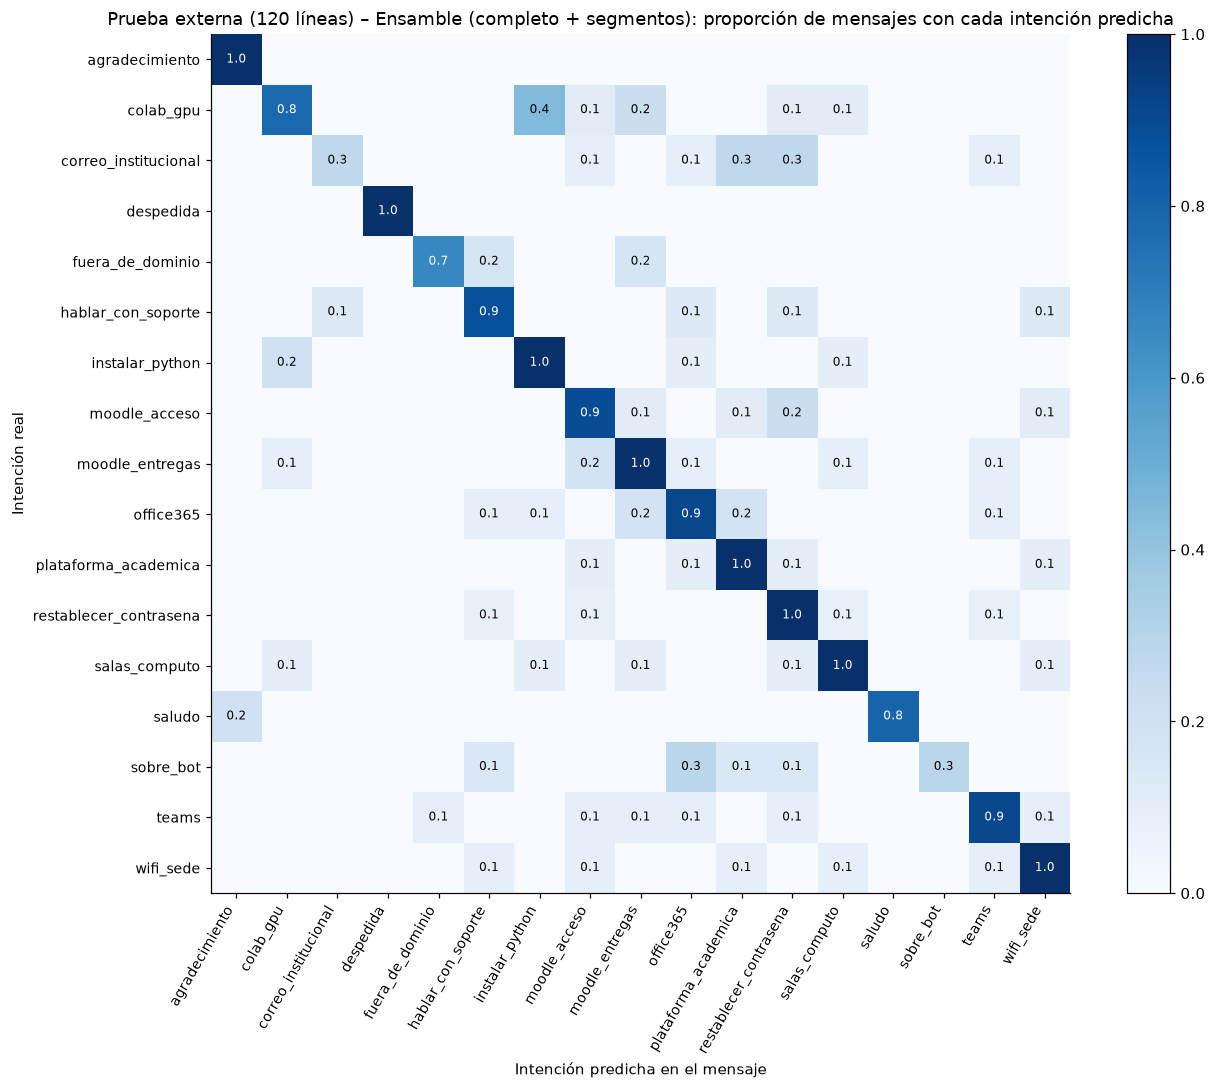

In [57]:
# ---------- Prueba externa con el método final ----------
RESULTADO_EXTERNO_V2B = None
if EXTERNO_LIMPIO:
    externo_ml = leer_externo_secciones(RUTA_EXTERNA)
    Y_ext = Y_de(externo_ml["intenciones"].tolist())
    Pr_ext = predecir_con_config(model_v2b, CONFIG_V2B, METODO_FINAL, externo_ml["texto"].tolist())
    mascaras = {"externo completo (120)": np.ones(len(externo_ml), bool),
                "una intención (90)": (Y_ext.sum(1) == 1),
                "30 naturales de varias intenciones": (externo_ml["seccion"] == "varias").values,
                "5 de control con conectores": (externo_ml["seccion"] == "control").values}
    tabla_ext_v2b = pd.DataFrame([{"conjunto": k, "método": METODO_FINAL, **metricas_v2b(Y_ext[m], Pr_ext[m])}
                                  for k, m in mascaras.items()])
    tabla_ext_v2b.to_csv(os.path.join(DATA_DIR, "v2b_externo.csv"), index=False)
    display(tabla_ext_v2b.round(4).set_index("conjunto"))
    externo_ml["predichas"] = ["|".join(ETIQUETAS[j] for j in np.where(p)[0]) for p in Pr_ext]
    externo_ml["correcta"] = (Y_ext.astype(bool) == Pr_ext).all(axis=1)
    externo_ml.to_csv(os.path.join(DATA_DIR, "v2b_externo_por_linea.csv"), index=False)
    print("30 naturales de varias intenciones (real → predicha):")
    display(externo_ml[externo_ml["seccion"] == "varias"][["texto", "intenciones", "predichas", "correcta"]])
    print("5 de control:")
    display(externo_ml[externo_ml["seccion"] == "control"][["texto", "intenciones", "predichas", "correcta"]])
    # Matriz de confusión multietiqueta
    cm_ml = np.zeros((NUM_LABELS, NUM_LABELS))
    for y, p in zip(Y_ext.astype(bool), Pr_ext):
        for i in np.where(y)[0]:
            cm_ml[i] += p
    cm_ml = cm_ml / np.maximum(Y_ext.sum(0)[:, None], 1)
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm_ml, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    ax.set_xticks(range(NUM_LABELS)); ax.set_xticklabels(ETIQUETAS, rotation=60, ha="right", fontsize=9)
    ax.set_yticks(range(NUM_LABELS)); ax.set_yticklabels(ETIQUETAS, fontsize=9)
    for i in range(NUM_LABELS):
        for j in range(NUM_LABELS):
            if cm_ml[i, j] > 0:
                ax.text(j, i, f"{cm_ml[i, j]:.1f}", ha="center", va="center", color="white" if cm_ml[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xlabel("Intención predicha en el mensaje"); ax.set_ylabel("Intención real")
    ax.set_title(f"Prueba externa (120 líneas) – {METODO_FINAL}: proporción de mensajes con cada intención predicha")
    plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig20_matriz_externa_v2b.png"), bbox_inches="tight"); plt.show()
    RESULTADO_EXTERNO_V2B = json.loads(tabla_ext_v2b.to_json(orient="records"))
else:
    print("La prueba externa no superó el control de fuga: no se evalúa.")

### v2b + normalización de tildes (fila aparte, decidida después de la prueba manual)
En la prueba manual de la interfaz, «olvidé mi contraseña» se clasificó como `agradecimiento` y «olvide mi contraseña» como `restablecer_contrasena`: el dataset casi no tiene tildes y el modelo no vio palabras acentuadas (DECISIONES.md n.º 40). El bot quita las tildes de las vocales antes de clasificar (conserva la ñ). Esta celda calcula, **con el mismo modelo ya entrenado y los mismos umbrales (sin reentrenar)**, el método final con esa normalización en la prueba, la generalización y el externo. Las cifras reportadas de la v2b no cambian; esta fila se reporta aparte en `resultados_soporte_v2b_tildes.json`.

In [58]:
# ---------- v2b + normalización de tildes (sin reentrenar) ----------
TABLA_TILDES_EVAL = str.maketrans("áéíóúüÁÉÍÓÚÜ", "aeiouuAEIOUU")      # la misma normalización del bot (quitar_tildes_entrada)
def _sin_tildes_vocales(textos):
    return [str(t).translate(TABLA_TILDES_EVAL) for t in textos]
METODO_TILDES = METODO_FINAL + " + normalización de tildes"
filas_tildes = []
for conjunto, d in {"prueba (total)": te0, "generalización": gen_ml[["texto", "intenciones"]]}.items():
    Y = Y_de(d["intenciones"].tolist())
    filas_tildes.append({"conjunto": conjunto, "método": METODO_FINAL, **metricas_v2b(Y, PRED_V2B[(conjunto, METODO_FINAL)])})
    filas_tildes.append({"conjunto": conjunto, "método": METODO_TILDES,
                         **metricas_v2b(Y, predecir_con_config(model_v2b, CONFIG_V2B, METODO_FINAL, _sin_tildes_vocales(d["texto"].tolist())))})
if EXTERNO_LIMPIO:
    Pr_ext_tildes = predecir_con_config(model_v2b, CONFIG_V2B, METODO_FINAL, _sin_tildes_vocales(externo_ml["texto"].tolist()))
    for k, m in mascaras.items():
        filas_tildes.append({"conjunto": k, "método": METODO_FINAL, **metricas_v2b(Y_ext[m], Pr_ext[m])})
        filas_tildes.append({"conjunto": k, "método": METODO_TILDES, **metricas_v2b(Y_ext[m], Pr_ext_tildes[m])})
tabla_tildes_v2b = pd.DataFrame(filas_tildes)
tabla_tildes_v2b.to_csv(os.path.join(DATA_DIR, "v2b_tildes.csv"), index=False)
display(tabla_tildes_v2b.round(4).set_index(["conjunto", "método"]))
with open(os.path.join(BASE_DIR, "resultados_soporte_v2b_tildes.json"), "w", encoding="utf-8") as f:
    json.dump({"descripcion": "v2b + normalización de tildes en la entrada (decidida después de la prueba manual; sin reentrenar; DECISIONES.md n.º 40)",
               "filas": json.loads(tabla_tildes_v2b.to_json(orient="records"))}, f, ensure_ascii=False, indent=2)

n  \
conjunto                           método                                                    
prueba (total)                     Ensamble (completo + segmentos)                     187   
                                   Ensamble (completo + segmentos) + normalización...  187   
generalización                     Ensamble (completo + segmentos)                      68   
                                   Ensamble (completo + segmentos) + normalización...   68   
externo completo (120)             Ensamble (completo + segmentos)                     120   
                                   Ensamble (completo + segmentos) + normalización...  120   
una intención (90)                 Ensamble (completo + segmentos)                      90   
                                   Ensamble (completo + segmentos) + normalización...   90   
30 naturales de varias intenciones Ensamble (completo + segmentos)                      30   
                                   Ensamble (completo + segmentos) + normalización...   30   
5 de control con conectores        Ensamble (completo + segmentos)                       5   
                                   Ensamble (completo + segmentos) + normalización...    5   

                                                                                       exact_match  \
conjunto                           método                                                            
prueba (total)                     Ensamble (completo + segmentos)                          0.6578   
                                   Ensamble (completo + segmentos) + normalización...       0.6631   
generalización                     Ensamble (completo + segmentos)                          0.9118   
                                   Ensamble (completo + segmentos) + normalización...       0.9118   
externo completo (120)             Ensamble (completo + segmentos)                          0.8000   
                                   Ensamble (completo + segmentos) + normalización...       0.8000   
una intención (90)                 Ensamble (completo + segmentos)                          0.8444   
                                   Ensamble (completo + segmentos) + normalización...       0.8444   
30 naturales de varias intenciones Ensamble (completo + segmentos)                          0.6667   
                                   Ensamble (completo + segmentos) + normalización...       0.6667   
5 de control con conectores        Ensamble (completo + segmentos)                          1.0000   
                                   Ensamble (completo + segmentos) + normalización...       1.0000   

                                                                                       f1_micro  \
conjunto                           método                                                         
prueba (total)                     Ensamble (completo + segmentos)                       0.8293   
                                   Ensamble (completo + segmentos) + normalización...    0.8325   
generalización                     Ensamble (completo + segmentos)                       0.9130   
                                   Ensamble (completo + segmentos) + normalización...    0.9130   
externo completo (120)             Ensamble (completo + segmentos)                       0.8600   
                                   Ensamble (completo + segmentos) + normalización...    0.8600   
una intención (90)                 Ensamble (completo + segmentos)                       0.8370   
                                   Ensamble (completo + segmentos) + normalización...    0.8370   
30 naturales de varias intenciones Ensamble (completo + segmentos)                       0.8966   
                                   Ensamble (completo + segmentos) + normalización...    0.8966   
5 de control con conectores        Ensamble (completo + segmentos)                       1.0000   
                                   Ensamble (completo + 

In [59]:
# ---------- Resultados de la v2b ----------
TIEMPO_V2B = time.time() - T_INICIO_V2B
RESULTADOS_V2B = {
    "version": "v2b — mejora de la multiintención (Fase 3b)",
    "nota_diseno": ("Diseñada después de ver los resultados de prueba de la v2; la evidencia principal es la validación "
                    "cruzada y la prueba externa, evaluada una sola vez con el método elegido."),
    "datos": {nombre: {k: len(v) for k, v in d.items()} for nombre, d in DATOS_V2B.items()},
    "filtros_principal": REPORTE_V2B["principal"], "qwen": QWEN_INFO,
    "beto_multietiqueta_nuevo": {"mejor_epoca": mejor_v2b["epoca"], "epocas_ejecutadas": len(hist_v2b["val_loss"]),
                                 "val_f1_micro_umbral_05": round(mejor_v2b["val_f1_micro"], 4), "n_train": mejor_v2b["n_train"]},
    "config_metodos": {m: {"piso": c["piso"], "exact_match_val_por_piso": c["exact_match_val_por_piso"],
                           "umbrales": dict(zip(ETIQUETAS, map(float, c["umbrales"])))} for m, c in CONFIG_V2B.items()},
    "validacion": json.loads(tabla_val_v2b.reset_index().to_json(orient="records")),
    "validacion_cruzada": {"por_particion": json.loads(cv_v2b.to_json(orient="records")),
                           "resumen": {m: {met: {"media": float(resumen_cv_v2b.loc[m, (met, "mean")]),
                                                 "de": float(resumen_cv_v2b.loc[m, (met, "std")])} for met in METRICAS_CV_V2B}
                                       for m in resumen_cv_v2b.index}},
    "eleccion": ELECCION_V2B,
    "prueba": json.loads(tabla_te_v2b.to_json(orient="records")),
    "externo": RESULTADO_EXTERNO_V2B,
    "tiempos_s": {"datos_v2b_y_qwen": round(tiempo_datos_v2b, 1), "qwen_generacion": round(QWEN_INFO["tiempo_generacion_s"], 1),
                  "beto_multietiqueta_nuevo": round(tiempo_v2b, 1), "validacion_cruzada_v2b": round(tiempo_cv_v2b, 1),
                  "fase3b_total": round(TIEMPO_V2B, 1), "notebook_hasta_aqui": round(time.time() - T_INICIO_NOTEBOOK, 1)},
    "historial": {k: [round(v, 4) for v in vals] for k, vals in hist_v2b.items()},
}
with open(os.path.join(BASE_DIR, "resultados_soporte_v2b.json"), "w", encoding="utf-8") as f:
    json.dump(RESULTADOS_V2B, f, ensure_ascii=False, indent=2, default=float)
print("Resultados guardados en", os.path.join(BASE_DIR, "resultados_soporte_v2b.json"))
print("Tiempos (s):", RESULTADOS_V2B["tiempos_s"])

Resultados guardados en soportic\resultados_soporte_v2b.json
Tiempos (s): {'datos_v2b_y_qwen': 80.4, 'qwen_generacion': 0.0, 'beto_multietiqueta_nuevo': 134.6, 'validacion_cruzada_v2b': 861.4, 'fase3b_total': 1089.6, 'notebook_hasta_aqui': 3745.9}


### Interpretación de la v2b (ejecución del 2026-11-14/15, RTX 5050; cifras de `resultados_soporte_v2b.json`)

Recordatorio: la v2b se diseñó después de ver la prueba de la v2; la evidencia principal es la validación cruzada y la prueba externa.

- **Datos.** En cada partición (la principal y los 5 pliegues) se construyeron 600/80/80 concatenadas, 300/40/40 frases de Qwen y 150/30 negativos con conector. En la partición principal, los filtros de Qwen descartaron 159 candidatas de entrenamiento por el top-3 de la v1 congelada y 6 por una tercera intención técnica ≥ 0,30 (filtro 1b, fijado antes de ver resultados); en validación y prueba, 12 y 17 por similitud con el origen < 0,50 y ninguna por el filtro de servicios. No se generó ninguna frase nueva con Qwen (se usó solo la caché).
- **Elección (validación cruzada, fijada a las 23:58 antes de calcular la prueba).** Exact match medio: ensamble 0,6496 ± 0,0463, multietiqueta nuevo 0,6151 ± 0,0686 y combinado 0,6026 ± 0,0596. El ensamble también tiene la mayor exactitud en mensajes de dos intenciones (0,5400 ± 0,0616, frente a 0,4733 y 0,4933) y una tasa de falsos positivos de multiintención de 0,0634 ± 0,0204 (el combinado llega a 0,1290). **Método final: ensamble (mensaje completo + segmentos), sin piso de umbral.** El piso de 0,30 solo ganó en validación para el combinado.
- **Validación cruzada frente a la v2.** El exact match medio del ensamble (0,6496) supera al del multietiqueta de la v2 (0,6246), y la exactitud en dos intenciones sube de 0,3250 a 0,5400, con menor dispersión entre pliegues (DE 0,0616 frente a 0,1275). Los conjuntos de prueba de los pliegues no son idénticos entre versiones (la v2b agrega frases de Qwen y más concatenadas), así que la comparación es indicativa.
- **Prueba (187 mensajes: 67 originales, 80 concatenadas y 40 de Qwen).** Exact match: ensamble 0,6578, combinado 0,6150, segmentación + v1 0,5829, multietiqueta nuevo 0,5455, multietiqueta v2 0,4973 y v1 top-1 0,2727. En las 67 originales de una intención, el ensamble iguala al multietiqueta de la v2 (0,7761) y la tasa de falsos positivos de multiintención es 0,0746 (multietiqueta nuevo 0,1493). En las 40 frases de Qwen, el ensamble y el combinado aciertan las dos intenciones en el 60 %.
- **Generalización (68).** Ensamble 0,9118 de exact match (v1 0,8824; multietiqueta v2 0,8971).
- **Prueba externa (evaluada una sola vez con el ensamble).** Externo completo (120): exact match 0,8000, F1 micro 0,8600, Hamming 0,0206. Una intención (90): 0,8444, con falsos positivos de multiintención en el 4,4 % (4 de 90). **30 naturales de varias intenciones: 0,6667 (20 de 30)**, F1 micro 0,8966. Las 5 de control con conectores: 5 de 5 correctas, sin falsos positivos. Con la v1 (una intención) el externo daba 0,8111 en las 90 líneas de una intención.
- **Limitación.** Las frases sintéticas de prueba comparten estructuras con las de entrenamiento; la cifra de las 30 naturales del externo es la más cercana al uso real, pero con 30 mensajes cada error mueve 3,3 puntos.

# Fase 4 — Memoria del caso y chatbot completo (versiones v3 y v4)

El bot guarda, por sesión (una por pestaña del navegador), la lista de **casos abiertos**. Cada caso tiene: intención, subproblema (rama), plataforma, dispositivo (celular, portátil, PC de la sala, Mac, tablet), navegador, mensaje de error, solución actual, soluciones dadas e intentos fallidos. Los *slots* se extraen con reglas y diccionarios deterministas (sin modelo).

**v3 (reportada en `resultados_soporte_v3.json`).** El bot daba dos pasos de la guía por turno y preguntaba «¿Funcionó?»; dos fallos seguidos escalaban.

**v4 (rediseño tras la prueba manual de los autores; DECISIONES.md n.º 32 a 57).**
- **Subproblemas.** Cada guía de `base_conocimiento.json` se divide en ramas por subproblema (60 en 12 guías), cada una con solo sus soluciones. La rama se elige por la etiqueta (botón), por palabras clave de la rama con variantes genéricas («no puedo / no he podido / no logro…», «entrar / ingresar / acceder…») o, si ninguna coincide, por similitud MiniLM con la etiqueta de la rama (umbral 0,80, elegido con 120 mensajes de desarrollo). Si el mensaje no indica el subproblema, se pregunta el diagnóstico con botones (como máximo 4 opciones).
- **Una solución por turno.** «**Solución n de m: título**», los subpasos en lista numerada y «¿Se solucionó?», con los botones «Sí, se solucionó», «No, sigue igual» y «Ya lo había intentado». «No» da la siguiente solución (cuenta como fallo); «Ya lo había intentado», la siguiente (no cuenta); «Sí» cierra el caso y retoma el pendiente. Se escala al agotar las soluciones de la rama o si el usuario lo pide; una rama sin pasos verificados lo dice y escala de una vez.
- **Cambio de tema.** Si el mensaje trae otra intención técnica, se abre o retoma ese caso y el activo queda pendiente donde iba, aunque el mensaje diga «no» o «sigue». Al retomar un caso cuya solución ya se mostró, se pregunta corto («¿pudiste probar «…»?») con «Ya no lo necesito» como tercera opción.
- **Después de escalar.** «Ya funcionó» marca el caso como resuelto; «no» o «nada» recuerda que el caso pasó a la mesa de ayuda.
- **Aclaración.** Si la intención más probable es técnica y el mensaje la nombra («contraseña», «clave»…), no se aclara; nunca se ofrece una opción social frente a una técnica; entre dos técnicas, pregunta natural con botones.
- **Entrada.** Antes de clasificar se quitan las tildes de las vocales (el dataset casi no las tiene).

**Filtros** (adaptados de `herramientas/legado_chatbot_udec.py`): contraseñas («no escribas tu contraseña aquí»), datos personales (correo, cédula, teléfono: se ocultan antes de procesar y nunca se repiten), integridad académica, insultos, texto sin sentido, inyección de instrucciones y otro idioma. Los datos institucionales siempre se citan con su fuente.

Las celdas marcadas con `# @bot` definen el bot y las usa `iniciar_soportic.py` sin reentrenar nada.

## 20. Estado del caso, *slots*, filtros y lógica de la conversación

In [60]:
# @bot
# ---------- Carga de los componentes del bot (desde memoria o desde disco) ----------
RUTA_MODELO_BOT = os.path.join(BASE_DIR, "modelo_bert_multietiqueta_v2b")
if "model_v2b" not in globals():                  # iniciar_soportic.py: se carga el modelo guardado
    model_v2b = AutoModelForSequenceClassification.from_pretrained(RUTA_MODELO_BOT).to(DEVICE).eval()
    _cfg = json.load(open(os.path.join(RUTA_MODELO_BOT, "umbrales.json"), encoding="utf-8"))
    METODO_FINAL = _cfg["metodo_final"]
    CONFIG_V2B = {m: {"piso": c["piso"], "umbrales": np.array([c["umbrales"][e] for e in ETIQUETAS])}
                  for m, c in _cfg["metodos"].items()}
UMBRALES_BOT = CONFIG_V2B[METODO_FINAL]["umbrales"]
print(f"Clasificador del bot: {METODO_FINAL} (piso: {CONFIG_V2B[METODO_FINAL]['piso']})")

def clasificar_mensaje(texto):
    """Intenciones del mensaje con el método final, ordenadas por su aparición en el mensaje, y la confianza de cada una.
    Devuelve (intenciones, confianzas, supera_umbral, top2)."""
    P_full, P_segs = probs_multi(model_v2b, [texto]), probs_segmentos(model_v2b, [texto])
    pred = predecir_metodo(METODO_FINAL, UMBRALES_BOT, P_full, P_segs)[0]
    P_dec = probs_ensamble(P_full, P_segs)[0] if METODO_FINAL.startswith("Ensamble") else P_full[0]
    segs = P_segs[0]
    supera = bool((P_dec >= UMBRALES_BOT).any() or any((s >= UMBRALES_BOT).any() for s in segs if len(segs) >= 2))
    elegidas = list(np.where(pred)[0])
    def posicion(e):
        for j, s in enumerate(segs):
            if int(s.argmax()) == e or s[e] >= UMBRALES_BOT[e]:
                return j
        return 99
    elegidas.sort(key=lambda e: (posicion(e), -P_dec[e]))
    conf = {ETIQUETAS[e]: float(max(P_dec[e], max(s[e] for s in segs))) for e in elegidas}
    top2 = [ETIQUETAS[e] for e in np.argsort(-P_dec)[:2]]
    return [ETIQUETAS[e] for e in elegidas], conf, supera, top2

Clasificador del bot: Ensamble (completo + segmentos) (piso: sin piso)


In [61]:
# @bot
# ---------- Extracción de slots (reglas y diccionarios deterministas) ----------
TABLA_TILDES = str.maketrans("áéíóúüÁÉÍÓÚÜ", "aeiouuAEIOUU")
def quitar_tildes_entrada(texto):
    """Normalización de entrada del bot antes de clasificar: quita las tildes de las vocales (á é í ó ú ü → a e i o u) y
    conserva la ñ. El dataset de entrenamiento casi no tiene tildes, así que el modelo no vio palabras con tilde
    (DECISIONES.md n.º 40)."""
    return str(texto).translate(TABLA_TILDES)

def _sin_tildes(t):
    return "".join(c for c in unicodedata.normalize("NFD", str(t).lower()) if unicodedata.category(c) != "Mn")

DISPOSITIVOS = [   # (patrón sobre el texto en minúsculas y sin tildes, valor del slot); el orden importa
    (r"\b(?:pc|computador|computadora|equipo|maquina)s? de (?:la )?sala\b|\bsala de (?:computo|sistemas)\b.*\b(?:pc|computador|equipo)\b", "PC de la sala"),
    (r"\b(?:celular|telefono|movil|android|iphone|smartphone|cel)\b", "celular"),
    (r"\b(?:portatil|laptop|notebook)\b", "portátil"),
    (r"\b(?:mac|macbook|macos)\b", "Mac"),
    (r"\b(?:tablet|tableta|ipad)\b", "tablet"),
    (r"\b(?:pc|computador|computadora|escritorio)\b", "computador"),
]
NAVEGADORES = [(r"\bchrome\b", "Chrome"), (r"\bedge\b", "Edge"), (r"\bfirefox\b|\bmozilla\b", "Firefox"),
               (r"\bsafari\b", "Safari"), (r"\bopera\b", "Opera"), (r"\bbrave\b", "Brave")]
PLATAFORMAS = [   # (patrón, plataforma, intención técnica asociada)
    (r"\bmoodle\b|\baula virtual\b|\baulas virtuales\b", "Moodle", None),
    (r"\bcorreos?\b|\boutlook\b|\bbandeja\b", "correo institucional", "correo_institucional"),
    (r"\bteams\b", "Teams", "teams"),
    (r"\bonedrive\b|\bword\b|\bexcel\b|\bpowerpoint\b|\boffice\b", "Office 365", "office365"),
    (r"\bcolab\b|\bcuaderno de google\b", "Colab", "colab_gpu"),
    (r"\bpython\b|\bpip\b|\banaconda\b|\bjupyter\b|\bvs ?code\b|\bvisual studio code\b|\bpandas\b", "Python", "instalar_python"),
    (r"\bacademusoft\b|\bplataforma (?:institucional|academica)\b|\bsis\b|\bmatricula\b|\bplataforma\b", "plataforma institucional", "plataforma_academica"),
    (r"\bwi-?fi\b|\bred (?:de la|wifi|de estudiantes)\b|\binternet\b", "Wi-Fi", "wifi_sede"),
    (r"\bsala de (?:computo|sistemas)\b|\bsalas\b", "sala de cómputo", "salas_computo"),
]
ERRORES_CONOCIDOS = [   # (patrón, texto normalizado del error)
    (r"error\s*\d{3}", None), (r"out of memory", "cuda out of memory"), (r"no se reconoce|no lo reconoce|not recognized", "no se reconoce como comando"),
    (r"contrasena incorrecta|clave incorrecta", "contraseña incorrecta"), (r"sin internet", "sin internet"),
    (r"(?:pantalla|pagina) (?:en )?blanc[oa]|en blanco|pantalla blanca", "pantalla en blanco"),
    (r"sin licencia|no tiene licencia|no esta activado|producto no (?:tiene|esta)", "sin licencia"),
    (r"excede el tamano|tamano maximo|archivo (?:muy )?(?:grande|pesado)", "archivo excede el tamaño máximo"),
    (r"perfil temporal", "perfil temporal"), (r"cuenta bloqueada|bloquee la cuenta|bloquearon", "cuenta bloqueada"),
    (r"se queda cargando|carga sin fin|cargando", "se queda cargando"), (r"no puede conectarse a un backend|no hay gpu|sin gpu|no me (?:da|asigna) gpu", "sin GPU disponible"),
    (r"acceso denegado|access denied", "acceso denegado"), (r"invitados no pueden", "los invitados no pueden entrar"),
]

def extraer_slots(texto):
    """Slots presentes en un mensaje (ya sin datos personales). Devuelve un dict con los encontrados."""
    t = _sin_tildes(texto)
    slots = {}
    for patron, valor in DISPOSITIVOS:
        if re.search(patron, t):
            slots["dispositivo"] = valor; break
    for patron, valor in NAVEGADORES:
        if re.search(patron, t):
            slots["navegador"] = valor; break
    posiciones = [(m.start(), valor) for patron, valor, _ in PLATAFORMAS for m in [re.search(patron, t)] if m]
    if posiciones:
        slots["plataforma"] = min(posiciones)[1]
    for patron, valor in ERRORES_CONOCIDOS:
        m = re.search(patron, t)
        if m:
            slots["error"] = valor or m.group(0); break
    return slots

def plataforma_para(intent, texto, slots, varias):
    """Plataforma de un caso: con una sola intención, la primera mencionada; con varias, la que corresponde a esa intención."""
    if not varias:
        return slots.get("plataforma")
    t = _sin_tildes(texto)
    for patron, plataforma, i in PLATAFORMAS:
        if (i == intent or (i is None and intent.startswith("moodle"))) and re.search(patron, t):
            return plataforma
    return None

def intenciones_por_plataforma(texto):
    """Intenciones técnicas asociadas a las plataformas nombradas en el mensaje (para seguimientos)."""
    t = _sin_tildes(texto)
    return [intent for patron, _, intent in PLATAFORMAS if intent and re.search(patron, t)]

for ejemplo in ["no puedo entrar a moodle desde el celular con chrome", "en el pc de la sala me sale perfil temporal",
                "word dice sin licencia en mi mac", "colab: cuda out of memory"]:
    print(f"{ejemplo!r:60} → {extraer_slots(ejemplo)}")

'no puedo entrar a moodle desde el celular con chrome'       → {'dispositivo': 'celular', 'navegador': 'Chrome', 'plataforma': 'Moodle'}
'en el pc de la sala me sale perfil temporal'                → {'dispositivo': 'PC de la sala', 'error': 'perfil temporal'}
'word dice sin licencia en mi mac'                           → {'dispositivo': 'Mac', 'plataforma': 'Office 365', 'error': 'sin licencia'}
'colab: cuda out of memory'                                  → {'plataforma': 'Colab', 'error': 'cuda out of memory'}


In [62]:
# @bot
# ---------- Filtros de entrada (adaptados del proyecto anterior) ----------
TEXTO_CONTRASENA = ("🔒 Por seguridad, no escribas tu contraseña aquí: nadie de soporte te la va a pedir y yo no la necesito. "
                    "La oculté de la conversación; te recomiendo cambiarla.")
TEXTO_PRIVACIDAD = ("🔒 No compartas datos personales (correo, teléfono o documento) en este chat; no los necesito para ayudarte. "
                    "Los oculté de la conversación.")
TEXTO_INTEGRIDAD = ("No puedo hacer tareas, talleres ni evaluaciones por ti. Sí puedo ayudarte con los problemas técnicos para "
                    "entregarlos, por ejemplo si Moodle no te deja subir el archivo.")
TEXTO_CORTESIA = ("Entiendo que sea frustrante. Estoy aquí para ayudarte con el problema técnico; cuéntame qué pasa y lo revisamos "
                  "paso a paso.")
TEXTO_SIN_SENTIDO = ("No logré entender el mensaje. ¿Me cuentas el problema con otras palabras? Por ejemplo: «no puedo entrar a "
                     "Moodle desde el celular».")
TEXTO_INYECCION = ("No puedo cambiar mis instrucciones ni revelar cómo estoy configurado. Soy el asistente de soporte técnico de "
                   "la UdeC: cuéntame qué problema tienes con Moodle, el correo, Teams, el Wi-Fi u otro servicio.")
TEXTO_OTRO_IDIOMA = ("Por ahora solo atiendo en español. Cuéntame tu problema en español y te ayudo. "
                     "(I can only help in Spanish for now.)")
TEXTO_VACIO = "Escríbeme tu problema y con gusto te ayudo 🙂"

PATRON_CONTRASENA = re.compile(r"\b(?:mi\s+)?(?:contrase[ñn]a|clave|password|pass|pin)(?:\s+(?:de|del|para|en)\s+\w+){0,2}\s*(?:actual\s+|nueva\s+)?"
                               r"(?:es|era|:|=)\s*(\S+)", re.I)      # admite «clave de todos es …», «contraseña del correo es …»
PATRON_CORREO = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
PATRON_DOCUMENTO = re.compile(r"\b(?:c[eé]dula|documento|c\.?\s?c\.?|t\.?\s?i\.?|pasaporte|identificaci[oó]n)\b[^\d\n]{0,20}[\d.\s-]{6,}\d", re.I)
PATRON_NUMERO_LARGO = re.compile(r"(?<![\w.])\+?\d[\d\s-]{6,}\d(?![\w.])")
CORREOS_INSTITUCIONALES = re.compile(r"^(?:ticsaunclic|soporteaulavirtual|sistemasdeinformacion|serviciostecnologicos)@", re.I)

NO_ES_CONTRASENA = {"incorrecta", "invalida", "erronea", "correcta", "valida", "nueva", "vieja", "igual", "distinta", "diferente",
                    "expirada", "vencida", "temporal", "obligatoria", "muy", "demasiado", "la", "el", "mi", "otra", "esa", "esta"}
def _es_contrasena(palabra):
    p = _sin_tildes(palabra).strip(".,;:!?¿¡\"'«»")
    return bool(p) and p not in NO_ES_CONTRASENA and p not in STOPWORDS_ES

def filtrar_datos_personales(mensaje):
    """Oculta contraseñas, correos personales, documentos y teléfonos. Devuelve (texto, hubo_contraseña, hubo_datos)."""
    t, clave, datos = str(mensaje), False, False
    if any(_es_contrasena(m.group(1)) for m in PATRON_CONTRASENA.finditer(t)):
        t = PATRON_CONTRASENA.sub(lambda m: m.group(0).replace(m.group(1), "[contraseña oculta]") if _es_contrasena(m.group(1))
                                  else m.group(0), t)
        clave = True
    def _correo(m):
        nonlocal datos
        if CORREOS_INSTITUCIONALES.match(m.group(0)):
            return m.group(0)
        datos = True
        return "[correo oculto]"
    t = PATRON_CORREO.sub(_correo, t)
    if PATRON_DOCUMENTO.search(t):
        t, datos = PATRON_DOCUMENTO.sub("[documento oculto]", t), True
    if PATRON_NUMERO_LARGO.search(t):
        t, datos = PATRON_NUMERO_LARGO.sub("[número oculto]", t), True
    return t, clave, datos

INSULTOS = {"hijueputa", "hijueputas", "hp", "hpta", "gonorrea", "malparido", "malparida", "carechimba", "careverga",
            "pirobo", "pirobos", "idiota", "estupido", "estupida", "imbecil", "pendejo", "pendeja", "inutil", "mierda"}
def es_ofensivo(texto):
    t = _sin_tildes(texto)
    return bool(set(re.findall(r"\w+", t)) & INSULTOS) or "hijo de puta" in t

PATRON_INTEGRIDAD = re.compile(r"\b(?:hazme|hagame|haz mi|resuelve(?:me)?|resuelvame|desarrolla(?:me)?|contesta(?:me)?)\b.{0,30}"
                               r"\b(?:tarea|taller|parcial|quiz|examen|cuestionario|ejercicio|proyecto|trabajo)"
                               r"|\b(?:dame|pasame|dime) las respuestas\b|\brespuestas del (?:quiz|parcial|examen|cuestionario)\b")
PATRON_INYECCION = re.compile(r"\bignora (?:las|tus|todas|lo)\b|\bolvida (?:tus|las|todas) (?:instrucciones|reglas)\b|\bsystem prompt\b"
                              r"|\bprompt del sistema\b|\bactua como\b|\bahora eres\b|\bmodo desarrollador\b|\bjailbreak\b"
                              r"|\b(?:revela|muestra|dime) (?:tus|las) (?:instrucciones|reglas)\b|\bignore (?:all|previous|your)\b")
INGLES = {"the", "is", "my", "i", "can't", "cannot", "how", "what", "please", "help", "doesn't", "not", "to", "and", "with",
          "you", "it", "work", "working", "login", "log", "in", "do", "does", "where", "when", "can", "password", "email"}
def es_otro_idioma(texto):
    palabras = re.findall(r"[a-z']+", str(texto).lower())
    if len(palabras) < 3:
        return False
    ingles = sum(w in INGLES for w in palabras)
    espanol = sum(_sin_tildes(w) in STOPWORDS_ES for w in palabras)
    return ingles >= 2 and ingles > espanol

LEXICO_BOT = ({w for t in df["texto"] for w in tokenizar_eda(t, sin_stopwords=False)} | STOPWORDS_ES
              | {"wifi", "moodle", "teams", "colab", "python", "office", "excel", "word", "onedrive", "outlook", "gpu"})
def palabra_plausible(w):
    return bool(re.search(r"[aeiou]", w)) and not re.search(r"[^aeiou]{4,}", w)
def es_sin_sentido(texto):
    """Ninguna palabra (de dos o más letras) está en el léxico; y la mayoría no es pronunciable o no es conocida."""
    palabras = [w for w in re.findall(r"[a-zñ]+", _sin_tildes(texto)) if len(w) > 1]
    if not palabras:
        return bool(str(texto).strip()) and not re.search(r"\w", str(texto))
    conocidas = sum(w in LEXICO_BOT for w in palabras)
    return conocidas == 0 and sum(not palabra_plausible(w) for w in palabras) >= max(1, len(palabras) // 2)

In [63]:
# Falsos positivos de los filtros de sin sentido y de otro idioma en datos de entrenamiento y validación (deben ser 0)
for nombre, frases in [("entrenamiento", train_df["texto"]), ("validación", val_orig["texto"])]:
    print(f"Falsos positivos en {nombre}: sin sentido {sum(map(es_sin_sentido, frases))} | otro idioma "
          f"{sum(map(es_otro_idioma, frases))} | integridad {sum(bool(PATRON_INTEGRIDAD.search(_sin_tildes(f))) for f in frases)}")

Falsos positivos en entrenamiento: sin sentido 0 | otro idioma 0 | integridad 0
Falsos positivos en validación: sin sentido 0 | otro idioma 0 | integridad 0


In [64]:
# @bot
# ---------- Reconocimiento de respuestas de control dentro de un caso ----------
PATRON_NUEVO_CASO = re.compile(r"\blo mismo (?:me )?(?:pasa|ocurre|sucede)\b|\btambien me pasa\b|\bigual me pasa\b|\bme pasa lo mismo\b")
PATRON_CIERRE = re.compile(r"\bfunciono\b|\bfunciona\b|\blisto\b|\bya quedo\b|\bquedo\b|\bya pude\b|\bsolucionad|\bse soluciono\b|\bresuelto\b"
                           r"|\bya (?:me )?(?:abrio|abre|cargo|carga|conecto|conecta|aparece|aparecio|sirve|sirvio|entre|deja|dejo"
                           r"|encontre|prendio|sincroniza|instalo|activo)\b|\bya la encontre\b|\bya lo encontre\b")
PATRON_CIERRE_NEGADO = re.compile(r"\bno (?:me )?(?:ha |he |se )?(?:funciono|funciona|sirvio|sirve|quedo|pude|carga|abre|deja|soluciono)\b|\bsigue\b"
                                  r"|\btampoco\b|\btodavia no\b|\baun no\b")
PATRON_HECHO = re.compile(r"\bya lo (?:hice|habia hecho|intente|probe|habia intentado|habia probado)\b|\beso ya\b|\bya hice eso\b"
                          r"|\bya intente eso\b|\bya probe eso\b")
PATRON_FALLO = re.compile(r"^\s*no\b|\bno (?:me |se )?(?:ha )?(?:funciono|funciona|sirvio|sirve|resulto|soluciono)\b|\bsigue (?:igual|sin|fallando|saliendo|el mismo)"
                          r"|\btampoco\b|^\s*nada\b|\bigual\b|\bme sigue\b|\bsin servir\b|\bno pude\b|\bnada que\b|\bsigue sin\b")
PATRON_FALLO_FUERTE = re.compile(r"\bno (?:me |se )?(?:ha )?(?:funciono|sirvio|resulto|soluciono)\b|\bsigue (?:igual|sin)\b|\btampoco\b|\bsin servir\b"
                                 r"|\bme sigue\b|\blo mismo\b")
PATRON_GRACIAS = re.compile(r"\bgracias\b|\bmil gracias\b|\bte agradezco\b")
PATRON_INICIO_SEGUIMIENTO = re.compile(r"^\s*(?:y|e|pero|entonces|y si|y que tal)\b")
PATRON_OPCION = {0: re.compile(r"^(?:la |el |opcion )?(?:1|uno|primera|primero)$"), 1: re.compile(r"^(?:la |el |opcion )?(?:2|dos|segunda|segundo)$")}

def n_palabras(t):
    return len(re.findall(r"\w+", t))

In [65]:
# @bot
# ---------- Estado del caso y textos de respuesta (v4: diagnóstico → rama → soluciones) ----------
NOMBRE_INTENCION = {"moodle_acceso": "el ingreso a Moodle", "moodle_entregas": "la entrega en Moodle",
                    "correo_institucional": "el correo institucional", "restablecer_contrasena": "tu contraseña",
                    "wifi_sede": "el Wi-Fi de la sede", "teams": "Teams", "office365": "Office 365 y OneDrive",
                    "instalar_python": "la instalación de Python", "colab_gpu": "Google Colab",
                    "plataforma_academica": "la plataforma institucional", "salas_computo": "las salas de cómputo",
                    "hablar_con_soporte": "el contacto con soporte", "saludo": "un saludo", "despedida": "una despedida",
                    "agradecimiento": "un agradecimiento", "sobre_bot": "qué es este asistente",
                    "fuera_de_dominio": "un tema que no es de soporte técnico"}
PALABRAS_DISPOSITIVO = {"celular": r"celular|\bapp\b|m[oó]vil|android|iphone", "portátil": r"port[aá]til|windows|navegador|equipo|\bpc\b",
                        "computador": r"windows|navegador|equipo|\bpc\b|computador", "PC de la sala": r"sala|equipo|\bpc\b",
                        "Mac": r"\bmac\b", "tablet": r"tablet|ipad|\bapp\b"}
CONTACTO_CORTO = (f"«TICS a un CLIC»: {', '.join(BASE_CONOCIMIENTO['contacto_por_defecto']['canales'])}, "
                  f"{BASE_CONOCIMIENTO['contacto_por_defecto']['horario']}")
CORREO_MESA = re.search(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+", CONTACTO_CORTO).group(0)
# Nota de una línea, solo la primera vez en la conversación que se omiten subpasos por datos de la sede aún no disponibles
TEXTO_AVISO_SEDE = f"Algunos datos de la sede no están disponibles; si lo necesitas, escribe a TICS a un CLIC ({CORREO_MESA})."
PREGUNTA_RESULTADO = "¿Se solucionó?"
RESPUESTAS_CONTROL = ("Sí, se solucionó", "No, sigue igual", "Ya lo había intentado")
PREGUNTA_RETOMAR = "¿pudiste probar"           # al retomar un caso cuya solución ya se mostró (DECISIONES.md n.º 53)
RESPUESTAS_RETOMAR = ("Sí, se solucionó", "No, sigue igual", "Ya no lo necesito")
PATRON_DESCARTE = re.compile(r"\bya no lo necesito\b|\bya no la necesito\b|\bolvidalo\b|\bdejalo asi\b|\bya no importa\b"
                             r"|\bno importa\b|^\s*ya no\s*[.!]*$|^\s*dejalo\s*[.!]*$")
PATRON_PIDE_ESCALAR = re.compile(r"\b(?:hablar|comunicarme|contactar|hablo) con (?:alguien|una persona|un humano|soporte|la mesa|un asesor|un tecnico)"
                                 r"|\bescala(?:r|lo)?\b|\bmesa de ayuda\b|\bpasa(?:r|me)? (?:el caso|a soporte|con soporte)")

def subpasos_usables(sol):
    """Subpasos que se muestran: los que no tienen [COMPLETAR]."""
    return [s for s in sol["subpasos"] if MARCADOR_COMPLETAR not in s]

def sin_completar(texto):
    """Quita las oraciones o cláusulas (separadas por «.» o «;») que contienen un marcador [COMPLETAR]."""
    partes = [p.strip() for p in re.split(r"(?<=[.;])\s+", str(texto)) if p.strip()]
    conservadas = [p for p in partes if MARCADOR_COMPLETAR not in p]
    if not conservadas:
        return ""
    salida = " ".join(conservadas)
    return salida[:-1] + "." if salida.endswith(";") else salida

def soluciones_de(intent, rama):
    """Soluciones de la rama que tienen al menos un subpaso para mostrar (las demás se omiten enteras)."""
    return [s for s in GUIAS[intent]["ramas"][rama]["soluciones"] if subpasos_usables(s)]

def rama_omite_datos(intent, rama):
    return any(MARCADOR_COMPLETAR in p for s in GUIAS[intent]["ramas"][rama]["soluciones"] for p in s["subpasos"])

def opcion_de_rama(intent, rama):
    """Subproblema de la rama (su etiqueta), o None."""
    r = GUIAS[intent]["ramas"].get(rama) if rama else None
    return {"rama": rama, "etiqueta": r["etiqueta"]} if r and "etiqueta" in r else None

def etiquetas_diagnostico(intent):
    """Etiquetas de las ramas que la pregunta de diagnóstico ofrece como botones (2 a 4)."""
    g = GUIAS[intent]
    return [g["ramas"][r]["etiqueta"] for r in g["diagnostico"]["opciones"]]

# Variantes genéricas (DECISIONES.md n.º 48): una palabra clave que contiene una expresión de un grupo se completa con las demás
GRUPOS_VARIANTES = [["no puedo", "no he podido", "no logro", "no me deja", "no consigo", "no pude", "no me dejo"],
                    ["entrar", "ingresar", "iniciar sesion", "acceder"],
                    ["no abre", "no me abre", "no carga", "no me carga", "no inicia", "no arranca"],
                    ["no me llegan", "no me llega", "no llegan", "no llega", "no recibo", "no estoy recibiendo"],
                    ["unirme", "entrar a", "conectarme a"]]
_CLAVES_EXPANDIDAS = {}

def _contiene(frase, texto):
    return re.search(r"(?<!\w)" + re.escape(frase) + r"(?!\w)", texto) is not None

def claves_rama(intent, rama):
    """Palabras clave de la rama, normalizadas y completadas con las variantes genéricas (hasta no agregar nada nuevo)."""
    clave = (intent, rama)
    if clave not in _CLAVES_EXPANDIDAS:
        claves = {_sin_tildes(p) for p in GUIAS[intent]["ramas"][rama].get("palabras_clave", [])}
        grupos = [[_sin_tildes(x) for x in g] for g in GRUPOS_VARIANTES]
        frontera = set(claves)
        while frontera:
            nuevas = set()
            for p in frontera:
                for g in grupos:
                    for m in g:
                        if _contiene(m, p):
                            for otro in g:
                                v = re.sub(r"(?<!\w)" + re.escape(m) + r"(?!\w)", otro, p)
                                if v not in claves:
                                    nuevas.add(v)
            claves |= nuevas
            frontera = nuevas
        _CLAVES_EXPANDIDAS[clave] = sorted(claves)
    return _CLAVES_EXPANDIDAS[clave]

# Respaldo semántico (DECISIONES.md n.º 49): MiniLM entre el mensaje que abre el caso y la descripción de cada rama
MODELO_SEMANTICO_RAMAS = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
UMBRAL_RAMA_SEMANTICA = 0.80          # 120 mensajes de desarrollo: el top-1 equivocado más alto tiene 0,793; con 0,80 ningún
                                      # mensaje cae en una rama equivocada (acierta 18). DECISIONES.md n.º 49
_codificador_ramas, _embeddings_ramas = None, {}

def descripcion_rama(intent, rama):
    """Descripción corta de la rama: su etiqueta (el subproblema). Sin el título de la guía, que comparten todas las ramas y
    hacía que un mensaje ambiguo se pareciera a todas (DECISIONES.md n.º 49)."""
    return GUIAS[intent]["ramas"][rama]["etiqueta"]

def similitud_ramas(intent, texto):
    """(rama más parecida, similitud coseno) entre el mensaje y las descripciones de las ramas de la guía."""
    global _codificador_ramas
    if _codificador_ramas is None:
        from sentence_transformers import SentenceTransformer
        _codificador_ramas = SentenceTransformer(MODELO_SEMANTICO_RAMAS, device="cpu")
    if intent not in _embeddings_ramas:
        ramas = list(GUIAS[intent]["ramas"])
        _embeddings_ramas[intent] = (ramas, _codificador_ramas.encode([descripcion_rama(intent, r).lower() for r in ramas],
                                                                       convert_to_tensor=True, normalize_embeddings=True))
    ramas, E = _embeddings_ramas[intent]
    q = _codificador_ramas.encode([str(texto).lower()], convert_to_tensor=True, normalize_embeddings=True)
    sims = (q @ E.T)[0]
    k = int(sims.argmax())
    return ramas[k], float(sims[k])

NOMBRE_CORTO = {"moodle_acceso": "Moodle", "moodle_entregas": "Entregas en Moodle", "correo_institucional": "Correo",
                "restablecer_contrasena": "Contraseña", "wifi_sede": "Wi-Fi", "teams": "Teams", "office365": "Office u OneDrive",
                "instalar_python": "Python", "colab_gpu": "Colab", "plataforma_academica": "Plataforma institucional",
                "salas_computo": "Salas de cómputo", "hablar_con_soporte": "Mesa de ayuda"}
TEXTO_PEDIR_MAS = "¿Me cuentas un poco más? Por ejemplo, qué plataforma usas o qué mensaje te aparece."

def menciona_intencion(intent, texto):
    """El mensaje trae una palabra clave de la intención o de alguna de sus ramas (DECISIONES.md n.º 50)."""
    t = _sin_tildes(texto)
    return (any(_contiene(_sin_tildes(p), t) for p in GUIAS[intent].get("palabras_clave", []))
            or any(_contiene(p, t) for rama in GUIAS[intent]["ramas"] for p in claves_rama(intent, rama)))

def rama_por_texto(intent, texto, semantico=False):
    """Subproblema que indica el mensaje: la rama cuya etiqueta coincide con el mensaje (botón) o la ÚNICA rama cuyas palabras
    clave (con variantes) aparecen en él; si ninguna coincide y semantico=True, la rama más parecida por MiniLM si supera el
    umbral. None si no lo indica o es ambiguo (entonces se pregunta el diagnóstico)."""
    g = GUIAS[intent]
    if "diagnostico" not in g:
        return next(iter(g["ramas"]))
    t = _sin_tildes(texto).strip(" .¡!¿?")
    for rama, r in g["ramas"].items():
        if t == _sin_tildes(r["etiqueta"]):
            return rama
    hallazgos = [rama for rama in g["ramas"] if any(_contiene(p, t) for p in claves_rama(intent, rama))]
    if len(hallazgos) == 1:
        return hallazgos[0]
    if not hallazgos and semantico and UMBRAL_RAMA_SEMANTICA is not None and n_palabras(t) >= 3:
        rama, sim = similitud_ramas(intent, texto)
        if sim >= UMBRAL_RAMA_SEMANTICA:
            return rama
    return None

def fuente_solucion(sol):
    r = next((r for r in sol["referencias"] if MARCADOR_COMPLETAR not in r["titulo"] + r["url"]), None)
    return f"Fuente: {r['titulo']} ({r['url']})" if r else ""

def nuevo_caso(intent, slots_previos=None):
    return {"intencion": intent, "rama": None, "esperando_diagnostico": False, "plataforma": None, "dispositivo": None,
            "navegador": None, "error": None, "solucion_actual": None, "soluciones_dadas": [], "soluciones_hechas": [],
            "intentos_fallidos": 0, "estado": "abierto", "texto_inicial": "", "mostradas": [],
            **{k: v for k, v in (slots_previos or {}).items() if k in ("plataforma", "dispositivo", "navegador", "error")}}

def con_a(nombre):
    """«a» + nombre con la contracción «al»."""
    return "al " + nombre[3:] if nombre.startswith("el ") else "a " + nombre

def etiqueta_corta(etiqueta):
    """«No puedo iniciar sesión con mi usuario o contraseña» → «No puedo iniciar sesión»."""
    for sep in (" con mi ", " con tu ", " con la "):
        if sep in etiqueta:
            return etiqueta.split(sep)[0]
    if ", " in etiqueta and len(etiqueta.split(", ")[0]) >= 20:     # «Dice conectado, pero…» se conserva completa
        return etiqueta.split(", ")[0]
    return etiqueta

def titulo_caso(caso):
    """Título del caso en la tarjeta y en el resumen: «Moodle · No puedo iniciar sesión» (DECISIONES.md n.º 55)."""
    g = GUIAS[caso["intencion"]]
    if caso.get("rama"):
        return f"{NOMBRE_CORTO[caso['intencion']]} · {etiqueta_corta(g['ramas'][caso['rama']]['etiqueta'])}"
    return f"{NOMBRE_CORTO[caso['intencion']]} · {g['titulo']}"

def resumen_escalamiento(caso):
    """Resumen del caso para copiar a la mesa de ayuda, sin datos personales: las soluciones intentadas, por título."""
    g = GUIAS[caso["intencion"]]
    opcion = opcion_de_rama(caso["intencion"], caso["rama"]) if caso["rama"] else None
    sols = soluciones_de(caso["intencion"], caso["rama"]) if caso["rama"] else []
    intentadas = [sols[i]["titulo"] for i in caso["soluciones_dadas"]]
    lineas = [f"Caso: {titulo_caso(caso)}",
              f"Plataforma: {caso['plataforma'] or 'no indicada'}",
              f"Dispositivo: {caso['dispositivo'] or 'no indicado'}",
              f"Navegador: {caso['navegador'] or 'no indicado'}",
              f"Error: {caso['error'] or 'no indicado'}",
              "Soluciones intentadas: " + ("; ".join(f"{k}) {t}" for k, t in enumerate(intentadas, start=1)) or "ninguna")]
    return "\n".join(lineas)

In [66]:
# @bot
# ---------- SoporTIC: lógica de la conversación con memoria del caso ----------
class SoporTIC:
    """Un objeto por sesión. memoria=False reinicia el estado en cada turno (bot sin memoria, para comparar)."""

    def __init__(self, memoria=True):
        self.memoria = memoria
        self.reiniciar()

    def reiniciar(self):
        self.casos, self.activo, self.historial, self.aclaracion = [], None, [], None
        self.aviso_sede_dado = False
        self._escalado_actual = self._escalado_previo = None      # caso escalado en este turno / en el anterior

    # ----- utilidades de estado -----
    def caso_activo(self):
        return self.casos[self.activo] if self.activo is not None else None

    def abiertos(self):
        return [i for i, c in enumerate(self.casos) if c["estado"] == "abierto"]

    def _caso_de(self, intent):
        return next((i for i, c in enumerate(self.casos) if c["intencion"] == intent and c["estado"] == "abierto"), None)

    def _siguiente_activo(self):
        abiertos = self.abiertos()
        self.activo = abiertos[0] if abiertos else None

    def estado_publico(self):
        """Estado del caso activo para los detalles técnicos y la evaluación."""
        c = self.caso_activo()
        return {"caso_activo": c["intencion"] if c else None,
                "casos": [{k: (list(v) if isinstance(v, list) else v) for k, v in x.items()} for x in self.casos],
                "slots": {k: c[k] for k in ("plataforma", "dispositivo", "navegador", "error")} if c else {}}

    # ----- soluciones de la guía -----
    def _dar_solucion(self, caso, preferir_dispositivo=False):
        """Siguiente solución de la rama, sin repetir. Devuelve su índice o None si se agotaron."""
        sols = soluciones_de(caso["intencion"], caso["rama"])
        restantes = [i for i in range(len(sols)) if i not in caso["soluciones_dadas"]]
        if preferir_dispositivo and caso["dispositivo"] in PALABRAS_DISPOSITIVO:
            patron = PALABRAS_DISPOSITIVO[caso["dispositivo"]]
            con_disp = [i for i in restantes if re.search(patron, " ".join(sols[i]["subpasos"]), re.I)]
            restantes = con_disp + [i for i in restantes if i not in con_disp]
        if not restantes:
            return None
        caso["soluciones_dadas"].append(restantes[0])
        caso["solucion_actual"] = restantes[0]
        return restantes[0]

    def _texto_solucion(self, caso, i, con_pie=True):
        """«**Solución n de m: título**», los subpasos numerados y «¿Se solucionó?»; al pie, la fuente y, la primera vez en la
        conversación que la rama omite datos de la sede, la nota de contacto."""
        sols = soluciones_de(caso["intencion"], caso["rama"])
        s = sols[i]
        if i not in caso.setdefault("mostradas", []):
            caso["mostradas"].append(i)
        lineas = [f"**Solución {i + 1} de {len(sols)}: {s['titulo']}**"]
        lineas += [f"{k}. {p}" for k, p in enumerate(subpasos_usables(s), start=1)]
        lineas.append(PREGUNTA_RESULTADO)
        pie = []
        if con_pie:
            # La nota solo sale si esta solución omitió de verdad un subpaso con [COMPLETAR] (DECISIONES.md n.º 56)
            if any(MARCADOR_COMPLETAR in p for p in s["subpasos"]) and not self.aviso_sede_dado:
                pie.append(TEXTO_AVISO_SEDE)
                self.aviso_sede_dado = True
            f = fuente_solucion(s)
            if f:
                pie.append(f)
        return "\n".join(lineas) + (("\n\n" + "\n".join(pie)) if pie else "")

    def _texto_diagnostico(self, caso):
        d = GUIAS[caso["intencion"]]["diagnostico"]
        caso["esperando_diagnostico"] = True
        return f"{d['pregunta']}\nOpciones: " + "; ".join(etiquetas_diagnostico(caso["intencion"])) + "."

    def _empezar(self, caso, texto, turno):
        """Primera respuesta de un caso: la pregunta de diagnóstico (si el mensaje no indica el subproblema) o la primera
        solución de la rama. Una rama que redirige convierte el caso (p. ej., correo → contraseña, Microsoft 365); una rama sin
        soluciones verificadas lo dice y escala de una vez."""
        prefijo = ""
        if caso["rama"] is None:
            caso["rama"] = rama_por_texto(caso["intencion"], texto, semantico=True)
            if caso["rama"] is None:
                turno["diagnostico"] = True
                return self._texto_diagnostico(caso)
        caso["esperando_diagnostico"] = False
        destino = GUIAS[caso["intencion"]]["ramas"][caso["rama"]].get("redirige_a")
        if destino:
            caso["intencion"], caso["rama"] = destino["intencion"], destino["rama"]
            prefijo = (f"Eso se resuelve recuperando la contraseña ({opcion_de_rama(caso['intencion'], caso['rama'])['etiqueta']}).\n"
                       if destino["intencion"] == "restablecer_contrasena" else "")
        i = self._dar_solucion(caso)
        if i is None:
            turno["accion"] = "escalar"
            etiqueta = opcion_de_rama(caso["intencion"], caso["rama"])["etiqueta"]
            return prefijo + self._escalar(caso, f"Para «{etiqueta}» todavía no tengo pasos verificados en mi base.")
        turno["pasos_turno"] = turno.get("pasos_turno", []) + [(caso["intencion"], caso["rama"], i)]
        return prefijo + self._texto_solucion(caso, i)

    def _escalar(self, caso, motivo):
        caso["estado"] = "escalado"
        self._escalado_actual = self.casos.index(caso)
        g = GUIAS[caso["intencion"]]
        texto = (f"{motivo} Te recomiendo pasar el caso a la mesa de ayuda. {sin_completar(g['si_no_funciona'])}\n"
                 f"Contacto: {CONTACTO_CORTO}\n\nResumen del caso para copiar:\n```\n{resumen_escalamiento(caso)}\n```")
        self._siguiente_activo()
        return texto + self._retomar()

    def _texto_volver(self, caso):
        """Volver a un caso pendiente: si su solución actual ya se mostró, una pregunta corta (no se repite la solución);
        si no, la solución completa (DECISIONES.md n.º 53)."""
        nombre = NOMBRE_INTENCION[caso["intencion"]]
        i = caso["solucion_actual"]
        if i in caso.get("mostradas", []):
            titulo = soluciones_de(caso["intencion"], caso["rama"])[i]["titulo"]
            return f"Volvamos {con_a(nombre)}: {PREGUNTA_RETOMAR} «{titulo}»?"
        return f"Volvamos {con_a(nombre)}:\n" + self._texto_solucion(caso, i, con_pie=False)

    def _retomar(self, turno=None):
        """Retoma el siguiente caso pendiente donde quedó: repite la solución en curso, la pregunta de diagnóstico o, si aún no
        empezó, su primera respuesta."""
        c = self.caso_activo()
        if c is None:
            return ""
        nombre = NOMBRE_INTENCION[c["intencion"]]
        if c["solucion_actual"] is not None:
            return "\n\n" + self._texto_volver(c)
        if c["esperando_diagnostico"]:
            return f"\n\nVolvamos {con_a(nombre)}. " + self._texto_diagnostico(c)
        return f"\n\nAhora vamos con {nombre}.\n" + self._empezar(c, c.get("texto_inicial", ""), turno if turno is not None else {})

    def _siguiente_o_escalar(self, caso, turno, motivo_agotado):
        i = self._dar_solucion(caso)
        if i is None:
            turno["accion"] = "escalar"
            return self._escalar(caso, motivo_agotado)
        turno["pasos_turno"] = [(caso["intencion"], caso["rama"], i)]
        return self._texto_solucion(caso, i)

    # ----- acciones -----
    def _abrir_casos(self, intenciones, slots, texto, turno):
        nuevas = [i for i in intenciones if i in GUIAS]
        for intent in nuevas:
            if self._caso_de(intent) is None:
                caso = nuevo_caso(intent, {k: v for k, v in slots.items() if k != "plataforma"})
                caso["plataforma"] = plataforma_para(intent, texto, slots, len(nuevas) > 1)
                caso["texto_inicial"] = texto          # si el caso espera en la cola, su rama se decide con este mensaje
                self.casos.append(caso)
        self.activo = self._caso_de(nuevas[0])
        c = self.caso_activo()
        partes = []
        if len(nuevas) > 1:
            otros = " y ".join(NOMBRE_INTENCION[i] for i in nuevas[1:])
            partes.append(f"Veo {len(nuevas)} problemas. Empecemos por {NOMBRE_INTENCION[nuevas[0]]}; después vemos {otros}.")
        if c["solucion_actual"] is not None:          # el caso ya estaba abierto: se retoma donde quedó
            partes.append(self._texto_volver(c))
        else:
            partes.append(self._empezar(c, texto, turno))
        return "\n\n".join(p for p in partes if p)

    def responder(self, mensaje):
        """Procesa un turno y devuelve el texto de la respuesta. El detalle del turno queda en self.historial[-1]."""
        if not self.memoria:
            self.reiniciar()
        self._escalado_previo, self._escalado_actual = self._escalado_actual, None
        turno = {"usuario": None, "bot": "", "intencion_turno": None, "confianza": None, "accion": None,
                 "aviso_privacidad": False, "pasos_turno": [], "fuente_decision": "", "diagnostico": False}
        texto, clave, datos = filtrar_datos_personales(mensaje)
        turno["usuario"] = texto
        avisos = []
        if clave:
            avisos.append(TEXTO_CONTRASENA)
        if datos:
            avisos.append(TEXTO_PRIVACIDAD)
        turno["aviso_privacidad"] = bool(clave or datos)
        cuerpo = self._procesar(texto, turno)
        turno["bot"] = "\n\n".join(avisos + [cuerpo]) if cuerpo else "\n\n".join(avisos)
        turno.update(self.estado_publico())
        c = self.caso_activo()
        turno["esperando_diagnostico"] = bool(c and c["esperando_diagnostico"])
        self.historial.append(turno)
        return turno["bot"]

    def _procesar(self, texto, turno):
        t = _sin_tildes(texto).strip()
        c = self.caso_activo()
        if not t or not re.search(r"\w", t):
            turno["accion"] = "vacio"; return TEXTO_VACIO
        if PATRON_INYECCION.search(t):
            turno["accion"] = "rechazo_inyeccion"; return TEXTO_INYECCION
        if es_ofensivo(t):
            turno["accion"] = "cortesia"; return TEXTO_CORTESIA
        if es_otro_idioma(texto):
            turno["accion"] = "otro_idioma"; return TEXTO_OTRO_IDIOMA
        if PATRON_INTEGRIDAD.search(t):
            turno["accion"] = "integridad"; return TEXTO_INTEGRIDAD
        if es_sin_sentido(texto):
            turno["accion"] = "reformular"; return TEXTO_SIN_SENTIDO
        # Respuesta a una aclaración pendiente («la primera», «2»)
        if self.aclaracion:
            opciones, self.aclaracion = self.aclaracion, None
            elegida = next((opciones[k] for k, patron in PATRON_OPCION.items() if patron.match(t)), None)
            if elegida is None:
                por_nombre = [x for x in opciones if t.strip(" .¡!¿?") == _sin_tildes(NOMBRE_CORTO.get(x, x))]
                if not por_nombre:
                    por_nombre = [x for x in opciones if x in GUIAS and menciona_intencion(x, texto)]
                elegida = por_nombre[0] if len(por_nombre) == 1 else None
            if elegida is not None:
                turno.update(intencion_turno=elegida, accion="guiar", fuente_decision="aclaración")
                if elegida in GUIAS:
                    return self._abrir_casos([elegida], extraer_slots(texto), texto, turno)
                turno["accion"] = "social"
                return self._texto_social(elegida, texto)
        slots = extraer_slots(texto)
        if c is None and self._escalado_previo is not None:
            r = self._despues_de_escalar(t, turno)
            if r is not None:
                return r
        if c is not None:
            r = self._control_de_caso(texto, t, slots, c, turno)
            if r is not None:
                return r
        return self._clasificar_y_responder(texto, t, slots, turno)

    def _despues_de_escalar(self, t, turno):
        """Turno siguiente a un escalamiento sin caso activo (DECISIONES.md n.º 46 y 47): «ya funcionó» lo marca como resuelto;
        «no», «nada» o «ya lo hice» recuerdan que el caso pasó a la mesa de ayuda. None si el mensaje no es de control."""
        caso = self.casos[self._escalado_previo]
        nombre = NOMBRE_INTENCION[caso["intencion"]]
        corto = n_palabras(t) <= 7
        if (PATRON_CIERRE.search(t) and not PATRON_CIERRE_NEGADO.search(t)) or (PATRON_GRACIAS.search(t) and corto and not PATRON_FALLO.search(t)):
            caso["estado"] = "resuelto"
            turno.update(intencion_turno=caso["intencion"], accion="cerrar", fuente_decision="seguimiento")
            nota = GUIAS[caso["intencion"]].get("nota_al_resolver")
            return (nota or f"¡Qué bien! Doy por resuelto el caso: {nombre}.") + " ¿Hay algo más en lo que te pueda ayudar?"
        if corto and (PATRON_FALLO.search(t) or PATRON_HECHO.search(t)):
            self._escalado_actual = self._escalado_previo
            turno.update(intencion_turno=caso["intencion"], accion="escalar", fuente_decision="seguimiento")
            return (f"Tu caso de {nombre} ya pasó a la mesa de ayuda: escríbeles con el resumen que te dejé. "
                    f"Contacto: {CONTACTO_CORTO}. Si tienes otro problema, cuéntamelo.")
        return None

    def _otro_tema(self, texto, t, c, plats_int):
        """Intención técnica distinta de la del caso activo que trae el mensaje (cambio de tema), o None. Un mensaje corto de
        control («no, sigue igual», «ya lo había intentado») sin otro servicio nunca es cambio de tema."""
        plats_otro = [i for i in plats_int if i != c["intencion"]]
        if n_palabras(t) <= 4 and not plats_otro:
            return None
        intenciones, _, supera, _ = clasificar_mensaje(quitar_tildes_entrada(texto))
        otras = [i for i in intenciones if i in GUIAS and i != c["intencion"]]
        if not supera or not otras:
            return None
        return next((i for i in otras if i in plats_otro), otras[0])

    def _otro_problema_en_respuesta(self, c, texto, t, rama):
        """Intención técnica distinta de la del caso que describe una respuesta al diagnóstico, o None (DECISIONES.md n.º 61).
        Las respuestas cortas («teams», «el de teams», «la cuenta de teams»: 4 palabras o menos) y los botones no se revisan.
        «Confianza alta» = el clasificador elige esa intención con los umbrales del bot (los mismos del cambio de tema)."""
        if n_palabras(t) <= 4 or t.strip(" .¡!¿?") == _sin_tildes(GUIAS[c["intencion"]]["ramas"][rama]["etiqueta"]):
            return None
        intenciones, _, supera, _ = clasificar_mensaje(quitar_tildes_entrada(texto))
        otras = [i for i in intenciones if i in GUIAS and i != c["intencion"]]
        return otras[0] if supera and otras else None

    def _control_de_caso(self, texto, t, slots, c, turno):
        """Respuestas de control, diagnóstico, cambio de tema y seguimientos sobre el caso activo. None si el mensaje no es de
        control (se clasifica como un mensaje nuevo)."""
        plats_int = [i for i in intenciones_por_plataforma(texto) if i in GUIAS]
        corto = n_palabras(t) <= 7
        nombre = NOMBRE_INTENCION[c["intencion"]]
        # Escalamiento pedido por el usuario
        if PATRON_PIDE_ESCALAR.search(t):
            turno.update(intencion_turno=c["intencion"], accion="escalar", fuente_decision="seguimiento")
            return self._escalar(c, f"Entendido, paso tu caso de {nombre} a la mesa de ayuda.")
        # «Ya no lo necesito», «olvídalo», «déjalo así»: se cierra sin contarlo como resuelto ni como escalado (n.º 54)
        if PATRON_DESCARTE.search(t):
            c["estado"] = "descartado"
            turno.update(intencion_turno=c["intencion"], accion="descartar", fuente_decision="seguimiento")
            self._siguiente_activo()
            siguiente = self._retomar(turno)
            return f"Listo, dejo de lado {nombre}." + (siguiente or " ¿Hay algo más en lo que te pueda ayudar?")
        # Respuesta a «¿Te refieres a … o es otro problema con …?» (DECISIONES.md n.º 61)
        if c.get("confirmar"):
            conf = c.pop("confirmar")
            elegida = next((k for k, patron in PATRON_OPCION.items() if patron.match(t)), None)
            if t.strip(" .¡!¿?") == _sin_tildes(conf["opciones"][0]) or elegida == 0:
                c["rama"] = conf["rama"]
                turno.update(intencion_turno=c["intencion"], accion="guiar", fuente_decision="diagnóstico")
                return self._empezar(c, conf["texto"], turno)
            if t.strip(" .¡!¿?") == _sin_tildes(conf["opciones"][1]) or elegida == 1:
                original = conf["texto"]          # el problema que el estudiante describió: se abre como cambio de tema
                return self._clasificar_y_responder(original, _sin_tildes(original).strip(), extraer_slots(original), turno)
        # Respuesta a la pregunta de diagnóstico (botón o texto); el dispositivo y el navegador se anotan aunque falte (n.º 57)
        if c["esperando_diagnostico"]:
            c.update({k: v for k, v in slots.items() if k in ("dispositivo", "navegador") and v})
            rama = rama_por_texto(c["intencion"], texto)
            destino = self._otro_problema_en_respuesta(c, texto, t, rama) if rama is not None else None
            if destino is not None:
                # Menciona una opción pero describe un problema propio de otro servicio: se pregunta en vez de adivinar
                otro = NOMBRE_CORTO[destino]
                actual = NOMBRE_INTENCION[c["intencion"]]
                actual = "la " + actual[3:] if actual.startswith("tu ") else actual
                opciones = [f"{NOMBRE_CORTO[c['intencion']]} de {otro}", f"Otro problema con {otro}"]
                c["confirmar"] = {"rama": rama, "texto": texto, "opciones": opciones}
                turno.update(intencion_turno=c["intencion"], accion="aclarar", fuente_decision="diagnóstico")
                return (f"¿Te refieres {con_a(actual)} de {otro} o es otro problema con {otro}?\n"
                        f"Opciones: {opciones[0]}; {opciones[1]}.")
            if rama is not None:
                c["rama"] = rama
                turno.update(intencion_turno=c["intencion"], accion="guiar", fuente_decision="diagnóstico")
                return self._empezar(c, texto, turno)
        # «lo mismo me pasa con teams» → caso nuevo que hereda dispositivo, navegador y error
        if PATRON_NUEVO_CASO.search(t):
            destino = next((i for i in plats_int if i != c["intencion"]), None)
            if destino is None:
                intenciones, _, _, _ = clasificar_mensaje(quitar_tildes_entrada(texto))
                destino = next((i for i in intenciones if i in GUIAS and i != c["intencion"]), None)
            if destino is not None:
                heredados = {k: c[k] for k in ("dispositivo", "navegador", "error") if c[k]}
                heredados.update({k: v for k, v in slots.items() if k != "plataforma"})
                if self._caso_de(destino) is None:
                    nuevo = nuevo_caso(destino, heredados)
                    nuevo["plataforma"] = slots.get("plataforma")
                    nuevo["texto_inicial"] = texto
                    self.casos.append(nuevo)
                self.activo = self._caso_de(destino)
                caso = self.caso_activo()
                turno.update(intencion_turno=destino, accion="nuevo_caso", fuente_decision="seguimiento")
                cuerpo = (self._texto_volver(caso) if caso["solucion_actual"] is not None else self._empezar(caso, texto, turno))
                return f"Entendido, también lo revisamos en {NOMBRE_INTENCION[destino]} (dejo pendiente {nombre}).\n" + cuerpo
        # Cierre: «sí, se solucionó», «ya funcionó», «listo», «gracias» (o el cierre de otro caso abierto que el mensaje nombra)
        objetivo = next((self._caso_de(i) for i in plats_int if self._caso_de(i) is not None), None)
        if (PATRON_CIERRE.search(t) and not PATRON_CIERRE_NEGADO.search(t)) or (PATRON_GRACIAS.search(t) and corto and not PATRON_FALLO.search(t)):
            idx = objetivo if objetivo is not None else self.activo
            caso = self.casos[idx]
            caso["estado"] = "resuelto"
            turno.update(intencion_turno=caso["intencion"], fuente_decision="seguimiento")
            nota = GUIAS[caso["intencion"]].get("nota_al_resolver")
            self._siguiente_activo()
            siguiente = self._retomar(turno)
            turno["accion"] = "cerrar_y_siguiente" if self.caso_activo() is not None else "cerrar"
            return (nota or f"¡Qué bien! Doy por resuelto el caso: {NOMBRE_INTENCION[caso['intencion']]}.") + (
                siguiente or " ¿Hay algo más en lo que te pueda ayudar?")
        # Cambio de tema: otro servicio o problema → se abre (o retoma) ese caso y el activo queda pendiente donde iba
        destino = self._otro_tema(texto, t, c, plats_int)
        if destino is not None:
            return None                      # lo resuelve la clasificación (abre o retoma el caso del otro tema)
        # Cambio de dispositivo o navegador del caso activo: «y en el celular?», «estoy usando firefox»
        cambia = {k: v for k, v in slots.items() if k in ("dispositivo", "navegador") and v != c[k]}
        if cambia and c["rama"] is not None and (corto or PATRON_INICIO_SEGUIMIENTO.search(t)):
            c.update(cambia)
            if slots.get("error"):
                c["error"] = slots["error"]
            turno.update(intencion_turno=c["intencion"], accion="cambio_slot", fuente_decision="seguimiento")
            dato = ", ".join(f"{k}: {v}" for k, v in cambia.items())
            # Si queda una solución que menciona el dispositivo nuevo, se da; si no, se repite la solución en curso para
            # probarla en ese dispositivo (no se gasta otra solución; DECISIONES.md n.º 41)
            sols = soluciones_de(c["intencion"], c["rama"])
            patron = PALABRAS_DISPOSITIVO.get(c["dispositivo"])
            propia = next((k for k in range(len(sols)) if k not in c["soluciones_dadas"] and patron
                           and re.search(patron, " ".join(subpasos_usables(sols[k])), re.I)), None)
            if propia is not None:
                c["soluciones_dadas"].append(propia); c["solucion_actual"] = propia
                turno["pasos_turno"] = [(c["intencion"], c["rama"], propia)]
                return f"Anotado ({dato}). Para ese caso prueba esto:\n" + self._texto_solucion(c, propia)
            return (f"Anotado ({dato}). Prueba esta misma solución en ese dispositivo:\n"
                    + self._texto_solucion(c, c["solucion_actual"], con_pie=False))
        if c["esperando_diagnostico"]:
            if PATRON_FALLO.search(t) or PATRON_HECHO.search(t) or corto:
                turno.update(intencion_turno=c["intencion"], accion="diagnostico", fuente_decision="seguimiento")
                return "Para darte la solución correcta necesito saber esto. " + self._texto_diagnostico(c)
            return None
        # «Ya lo había intentado» → siguiente solución; no cuenta como fallo
        if PATRON_HECHO.search(t):
            if c["solucion_actual"] is not None and c["solucion_actual"] not in c["soluciones_hechas"]:
                c["soluciones_hechas"].append(c["solucion_actual"])
            turno.update(intencion_turno=c["intencion"], accion="marcar_hecho", fuente_decision="seguimiento")
            return self._respuesta_siguiente(c, turno, "Perfecto, la marco como intentada. Probemos otra:\n",
                                             f"Ya probaste todas las soluciones de la guía de {nombre}.")
        # «No, sigue igual» → siguiente solución (cuenta como intento fallido); al agotarse, escala
        if PATRON_FALLO.search(t) and (corto or PATRON_FALLO_FUERTE.search(t)):
            c["intentos_fallidos"] += 1
            if slots.get("error"):
                c["error"] = slots["error"]
            turno.update(intencion_turno=c["intencion"], accion="siguiente_paso", fuente_decision="seguimiento")
            return self._respuesta_siguiente(c, turno, "Entiendo, probemos otra solución:\n",
                                             f"Lo siento, con {nombre} ya probamos todas las soluciones de la guía.")
        return None

    def _respuesta_siguiente(self, caso, turno, prefijo, motivo_agotado):
        r = self._siguiente_o_escalar(caso, turno, motivo_agotado)
        return r if turno["accion"] == "escalar" else prefijo + r

    def _texto_social(self, intent, texto):
        if intent == "fuera_de_dominio" and any(x in _sin_tildes(texto) for x in RESPUESTAS_FIJAS["terminos_tramite"]):
            return RESPUESTAS_FIJAS["respuestas"]["fuera_de_dominio_tramite"]
        return RESPUESTAS_FIJAS["respuestas"][intent]

    def _clasificar_y_responder(self, texto, t, slots, turno):
        intenciones, conf, supera, top2 = clasificar_mensaje(quitar_tildes_entrada(texto))
        turno["confianza"] = round(max(conf.values()), 4) if conf else None
        tecnicas = [i for i in intenciones if i in GUIAS]
        # Aclaración: ninguna intención supera su umbral, o mensaje de 3 palabras o menos, sin plataforma, cuya intención
        # técnica más probable tiene confianza < 0,90
        corto_ambiguo = (n_palabras(t) <= 3 and not slots.get("plataforma") and bool(tecnicas)
                         and turno["confianza"] is not None and turno["confianza"] < 0.90)
        if not supera or corto_ambiguo:
            principal = top2[0] if top2 else None
            if principal in GUIAS and menciona_intencion(principal, texto):
                # Regla 1 (n.º 50): la intención más probable es técnica y el mensaje la nombra → se entra sin aclarar
                tecnicas = [principal]
                turno["fuente_decision"] = "palabra clave de la intención"
            else:
                turno.update(accion="aclarar", fuente_decision="aclaración")
                if len(top2) >= 2 and top2[0] in GUIAS and top2[1] in GUIAS:
                    # Regla 3 (n.º 52): dos intenciones técnicas → pregunta natural con botones
                    self.aclaracion = list(top2[:2])
                    a, b = top2[0], top2[1]
                    return (f"¿Es sobre {NOMBRE_INTENCION[a]} o sobre {NOMBRE_INTENCION[b]}?\n"
                            f"Opciones: {NOMBRE_CORTO[a]}; {NOMBRE_CORTO[b]}.")
                # Regla 2 (n.º 51): nunca se ofrece una opción social o fuera de dominio → pregunta abierta
                self.aclaracion = None
                return TEXTO_PEDIR_MAS
        if tecnicas:
            activo = self.caso_activo()
            # Cambio de tema: el caso activo queda pendiente donde iba; si el mensaje trae también el tema activo, se atiende primero el otro
            if activo is not None and activo["intencion"] in tecnicas and len(tecnicas) > 1:
                tecnicas = [i for i in tecnicas if i != activo["intencion"]] + [activo["intencion"]]
            turno.update(intencion_turno=tecnicas[0], accion="guiar", fuente_decision=turno["fuente_decision"] or METODO_FINAL)
            aviso = (f"Dejo pendiente {NOMBRE_INTENCION[activo['intencion']]}; lo retomamos después.\n\n"
                     if activo is not None and activo["intencion"] != tecnicas[0] else "")
            return aviso + self._abrir_casos(tecnicas, slots, texto, turno)
        intent = intenciones[0]
        turno.update(intencion_turno=intent, accion="social", fuente_decision=METODO_FINAL)
        r = self._texto_social(intent, texto)
        c = self.caso_activo()
        if c is not None and intent in ("saludo", "sobre_bot", "fuera_de_dominio"):
            r += f"\n\nSeguimos pendientes con {NOMBRE_INTENCION[c['intencion']]}: cuando lo pruebes, dime si se solucionó."
        if intent == "despedida" and self.abiertos():
            pendientes = ", ".join(NOMBRE_INTENCION[self.casos[i]["intencion"]] for i in self.abiertos())
            r += f"\n\nQuedaron abiertos: {pendientes}. Si vuelves, retomamos desde donde íbamos."
        return r

In [67]:
# ---------- Demostración: una conversación con dos casos ----------
bot_demo = SoporTIC()
for msg in ["hola", "no puedo entrar a moodle desde el celular y tampoco me abre teams", "no, sigue igual",
            "ya funcionó", "y en el portatil?", "tampoco", "mi clave es Abc12345, no sirve"]:
    print(f"👤 {msg}\n🤖 {bot_demo.responder(msg)}\n   [{bot_demo.historial[-1]['accion']} | activo: "
          f"{bot_demo.historial[-1]['caso_activo']} | slots: {bot_demo.historial[-1]['slots']}]\n")

👤 hola
🤖 ¡Hola! Soy SoporTIC, el asistente de mesa de ayuda para estudiantes de la UdeC Facatativá. Puedo ayudarte con Moodle, correo institucional, contraseñas, Wi-Fi de la sede, Teams, Office 365, instalación de Python, Google Colab, la plataforma institucional y las salas de cómputo. Cuéntame qué problema tienes y desde qué dispositivo (celular, portátil o PC de la sala).
   [social | activo: None | slots: {}]

👤 no puedo entrar a moodle desde el celular y tampoco me abre teams
🤖 Veo 2 problemas. Empecemos por el ingreso a Moodle; después vemos Teams.

**Solución 1 de 2: Entra por la dirección oficial con tu usuario institucional**
1. Entra al aula virtual de pregrado en https://moodle.ucundinamarca.edu.co, o desde el portal de la universidad en Servicios → Aulas Virtuales, donde hay aulas de pregrado y de posgrado: elige la que corresponde a tu programa.
2. Ingresa con tu usuario institucional y tu contraseña, respetando mayúsculas y minúsculas.
¿Se solucionó?

Fuente: Moodle Pregr

👤 mi clave es Abc12345, no sirve
🤖 🔒 Por seguridad, no escribas tu contraseña aquí: nadie de soporte te la va a pedir y yo no la necesito. La oculté de la conversación; te recomiendo cambiarla.

Dejo pendiente Teams; lo retomamos después.

¿Qué cuenta te está fallando? Cada una se recupera de forma distinta.
Opciones: Correo, Teams u OneDrive; Plataforma institucional; Moodle.
   [guiar | activo: restablecer_contrasena | slots: {'plataforma': None, 'dispositivo': None, 'navegador': None, 'error': None}]



## 21. Modo IA: Qwen con RAG sobre las guías y verificador
En el modo IA, la memoria del caso y la elección de los pasos son las mismas del modo fijo; Qwen2.5-3B-Instruct (bf16; si no hay memoria, Qwen2.5-1.5B-Instruct; fp32 en la T4 de Colab) solo **redacta** los pasos del turno. El contexto se recupera de la guía del caso activo según su estado: los pasos que tocan y el resumen de la guía. El **verificador** rechaza la redacción si contiene una URL, un correo o un número de dos o más cifras que no esté en el contexto, si omite una URL o un correo del contexto (los datos institucionales siempre se citan), si contiene `[COMPLETAR` o si pide contraseñas o datos personales; en ese caso se muestra el texto del modo fijo. Los escalamientos (resumen para copiar) y los filtros nunca pasan por Qwen. La fuente de la guía se agrega al final, fuera del texto generado. El verificador también rechaza la redacción si Qwen llega al tope de 320 tokens sin terminar (respuesta cortada).

**Memoria de GPU antes de cargar Qwen.** Qwen2.5-3B ocupa 5,86 GB en bf16 y BETO multietiqueta 0,41 GB; en la RTX 5050 de 8 GB quedan unos 0,6 GB libres. En la ejecución anterior del notebook, los modelos que el bot ya no usa (v1, multietiqueta de la v2, BiLSTM, MiniLM) y los gradientes que `model_v2b` conserva del entrenamiento seguían en la GPU: la memoria asignada llegó a 7,91 GB, Windows desbordó parte de Qwen a la memoria compartida del sistema y la generación bajó de unos 22 a unos 6–7 tokens/s (latencia media del modo IA: 17,2 s). Por eso, antes de cargar Qwen, la v1, el multietiqueta de la v2 y la BiLSTM se borran, MiniLM pasa a la CPU (la sección 22 aún lo usa para comprobar la fuga), los gradientes se descartan y se vacía la caché de CUDA. Esto corrige la medición de latencia, no la evaluación: los gradientes y los modelos borrados no intervienen en las predicciones del bot. Con esta liberación, la memoria asignada por PyTorch antes de cargar Qwen bajó de 2,97 a 0,44 GB, el pico de VRAM de 7,91 a 6,98 GB y la latencia media del modo IA de 17,2 a 4,4 s (sección 25). La variable `SOPORTIC_GENERADOR=1.5B` usa Qwen2.5-1.5B como respaldo de emergencia; el predeterminado es el 3B.

In [68]:
# @bot
# ---------- Modo IA ----------
USAR_GPT = os.environ.get("SOPORTIC_USAR_GPT", "1") == "1"
MODELO_GPT, MODELO_GPT_RESPALDO = "Qwen/Qwen2.5-3B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"
# Respaldo de emergencia: SOPORTIC_GENERADOR=1.5B usa directamente el 1.5B (el predeterminado es el 3B, que inventa menos)
if os.environ.get("SOPORTIC_GENERADOR", "3B").strip().upper().replace(",", ".") in ("1.5B", "1.5"):
    MODELO_GPT = MODELO_GPT_RESPALDO
MAX_TOKENS_IA = 320
VRAM_MINIMA_LIBRE_GB = 0.5
ACCIONES_IA = {"guiar", "siguiente_paso", "marcar_hecho", "cambio_slot", "nuevo_caso", "cerrar_y_siguiente"}
PROMPT_SISTEMA_SOPORTE = (
    "Eres SoporTIC, asistente de mesa de ayuda para estudiantes de la Universidad de Cundinamarca. Reescribe la "
    "RESPUESTA BASE en un tono cercano y claro, en español, en máximo 5 oraciones. Conserva TODOS los pasos, nombres de menús, "
    "URL y correos exactamente como aparecen. No agregues pasos, datos, URL, correos, horarios ni números que no estén en la "
    "RESPUESTA BASE o el CONTEXTO. No pidas contraseñas ni datos personales. Conserva la lista numerada de subpasos. "
    "Termina con la pregunta «¿Se solucionó?».")
gpt = tok_gpt = None
MODELO_GPT_USADO = None
EVENTOS_GPU = []

def cargar_generador():
    """Carga Qwen 3B (bf16 si la GPU lo soporta; fp32 en la T4); si no cabe, el 1.5B."""
    global gpt, tok_gpt, MODELO_GPT_USADO
    for nombre in dict.fromkeys((MODELO_GPT, MODELO_GPT_RESPALDO)):
        try:
            dtype = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
            tok_gpt = AutoTokenizer.from_pretrained(nombre)
            gpt = AutoModelForCausalLM.from_pretrained(nombre, dtype=dtype).to(DEVICE).eval()
            ids = tok_gpt.apply_chat_template([{"role": "user", "content": "hola"}], add_generation_prompt=True,
                                              return_tensors="pt", return_dict=True).to(DEVICE)
            with torch.no_grad():
                gpt.generate(**ids, max_new_tokens=8, do_sample=False, pad_token_id=tok_gpt.eos_token_id)
            MODELO_GPT_USADO = nombre
            print(f"Generador: {nombre} ({dtype})")
            return
        except (torch.cuda.OutOfMemoryError, RuntimeError) as error:
            print(f"No se pudo usar {nombre} ({type(error).__name__}); se prueba el siguiente.")
            gpt = tok_gpt = None; liberar_gpu()
    print("Modo IA desactivado: no hay memoria para ningún generador.")

def liberar_memoria_residual():
    """Antes de cargar Qwen: borra los modelos que ya no se usan (v1, multietiqueta de la v2, BiLSTM y el ganador de la
    búsqueda), pasa a la CPU los demás que queden en la GPU (MiniLM, que aún usa la comprobación de fuga de la sección 22),
    descarta los gradientes que model_v2b conserva del entrenamiento y vacía la caché de CUDA.
    No cambia ninguna predicción del bot: los gradientes no intervienen en la inferencia (DECISIONES.md n.º 24)."""
    if DEVICE.type != "cuda":
        return
    antes = torch.cuda.memory_allocated()
    borrados = []
    for nombre in ("model", "model_multi", "lstm", "ganador"):
        if nombre in globals():
            obj = globals()[nombre]
            if isinstance(obj, torch.nn.Module):
                obj.to("cpu")
            elif isinstance(obj, dict) and isinstance(obj.get("modelo"), torch.nn.Module):
                obj["modelo"].to("cpu")
            elif hasattr(obj, "to"):
                obj.to("cpu")
            del globals()[nombre]
            borrados.append(nombre)
    for nombre, obj in list(globals().items()):       # cualquier otro modelo que haya quedado en la GPU pasa a la CPU
        if isinstance(obj, torch.nn.Module) and nombre != "model_v2b" and any(p.is_cuda for p in obj.parameters()):
            obj.to("cpu"); borrados.append(f"{nombre} (a CPU)")
    model_v2b.zero_grad(set_to_none=True)
    liberar_gpu()
    print(f"Memoria residual liberada antes de cargar Qwen: {antes / 1024**3:.2f} → {torch.cuda.memory_allocated() / 1024**3:.2f} GB "
          f"asignados por PyTorch (objetos: {', '.join(borrados) or 'ninguno'}; gradientes de model_v2b descartados).")

def vram_libre_gb():
    """VRAM que el proceso aún puede usar sin desbordar a la memoria compartida de Windows: libre en el driver más la
    caché de PyTorch reservada y no asignada."""
    if DEVICE.type != "cuda":
        return None
    libre, _ = torch.cuda.mem_get_info()
    return (libre + torch.cuda.memory_reserved() - torch.cuda.memory_allocated()) / 1024**3

if USAR_GPT:
    liberar_memoria_residual()
    cargar_generador()
    if gpt is not None and DEVICE.type == "cuda":
        print(f"VRAM libre tras cargar {MODELO_GPT_USADO}: {vram_libre_gb():.2f} GB"
              + (f" (menos de {VRAM_MINIMA_LIBRE_GB} GB: riesgo de desbordar a la memoria compartida)"
                 if vram_libre_gb() < VRAM_MINIMA_LIBRE_GB else ""))
USAR_GPT = USAR_GPT and gpt is not None

PATRONES_VERIFICAR = {"URL": r"https?://[^\s)»]+|www\.[^\s)»]+", "correo": r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+", "número": r"\b\d{2,}\b"}
PATRON_PIDE_DATOS = re.compile(r"\b(?:escrib|envi|compart|dame|dime|indica|proporcion)\w*\s+(?:me\s+)?(?:tu|tus)\s+"
                               r"(?:contrase|clave|c[eé]dula|documento|n[uú]mero|datos|usuario)", re.I)

def verificar_ia(generada, contexto, cortada=False):
    """(aceptada, motivos): datos no presentes en el contexto, datos del contexto omitidos, [COMPLETAR], petición de datos
    o redacción cortada por el tope de tokens (llegó a MAX_TOKENS_IA sin terminar; DECISIONES.md n.º 25)."""
    motivos = ["respuesta cortada por el tope de tokens"] if cortada else []
    for nombre, patron in PATRONES_VERIFICAR.items():
        en_gen = {x.rstrip(".,;") for x in re.findall(patron, generada)}
        en_ctx = {x.rstrip(".,;") for x in re.findall(patron, contexto)}
        motivos += [f"{nombre} no está en el contexto: {x}" for x in sorted(en_gen - en_ctx)]
        if nombre != "número":
            motivos += [f"{nombre} del contexto omitido: {x}" for x in sorted(en_ctx - en_gen)]
    if MARCADOR_COMPLETAR in generada:
        motivos.append("contiene [COMPLETAR")
    if PATRON_PIDE_DATOS.search(generada):
        motivos.append("pide datos personales o contraseñas")
    if not generada.strip():
        motivos.append("respuesta vacía")
    return not motivos, motivos

def partes_para_ia(texto_fijo):
    """Separa la respuesta fija en el cuerpo que redacta Qwen y el pie (fuente y contacto) que se conserva tal cual."""
    lineas = texto_fijo.split("\n")
    pie = [l for l in lineas if l.startswith("Fuente:") or l.startswith("Algunos datos de la sede")]
    cuerpo = [l for l in lineas if l not in pie and not l.startswith("🔒")]
    avisos = [l for l in lineas if l.startswith("🔒")]
    return "\n".join(cuerpo).strip(), "\n".join(pie), "\n\n".join(avisos)

def contexto_ia(bot):
    """RAG por estado: pasos de la guía dados en el turno y resumen de la guía del caso."""
    turno = bot.historial[-1]
    intent = turno["intencion_turno"] if turno["intencion_turno"] in GUIAS else (bot.caso_activo() or {}).get("intencion")
    if intent not in GUIAS:
        return ""
    g = GUIAS[intent]
    return "\n".join([f"Guía: {g['titulo']}", f"Resumen: {g['resumen']}"])

def _entradas_ia(cuerpo, contexto):
    usuario = f"CONTEXTO:\n{contexto}\n\nRESPUESTA BASE:\n{cuerpo}\n\nReescribe la RESPUESTA BASE."
    return tok_gpt.apply_chat_template([{"role": "system", "content": PROMPT_SISTEMA_SOPORTE}, {"role": "user", "content": usuario}],
                                       add_generation_prompt=True, return_tensors="pt", return_dict=True).to(DEVICE)

ULTIMA_GENERACION = {"tokens": 0, "cortada": False}

def generar_ia_stream(cuerpo, contexto, max_tokens=MAX_TOKENS_IA):
    """Entrega el texto acumulado de Qwen; al terminar deja en ULTIMA_GENERACION cuántos tokens generó y si quedó
    cortada (llegó a max_tokens sin el token de fin)."""
    from threading import Thread
    from transformers import TextIteratorStreamer
    ids = _entradas_ia(cuerpo, contexto)
    streamer = TextIteratorStreamer(tok_gpt, skip_prompt=True, skip_special_tokens=True)
    errores = []
    ULTIMA_GENERACION.update(tokens=0, cortada=False)
    fin = gpt.generation_config.eos_token_id
    fin = set(fin if isinstance(fin, (list, tuple)) else [fin]) | {tok_gpt.eos_token_id}
    def _generar():
        try:
            salida = gpt.generate(**ids, max_new_tokens=max_tokens, do_sample=False, repetition_penalty=1.05,
                                  pad_token_id=tok_gpt.eos_token_id, streamer=streamer)
            nuevos = salida[0, ids["input_ids"].shape[1]:]
            ULTIMA_GENERACION.update(tokens=int(nuevos.shape[0]),
                                     cortada=int(nuevos.shape[0]) >= max_tokens and int(nuevos[-1]) not in fin)
        except Exception as error:
            errores.append(error); streamer.end()
    hilo = Thread(target=_generar); hilo.start()
    texto = ""
    for fragmento in streamer:
        texto += fragmento
        yield texto
    hilo.join()
    if errores:
        raise errores[0]

def responder_stream(bot, mensaje, modo="fijo"):
    """Turno con streaming: en el modo fijo entrega el texto completo; en el modo IA, el texto parcial de Qwen y al final
    el texto verificado (o el fijo si el verificador lo rechaza). Devuelve también el detalle del turno en bot.historial."""
    fijo = bot.responder(mensaje)
    turno = bot.historial[-1]
    turno["modo"], turno["fuente_texto"], turno["motivos_rechazo"] = "fijo", "texto fijo", []
    if modo != "ia" or not USAR_GPT or turno["accion"] not in ACCIONES_IA or turno.get("diagnostico") or PREGUNTA_RESULTADO not in fijo:
        yield fijo
        return
    cuerpo, pie, avisos = partes_para_ia(fijo)
    contexto = contexto_ia(bot) + "\n" + cuerpo
    turno["modo"] = "ia"
    texto = ""
    try:
        for texto in generar_ia_stream(cuerpo, contexto):
            yield "\n\n".join(x for x in [avisos, texto] if x)
    except Exception as error:                      # p. ej., falta de memoria: se responde con el modo fijo
        EVENTOS_GPU.append({"hora": time.strftime("%H:%M:%S"), "error": f"{type(error).__name__}: {str(error)[:150]}"})
        liberar_gpu()
        turno["fuente_texto"] = "texto fijo (error de GPU)"
        yield fijo
        return
    texto = texto.strip()
    if PREGUNTA_RESULTADO.lower() not in texto.lower():
        texto += "\n" + PREGUNTA_RESULTADO
    # El pie (fuente y contacto) no se le entrega a Qwen: se agrega tal cual al final, así que se verifica el texto final
    # (generado + pie) contra el contexto + pie (corrección funcional, DECISIONES.md n.º 20)
    aceptada, motivos = verificar_ia(texto + "\n" + pie, contexto + "\n" + pie, cortada=ULTIMA_GENERACION["cortada"])
    turno["motivos_rechazo"] = motivos
    if aceptada:
        final = "\n\n".join(x for x in [avisos, texto, pie] if x)
        turno["fuente_texto"] = f"IA ({MODELO_GPT_USADO}) verificada"
    else:
        final = fijo
        turno["fuente_texto"] = "IA rechazada por el verificador → texto fijo"
    turno["bot"] = final
    yield final

def responder_modo(bot, mensaje, modo="fijo"):
    final = ""
    for final in responder_stream(bot, mensaje, modo):
        pass
    return final

if USAR_GPT:
    bot_ia = SoporTIC()
    for msg in ["no puedo entrar a moodle desde el celular", "no, sigue igual"]:
        t0 = time.time()
        r = responder_modo(bot_ia, msg, "ia")
        print(f"👤 {msg}\n🤖 {r}\n   [{bot_ia.historial[-1]['fuente_texto']} | {time.time() - t0:.1f} s | "
              f"motivos: {bot_ia.historial[-1]['motivos_rechazo']}]\n")

Memoria residual liberada antes de cargar Qwen: 2.97 → 0.44 GB asignados por PyTorch (objetos: model, model_multi, lstm, ganador, encoder_sem (a CPU); gradientes de model_v2b descartados).


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Generador: Qwen/Qwen2.5-3B-Instruct (torch.bfloat16)
VRAM libre tras cargar Qwen/Qwen2.5-3B-Instruct: 0.57 GB


👤 no puedo entrar a moodle desde el celular
🤖 **Solución 1 de 2: Entra por la dirección oficial con tu usuario institucional**

1. Entra al aula virtual de pregrado en https://moodle.ucundinamarca.edu.co, o desde el portal de la universidad en Servicios → Aulas Virtuales, donde hay aulas de pregrado y de posgrado: elige la que corresponde a tu programa.
2. Ingresa con tu usuario institucional y tu contraseña, respetando mayúsculas y minúsculas.
¿Se solucionó?

Fuente: Moodle Pregrado – Universidad de Cundinamarca (https://moodle.ucundinamarca.edu.co)
   [IA (Qwen/Qwen2.5-3B-Instruct) verificada | 5.3 s | motivos: []]



👤 no, sigue igual
🤖 Entiendo, probemos otra solución:
**Solución 2 de 2: Restablece la contraseña de Moodle**
1. Si olvidaste la contraseña de Moodle, usa el botón «Ayuda en línea» que está debajo de «Ingresar»; el reinicio pide tu usuario institucional, tu correo institucional y tu número de documento.
¿Se solucionó?

Fuente: Restablecer contraseña de Moodle – Universidad de Cundinamarca (https://moodle.ucundinamarca.edu.co/reset_password/index.php)
   [IA (Qwen/Qwen2.5-3B-Instruct) verificada | 3.9 s | motivos: []]



## 22. Evaluación de la memoria del caso
**v3 (reportada).** Las 30 conversaciones de `conversaciones_memoria.json` se escribieron antes de implementar el bot con memoria; sus cifras quedan en `resultados_soporte_v3.json` y no se recalculan.

**v4.** `conversaciones_memoria_v4.json` tiene los mismos mensajes de las 30 conversaciones, con los estados esperados actualizados **solo de forma mecánica** según las reglas v4 (lógica v4 con un clasificador oráculo que devuelve la intención esperada en la v3; sin el clasificador real), y 5 conversaciones nuevas de **cambio de tema**, escritas antes de ejecutar. Métricas:
- **Intención por turno**, **acción por turno** y **caso activo** después del turno.
- **Slots correctos:** dispositivo, navegador y plataforma con el valor esperado; para el error, la subcadena esperada.
- **Conversaciones resueltas o bien escaladas:** cada caso esperado termina en el estado esperado.
- **Soluciones repetidas:** una solución ofrecida de nuevo como intento en la misma conversación (no cuenta el recordatorio al retomar un caso; debe ser 0). Reemplaza a los «pasos repetidos» de la v3.
- **Seguimientos bien resueltos** y, en las 5 nuevas, **cambios de tema bien resueltos**.

Mensajes de las conversaciones v4 y de cambio de tema: 126 | similitud MiniLM máxima con entrenamiento y aumento: 1.000 | mensajes ≥ 0,90: 5 | expectativas cambiadas respecto de la v3 (de forma mecánica, antes de ejecutar): 41


,v3 con memoria (reportada),v4 con memoria,v4 sin memoria,v4 cambio de tema (5 conv.)
intencion_por_turno,0.923077,0.923077,0.384615,0.954545
accion_por_turno,0.980769,0.971154,0.355769,0.954545
caso_activo,0.923077,0.932692,0.663462,0.954545
slots_correctos,0.978723,0.978723,0.808511,1.000000
conversaciones_resueltas_o_bien_escaladas,0.900000,0.900000,0.000000,0.800000
seguimientos_bien_resueltos,0.895522,0.910448,0.000000,0.941176


Soluciones repetidas: 0 con memoria, 0 sin memoria | cambios de tema bien resueltos: 1.0 de 5 | tiempo: 5.0 s

Turnos con error del bot con memoria (acción, intención o caso activo):


,conversacion,turno,usuario,accion_esperada,accion_obtenida,intencion_esperada,intencion_obtenida,activo_esperado,activo_obtenido
14,c05,1,outlook se queda cargando en el computador de ...,guiar,guiar,correo_institucional,salas_computo,correo_institucional,salas_computo
16,c05,3,ya quedó teams,cerrar_y_siguiente,cerrar_y_siguiente,teams,teams,correo_institucional,salas_computo
17,c05,4,el correo sigue igual,escalar,diagnostico,correo_institucional,salas_computo,NaN,salas_computo
18,c05,5,"ya funcionó, gracias",cerrar,cerrar,correo_institucional,salas_computo,NaN,NaN
34,c11,1,mi contraseña es Facatativa2024 y no me deja e...,guiar,guiar,correo_institucional,restablecer_contrasena,correo_institucional,restablecer_contrasena
35,c11,2,no funcionó,diagnostico,escalar,correo_institucional,restablecer_contrasena,correo_institucional,NaN
36,c11,3,ya pude entrar,cerrar,cerrar,correo_institucional,restablecer_contrasena,NaN,NaN
76,c23,1,mi cedula es 1070123456 y no puedo entrar a la...,guiar,guiar,plataforma_academica,moodle_entregas,plataforma_academica,moodle_entregas
77,c23,2,ya funcionó,cerrar,cerrar_y_siguiente,plataforma_academica,moodle_entregas,NaN,moodle_acceso
17,n04,5,"no, sigue igual",guiar,aclarar,correo_institucional,NaN,correo_institucional,NaN


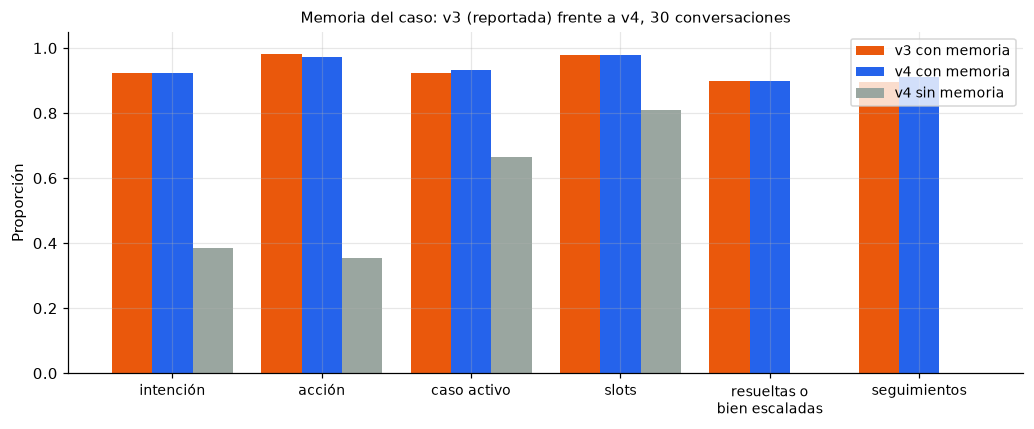

In [69]:
# ---------- Evaluación de la memoria (v4; la v3 queda reportada en resultados_soporte_v3.json) ----------
CONVERSACIONES = json.load(open("conversaciones_memoria.json", encoding="utf-8"))["conversaciones"]          # v3
_CONV_V4 = json.load(open("conversaciones_memoria_v4.json", encoding="utf-8"))
CONVERSACIONES_V4, CONVERSACIONES_TEMA = _CONV_V4["conversaciones"], _CONV_V4["cambio_de_tema"]
mensajes_conv = [t["usuario"] for c in CONVERSACIONES_V4 + CONVERSACIONES_TEMA for t in c["turnos"]]
sim_conv = util.cos_sim(embeber(mensajes_conv), embeber(train_df["texto"].tolist() + aumento_v1["texto"].astype(str).tolist())).max(dim=1).values.cpu().numpy()
print(f"Mensajes de las conversaciones v4 y de cambio de tema: {len(mensajes_conv)} | similitud MiniLM máxima con entrenamiento y "
      f"aumento: {sim_conv.max():.3f} | mensajes ≥ 0,90: {int((sim_conv >= SIM_FUGA_MAX).sum())} | expectativas cambiadas respecto "
      f"de la v3 (de forma mecánica, antes de ejecutar): {len(_CONV_V4['cambios_respecto_de_v3'])}")

def evaluar_conversaciones(memoria, conversaciones):
    """Métricas de la memoria del caso. «Soluciones repetidas»: una solución ofrecida de nuevo como intento en la misma
    conversación (no cuenta el recordatorio «Volvamos a …» al retomar un caso)."""
    filas, convs = [], []
    for conv in conversaciones:
        bot = SoporTIC(memoria=memoria)
        vistas, repetidas = Counter(), 0
        for k, esperado in enumerate(conv["turnos"], start=1):
            bot.responder(esperado["usuario"])
            turno = bot.historial[-1]
            ofrecidas = [tuple(x) for x in turno["pasos_turno"]]
            repetidas += sum(1 for x in ofrecidas if vistas[x] > 0)
            vistas.update(ofrecidas)
            caso = bot.caso_activo()
            slots_ok = {}
            for s_, v in esperado.get("slots", {}).items():
                obtenido = caso[s_] if caso else None
                slots_ok[s_] = (obtenido is not None and _sin_tildes(v) in _sin_tildes(obtenido)) if s_ == "error" else obtenido == v
            filas.append({"conversacion": conv["id"], "turno": k, "usuario": esperado["usuario"],
                          "intencion_esperada": esperado["intencion_turno"], "intencion_obtenida": turno["intencion_turno"],
                          "accion_esperada": esperado["accion"], "accion_obtenida": turno["accion"],
                          "activo_esperado": esperado["caso_activo"], "activo_obtenido": turno["caso_activo"],
                          "seguimiento": bool(esperado.get("seguimiento")), "cambio_de_tema": bool(esperado.get("cambio_de_tema")),
                          "slots_ok": slots_ok, "aviso_privacidad_esperado": bool(esperado.get("aviso_privacidad")),
                          "aviso_privacidad": turno["aviso_privacidad"], "soluciones_ofrecidas": len(ofrecidas)})
        finales = {c["intencion"]: c["estado"] for c in bot.casos}
        convs.append({"conversacion": conv["id"], "final_esperado": conv["final"], "final_obtenido": finales,
                      "final_ok": all(finales.get(i) == e for i, e in conv["final"].items()), "soluciones_repetidas": repetidas})
    t, c = pd.DataFrame(filas), pd.DataFrame(convs)
    t["intencion_ok"] = t["intencion_esperada"].fillna("—") == t["intencion_obtenida"].fillna("—")
    t["accion_ok"] = t["accion_esperada"] == t["accion_obtenida"]
    t["activo_ok"] = t["activo_esperado"].fillna("—") == t["activo_obtenido"].fillna("—")
    slots_total = sum(len(x) for x in t["slots_ok"]); slots_bien = sum(sum(x.values()) for x in t["slots_ok"])
    seg, tema = t[t["seguimiento"]], t[t["cambio_de_tema"]]
    priv = t[t["aviso_privacidad_esperado"]]
    resumen = {"turnos": len(t), "intencion_por_turno": float(t["intencion_ok"].mean()), "accion_por_turno": float(t["accion_ok"].mean()),
               "caso_activo": float(t["activo_ok"].mean()), "slots_correctos": slots_bien / slots_total if slots_total else None,
               "n_slots": slots_total, "conversaciones_resueltas_o_bien_escaladas": float(c["final_ok"].mean()),
               "n_conversaciones": len(c), "soluciones_repetidas": int(c["soluciones_repetidas"].sum()),
               "seguimientos_bien_resueltos": float((seg["accion_ok"] & seg["intencion_ok"] & seg["activo_ok"]).mean()) if len(seg) else None,
               "n_seguimientos": len(seg),
               "cambios_de_tema_bien_resueltos": float((tema["accion_ok"] & tema["intencion_ok"] & tema["activo_ok"]).mean()) if len(tema) else None,
               "n_cambios_de_tema": len(tema),
               "avisos_privacidad_correctos": float((priv["aviso_privacidad"]).mean()) if len(priv) else None}
    return t, c, resumen

t_mem0 = time.time()
turnos_mem, convs_mem, resumen_mem = evaluar_conversaciones(True, CONVERSACIONES_V4)
turnos_sin, convs_sin, resumen_sin = evaluar_conversaciones(False, CONVERSACIONES_V4)
turnos_tema, convs_tema, resumen_tema = evaluar_conversaciones(True, CONVERSACIONES_TEMA)
tiempo_eval_memoria = time.time() - t_mem0
_RUTA_V3 = os.path.join(BASE_DIR, "resultados_soporte_v3.json")
RESULTADOS_V3_REPORTADOS = (json.load(open(_RUTA_V3, encoding="utf-8"))["memoria"] if os.path.exists(_RUTA_V3)
                            else {"con_memoria": {m: None for m in ["intencion_por_turno", "accion_por_turno", "caso_activo", "slots_correctos",
                                                                    "conversaciones_resueltas_o_bien_escaladas", "seguimientos_bien_resueltos"]}})
METRICAS_MEMORIA = ["intencion_por_turno", "accion_por_turno", "caso_activo", "slots_correctos",
                    "conversaciones_resueltas_o_bien_escaladas", "seguimientos_bien_resueltos"]
tabla_memoria = pd.DataFrame({"v3 con memoria (reportada)": {m: RESULTADOS_V3_REPORTADOS["con_memoria"].get(m) for m in METRICAS_MEMORIA},
                              "v4 con memoria": {m: resumen_mem[m] for m in METRICAS_MEMORIA},
                              "v4 sin memoria": {m: resumen_sin[m] for m in METRICAS_MEMORIA},
                              "v4 cambio de tema (5 conv.)": {m: resumen_tema[m] for m in METRICAS_MEMORIA}})
for nombre, t_ in [("con_memoria", turnos_mem), ("sin_memoria", turnos_sin), ("cambio_de_tema", turnos_tema)]:
    t_.to_csv(os.path.join(DATA_DIR, f"memoria_v4_turnos_{nombre}.csv"), index=False)
pd.concat([convs_mem, convs_tema]).to_csv(os.path.join(DATA_DIR, "memoria_v4_conversaciones.csv"), index=False)
display(tabla_memoria)
print(f"Soluciones repetidas: {resumen_mem['soluciones_repetidas']} con memoria, {resumen_sin['soluciones_repetidas']} sin memoria | "
      f"cambios de tema bien resueltos: {resumen_tema['cambios_de_tema_bien_resueltos']} de {resumen_tema['n_cambios_de_tema']} | "
      f"tiempo: {tiempo_eval_memoria:.1f} s")
print("\nTurnos con error del bot con memoria (acción, intención o caso activo):")
_err = pd.concat([turnos_mem, turnos_tema])
display(_err[~(_err["accion_ok"] & _err["intencion_ok"] & _err["activo_ok"])][
    ["conversacion", "turno", "usuario", "accion_esperada", "accion_obtenida", "intencion_esperada", "intencion_obtenida",
     "activo_esperado", "activo_obtenido"]])

fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.arange(len(METRICAS_MEMORIA))
ax.bar(x - 0.27, [RESULTADOS_V3_REPORTADOS["con_memoria"][m] or 0 for m in METRICAS_MEMORIA], 0.27, label="v3 con memoria", color=COLOR_2)
ax.bar(x, [resumen_mem[m] for m in METRICAS_MEMORIA], 0.27, label="v4 con memoria", color=COLOR_1)
ax.bar(x + 0.27, [resumen_sin[m] for m in METRICAS_MEMORIA], 0.27, label="v4 sin memoria", color="#9aa6a0")
ax.set_xticks(x); ax.set_xticklabels(["intención", "acción", "caso activo", "slots", "resueltas o\nbien escaladas", "seguimientos"], fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel("Proporción"); ax.legend(fontsize=9)
ax.set_title("Memoria del caso: v3 (reportada) frente a v4, 30 conversaciones", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fig22_memoria_v4.png"), bbox_inches="tight"); plt.show()

In [70]:
# ---------- Resultados de la versión v4 (memoria por soluciones) ----------
RESULTADOS_V4 = {
    "version": "v4 — memoria por soluciones, diagnóstico y cambio de tema",
    "metodo_clasificacion": METODO_FINAL, "normalizacion_tildes_entrada": True,
    "conversaciones": {"archivo": "conversaciones_memoria_v4.json", "n": len(CONVERSACIONES_V4), "n_cambio_de_tema": len(CONVERSACIONES_TEMA),
                       "turnos": len(mensajes_conv), "expectativas_cambiadas_respecto_de_v3": len(_CONV_V4["cambios_respecto_de_v3"]),
                       "similitud_max_entrenamiento_aumento": round(float(sim_conv.max()), 4)},
    "memoria": {"con_memoria": resumen_mem, "sin_memoria": resumen_sin, "cambio_de_tema": resumen_tema},
    "memoria_v3_reportada": RESULTADOS_V3_REPORTADOS,
    "modo_ia": {"activo": bool(USAR_GPT), "modelo": MODELO_GPT_USADO},
    "tiempos_s": {"evaluacion_memoria": round(tiempo_eval_memoria, 1), "notebook_hasta_aqui": round(time.time() - T_INICIO_NOTEBOOK, 1)},
}
with open(os.path.join(BASE_DIR, "resultados_soporte_v4.json"), "w", encoding="utf-8") as f:
    json.dump(RESULTADOS_V4, f, ensure_ascii=False, indent=2, default=float)
print("Resultados guardados en", os.path.join(BASE_DIR, "resultados_soporte_v4.json"), "(resultados_soporte_v3.json no se modifica)")

Resultados guardados en soportic\resultados_soporte_v4.json (resultados_soporte_v3.json no se modifica)


### Interpretación de la memoria del caso v3 (reportada; cifras de `resultados_soporte_v3.json`)

- **Con memoria** (104 turnos, 30 conversaciones): intención por turno 0,9231, acción 0,9808, caso activo 0,9231, *slots* 0,9787 (46 de 47), conversaciones resueltas o bien escaladas 0,90 (27 de 30), seguimientos bien resueltos 0,8955 (60 de 67) y avisos de privacidad correctos 2 de 2.
- **Sin memoria** (el mismo bot, con el estado reiniciado en cada turno): intención por turno 0,3558, acción 0,3558, *slots* 0,7872, conversaciones resueltas o bien escaladas 0,0 y seguimientos bien resueltos 0,0: sin memoria, «no», «ya lo hice» o «y en el celular?» no tienen a qué referirse.
- **Pasos repetidos.** La métrica (pasos de una guía que aparecen dos veces en el texto mostrado) da 2 con memoria y 4 sin memoria. Los 2 casos con memoria (c01 y c17) no son pasos dados dos veces: el segundo aparecimiento es el resumen de escalamiento, que enumera a propósito los pasos intentados, y esos dos pasos son lo bastante cortos para caber completos en él. La métrica no se modificó después de ver el resultado (DECISIONES.md n.º 21). Desde el rediseño de la interfaz, el resumen muestra solo la primera cláusula de cada paso intentado (sin cortar palabras); con ese formato la métrica da 0 con memoria, y fuera del resumen ningún paso se repite ni antes ni después del cambio (comprobado en CPU sin reejecutar el notebook; DECISIONES.md n.º 26). Las salidas de esta sección corresponden a la ejecución anterior.
- **Errores restantes.** Los 3 errores de conversación vienen de la clasificación del primer mensaje: «outlook se queda cargando en el computador de la sala» se clasifica como `salas_computo`, el mensaje con contraseña oculta como `restablecer_contrasena` en lugar de `correo_institucional` y «no puedo entrar a la plataforma institucional» como `moodle_entregas`. La memoria sigue bien el caso abierto, pero sobre la intención equivocada.
- **Fuga.** 4 mensajes de las conversaciones tienen similitud MiniLM ≥ 0,90 con el entrenamiento (frases de control cortas como «ya pude entrar» y «como solicito un supletorio»); se reportan y no se cambiaron (DECISIONES.md n.º 15).

### Interpretación de la memoria del caso v4 (ejecución del 2026-11-15, RTX 5050; cifras de `resultados_soporte_v4.json`)

| Métrica (30 conversaciones, 104 turnos) | v3 con memoria | v4 con memoria | v4 sin memoria |
|---|---|---|---|
| Intención por turno | 0,9231 | 0,9231 | 0,3846 |
| Acción por turno | 0,9808 | 0,9712 | 0,3558 |
| Caso activo | 0,9231 | 0,9327 | 0,6635 |
| *Slots* correctos (47) | 0,9787 | 0,9787 | 0,8085 |
| Resueltas o bien escaladas | 0,90 | 0,90 | 0,0 |
| Seguimientos bien resueltos (67) | 0,8955 | 0,9104 | 0,0 |
| Pasos (v3) / soluciones (v4) repetidos | 2 | 0 | 0 |

- **v3 frente a v4.** Las cifras son comparables solo en parte: los mensajes son los mismos, pero 41 expectativas cambiaron de forma mecánica (por ejemplo, un primer mensaje sin subproblema ahora espera la pregunta de diagnóstico). Con esa salvedad, la v4 mantiene la intención, los *slots* y las conversaciones resueltas, sube en caso activo y seguimientos, y no repite ninguna solución.
- **Errores restantes (10 turnos).** Vienen de los mismos 3 primeros mensajes mal clasificados que en la v3 (c05: Outlook en la sala → `salas_computo`; c11: mensaje con contraseña → `restablecer_contrasena`; c23: «plataforma institucional» → `moodle_entregas`) y de un turno de las conversaciones de cambio de tema: en n04, el último «no, sigue igual» recibe una aclaración en lugar de la siguiente solución. Los errores de clasificación se reportan y no se corrigen.
- **Cambio de tema (5 conversaciones nuevas, 22 turnos).** Los 5 cambios de tema se resuelven bien (el caso activo queda pendiente y se retoma); acción por turno 0,9545 y 4 de 5 conversaciones terminan en el estado esperado (la que no, n04, por el turno anterior).

## 23. Interfaz con Gradio: «SoporTIC»
- **Identidad institucional, siempre en tema claro:** franja superior con el verde de la Universidad de Cundinamarca (`#00482b`), el logo sobre una placa blanca y una línea fina del amarillo del logo (`#fbe122`) como único detalle de ese color; fondo gris muy claro y paneles blancos con borde fino, sin sombras. La interfaz no sigue el modo oscuro del sistema ni del navegador: el tema define los mismos colores para los dos modos y un script quita la clase `dark` si Gradio la agrega. Una sola familia tipográfica local (Atkinson Hyperlegible Next; su variante monoespaciada solo en el resumen para copiar), con cinco tamaños (13, 14, 16, 18 y 26 px) y dos pesos.
- **Sin emojis:** los temas frecuentes, los avatares y el aviso de privacidad usan íconos de línea en SVG local, monocromáticos y del mismo tamaño. El avatar del estudiante lleva birrete y el del bot es un robot sencillo.
- **Mensajes (v4):** «**Solución n de m: título**» en su propia línea, los subpasos en lista numerada y «¿Se solucionó?»; debajo, los botones «Sí, se solucionó», «No, sigue igual» y «Ya lo había intentado» (al retomar un caso: «Ya no lo necesito»). La pregunta de diagnóstico y la aclaración entre dos intenciones técnicas también se responden con botones. La fuente se muestra al final, en letra pequeña, como enlace con el título de la referencia (nunca la URL completa). El contacto de «TICS a un CLIC» aparece al escalar, si el usuario lo pide, y una sola vez por conversación como nota de una línea cuando la guía omite pasos con datos de la sede que aún no están en la base. El resumen para copiar hace salto de línea y conserva el botón de copiar.
- **Estado del caso:** con la casilla de detalles activa, una tarjeta muestra el caso («Servicio · problema»), el avance por soluciones, los *slots*, los intentos fallidos y dónde quedó cada caso pendiente, resuelto, escalado o descartado.
- **Presentación y evaluación:** el formato visual se aplica en `formatear_mensaje` sobre el texto que devuelve el bot, de modo que la batería y la evaluación de la memoria siguen leyendo el mismo texto (pasos completos, fuente con URL).
- **Se conservan:** una conversación por pestaña (`session_hash`), tipo de respuesta fijo o IA (control segmentado), streaming con indicador «escribiendo», 👍/👎 (se guardan sin datos de la sesión), «Nueva conversación», funcionamiento sin internet y una sola columna en el celular. Accesibilidad: contraste AA, letra base de 16 px, controles de al menos 44 px de alto, foco visible y movimiento reducido respetado.

In [71]:
# @bot
# ---------- Presentación de los mensajes en la interfaz ----------
import html as _html
ICONOS_SVG = {   # íconos de línea (viewBox 24, trazo 1,75): temas frecuentes y avisos
    "moodle": '<path d="M2.5 5.8C5 4.8 8.3 4.9 12 6.8c3.7-1.9 7-2 9.5-1v12.9c-2.5-1-5.8-.9-9.5 1-3.7-1.9-7-2-9.5-1z"/><path d="M12 6.8v12.9"/>',
    "contrasena": '<circle cx="8" cy="15" r="4.2"/><path d="m11 12 9-9"/><path d="m17 6 2.5 2.5"/><path d="m14.6 8.4 2 2"/>',
    "correo": '<rect x="3" y="5" width="18" height="14" rx="2"/><path d="m3.6 6.6 8.4 6.4 8.4-6.4"/>',
    "wifi": '<path d="M2.5 9a14 14 0 0 1 19 0"/><path d="M5.6 12.4a9.5 9.5 0 0 1 12.8 0"/><path d="M8.7 15.8a5 5 0 0 1 6.6 0"/><path d="M12 19.3h.01"/>',
    "teams": '<rect x="2.5" y="6" width="13" height="12" rx="2"/><path d="m15.5 10.6 6-3.4v9.6l-6-3.4"/>',
    "office": '<path d="M6 2.8h8l4.5 4.5v13.9H6z"/><path d="M14 2.8v4.5h4.5"/><path d="M9 12.5h6M9 16h6"/>',
    "python": '<path d="m8 8-4.5 4 4.5 4"/><path d="m16 8 4.5 4-4.5 4"/><path d="m13.6 5-3.2 14"/>',
    "colab": '<path d="M7.2 18.5h10.3a4 4 0 0 0 .7-7.9A5.6 5.6 0 0 0 7.5 9.1a4.7 4.7 0 0 0-.3 9.4z"/>',
    "plataforma": '<path d="M3 9.5 12 4l9 5.5"/><path d="M4.5 20.5h15"/><path d="M6.5 11v7M10.2 11v7M13.8 11v7M17.5 11v7"/>',
    "salas": '<rect x="2.5" y="4" width="19" height="12.5" rx="1.5"/><path d="M9 20.5h6M12 16.5v4"/>',
    "candado": '<rect x="5" y="10.5" width="14" height="10" rx="2"/><path d="M8 10.5V7.5a4 4 0 0 1 8 0v3"/>',
}
def icono_svg(nombre, color="currentColor", clase="sop-ico"):
    return (f'<svg class="{clase}" viewBox="0 0 24 24" width="20" height="20" fill="none" stroke="{color}" stroke-width="1.75" '
            f'stroke-linecap="round" stroke-linejoin="round" aria-hidden="true" focusable="false">{ICONOS_SVG[nombre]}</svg>')

PATRON_PASO_MSG = re.compile(r"^Paso (\d+) de (\d+):\s*(.+)$")
PATRON_FUENTE_MSG = re.compile(r"^Fuente:\s*(.+?)\s*\((https?://[^\s)]+)\)\s*$")
PATRON_CORREO_MSG = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
PATRON_URL_MSG = re.compile(r"https?://[^\s<>«»\"]+[^\s<>«»\".,;:)]")
PATRON_EMOJI = re.compile("[\U0001F300-\U0001FAFF☀-➿️]")
PATRON_FENCE = re.compile(r"```[^\n]*\n.*?(?:```|$)", re.S)

def titulo_fuente(titulo):
    """«Título – Editor (nota)» → «Editor – Título (nota)»: la fuente se lee por quien la publica."""
    nota = ""
    if titulo.endswith(" (verificar vigencia)"):
        titulo, nota = titulo[:-len(" (verificar vigencia)")], " (verificar vigencia)"
    partes = titulo.rsplit(" – ", 1)
    return (f"{partes[1]} – {partes[0]}" if len(partes) == 2 else titulo) + nota

def _en_linea(texto):
    """Escapa el HTML y convierte **negrita**, correos (enlace mailto) y URL (enlace con texto corto)."""
    t = _html.escape(PATRON_EMOJI.sub("", texto).strip())
    t = re.sub(r"\*\*(.+?)\*\*", r"<strong>\1</strong>", t)
    t = re.sub(r"`([^`]+)`", r"<code>\1</code>", t)
    def _url(m):
        u = m.group(0)
        corto = re.sub(r"^https?://(www\.)?", "", u).rstrip("/")
        return f'<a href="{u}" target="_blank" rel="noopener">{corto}</a>'
    t = PATRON_URL_MSG.sub(_url, t)
    return PATRON_CORREO_MSG.sub(lambda m: f'<a href="mailto:{m.group(0)}">{m.group(0)}</a>', t)

def _bloque(linea):
    s = linea.strip()
    if s.startswith("🔒"):
        return f'<div class="sop-msg-priv">{icono_svg("candado")}<span>{_en_linea(s[1:])}</span></div>'
    m = re.fullmatch(r"\*\*(Solución \d+ de \d+: .+)\*\*", s)
    if m:
        return f'<p class="sop-msg-sol"><strong>{_html.escape(m.group(1))}</strong></p>'
    m = PATRON_PASO_MSG.match(s)
    if m:
        return (f'<div class="sop-msg-paso"><span class="sop-msg-n">Paso {m.group(1)} de {m.group(2)}</span> '
                f'<span class="sop-msg-t">{_en_linea(m.group(3))}</span></div>')
    if _sin_tildes(s) in ("¿se soluciono?", "¿funciono?"):
        return f'<p class="sop-msg-pregunta">{_html.escape(s)}</p>'
    if s.startswith("Opciones: "):
        return ""                                    # las opciones del diagnóstico se muestran como botones
    m = PATRON_FUENTE_MSG.match(s)
    if m:
        return (f'<p class="sop-msg-fuente">Fuente: <a href="{_html.escape(m.group(2))}" target="_blank" rel="noopener">'
                f'{_html.escape(titulo_fuente(m.group(1)))}</a></p>')
    if s.startswith("Algunos datos de la sede"):
        correo = PATRON_CORREO_MSG.search(s)
        enlace = f'<a href="mailto:{correo.group(0)}">TICS a un CLIC</a>' if correo else "TICS a un CLIC"
        return f'<p class="sop-msg-nota">Algunos datos de la sede no están disponibles; si lo necesitas, escribe a {enlace}.</p>'
    m = re.fullmatch(r"\*\*(.+)\*\*", s)
    if m:
        return f'<p class="sop-msg-guia">{_html.escape(m.group(1))}</p>'
    return f"<p>{_en_linea(s)}</p>"

PATRON_ITEM_LISTA = re.compile(r"^\s*(\d+)\.\s+(.+)$")

def texto_usuario_seguro(texto):
    """Mensaje del usuario para el chat: escapa el HTML y los corchetes, para que el markdown no forme enlaces
    (por ejemplo «[clic](javascript:…)»)."""
    return _html.escape(texto).replace("[", "&#91;").replace("]", "&#93;")

def formatear_mensaje(texto):
    """Texto del bot → HTML de la interfaz. Los subpasos numerados forman una lista ordenada; los bloques de código (resumen
    para copiar) quedan en Markdown para conservar el botón de copiar de Gradio. No cambia el texto que guarda el bot."""
    texto = str(texto or "")
    partes, pos = [], 0
    for m in PATRON_FENCE.finditer(texto):
        partes.append(("texto", texto[pos:m.start()])); partes.append(("codigo", m.group(0))); pos = m.end()
    partes.append(("texto", texto[pos:]))
    salida = []
    for tipo, contenido in partes:
        if tipo == "codigo":
            salida.append(contenido.rstrip() if contenido.rstrip().endswith("```") else contenido.rstrip() + "\n```")
            continue
        bloques, lista = [], []
        for l in contenido.split("\n"):
            m = PATRON_ITEM_LISTA.match(l)
            if m:
                lista.append(f"<li>{_en_linea(m.group(2))}</li>")
                continue
            if lista:
                bloques.append('<ol class="sop-msg-lista">' + "".join(lista) + "</ol>"); lista = []
            if l.strip():
                b = _bloque(l)
                if b:
                    bloques.append(b)
        if lista:
            bloques.append('<ol class="sop-msg-lista">' + "".join(lista) + "</ol>")
        if bloques:
            salida.append("\n".join(bloques))
    return "\n\n".join(salida)

def etiquetas_control(texto, bot):
    """Botones de control del último mensaje: los de «¿Se solucionó?» o, al retomar un caso, los de «¿pudiste probar…?»."""
    cuerpo = PATRON_FENCE.sub("", str(texto))
    c = bot.caso_activo() if bot is not None else None
    if c is None or c["esperando_diagnostico"]:
        return ()
    final = cuerpo.strip().split("\n")[-1]
    if PREGUNTA_RETOMAR in final:
        return RESPUESTAS_RETOMAR
    return RESPUESTAS_CONTROL if PREGUNTA_RESULTADO in cuerpo else ()

def pide_confirmacion(texto, bot):
    """Mostrar «Sí, se solucionó / No, sigue igual / Ya lo había intentado»: el mensaje pregunta «¿Se solucionó?» (fuera del
    resumen para copiar), hay un caso abierto y no está pendiente la pregunta de diagnóstico."""
    cuerpo = PATRON_FENCE.sub("", str(texto))          # sin el resumen para copiar (puede venir antes del caso retomado)
    c = bot.caso_activo() if bot is not None else None
    return bool(c is not None and not c["esperando_diagnostico"] and PREGUNTA_RESULTADO in cuerpo)

def opciones_diagnostico(bot):
    """Etiquetas de los botones de diagnóstico del caso activo (vacío si no hay pregunta pendiente)."""
    c = bot.caso_activo() if bot is not None else None
    if c is not None and c.get("confirmar"):                  # «¿Te refieres a … o es otro problema con …?» (n.º 61)
        return list(c["confirmar"]["opciones"])
    if c is not None and c["esperando_diagnostico"]:
        return etiquetas_diagnostico(c["intencion"])
    if bot is not None and bot.aclaracion:                     # aclaración entre dos intenciones técnicas (n.º 52)
        return [NOMBRE_CORTO.get(x, x) for x in bot.aclaracion]
    return []

In [72]:
# @bot
# ---------- Interfaz Gradio ----------
import base64
bots_por_sesion = {}
def bot_de_sesion(request=None):
    clave = getattr(request, "session_hash", None) or "local"
    if clave not in bots_por_sesion:
        bots_por_sesion[clave] = SoporTIC()
        bots_por_sesion[clave].meta_ui = {}
    return bots_por_sesion[clave]

NOMBRE_BOT = "SoporTIC"
MODO_FIJO_UI = "Pasos verificados"
MODO_IA_UI = "Redactadas por IA"
MODOS_UI = [MODO_FIJO_UI, MODO_IA_UI] if USAR_GPT else [MODO_FIJO_UI]
BIENVENIDA_UI = (f"Hola, soy {NOMBRE_BOT}, el asistente de soporte técnico para estudiantes de la UdeC Facatativá. "
                 "Cuéntame qué problema tienes y desde qué dispositivo (celular, portátil o PC de la sala), y te guío paso a "
                 "paso. **No escribas contraseñas ni datos personales aquí.**")
TEMAS_UI = [("moodle", "Moodle", "No puedo entrar a Moodle"), ("contrasena", "Contraseña", "Olvidé mi contraseña institucional"),
            ("correo", "Correo", "El correo institucional no me abre"), ("wifi", "Wi-Fi", "No me conecto al Wi-Fi de la sede"),
            ("teams", "Teams", "No puedo entrar a la clase de Teams"), ("office", "Office", "Office me dice que no tiene licencia"),
            ("python", "Python", "¿Cómo instalo Python en Windows?"), ("colab", "Colab", "Colab no me da GPU"),
            ("plataforma", "Plataforma", "La plataforma institucional no carga"), ("salas", "Salas", "El PC de la sala no me deja iniciar sesión")]
MAX_OPCIONES_UI = 4                                     # botones de diagnóstico (2 a 4 opciones)
COMO_FUNCIONA_UI = (
    "- **Comprensión:** un modelo BETO (BERT en español) multietiqueta identifica uno o varios problemas en tu mensaje.\n"
    "- **Memoria del caso:** recuerda cada problema abierto, tu dispositivo, el navegador, el error y los pasos que ya probaste; "
    "si dos pasos seguidos no funcionan, te da un resumen para la mesa de ayuda.\n"
    "- **Pasos verificados:** salen de guías basadas en documentación oficial, con su fuente.\n"
    "- **Redactadas por IA:** Qwen2.5 redacta los mismos pasos y un verificador descarta datos que no estén en la guía.\n"
    "- **Privacidad:** contraseñas, correos personales, documentos y teléfonos se ocultan antes de procesar el mensaje.")
AVISO_UI = (f"Proyecto académico de la Electiva Profesional II. No es un canal oficial de la universidad: para casos oficiales "
            f'escribe a <a href="mailto:{CORREO_MESA}">TICS a un CLIC</a>.')
RUTA_FEEDBACK = os.path.join(DATA_DIR, "feedback.csv")
RUTAS_PERMITIDAS_UI = [os.path.abspath(os.path.join(BASE_DIR, "ui"))]   # avatares e íconos

# ---------- Identidad visual ----------
CARPETA_UI = "ui"
def _logo_data_uri():
    """Logo de la UdeC desde ui/ (svg, png, jpg o webp), incrustado como data URI; None si no está."""
    for ext, mime in [("svg", "image/svg+xml"), ("png", "image/png"), ("jpg", "image/jpeg"), ("jpeg", "image/jpeg"), ("webp", "image/webp")]:
        ruta = os.path.join(CARPETA_UI, f"logo_udec.{ext}")
        if os.path.exists(ruta):
            return f"data:{mime};base64," + base64.b64encode(open(ruta, "rb").read()).decode()
    return None

def _svg_local(nombre, contenido):
    """Guarda un SVG en soportic/ui/ (carpeta permitida para Gradio) y devuelve su ruta."""
    ruta = os.path.join(BASE_DIR, "ui", f"{nombre}.svg")
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(contenido)
    return ruta

VERDE, VERDE_CLARO = "#00482b", "#e8f0eb"
# Avatares de línea: el estudiante con birrete (verde sobre verde claro) y el bot como un robot sencillo (blanco sobre verde)
AVATAR_USUARIO = _svg_local("avatar_estudiante_v3", (
    f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 40 40"><rect width="40" height="40" rx="10" fill="{VERDE_CLARO}"/>'
    f'<g fill="none" stroke="{VERDE}" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round">'
    '<circle cx="20" cy="21.5" r="5"/><path d="M10.5 34c1.5-4 5-6.3 9.5-6.3s8 2.3 9.5 6.3"/>'
    f'<path d="M7.5 13.2 20 7.8l12.5 5.4L20 18.6z" fill="{VERDE_CLARO}"/><path d="M32.5 13.2v6"/></g></svg>'))
AVATAR_BOT = _svg_local("avatar_bot_v3", (
    f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 40 40"><rect width="40" height="40" rx="10" fill="{VERDE}"/>'
    '<g fill="none" stroke="#ffffff" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round">'
    '<rect x="10.5" y="14" width="19" height="14.5" rx="4"/><path d="M20 14v-4"/><circle cx="20" cy="8.6" r="1.4"/>'
    '<path d="M8 19.5v3.5M32 19.5v3.5M16.5 24.5h7"/></g>'
    '<circle cx="15.8" cy="20.2" r="1.5" fill="#ffffff"/><circle cx="24.2" cy="20.2" r="1.5" fill="#ffffff"/></svg>'))
ICONOS_TEMAS = {clave: _svg_local(f"icono_{clave}", f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 24 24" fill="none" '
                                  f'stroke="{VERDE}" stroke-width="1.75" stroke-linecap="round" stroke-linejoin="round">'
                                  f'{ICONOS_SVG[clave]}</svg>') for clave, _, _ in TEMAS_UI}

# Paleta: blanco, gris de página, verde UdeC, verde claro de selección, tinta, gris de texto, borde y amarillo (solo la línea
# bajo la franja). Los valores «_dark» repiten los claros: la interfaz se ve igual con el sistema o el navegador en oscuro.
FUENTE_UI = ["Atkinson Hyperlegible Next", "system-ui", "Segoe UI", "Arial", "sans-serif"]
VERDE_UDEC = gr.themes.Color(name="verde_udec", c50="#e8f0eb", c100="#cfe2d6", c200="#a3cbb3", c300="#6fae89", c400="#3d8b62",
                             c500="#1a6a45", c600="#00552f", c700="#00482b", c800="#003a22", c900="#002e1b", c950="#001a0f")
TEMA_UI = gr.themes.Base(primary_hue=VERDE_UDEC, secondary_hue=VERDE_UDEC, neutral_hue="gray", radius_size="sm",
                         font=FUENTE_UI, font_mono=["Atkinson Hyperlegible Mono", "ui-monospace", "Consolas", "monospace"])
_TOKENS_UI = dict(body_background_fill="#f5f6f5", body_text_color="#1e2521", body_text_color_subdued="#5c6661",
                  background_fill_primary="#ffffff", background_fill_secondary="#ffffff",
                  block_background_fill="#ffffff", block_border_color="#d9dedb", block_border_width="1px", block_radius="8px",
                  block_shadow="none", block_label_text_size="14px", block_label_text_color="#5c6661", block_title_text_color="#1e2521",
                  border_color_primary="#d9dedb", border_color_accent="#00482b", border_color_accent_subdued="#a3cbb3",
                  color_accent="#00482b", color_accent_soft="#e8f0eb", link_text_color="#00482b", link_text_color_hover="#003a22",
                  link_text_color_visited="#00482b", link_text_color_active="#003a22",
                  button_primary_background_fill="#00482b", button_primary_background_fill_hover="#003a22",
                  button_primary_text_color="#ffffff", button_primary_border_color="#00482b",
                  button_secondary_background_fill="#ffffff", button_secondary_background_fill_hover="#f2f5f3",
                  button_secondary_border_color="#c9d1cc", button_secondary_text_color="#1e2521",
                  button_border_width="1px", button_primary_shadow="none", button_primary_shadow_hover="none",
                  button_primary_shadow_active="none", button_secondary_shadow="none", button_secondary_shadow_hover="none",
                  button_secondary_shadow_active="none",
                  input_background_fill="#ffffff", input_background_fill_focus="#ffffff", input_border_color="#c9d1cc",
                  input_border_color_focus="#00482b", input_shadow="none", input_shadow_focus="none",
                  checkbox_background_color="#ffffff", checkbox_background_color_selected="#00482b",
                  checkbox_border_color="#9aa6a0", checkbox_border_color_selected="#00482b", checkbox_label_background_fill="#ffffff",
                  checkbox_label_background_fill_selected="#ffffff", checkbox_label_text_color="#1e2521",
                  checkbox_label_text_color_selected="#1e2521", checkbox_label_border_color="#d9dedb",
                  chatbot_text_size="16px", button_large_text_size="16px", button_small_text_size="15px", input_text_size="16px")
import inspect as _inspect
_PARAMETROS_TEMA = _inspect.signature(TEMA_UI.set).parameters     # solo las variantes «_dark» que existen en esta versión
TEMA_UI.set(**_TOKENS_UI, **{f"{k}_dark": v for k, v in _TOKENS_UI.items() if f"{k}_dark" in _PARAMETROS_TEMA})

CSS_UI = """
:root { color-scheme: light; --sop-verde: #00482b; --sop-verde-osc: #003a22; --sop-verde-claro: #e8f0eb; --sop-tinta: #1e2521;
        --sop-gris: #5c6661; --sop-borde: #d9dedb; --sop-borde-2: #c9d1cc; --sop-pagina: #f5f6f5; --sop-amarillo: #fbe122; }
body, gradio-app, .gradio-container { background: var(--sop-pagina) !important; color: var(--sop-tinta); }
.gradio-container { max-width: 1120px !important; margin: 0 auto !important; font-size: 16px; padding-top: 0 !important;
        overflow: visible !important; }
.gradio-container .main { padding-top: 0 !important; }
.html-container:has(#sop-banda) { padding: 0 !important; }
.gradio-container :focus-visible { outline: 2px solid var(--sop-verde) !important; outline-offset: 2px; }
footer { display: none !important; }
html, body { overflow-x: hidden; }
/* Franja institucional: verde de lado a lado (sin desbordar la página) y una línea fina del amarillo del logo */
#sop-banda { position: relative; background: var(--sop-verde); box-shadow: 0 0 0 100vmax var(--sop-verde);
        clip-path: inset(0 -100vmax -3px); margin: 0 0 3px; }
#sop-banda::after { content: ""; position: absolute; left: -100vmax; right: -100vmax; bottom: -3px; height: 3px; background: var(--sop-amarillo); }
#sop-banda .sop-banda-in { display: flex; align-items: center; gap: 14px; min-height: 64px; }
#sop-banda .sop-inst, #sop-banda .sop-sede { color: #ffffff !important; }
#sop-banda .sop-placa { background: #ffffff; border-radius: 6px; padding: 3px 5px; display: grid; place-items: center; flex-shrink: 0; }
#sop-banda img { height: 46px; width: auto; display: block; }
#sop-banda .sop-inst { font-size: 16px; font-weight: 600; line-height: 1.2; }
#sop-banda .sop-sede { margin-left: auto; font-size: 14px; opacity: .9; }
/* Título contenido, subtítulo gris y nota académica pequeña */
#sop-titulo { padding: 18px 0 6px; }
#sop-titulo h1 { font-size: 26px; line-height: 1.15; font-weight: 700; margin: 0; color: var(--sop-tinta); letter-spacing: -0.01em; }
#sop-titulo .sop-sub { margin: 4px 0 0; font-size: 16px; color: var(--sop-gris); }
#sop-titulo .sop-nota-aca { margin: 10px 0 0; font-size: 13px; line-height: 1.45; color: var(--sop-gris); max-width: 78ch; }
#sop-titulo a, #sop-chat .message a { color: var(--sop-verde); text-decoration: underline; text-underline-offset: 2px;
        padding: 0 !important; margin: 0 !important; background: none !important; }
/* Chat */
#sop-chat { border: 1px solid var(--sop-borde) !important; border-radius: 8px !important; background: #ffffff !important; }
#sop-chat .message { line-height: 1.55; font-size: 16px; }
#sop-chat .avatar-container { width: 36px !important; height: 36px !important; border: none !important; border-radius: 10px !important; }
#sop-chat .avatar-container img { border-radius: 10px !important; padding: 0 !important; }
#sop-chat .message.bot { background: #ffffff !important; border: 1px solid var(--sop-borde) !important; }
#sop-chat .message.user { background: var(--sop-verde-claro) !important; border: 1px solid #d3e3d9 !important; }
#sop-chat .message .message { border: none !important; background: transparent !important; }
#sop-chat .message p { margin: 0 0 8px; }
#sop-chat .message p:last-child { margin-bottom: 0; }
#sop-chat .sop-msg-guia { font-weight: 600; font-size: 16px; margin-bottom: 10px !important; }
#sop-chat .sop-msg-paso { display: grid; gap: 2px; margin: 0 0 12px; }
#sop-chat .sop-msg-n { font-size: 14px; font-weight: 600; color: var(--sop-verde); }
#sop-chat .sop-msg-pregunta { font-weight: 600; margin-top: 4px !important; }
#sop-chat .sop-msg-sol { font-size: 16px; margin: 2px 0 8px !important; }
#sop-chat .sop-msg-sol strong { font-weight: 600; color: var(--sop-tinta); }
#sop-chat .sop-msg-lista { margin: 0 0 12px; padding-left: 1.4em; display: grid; gap: 8px; }
#sop-chat .sop-msg-lista li { padding-left: 2px; }
#sop-chat .sop-msg-lista li::marker { color: var(--sop-verde); font-weight: 600; }
#sop-chat .sop-msg-fuente, #sop-chat .sop-msg-nota { font-size: 13px; color: var(--sop-gris); line-height: 1.45; }
#sop-chat .sop-msg-fuente { margin-top: 12px !important; }
#sop-chat .sop-msg-fuente a, #sop-chat .sop-msg-nota a { color: var(--sop-gris); }
#sop-chat .sop-msg-priv { display: flex; gap: 8px; align-items: flex-start; font-size: 14px; color: var(--sop-tinta);
        border-left: 3px solid var(--sop-verde); padding: 2px 0 2px 10px; margin: 0 0 12px; }
#sop-chat .sop-msg-priv .sop-ico { flex-shrink: 0; margin-top: 1px; color: var(--sop-verde); }
#sop-chat sub { color: var(--sop-gris); font-size: 13px; }
/* Resumen del caso para copiar: salto de línea, sin desplazamiento horizontal, con el botón de copiar */
#sop-chat pre, #sop-chat code { font-family: 'Atkinson Hyperlegible Mono', ui-monospace, Consolas, monospace; font-size: 14px; }
#sop-chat .code_wrap { position: relative; max-width: 100%; min-width: 0; }
#sop-chat pre { background: var(--sop-pagina) !important; border: 1px solid var(--sop-borde); border-radius: 6px; }
#sop-chat pre, #sop-chat pre code { white-space: pre-wrap !important; overflow-wrap: anywhere !important; word-break: normal !important; }
#sop-chat pre { overflow-x: hidden !important; max-width: 100%; box-sizing: border-box; padding-right: 44px !important; }
#sop-chat, #sop-chat .bubble-wrap { overflow-x: hidden !important; }
#sop-chat .message-row, #sop-chat .message, #sop-chat .message-content, #sop-chat .bubble, #sop-chat .prose, #sop-chat .md {
        min-width: 0 !important; overflow-wrap: anywhere; }
.sop-escribiendo { color: var(--sop-gris); }
.sop-escribiendo::after { content: ' ●●●'; letter-spacing: 2px; animation: sop-pulso 1.2s infinite ease-in-out; color: var(--sop-verde); }
@keyframes sop-pulso { 0%, 100% { opacity: .25 } 50% { opacity: 1 } }
@media (prefers-reduced-motion: reduce) { .sop-escribiendo::after { animation: none; } }
/* Respuestas rápidas y caja de texto */
#sop-rapidas, #sop-diag { gap: 8px !important; justify-content: flex-start; flex-wrap: wrap !important; }
#sop-rapidas button, #sop-diag button { flex: 0 0 auto !important; width: auto !important; min-width: 0 !important; min-height: 40px; padding: 0 16px !important;
        font-weight: 500; font-size: 15px !important; }
#sop-diag button { border-color: var(--sop-verde) !important; color: var(--sop-verde) !important; }
#sop-fila-entrada { gap: 8px !important; align-items: stretch !important; }
#sop-entrada { min-width: 0 !important; }
#sop-entrada textarea { font-size: 16px !important; min-height: 44px !important; padding: 10px 12px !important; line-height: 1.4 !important; }
#sop-enviar { min-height: 44px !important; height: 44px !important; align-self: flex-start !important; font-size: 16px !important;
        padding-top: 0 !important; padding-bottom: 0 !important;
        font-weight: 600; border-radius: 6px !important; }
/* Temas frecuentes: chips iguales, borde fino, ícono de línea y texto */
.sop-etiqueta { font-size: 14px; color: var(--sop-gris); margin: 10px 0 0; }
#sop-temas { display: grid !important; grid-template-columns: repeat(auto-fill, minmax(132px, 1fr)); gap: 8px !important; }
#sop-temas button { width: 100% !important; min-width: 0 !important; min-height: 42px; justify-content: flex-start !important;
        gap: 8px !important; padding: 0 12px !important; border-radius: 6px !important; font-size: 15px !important; font-weight: 500;
        background: #ffffff !important; border: 1px solid var(--sop-borde-2) !important; color: var(--sop-tinta) !important; }
#sop-temas button:hover { border-color: var(--sop-verde) !important; background: #f7faf8 !important; }
#sop-temas button img { width: 20px !important; height: 20px !important; margin: 0 !important; flex-shrink: 0; }
/* Panel derecho: sin tarjetas; control segmentado, casilla y botón secundario */
#sop-lateral { gap: 14px !important; }
#sop-lateral > .block, #sop-lateral .form, #sop-lateral .block { background: transparent !important; border: none !important;
        box-shadow: none !important; padding: 0 !important; overflow: visible !important; }
#sop-modo .wrap { display: grid !important; grid-template-columns: repeat(auto-fit, minmax(0, 1fr)); gap: 0 !important;
        border: 1px solid var(--sop-borde-2); border-radius: 6px; overflow: hidden; background: #ffffff; }
#sop-modo label { margin: 0 !important; border: none !important; border-radius: 0 !important; justify-content: center !important;
        min-height: 42px; padding: 0 8px !important; background: #ffffff !important; box-shadow: none !important; font-size: 15px;
        text-align: center; cursor: pointer; }
#sop-modo label + label { border-left: 1px solid var(--sop-borde-2) !important; }
#sop-modo label input { position: absolute; opacity: 0; width: 1px; height: 1px; }
#sop-modo label.selected, #sop-modo label:has(input:checked) { background: var(--sop-verde) !important; color: #ffffff !important; }
#sop-modo label.selected span, #sop-modo label:has(input:checked) span { color: #ffffff !important; }
#sop-modo label:has(input:focus-visible) { outline: 2px solid var(--sop-verde); outline-offset: -4px; }
#sop-modo [data-testid="block-info"], #sop-modo .block-info, #sop-lateral .block-title { font-size: 14px !important; color: var(--sop-gris) !important; }
#sop-detalles label { font-size: 15px; background: transparent !important; border: none !important; padding: 0 !important; }
#sop-nueva { min-height: 44px; border: 1px solid var(--sop-verde) !important; color: var(--sop-verde) !important; background: #ffffff !important;
        font-weight: 600; border-radius: 6px !important; }
#sop-nueva:hover { background: var(--sop-verde-claro) !important; }
#sop-como { border-top: 1px solid var(--sop-borde) !important; padding-top: 6px !important; }
#sop-como button { font-size: 15px; color: var(--sop-tinta); }
/* Estado del caso: panel blanco con borde fino y filete verde superior */
#sop-caso { background: #ffffff; border: 1px solid var(--sop-borde); border-top: 3px solid var(--sop-verde); border-radius: 8px;
        color: var(--sop-tinta); }
#sop-caso .sop-cab { display: flex; justify-content: space-between; align-items: baseline; gap: 8px; padding: 12px 16px 0;
        font-size: 14px; color: var(--sop-gris); }
#sop-caso .sop-cuerpo { padding: 6px 16px 16px; }
#sop-caso .sop-tema { font-weight: 600; font-size: 18px; line-height: 1.3; margin-bottom: 12px; text-wrap: balance; }
#sop-caso .sop-pista { display: grid; gap: 3px; margin-bottom: 6px; }
#sop-caso .sop-pista span { height: 6px; border-radius: 3px; background: var(--sop-verde-claro); }
#sop-caso .sop-pista span.dado { background: var(--sop-verde); }
#sop-caso .sop-paso { font-size: 14px; color: var(--sop-gris); margin-bottom: 12px; }
#sop-caso dl { display: grid; grid-template-columns: auto 1fr; gap: 6px 14px; margin: 0; font-size: 15px; }
#sop-caso dt { color: var(--sop-gris); } #sop-caso dd { margin: 0; overflow-wrap: anywhere; }
#sop-caso .sop-otros { margin-top: 14px; padding-top: 12px; border-top: 1px solid var(--sop-borde); font-size: 14px; display: grid; gap: 6px; }
#sop-caso .sop-otros div { display: grid; gap: 1px; }
#sop-caso .sop-estado { color: var(--sop-gris); font-size: 13px; }
#sop-caso .sop-estado.pendiente { color: var(--sop-verde); font-weight: 600; }
#sop-caso .sop-vacio { padding: 6px 16px 16px; color: var(--sop-gris); font-size: 15px; line-height: 1.45; }
@media (max-width: 760px) {
  .gradio-container { padding-left: max(12px, env(safe-area-inset-left, 0px)) !important;
                      padding-right: max(12px, env(safe-area-inset-right, 0px)) !important; }
  .gradio-container .column, .gradio-container .row > * { min-width: 0 !important; }
  .gradio-container, .gradio-container .main, .gradio-container .wrap, .gradio-container .contain,
  .gradio-container .column, .gradio-container .row { max-width: 100% !important; box-sizing: border-box; }
  #sop-banda .sop-banda-in { min-height: 56px; gap: 10px; }
  #sop-banda img { height: 38px; }
  #sop-banda .sop-inst { font-size: 15px; }
  #sop-banda .sop-sede { display: none; }
  #sop-titulo h1 { font-size: 24px; }
  #sop-chat .bubble { margin-left: 2px !important; margin-right: 2px !important; }
  #sop-chat .message-row { max-width: 100% !important; }
  #sop-temas { grid-template-columns: repeat(2, minmax(0, 1fr)); }
}
"""
CARPETA_FUENTES = os.path.join(CARPETA_UI, "fuentes")
def css_fuentes_locales():
    """@font-face de ui/fuentes/fuentes.css con cada .woff2 incrustado como data URI (funciona sin internet, también con
    share=True en Colab). Si faltan los archivos, el CSS queda vacío y se usa la pila de respaldo del sistema."""
    ruta_css = os.path.join(CARPETA_FUENTES, "fuentes.css")
    if not os.path.exists(ruta_css):
        return ""
    css = open(ruta_css, encoding="utf-8").read()
    for archivo in sorted(set(re.findall(r"url\(([^)]+\.woff2)\)", css))):
        ruta = os.path.join(CARPETA_FUENTES, archivo)
        if os.path.exists(ruta):
            datos = base64.b64encode(open(ruta, "rb").read()).decode()
            css = css.replace(f"url({archivo})", f"url(data:font/woff2;base64,{datos})")
    return css

CSS_UI = css_fuentes_locales() + CSS_UI
# Siempre en tema claro: si Gradio agrega la clase «dark» (sistema o navegador en oscuro), se quita. Sin recursos externos.
HEAD_UI = ('<meta name="color-scheme" content="light"><script>(function(){function claro(){[document.documentElement, document.body]'
           '.forEach(function(e){if(e&&e.classList.contains("dark"))e.classList.remove("dark");});'
           'document.querySelectorAll("gradio-app .dark, .gradio-container.dark").forEach(function(e){e.classList.remove("dark");});}'
           'new MutationObserver(claro).observe(document.documentElement,{attributes:true,subtree:true,attributeFilter:["class"]});'
           'document.addEventListener("DOMContentLoaded",claro);claro();})();</script>'
           # El chat crece con el contenido hasta su altura máxima; desde ahí se desplaza solo hasta el último mensaje,
           # salvo que el usuario haya subido a leer (si vuelve al final, se reanuda)
           '<script>(function(){var pegado=true,caja=null,filas=0;'
           'function zona(){var r=document.querySelector("#sop-chat");if(!r)return null;var t=[r].concat([].slice.call(r.querySelectorAll("*")));'
           'for(var i=0;i<t.length;i++){var o=getComputedStyle(t[i]).overflowY;if((o==="auto"||o==="scroll")&&t[i].scrollHeight>t[i].clientHeight+2)return t[i];}'
           'return null;}'
           'function alFinal(c){return c.scrollHeight-c.scrollTop-c.clientHeight<80;}'
           'function bajar(){var c=zona();if(!c)return;if(c!==caja){caja=c;c.addEventListener("scroll",function(){pegado=alFinal(c);});}'
           'var n=c.querySelectorAll(".message-row").length;if(n>filas){pegado=true;filas=n;}if(pegado)c.scrollTop=c.scrollHeight;}'
           'var espera=null;new MutationObserver(function(){clearTimeout(espera);espera=setTimeout(bajar,40);})'
           '.observe(document.documentElement,{childList:true,subtree:true,characterData:true});'
           '})();</script>')

def html_encabezado():
    logo = _logo_data_uri()
    marca = (f'<span class="sop-placa"><img src="{logo}" alt="Logo de la Universidad de Cundinamarca"></span>' if logo else "")
    return (f'<header id="sop-banda"><div class="sop-banda-in">{marca}<span class="sop-inst">Universidad de Cundinamarca</span>'
            '<span class="sop-sede">Extensión Facatativá</span></div></header>'
            f'<div id="sop-titulo"><h1>{NOMBRE_BOT}</h1><p class="sop-sub">Asistente de soporte técnico para estudiantes</p>'
            f'<p class="sop-nota-aca" role="note">{AVISO_UI}</p></div>')

ESTADOS_CASO_UI = {"abierto": "Pendiente", "resuelto": "Resuelto", "escalado": "Escalado", "descartado": "Ya no lo necesitas"}
def _donde_quedo(x):
    """Dónde quedó un caso: «solución n de m», la pregunta de diagnóstico pendiente o «sin empezar»."""
    if x["esperando_diagnostico"]:
        return "falta elegir una opción"
    if x["rama"] is None or not x["soluciones_dadas"]:
        return "sin empezar"
    return f"solución {len(x['soluciones_dadas'])} de {len(soluciones_de(x['intencion'], x['rama']))}"

def _fila_otro_caso(x):
    """Fila de un caso que no es el activo: título y estado (los pendientes muestran dónde quedaron)."""
    estado = ESTADOS_CASO_UI.get(x["estado"], x["estado"])
    if x["estado"] == "abierto":
        estado += f" ({_donde_quedo(x)})"
    clase = "sop-estado pendiente" if x["estado"] == "abierto" else "sop-estado"
    return f'<div><span>{_html.escape(titulo_caso(x))}</span><span class="{clase}">{estado}</span></div>'

def html_estado_caso(bot):
    """Estado del caso activo (tema, opción elegida, avance por soluciones, slots, intentos) y de los demás casos."""
    c = bot.caso_activo() if bot else None
    casos = bot.casos if bot else []
    otros = [x for x in casos if x is not c]
    lista = f'<div class="sop-otros">{"".join(_fila_otro_caso(x) for x in otros)}</div>' if otros else ""
    if c is None:
        texto = ("Sin caso abierto. Cuando me cuentes un problema, aquí verás su avance." if not casos else "Sin caso abierto.")
        return f'<div id="sop-caso"><div class="sop-cab">Estado del caso</div><div class="sop-vacio">{texto}{lista}</div></div>'
    total = len(soluciones_de(c["intencion"], c["rama"])) if c["rama"] else 0
    dadas = len(c["soluciones_dadas"])
    opcion = opcion_de_rama(c["intencion"], c["rama"]) if c["rama"] else None
    pista = "".join(f'<span class="{"dado" if k < dadas else ""}"></span>' for k in range(total))
    avance = ("Falta elegir una opción" if c["esperando_diagnostico"] else
              f"Solución {dadas} de {total}" if total else "Sin soluciones")
    filas = ([("Problema", opcion["etiqueta"])] if opcion else []) + [
             ("Plataforma", c["plataforma"]), ("Dispositivo", c["dispositivo"]), ("Navegador", c["navegador"]), ("Error", c["error"]),
             ("Intentos fallidos", str(c["intentos_fallidos"]))]
    abiertos = len(bot.abiertos())
    return ('<div id="sop-caso"><div class="sop-cab"><span>Caso en curso</span>'
            f'<span>{abiertos} abierto{"s" if abiertos != 1 else ""}</span></div><div class="sop-cuerpo">'
            f'<div class="sop-tema">{_html.escape(titulo_caso(c))}</div>'
            + (f'<div class="sop-pista" style="grid-template-columns: repeat({total}, 1fr)" role="progressbar" '
               f'aria-valuemin="0" aria-valuemax="{total}" aria-valuenow="{dadas}" aria-label="Soluciones de la guía">{pista}</div>' if total else "")
            + f'<div class="sop-paso">{avance}</div>'
            '<dl>' + "".join(f"<dt>{k}</dt><dd>{_html.escape(str(v)) if v else '—'}</dd>" for k, v in filas) + '</dl>'
            f'{lista}</div></div>')

def detalles_turno(turno):
    if not turno:
        return ""
    conf = f", confianza {turno['confianza']:.2f}" if turno.get("confianza") else ""
    return (f"\n\n<sub>Intención: {turno.get('intencion_turno') or 'ninguna'}{conf}. Acción: {turno.get('accion')}. "
            f"Respuesta: {turno.get('fuente_texto', 'texto fijo')}.</sub>")

ESCRIBIENDO = '<span class="sop-escribiendo">escribiendo</span>'

def _botones(bot, texto=None, ocultar=False):
    """Actualizaciones de las dos filas de botones (control y diagnóstico) y de los botones de diagnóstico. Solo se envían
    cuando cambia el estado en la sesión: si se reenvía «ocultar» a una fila ya oculta y luego «mostrar», Gradio 6 la deja oculta."""
    control = tuple(() if ocultar else etiquetas_control(texto, bot))
    opciones = tuple([] if ocultar else opciones_diagnostico(bot))
    previo = getattr(bot, "estado_botones", ((), ()))
    bot.estado_botones = (control, opciones)
    def _actualizar(antes_lista, ahora_lista, n):
        r = []
        for k in range(n):
            antes = antes_lista[k] if k < len(antes_lista) else None
            ahora = ahora_lista[k] if k < len(ahora_lista) else None
            r.append(gr.skip() if antes == ahora else gr.update(value=ahora or "", visible=ahora is not None))
        return r
    fila_control = gr.skip() if bool(previo[0]) == bool(control) else gr.update(visible=bool(control))
    fila_diag = gr.skip() if bool(previo[1]) == bool(opciones) else gr.update(visible=bool(opciones))
    return [fila_control, fila_diag] + _actualizar(previo[0], control, 3) + _actualizar(previo[1], opciones, MAX_OPCIONES_UI)

def _sin_cambio_botones():
    return [gr.skip()] * (2 + 3 + MAX_OPCIONES_UI)

def responder_ui(mensaje, historial, modo, detalles, request: gr.Request = None):
    bot = bot_de_sesion(request)
    if not str(mensaje or "").strip():
        yield "", historial, html_estado_caso(bot), *_sin_cambio_botones()
        return
    historial = list(historial or [])
    if not any(m.get("role") == "user" for m in historial if isinstance(m, dict)):
        bot.reiniciar(); bot.meta_ui = {}
    historial += [{"role": "user", "content": texto_usuario_seguro(filtrar_datos_personales(mensaje)[0])},
                  {"role": "assistant", "content": ESCRIBIENDO}]
    yield "", historial, html_estado_caso(bot), *_botones(bot, ocultar=True)
    texto = ""
    for texto in responder_stream(bot, mensaje, "ia" if modo == MODO_IA_UI else "fijo"):
        historial[-1] = {"role": "assistant", "content": formatear_mensaje(texto) or ESCRIBIENDO}
        yield gr.skip(), historial, html_estado_caso(bot), *_sin_cambio_botones()   # ni la caja ni los botones cambian durante el streaming
    turno = bot.historial[-1]
    historial[-1] = {"role": "assistant", "content": formatear_mensaje(texto) + (detalles_turno(turno) if detalles else "")}
    bot.meta_ui[len(historial) - 1] = turno
    yield gr.skip(), historial, html_estado_caso(bot), *_botones(bot, texto)   # no borra lo que el usuario escribió mientras tanto

def nueva_conversacion(request: gr.Request = None):
    bot = bot_de_sesion(request)
    bot.reiniciar(); bot.meta_ui = {}
    return [{"role": "assistant", "content": formatear_mensaje(BIENVENIDA_UI)}], "", html_estado_caso(bot), *_botones(bot, ocultar=True)

def registrar_feedback(turno, voto, ruta=RUTA_FEEDBACK):
    """Guarda el voto sin datos personales (el mensaje ya pasó por el filtro; sin sesión, IP ni usuario)."""
    fila = pd.DataFrame([{"hora": time.strftime("%Y-%m-%d %H:%M:%S"), "mensaje": turno["usuario"], "respuesta": turno["bot"],
                          "intencion": turno.get("intencion_turno"), "accion": turno.get("accion"), "voto": voto}])
    fila.to_csv(ruta, mode="a", header=not os.path.exists(ruta), index=False)

def votar(datos: gr.LikeData, request: gr.Request = None):
    bot = bot_de_sesion(request)
    indice = datos.index if isinstance(datos.index, int) else datos.index[0]
    turno = bot.meta_ui.get(indice)
    if turno is not None:
        registrar_feedback(turno, "👍" if datos.liked is True else "👎" if datos.liked is False else str(datos.liked))

def _enviar_ejemplo(texto):
    def enviar(historial, modo, detalles, request: gr.Request = None):
        yield from responder_ui(texto, historial, modo, detalles, request)
    return enviar

def enviar_boton(etiqueta, historial, modo, detalles, request: gr.Request = None):
    """Botón de respuesta rápida o de diagnóstico: envía su etiqueta como mensaje."""
    yield from responder_ui(etiqueta, historial, modo, detalles, request)

def mostrar_caso(detalles):
    return gr.update(visible=bool(detalles))

def construir_interfaz(historial_inicial=None, detalles_inicial=False, caso_inicial=None):
    """Construye la interfaz. Los argumentos solo sirven para las capturas de pantalla con una conversación de ejemplo."""
    with gr.Blocks(title=f"{NOMBRE_BOT}: soporte técnico UdeC") as interfaz:
        gr.HTML(html_encabezado(), padding=False)
        with gr.Row(equal_height=False):
            with gr.Column(scale=7, min_width=260):
                chat = gr.Chatbot(value=historial_inicial or [{"role": "assistant", "content": formatear_mensaje(BIENVENIDA_UI)}],
                                  elem_id="sop-chat", height=None, min_height=200, max_height=640, show_label=False,
                                  avatar_images=(AVATAR_USUARIO, AVATAR_BOT), buttons=["copy"], sanitize_html=False)
                with gr.Row(visible=False, elem_id="sop-diag") as fila_diag:
                    botones_diag = [gr.Button("", variant="secondary", size="sm", visible=False) for _ in range(MAX_OPCIONES_UI)]
                with gr.Row(visible=False, elem_id="sop-rapidas") as rapidas:
                    botones_rapidos = [gr.Button(t, variant="secondary", size="sm") for t in RESPUESTAS_CONTROL]   # etiquetas dinámicas
                with gr.Row(equal_height=True, elem_id="sop-fila-entrada"):
                    entrada = gr.Textbox(placeholder="Describe tu problema…", show_label=False, scale=6, autofocus=True,
                                         elem_id="sop-entrada", lines=1, max_lines=6, container=False)
                    enviar = gr.Button("Enviar", variant="primary", scale=1, min_width=96, elem_id="sop-enviar")
                gr.HTML('<p class="sop-etiqueta">Temas frecuentes</p>', padding=False)
                with gr.Row(elem_id="sop-temas"):
                    botones = [gr.Button(nombre, icon=ICONOS_TEMAS[clave], size="sm", variant="secondary")
                               for clave, nombre, _ in TEMAS_UI]
            with gr.Column(scale=3, min_width=250, elem_id="sop-lateral"):
                modo = gr.Radio(MODOS_UI, value=MODOS_UI[0], label="Tipo de respuesta", elem_id="sop-modo",
                                info=("La redacción por IA es experimental y tarda unos segundos." if len(MODOS_UI) > 1 else None))
                detalles = gr.Checkbox(value=detalles_inicial, label="Mostrar detalles técnicos y estado del caso", elem_id="sop-detalles")
                nueva = gr.Button("Nueva conversación", variant="secondary", elem_id="sop-nueva")
                caso = gr.HTML(caso_inicial or html_estado_caso(None), visible=detalles_inicial, padding=False)
                with gr.Accordion(f"¿Cómo funciona {NOMBRE_BOT}?", open=False, elem_id="sop-como"):
                    gr.Markdown(COMO_FUNCIONA_UI)
        entradas = [entrada, chat, modo, detalles]
        salidas = [entrada, chat, caso, rapidas, fila_diag] + botones_rapidos + botones_diag
        # «always_last»: un mensaje enviado mientras el modo IA genera se procesa al terminar (con «once» se perdía)
        entrada.submit(responder_ui, entradas, salidas, api_name="responder", trigger_mode="always_last")
        enviar.click(responder_ui, entradas, salidas, api_name=False, trigger_mode="always_last")
        for boton in botones_rapidos + botones_diag:
            boton.click(enviar_boton, [boton, chat, modo, detalles], salidas, api_name=False)
        for boton, (_, _, texto_e) in zip(botones, TEMAS_UI):
            boton.click(_enviar_ejemplo(texto_e), [chat, modo, detalles], salidas, api_name=False)
        nueva.click(nueva_conversacion, None, [chat, entrada, caso, rapidas, fila_diag] + botones_rapidos + botones_diag, api_name="nueva_conversacion")
        detalles.change(mostrar_caso, detalles, caso, api_name=False)
        chat.like(votar, None, None)
    return interfaz

demo = construir_interfaz()
if os.environ.get("SOPORTIC_GRADIO", "1") == "1":
    demo.queue().launch(share=EN_COLAB, inbrowser=not EN_COLAB, css=CSS_UI, theme=TEMA_UI, head=HEAD_UI, footer_links=[],
                        allowed_paths=RUTAS_PERMITIDAS_UI)

# Fase 5 — Evaluación del sistema completo

## 24. Batería de soporte
La batería (`bateria_soporte.json`, generada por `herramientas/generar_bateria.py`) tiene 254 casos en 14 categorías: cada intención (5 frases por intención), ortografía y jerga, entrada inválida, multiintención, seguimientos y memoria, escalamiento, privacidad (contraseñas, cédula, correo, teléfono), inyección de instrucciones, otro idioma, fuera de dominio, trámites, `[COMPLETAR]` nunca mostrado, sesiones paralelas y modo IA con verificador. Se escribió y guardó **antes** de ejecutarla. Antes de la primera ejecución se comprobó (`herramientas/verificar_fuga_pruebas.py`) que ninguna frase tuviera similitud MiniLM ≥ 0,90 con el entrenamiento o el aumento; las 31 frases que la superaban se reescribieron antes de ejecutar nada.

Cada caso se ejecuta con un bot nuevo (dos en las sesiones paralelas). Estados:
- **pasa:** cumple lo esperado en el último turno (intención, intenciones abiertas, acción, caso activo, *slots*, textos que debe o no debe contener, aviso de privacidad).
- **aclara:** no cumple, pero el bot pidió aclaración en lugar de responder otra cosa.
- **falla:** no cumple. Se distingue el **fallo funcional** (excepción, respuesta vacía, `[COMPLETAR]` visible o eco de un dato personal) del **error de clasificación o de lógica**.

Política de correcciones: solo se corrigen fallos funcionales evidentes, y se reporta el antes y el después; los errores de clasificación no se corrigen, se reportan.

**v4.** Se ejecuta `bateria_soporte_v4.json`: los mismos 254 casos y mensajes, con los criterios que la estructura por subproblemas cambia actualizados de forma mecánica antes de ejecutar (8 criterios en 5 casos, listados en el archivo; DECISIONES.md n.º 45). Se compara caso por caso con los resultados de la v3 (`datos/bateria_resultados_v3.csv`).

In [73]:
# ---------- Ejecución de la batería ----------
BATERIA = json.load(open("bateria_soporte_v4.json", encoding="utf-8"))["casos"]

def _todas_respuestas(bot):
    return [t["bot"] for t in bot.historial]

def evaluar_caso(caso):
    esperado, modo = caso["esperado"], caso["modo"]
    if modo == "ia" and not USAR_GPT:
        return {"estado": "omitida", "tipo": "modo IA desactivado", "detalle": ""}
    t0 = time.time()
    try:
        if caso["categoria"] == "sesiones paralelas":
            bots = {"A": SoporTIC(), "B": SoporTIC()}
            for sesion, mensaje in caso["turnos"]:
                responder_modo(bots[sesion], mensaje, modo)
            respuestas = [r for b in bots.values() for r in _todas_respuestas(b)]
        else:
            bot = SoporTIC()
            for mensaje in caso["turnos"]:
                responder_modo(bot, mensaje, modo)
            respuestas = _todas_respuestas(bot)
    except Exception as error:
        return {"estado": "falla", "tipo": "funcional: excepción", "detalle": f"{type(error).__name__}: {str(error)[:150]}",
                "tiempo_s": time.time() - t0}
    duracion = time.time() - t0
    # Fallos funcionales
    if any(not str(r).strip() for r in respuestas):
        return {"estado": "falla", "tipo": "funcional: respuesta vacía", "detalle": "", "tiempo_s": duracion}
    if any(MARCADOR_COMPLETAR in r for r in respuestas):
        return {"estado": "falla", "tipo": "funcional: [COMPLETAR] visible", "detalle": "", "tiempo_s": duracion}
    secretos = [esperado.get("secreto")] + esperado.get("no_contiene", []) if esperado.get("secreto") else esperado.get("no_contiene", [])
    bots_caso = list(bots.values()) if caso["categoria"] == "sesiones paralelas" else [bot]
    usuarios = [t["usuario"] for b in bots_caso for t in b.historial]
    for s in [x for x in secretos if x]:
        if any(s in r for r in respuestas) or any(s in u for u in usuarios):
            return {"estado": "falla", "tipo": "funcional: eco de dato personal", "detalle": s, "tiempo_s": duracion}
    # Expectativas
    fallos = []
    if caso["categoria"] == "sesiones paralelas":
        for sesion, esp in esperado["sesiones"].items():
            b = bots[sesion]
            activo = b.caso_activo()
            if "caso_activo" in esp and (activo["intencion"] if activo else None) != esp["caso_activo"]:
                fallos.append(f"{sesion}: caso activo {activo['intencion'] if activo else None}")
            for k, v in esp.get("slots", {}).items():
                if (activo or {}).get(k) != v:
                    fallos.append(f"{sesion}: slot {k}={(activo or {}).get(k)}")
            for i, e in esp.get("final", {}).items():
                if {c["intencion"]: c["estado"] for c in b.casos}.get(i) != e:
                    fallos.append(f"{sesion}: estado final de {i}")
            if "no_contiene_historial" in esp and any(esp["no_contiene_historial"] in t["usuario"] + t["bot"] for t in b.historial):
                fallos.append(f"{sesion}: dato en el historial")
        ultimo = None
    else:
        ultimo = bot.historial[-1]
        accion_social = f"social:{ultimo['intencion_turno']}" if ultimo["accion"] == "social" else ultimo["accion"]
        if "intencion" in esperado and ultimo["intencion_turno"] != esperado["intencion"]:
            fallos.append(f"intención {ultimo['intencion_turno']}")
        if "intenciones" in esperado and sorted(c["intencion"] for c in bot.casos) != sorted(esperado["intenciones"]):
            fallos.append(f"casos {[c['intencion'] for c in bot.casos]}")
        if "acciones_validas" in esperado and accion_social not in esperado["acciones_validas"]:
            fallos.append(f"acción {accion_social}")
        if "accion" in esperado and ultimo["accion"] != esperado["accion"]:
            fallos.append(f"acción {ultimo['accion']}")
        if "caso_activo" in esperado and ultimo["caso_activo"] != esperado["caso_activo"]:
            fallos.append(f"caso activo {ultimo['caso_activo']}")
        for k, v in esperado.get("slots", {}).items():
            obtenido = (ultimo["slots"] or {}).get(k)
            ok = (obtenido is not None and _sin_tildes(v) in _sin_tildes(obtenido)) if k == "error" else obtenido == v
            if not ok:
                fallos.append(f"slot {k}={obtenido}")
        if "aviso_privacidad" in esperado and ultimo["aviso_privacidad"] != esperado["aviso_privacidad"]:
            fallos.append(f"aviso de privacidad {ultimo['aviso_privacidad']}")
        for s in esperado.get("contiene", []):
            if not any(s in r for r in respuestas):
                fallos.append(f"no contiene «{s}»")
    if not fallos:
        estado, tipo = "pasa", ""
    elif ultimo is not None and ultimo["accion"] == "aclarar":
        estado, tipo = "aclara", "aclaración"
    else:
        estado, tipo = "falla", "clasificación o lógica"
    extra = {}
    if ultimo is not None and modo == "ia":
        extra = {"fuente_texto": ultimo.get("fuente_texto"), "motivos_rechazo": "; ".join(ultimo.get("motivos_rechazo", []))}
    return {"estado": estado, "tipo": tipo, "detalle": "; ".join(fallos), "tiempo_s": duracion,
            "accion_final": ultimo["accion"] if ultimo else "", "intencion_final": ultimo["intencion_turno"] if ultimo else "", **extra}

t_bat0 = time.time()
resultados_bateria = pd.DataFrame([{"id": c["id"], "categoria": c["categoria"], "modo": c["modo"],
                                    "mensaje": str(c["turnos"][0] if c["categoria"] != "sesiones paralelas" else c["turnos"][0][1])[:80],
                                    **evaluar_caso(c)} for c in BATERIA])
tiempo_bateria = time.time() - t_bat0
RUTA_BATERIA = os.path.join(DATA_DIR, "bateria_resultados.csv")
RUTA_BATERIA_ANTES = os.path.join(DATA_DIR, "bateria_resultados_antes.csv")
resultados_bateria.to_csv(RUTA_BATERIA, index=False)
tabla_bateria = (resultados_bateria.pivot_table(index="categoria", columns="estado", values="id", aggfunc="count", fill_value=0)
                 .reindex(columns=["pasa", "aclara", "falla", "omitida"], fill_value=0))
tabla_bateria.loc["TOTAL"] = tabla_bateria.sum()
tabla_bateria["% pasa"] = (100 * tabla_bateria["pasa"] / tabla_bateria[["pasa", "aclara", "falla"]].sum(axis=1).replace(0, np.nan)).round(1)
print(f"Batería: {len(resultados_bateria)} casos en {tiempo_bateria:.0f} s")
display(tabla_bateria)
print("Fallos funcionales:", int(resultados_bateria["tipo"].str.startswith("funcional").sum()))
print("\nCasos que no pasan:")
display(resultados_bateria[resultados_bateria["estado"].isin(["falla", "aclara"])][["id", "categoria", "mensaje", "estado", "tipo", "detalle"]])
RUTA_BATERIA_V3 = os.path.join(DATA_DIR, "bateria_resultados_v3.csv")
if os.path.exists(RUTA_BATERIA_V3):           # v3 (reportada) frente a v4, caso por caso
    v3_bat = pd.read_csv(RUTA_BATERIA_V3)
    display(pd.DataFrame({"v3": v3_bat["estado"].value_counts(), "v4": resultados_bateria["estado"].value_counts()}).fillna(0).astype(int))
    cambios_bateria = v3_bat[["id", "categoria", "estado"]].merge(resultados_bateria[["id", "estado", "detalle", "accion_final"]], on="id",
                                                                   suffixes=("_v3", "_v4"))
    cambios_bateria = cambios_bateria[cambios_bateria["estado_v3"] != cambios_bateria["estado_v4"]]
    print(f"Casos que cambian de estado entre la v3 y la v4: {len(cambios_bateria)}")
    display(cambios_bateria)
if os.path.exists(RUTA_BATERIA_ANTES):        # resultados de la ejecución previa a las correcciones funcionales
    antes = pd.read_csv(RUTA_BATERIA_ANTES)
    comparacion_bateria = pd.DataFrame({"antes": antes["estado"].value_counts(), "después": resultados_bateria["estado"].value_counts()}).fillna(0).astype(int)
    print("Antes y después de las correcciones funcionales:")
    display(comparacion_bateria)

Batería: 254 casos en 27 s


estado,pasa,aclara,falla,omitida,% pasa
categoria,,,,,
[COMPLETAR] nunca mostrado,12,0,0,0,100.0
entrada inválida,12,0,3,0,80.0
escalamiento,6,1,3,0,60.0
fuera de dominio,9,1,0,0,90.0
intención,74,3,8,0,87.1
inyección de instrucciones,10,0,0,0,100.0
modo IA con verificador,10,0,0,0,100.0
multiintención,13,0,7,0,65.0
ortografía y jerga,21,3,1,0,84.0


Fallos funcionales: 0

Casos que no pasan:


,id,categoria,mensaje,estado,tipo,detalle
3,b004,intención,"q mas, bien o que",falla,clasificación o lógica,intención sobre_bot
8,b009,intención,"me despido, que estes bien",falla,clasificación o lógica,intención agradecimiento
16,b017,intención,hablo con alguien real o con una maquina?,falla,clasificación o lógica,intención hablar_con_soporte
19,b020,intención,tu puedes cambiarme la contraseña directamente?,falla,clasificación o lógica,intención restablecer_contrasena
24,b025,intención,en cuanto cerro la bolsa ayer,aclara,aclaración,intención None
26,b027,intención,moodle me devuelve al inicio cuando pongo la c...,falla,clasificación o lógica,intención restablecer_contrasena
33,b034,intención,se me paso la hora de entrega en moodle,falla,clasificación o lógica,intención moodle_acceso
34,b035,intención,el quiz de moodle se cerro antes de terminar,falla,clasificación o lógica,intención moodle_acceso
42,b043,intención,mi cuenta quedo bloqueada,aclara,aclaración,intención None
73,b074,intención,academusoft no me deja entrar,aclara,aclaración,intención None


,v3,v4
estado,,
pasa,213,213
falla,27,31
aclara,14,10


Casos que cambian de estado entre la v3 y la v4: 8


,id,categoria,estado_v3,estado_v4,detalle,accion_final
38,b039,intención,aclara,pasa,,guiar
40,b041,intención,aclara,pasa,,guiar
92,b093,ortografía y jerga,aclara,pasa,,guiar
146,b147,seguimientos y memoria,aclara,pasa,,cambio_slot
165,b166,escalamiento,pasa,falla,acción diagnostico; no contiene «ticsaunclic@u...,diagnostico
166,b167,escalamiento,pasa,falla,acción diagnostico; no contiene «ticsaunclic@u...,diagnostico
240,b241,sesiones paralelas,pasa,falla,A: caso activo wifi_sede; A: estado final de w...,
243,b244,sesiones paralelas,pasa,falla,A: caso activo None,


Antes y después de las correcciones funcionales:


,antes,después
estado,,
pasa,213,213
falla,27,31
aclara,14,10


## 25. Latencia y memoria de GPU
Se mide el tiempo de respuesta por turno (media y percentil 95) en cada modo con los 30 primeros mensajes técnicos de la batería (un bot nuevo por mensaje, después de un turno de calentamiento), y el pico de VRAM reservada por PyTorch durante esa medición y en todo el notebook.

In [74]:
# ---------- Latencia por modo y pico de VRAM ----------
mensajes_latencia = [c["turnos"][0] for c in BATERIA if c["categoria"] == "intención" and c["esperado"]["intencion"] in GUIAS][:30]
if DEVICE.type == "cuda":
    VRAM_PICO_NOTEBOOK_GB = round(torch.cuda.max_memory_allocated() / 1e9, 2)
    torch.cuda.reset_peak_memory_stats()
latencias = {}
for modo in (["fijo", "ia"] if USAR_GPT else ["fijo"]):
    responder_modo(SoporTIC(), "no puedo entrar a moodle", modo)          # calentamiento
    tiempos = []
    for m in mensajes_latencia:
        b = SoporTIC()
        t0 = time.time(); responder_modo(b, m, modo); tiempos.append(time.time() - t0)
    latencias[modo] = {"n": len(tiempos), "media_s": round(float(np.mean(tiempos)), 3),
                       "p95_s": round(float(np.percentile(tiempos, 95)), 3), "max_s": round(float(np.max(tiempos)), 3)}
VRAM_PICO_BOT_GB = round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE.type == "cuda" else None
display(pd.DataFrame(latencias).T)
print(f"Pico de VRAM durante la medición del bot: {VRAM_PICO_BOT_GB} GB | pico en el notebook antes de la medición: "
      f"{VRAM_PICO_NOTEBOOK_GB if DEVICE.type == 'cuda' else None} GB | GPU: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}"
      f" | generador: {MODELO_GPT_USADO}")

,n,media_s,p95_s,max_s
fijo,30.0,0.039,0.050,0.067
ia,30.0,1.381,4.785,5.417


Pico de VRAM durante la medición del bot: 6.98 GB | pico en el notebook antes de la medición: 6.98 GB | GPU: NVIDIA GeForce RTX 5050 Laptop GPU | generador: Qwen/Qwen2.5-3B-Instruct


## 26. Evaluación humana (la hacen los autores)
`tareas_evaluacion.csv` tiene 10 tareas guiadas con columnas vacías para dos evaluadores: resuelta (sí/no) y calificación de 1 a 5. Cada autor hace las tareas por separado en la interfaz (`iniciar_soportic.bat`) y llena solo sus columnas. `herramientas/analizar_evaluacion_humana.py` calcula los promedios, el porcentaje de tareas resueltas por evaluador y el acuerdo entre evaluadores (acuerdo observado y kappa de Cohen en «resuelta»; diferencia media y kappa ponderada cuadrática en la calificación). Este notebook no la llena.

In [75]:
# ---------- Resumen de la evaluación humana (si los autores ya la llenaron) ----------
if os.path.exists("tareas_evaluacion.csv") and os.path.exists(os.path.join("herramientas", "analizar_evaluacion_humana.py")):
    import runpy
    runpy.run_path(os.path.join("herramientas", "analizar_evaluacion_humana.py"), run_name="__main__")

Evaluación humana: tareas_evaluacion.csv aún no tiene calificaciones (la llenan los autores).


In [76]:
# ---------- Resultados de la Fase 5 ----------
RESULTADOS_FINAL = {
    "version": "Fase 5 — evaluación del sistema completo",
    "bateria": {"n": len(resultados_bateria), "por_categoria": json.loads(tabla_bateria.to_json(orient="index")),
                "fallos_funcionales": int(resultados_bateria["tipo"].str.startswith("funcional").sum()),
                "tiempo_s": round(tiempo_bateria, 1)},
    "latencia": latencias,
    "vram_gb": {"pico_notebook_antes_de_la_latencia": VRAM_PICO_NOTEBOOK_GB if DEVICE.type == "cuda" else None,
                "pico_bot": VRAM_PICO_BOT_GB, "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"},
    "generador": MODELO_GPT_USADO, "eventos_gpu": EVENTOS_GPU,
    "tiempo_total_notebook_s": round(time.time() - T_INICIO_NOTEBOOK, 1),
}
with open(os.path.join(BASE_DIR, "resultados_soporte_final.json"), "w", encoding="utf-8") as f:
    json.dump(RESULTADOS_FINAL, f, ensure_ascii=False, indent=2, default=float)
print("Resultados guardados en", os.path.join(BASE_DIR, "resultados_soporte_final.json"))
print(f"Tiempo total del notebook: {RESULTADOS_FINAL['tiempo_total_notebook_s'] / 60:.1f} min")

Resultados guardados en soportic\resultados_soporte_final.json
Tiempo total del notebook: 64.1 min


### Interpretación de la Fase 5 (ejecución del 2026-11-15, RTX 5050; cifras de `resultados_soporte_final.json` y `datos/bateria_resultados.csv`)

- **Batería v4 (254 casos).** Pasan 213 (83,9 %), piden aclaración 10 y fallan 31; **0 fallos funcionales** (ninguna excepción, respuesta vacía, `[COMPLETAR]` visible ni eco de datos personales). En la v3: 213 / 14 / 27. Por categoría (pasa / aclara / falla): intención 74/3/8; ortografía y jerga 21/3/1; entrada inválida 12/0/3; multiintención 13/0/7; seguimientos y memoria 19/0/1; escalamiento 6/1/3; privacidad 15/0/0; inyección de instrucciones 10/0/0; otro idioma 7/0/1; fuera de dominio 9/1/0; trámites 2/2/4; `[COMPLETAR]` nunca mostrado 12/0/0; sesiones paralelas 3/0/3; modo IA con verificador 10/0/0.
- **Casos que cambian entre la v3 y la v4 (8).** Pasan de «aclara» a «pasa» 4 casos por las reglas de aclaración (DECISIONES.md n.º 50 a 52): «no recibo correos en outlook», «olvide mi clave», «como instalo paiton» y «el correo no abre en el portatil» → «y en el celular tampoco?». Pasan de «pasa» a «falla» 4 casos por el diseño v4, no por fallos funcionales: en b166 («moodle no abre», «no», «no») y b167 («la red de la u no me deja navegar», «sigue igual», «tampoco») el primer mensaje no indica el subproblema, el bot pregunta el diagnóstico y «no» no es una respuesta a esa pregunta, de modo que no escala como esperaba la v3; en b241 (sesiones paralelas) la v3 escalaba tras dos fallos y en la v4 dos «no» no agotan las soluciones de la rama, de modo que el caso sigue activo; en b244 la rama de Python tiene una sola solución y «tampoco» la agota y escala, mientras la v3 esperaba el caso aún activo. Los criterios de la batería solo se actualizaron de forma mecánica antes de ejecutar; estos 4 casos se reportan como fallos.
- **Fallos de clasificación (reportados, no corregidos).** Igual que en la v3: los trámites se confunden con intenciones técnicas, 7 de 20 mensajes de multiintención reciben una sola intención, entradas como «a» o «lorem ipsum dolor sit amet» se clasifican como despedida y el filtro de idioma solo reconoce inglés.
- **Latencia (30 mensajes, un bot nuevo por mensaje).** Modo fijo: media 0,039 s, p95 0,050 s. Modo IA (Qwen2.5-3B en bf16): media 1,381 s, p95 4,785 s, máximo 5,417 s. **Esta media no es comparable con la de la v3 (4,4 s):** en la v4, 19 de los 30 mensajes reciben una pregunta de diagnóstico, una aclaración o un escalamiento, que se muestran con el texto fijo sin llamar a Qwen; solo 11 pasan por Qwen (conteo con el mismo bot en CPU). El tiempo de una respuesta redactada por Qwen se mide mejor con el p95 y el máximo (≈ 5 s); el streaming muestra el texto mientras se genera.
- **VRAM.** Pico de 6,98 GB en la RTX 5050 Laptop (8 GB), con Qwen 3B cargado. El margen es pequeño: si otro programa usa la GPU, el modo IA se vuelve lento; el respaldo es Qwen2.5-1.5B (`SOPORTIC_GENERADOR=1.5B`), que también se usa si el 3B no cabe. En la T4 de Colab (15 GB), Qwen va en fp32. Tiempo total del notebook: 64,1 min.
- **Evaluación humana.** `tareas_evaluacion.csv` queda sin calificar; la hacen los autores.

## Conclusión del notebook

El sistema reconoce la intención de mensajes de soporte en español con BETO ajustado sobre un dataset propio de 17 intenciones (v1: accuracy 0,7612 en prueba, 0,8824 en generalización y 0,8111 en la prueba externa de una intención), reconoce varias intenciones en un mismo mensaje con un ensamble de BETO multietiqueta sobre el mensaje completo y sus segmentos (validación cruzada: exact match 0,6496 ± 0,0463; prueba externa: 0,8000 en las 120 líneas y 20 de 30 mensajes naturales de varias intenciones), y guía al estudiante con memoria del caso: en la v4, cada problema se divide en subproblemas, el bot pregunta el diagnóstico si hace falta y da una solución por turno (27 de 30 conversaciones resueltas o bien escaladas, frente a 0 sin memoria; ninguna solución repetida; los 5 cambios de tema bien resueltos). La batería del sistema completo pasa en el 83,9 % de los casos sin fallos funcionales. Las principales limitaciones son el tamaño del dataset (26 frases por intención), la confusión de los trámites de reglamento con intenciones técnicas, la exactitud en mensajes de dos intenciones (0,54 en validación cruzada), el margen de VRAM del modo IA (pico de 6,98 GB con Qwen 3B en 8 GB) y los datos institucionales que aún faltan en la base de conocimiento (marcadores `[COMPLETAR]`: el bot omite esos subpasos y, si una rama no tiene pasos verificados, remite a la mesa de ayuda).

## Índice de figuras
Todas las figuras se guardan en `soportic/figuras/`.

| Archivo | Título | Sección |
|---|---|---|
| `fig1_distribucion_clases.png` | Distribución de ejemplos por intención | 3. EDA |
| `fig2_longitud_textos.png` | Longitud de los mensajes en palabras y caracteres | 3. EDA |
| `fig3_palabras_frecuentes.png` | 20 palabras más frecuentes (sin stopwords) | 3. EDA |
| `fig4a_curvas_bilstm.png` | BiLSTM: pérdida y métricas de validación por época | 5.2 |
| `fig11_ablacion_aumento.png` | Ablación del aumento de datos (etapa 1 de la búsqueda) | 5.3 |
| `fig4b_busqueda_beto.png` | Etapa 2 de la búsqueda: learning rate | 5.3 |
| `fig12_composicion_train.png` | Composición del entrenamiento final por intención y origen | 5.3 |
| `fig4_curvas_entrenamiento.png` | BETO final: pérdida, accuracy y F1 macro por época | 5.3 |
| `fig5_matriz_confusion.png` | Matriz de confusión en el conjunto de prueba | 6 |
| `fig13_matriz_confusion_externa.png` | Matriz de confusión normalizada en la prueba externa (solo si no hay fuga) | 6 |
| `fig6_umbral_confianza.png` | Cobertura y accuracy según el umbral de confianza (validación) | 6 |
| `fig7_comparacion_modelos.png` | Accuracy por modelo: prueba vs. generalización | 6 |
| `fig8_mapa_atencion.png` | Mapa de autoatención de la última capa | 6.1 |
| `fig14_tsne_cls.png` | t-SNE de los embeddings [CLS]: BETO preentrenado vs. ajustado | 6.1 |
| `fig9_validacion_cruzada.png` | Validación cruzada estratificada de 5 particiones | 6.2 |
| `fig10_aclaracion.png` | Aclaración ante la duda: compromiso en validación | 6.3 |
| `fig15_confianza_validacion.png` | Confianza de BETO en validación: aciertos vs. errores | 6.3 |
| `fig16_calibracion_validacion.png` | Diagrama de fiabilidad y ECE de BETO en validación | 6.4 |
| `fig17_calibracion_temperatura.png` | Fiabilidad de la v1 antes y después del *temperature scaling* | 13 |
| `fig18_coocurrencia_errores.png` | Co-ocurrencia de errores del BETO multietiqueta (prueba) | 12 |
| `fig19_f1_clase_v1_vs_multietiqueta.png` | F1 por intención: v1 top-1 frente a multietiqueta | 12 |
| `fig20_matriz_externa_v2b.png` | Prueba externa con el método final de la v2b (matriz multietiqueta) | 19 |
| `fig21_memoria_caso.png` | Memoria del caso: bot con memoria frente a sin memoria (30 conversaciones; v3) | 22 |
| `fig22_memoria_v4.png` | Memoria del caso: v3 (reportada) frente a v4 con y sin memoria | 22 |